# QBUS6810 Group Assignment: Cook County Sale-Price Model

This notebook runs the original main analysis, M3 decision tree and random forest models, M4 boosting models, final cross-family selection, and the 2025 test in that order.

**How to run.** Keep `QBUS6810_assignment_merged_revised.ipynb` in the project folder next to `data/`. Required project inputs include `data/sales.csv`, `data/properties_2022.csv`, `data/variable_dictionary.csv`, and `data/featureengineer.csv`. From the project folder, use Restart & Run All once. The main analysis writes the split CSVs and linear winner before the M3/M4 section reads them. Keep the merged filename unchanged so the export manifest can identify it. All paths are relative. The main analysis uses `random_state=42`; boosting uses `seed=6810`.

**Required Python packages.** numpy, pandas, scipy, scikit-learn, matplotlib, seaborn, statsmodels, lightgbm, xgboost, catboost and optuna. The saved runs used Python 3.13.2 and scikit-learn 1.8.0; the M3/M4 settings cell prints package versions. Include the project-supplied CSV files and the custom `data/featureengineer.csv` configuration in the submission bundle.

**Run time.** The main analysis previously took about 1.5–3 hours on a 12-thread Windows laptop and needed about 4.5 GB of free memory. M3/M4 and the final test took roughly another 30–45 minutes. The refined Lasso grid in the main analysis is the slowest step.

**Revision status.** This combined notebook has not been run end to end. Saved outputs in unchanged cells are carried over from the two earlier notebook runs; revised code cells have no output. Use Restart & Run All to regenerate results from this single file. The 2025 test data are read only after the final model is frozen.

**Outputs.** Split membership and feature snapshots are written to `data/split/`; model results and figures are written under `data/result/`.


In [1]:
import numpy as np
import scipy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
import math
import scipy.stats as stats
import matplotlib.ticker as mtick
from pathlib import Path

# Every figure shown below is also saved as a PNG in data/result/figures.
figure_dir = Path("data") / "result" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

def save_figure(name):
    plt.gcf().savefig(figure_dir / f"{name}.png", dpi=150, bbox_inches="tight")

Read 3 csv from documents

In [2]:
property = pd.read_csv(
    "data/properties_2022.csv",
    dtype={"property_id": "string"},
    low_memory=False,
)
sales = pd.read_csv(
    "data/sales.csv",
    dtype={"property_id": "string", "transaction_id": "string"},
    low_memory=False,
)
var_dict = pd.read_csv("data/variable_dictionary.csv")

property["property_id"] = property["property_id"].str.strip()
sales["property_id"] = sales["property_id"].str.strip()
sales["transaction_id"] = sales["transaction_id"].str.strip()


## Missing Value Validation Against Data Dictionary

This cell validates the `property` dataset's missing values against the data dictionary (`var_dict`). It compares the actual missing fraction of each column with the recorded `missing_fraction`, flags any discrepancies or features not covered by the dictionary, and summarizes the overall missing value counts.

**Purpose:** Ensure data quality by confirming that the observed missingness matches the documented dictionary and that all features are accounted for.

In [3]:
print (property.info())
print ("\nThe shape of property dataset is: {}\n".format(property.shape))

act_missing = property.drop(columns='property_id').isnull().mean()

var_dict["actual_missing_fraction"] = var_dict["variable"].map(act_missing)
difference = (var_dict["actual_missing_fraction"] - var_dict["missing_fraction"])
great_diff = difference[difference>1e-6]

unmatched = act_missing.index[~act_missing.index.isin(var_dict["variable"])]

if great_diff.empty and unmatched.empty:
  print ("All null fraction in property csv can match with that in dictionary\n and features are all included in dictionary")
else:
  print (great_diff)
  print (unmatched)

value_null = property.isnull().sum().sort_values(ascending=False)
cols_with_missing = property.isnull().any(axis=0).sum()
print ("\nNumber of columns with missing values in property csv: ",cols_with_missing)
print ("\nSum of missing value:\n", value_null[value_null!=0])


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98899 entries, 0 to 98898
Data columns (total 98 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   property_id                                            98899 non-null  string 
 1   loc_property_city                                      98897 non-null  object 
 2   loc_property_zip                                       98517 non-null  float64
 3   loc_longitude                                          98899 non-null  float64
 4   loc_latitude                                           98899 non-null  float64
 5   char_yrblt                                             98898 non-null  float64
 6   char_bldg_sf                                           98899 non-null  float64
 7   char_land_sf                                           98899 non-null  float64
 8   char_beds                                     

In the aforementioned `property.csv` file, all features are accounted for in the dictionary, and their respective missing value fractions are largely consistent with those in the dictionary. There are 98,899 samples in total, with 98 features (97 features plus `property_id`), 39 of which contain missing values.

In [4]:
print (sales.info())
print ("\nThe shape of property dataset is: {}\n".format(sales.shape))
value_null2 = sales.isnull().sum().sort_values(ascending=False)

if value_null2.empty:
  print ("No missing value in sales csv")
else:
  print (value_null2[value_null2!=0])


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109307 entries, 0 to 109306
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   property_id     109307 non-null  string 
 1   transaction_id  109307 non-null  string 
 2   sale_date       109307 non-null  object 
 3   sale_price      109307 non-null  float64
dtypes: float64(1), object(1), string(2)
memory usage: 3.3+ MB
None

The shape of property dataset is: (109307, 4)

Series([], dtype: int64)


The aforementioned Sales CSV file contains a total of 109,307 samples, with 3+1 features (including one `property_id`). There are no missing values.

According to the above, there are a large amount of missing
value in property csv, and their fraction can match to
that in dictionary. No missing value exist in sales csv.


---


Confirm whether there are records out of required time

In [5]:
sales['sale_date'] = pd.to_datetime(sales['sale_date'])

# Confirm whether there are records out of required time
outoftime = sales[(sales['sale_date'] >= '2026-01-01')|(sales['sale_date'] <= '2022-12-31')]

if outoftime.empty:
  print ('All records in sale csv fall within 2023 and 2025\n')
else:
  print ('There are sale records out of specified time:\n{}'.format(outoftime))

print("char_yrblt range:", property["char_yrblt"].min(),property["char_yrblt"].max())
print("Later than 2022 char_built:",(property["char_yrblt"]>2022).sum())
print("Null or negative record:",(property["char_yrblt"] <= 0).sum())
print("Too early (<1800) :", (property["char_yrblt"]< 1800).sum())

print("\nRange of year Median Occupied Household:",property["acs5_median_household_total_occupied_year_built"].min(),
      property["acs5_median_household_total_occupied_year_built"].max())
print("Later than 2022 Median Occupied Household:",
 (property["acs5_median_household_total_occupied_year_built"] > 2022).sum())

illegal_price = sales[sales['sale_price']<=0]

if illegal_price.empty:
  print ('\nAll records in sale csv have proper price\n')
else:
  print ('There are sale records within illegal price:\n{}'.format(illegal_price))


All records in sale csv fall within 2023 and 2025

char_yrblt range: 1847.0 2021.0
Later than 2022 char_built: 0
Null or negative record: 0
Too early (<1800) : 0

Range of year Median Occupied Household: 1940.0 2007.0
Later than 2022 Median Occupied Household: 0

All records in sale csv have proper price



All records in sales csv and property csv are correctly
recorded.

In the aforementioned temporal checks, the timestamps for records in both the 'sales' and 'property' datasets were found to fall within the correct ranges.
Regarding the price data in the 'sales' CSV file, all values ​​are above zero, with no invalid data entries present.

---


We then test whether duplicate records and repeated
sales of the same property exist or not.

:

In [6]:
duplicate_trans_id = sales['transaction_id'].value_counts()
duplicate_list = duplicate_trans_id[duplicate_trans_id>1]
if duplicate_list.empty:
  print ('No duplicated transaction id exist.')
else:
  print ('There are duplicated transaction id existing:\n{}'.format(duplicate_list))

print ("Number of unique transaction id in sales csv: ",sales['transaction_id'].nunique())
print ("Number of unique property id in sales csv: ",sales['property_id'].nunique())
print ("Number of unique property id in property csv: ",property['property_id'].nunique())

print ("Sales shape: ",sales.shape)
print ("Property shape: ",property.shape)


No duplicated transaction id exist.
Number of unique transaction id in sales csv:  109307
Number of unique property id in sales csv:  98899
Number of unique property id in property csv:  98899
Sales shape:  (109307, 4)
Property shape:  (98899, 98)


Based on the checks above, the `sales.csv` file contains 109,307 unique transaction IDs, which matches the total number of rows; this indicates that all transactions are entirely distinct, with no duplicate sales records.

The `property.csv` file contains 98,899 unique property IDs, which also matches the total number of rows, confirming that there are no duplicate property records.

In `sales.csv`, the number of unique property IDs is 98,899—a figure lower than the 109,307 total transactions—which implies that some properties are associated with multiple transactions; this aligns with both real-world scenarios and our expectations. Furthermore, since this count of unique property IDs matches the total number of entries in `property.csv`, it appears—pending further verification—that the sets of unique property IDs in both files are identical in terms of both count and specific values.

---


Set the first column 'property_id' as index

In [7]:
property = property.set_index ('property_id')
print (property.head())
sales = sales.set_index ('property_id')
print (sales.head())

               loc_property_city  loc_property_zip  loc_longitude  \
property_id                                                         
01011000170000        BARRINGTON           60010.0     -88.140521   
01011000190000        BARRINGTON           60010.0     -88.140083   
01011000250000        BARRINGTON           60010.0     -88.138667   
01011000430000        BARRINGTON           60010.0     -88.138708   
01011000460000        BARRINGTON           60010.0     -88.137997   

                loc_latitude  char_yrblt  char_bldg_sf  char_land_sf  \
property_id                                                            
01011000170000     42.153671      1893.0        1584.0        9027.0   
01011000190000     42.153577      1940.0         807.0        6699.0   
01011000250000     42.153573      1930.0        1248.0        5040.0   
01011000430000     42.153038      1935.0        1366.0        8712.0   
01011000460000     42.153036      1888.0        1823.0        7933.0   

           

Next, we will further verify whether the unique property IDs in the `sales` data match those in the `property` CSV file—ensuring that neither dataset contains unique IDs absent from the other.

In [8]:
unmatched_index = sales.index[~sales.index.isin(property.index)]
unmatched_index2 = property.index[~property.index.isin(sales.index)]

if unmatched_index.empty and unmatched_index2.empty:
  print ("\nAll property_id can be matched between property csv and sales csv. \n")
else:
  print (unmatched_index)
  print (unmatched_index2)


All property_id can be matched between property csv and sales csv. 



The checks above confirm that the set of unique `property_id` values ​​is identical in both the `sales` and `property` CSV files.

Having completed these checks, we will now merge the two tables, using the `sales` CSV as the primary table and incorporating the `property` data into it.

In [9]:
property_for_merge = property.reset_index()
sales_for_merge = sales.reset_index()
assert property_for_merge["property_id"].is_unique, "properties_2022.csv must contain one row per property."
assert sales_for_merge["transaction_id"].is_unique, "sales.csv must contain unique transaction IDs."

property_list = sales_for_merge.merge(
    property_for_merge,
    on="property_id",
    how="left",
    validate="many_to_one",
    sort=False,
    indicator=True,
)
assert property_list["_merge"].eq("both").all(), "Some sales did not match a property record."
property_list = property_list.drop(columns="_merge")
assert len(property_list) == len(sales_for_merge)
assert property_list["transaction_id"].equals(
    sales_for_merge["transaction_id"].reset_index(drop=True)
)

print(f"Merged transactions and properties: {property_list.shape}")
print("Join key: property_id (many sales to one archived property record)")


Merged transactions and properties: (109307, 101)
Join key: property_id (many sales to one archived property record)


In [10]:
print (property_list.head())

      property_id transaction_id  sale_date  sale_price loc_property_city  \
0  04211120100000     2301313139 2023-01-01    880000.0        NORTHBROOK   
1  18023090540000     2303045332 2023-01-01    337900.0             LYONS   
2  23013140100000     2306216036 2023-01-01    228000.0     HICKORY HILLS   
3  25112030810000     2304629012 2023-01-01    110000.0           CHICAGO   
4  27144070010000     2301941242 2023-01-01    375000.0       ORLAND PARK   

   loc_property_zip  loc_longitude  loc_latitude  char_yrblt  char_bldg_sf  \
0           60062.0     -87.845137     42.103258      1976.0        3232.0   
1           60534.0     -87.838682     41.808332      1962.0        1350.0   
2           60457.0     -87.811034     41.719381      1955.0        1199.0   
3           60628.0     -87.593844     41.719670      1944.0        1015.0   
4           60462.0     -87.819826     41.605940      1978.0        2342.0   

   ...  acs5_median_household_owner_occupied_value  \
0  ...        

The merged table contains 109,307 rows, matching the `sales` dataset. There are 101 columns (calculated as 97 + 3 + 1), where 97 and 3 represent the number of columns from the `property` and `sales` datasets, respectively (excluding `property_id`), and 1 represents the `property_id` column.

---

For the merged table, convert the data types of the features originating from the `property` dataset—excluding the original columns from the `sales` dataset—according to the variable types specified in the dictionary.

① Verify that all features listed in the dictionary are categorized as "categorical."

② Assuming all features are indeed categorical, perform the following transformations on the full dataset:
- Continuous data (float): Specified as "numeric" in the dictionary but containing continuous numerical values.
- Discrete data (int): Specified as "numeric" in the dictionary but containing discrete numerical values.
- Binary data: Values ​​consisting only of 0s and 1s.
- String data (str): Specified as "categorical" in the dictionary.

③ Use operations such as `astype('Int64').astype('string')` to ensure that null values ​​are preserved; this allows for subsequent imputation using `fillna` once the column data has been converted to the appropriate data format.

In [11]:
# Check for anomalous columns in the dictionary that contain 'codes' but where the 'type' is not 'categorical'.
bad_dict_entries = var_dict[
    (var_dict['codes'].notna()) &
    (var_dict['type'] != 'categorical')
]

if bad_dict_entries.empty:
    print("✅ All columns in the dictionary that include a `codes` definition have had their `type` correctly labeled as 'categorical'.")
else:
    print("⚠️ The following have codes in the dictionary, but their type is not categorical:")
    print(bad_dict_entries[['variable', 'type', 'codes']])

✅ All columns in the dictionary that include a `codes` definition have had their `type` correctly labeled as 'categorical'.


In [12]:
import re

property_list = property_list.copy()
exclude_cols = ['sale_price', 'sale_date', 'transaction_id', 'property_id']
all_cols = [c for c in property_list.columns if c not in exclude_cols]

type_map = var_dict.set_index('variable')['type'].to_dict()
codes_map = var_dict.set_index('variable')['codes'].to_dict()

yes_no_cols = []       # 1=Yes, 2=No   → 1→1, 2→0
no_yes_cols = []       # 1=No,  2=Yes  → 1→0, 2→1

for _, row in var_dict[var_dict['codes'].notna()].iterrows():
    col_name = row['variable']
    codes_str = str(row['codes']).lower()
    if re.search(r'1\s*=\s*yes', codes_str) and re.search(r'2\s*=\s*no', codes_str):
        yes_no_cols.append(col_name)
    elif re.search(r'1\s*=\s*no', codes_str) and re.search(r'2\s*=\s*yes', codes_str):
        no_yes_cols.append(col_name)

# Mapping table: Original encoding → Target 0/1
yes_no_map = {c: {1: 1, 2: 0} for c in yes_no_cols}
yes_no_map.update({c: {1: 0, 2: 1} for c in no_yes_cols})
yes_no_cols_all = set(yes_no_cols) | set(no_yes_cols)

print(f"\n✅ Identify features with 1=Yes/2=No {len(yes_no_cols)}: {yes_no_cols}")
print(f"✅ Identify features with 1=No/2=Yes {len(no_yes_cols)}: {no_yes_cols}")


✅ Identify features with 1=Yes/2=No 3: ['char_tp_dsgn', 'char_gar1_att', 'char_gar1_area']
✅ Identify features with 1=No/2=Yes 0: []


In [13]:
numeric_features = []
discrete_int_features = []
binary_features = []
cat_str_features = []
cat_codes_features = []

print("\nBegin data type conversion and classification ...")

for col in all_cols:
    col_type = type_map.get(col, 'unknown')
    has_codes = pd.notna(codes_map.get(col))

    unique_vals = property_list[col].dropna().unique()
    n_unique = len(unique_vals)

    # --- Priority 0: Columns explicitly defined in the dictionary as 1=Yes/2=No are mandatorily classified as binary. ---
    if col in yes_no_cols_all:
        binary_features.append(col)
        continue

    # --- Priority 1: Intercepting natural binary features based on Nunique ---
    if n_unique <= 2:
        binary_features.append(col)
        continue

    # --- Priority 2: Strictly follow the dictionary ---
    if col_type == 'numeric':
        if n_unique > 0 and n_unique <= 15 and all(float(x).is_integer() for x in unique_vals):
            discrete_int_features.append(col)
        else:
            numeric_features.append(col)

    elif col_type == 'categorical':
        if has_codes:
            cat_codes_features.append(col)
        else:
            cat_str_features.append(col)

    # --- Priority 3: Fallback for terms not found in the dictionary ---
    else:
        if pd.api.types.is_numeric_dtype(property_list[col]):
            numeric_features.append(col)
        else:
            cat_str_features.append(col)

# ==========================================
# 2. Perform type conversion
# ==========================================

# 1. Continuous → float64
for col in numeric_features:
    property_list[col] = pd.to_numeric(property_list[col], errors='coerce').astype('float64')

# 2. Binary → Nullable Int64
for col in binary_features:
    # 2a. Colunm in dictionary with 1=Yes/2=No, perform  1↔0 remapping first
    if col in yes_no_cols_all:
        raw = pd.to_numeric(property_list[col], errors='coerce')
        bad = raw.dropna()[~raw.dropna().isin([1, 2])]
        if len(bad):
          print(f"⚠️ {col} appear non 1/2 value: {bad.unique()[:5]}total {len(bad)}）")
        # standardize to numeric values, then perform the mapping; values ​​that cannot be identified become NaN (preserving the missing status)
        s = raw.map(yes_no_map[col]).astype('Int64')
        property_list[col] = s
        continue

    # 2b. Originally a Boolean string
    if property_list[col].dtype == 'object' or property_list[col].dtype == 'string':
        property_list[col] = property_list[col].replace(
            {'True': 1, 'False': 0, 'true': 1, 'false': 0}
        )
    property_list[col] = pd.to_numeric(property_list[col], errors='coerce').astype('Int64')

# 3. Discrete → Nullable Int64
for col in discrete_int_features:
    property_list[col] = pd.to_numeric(property_list[col], errors='coerce').round(0).astype('Int64')

# 4. Categories with codes → string
for col in cat_codes_features:
    property_list[col] = property_list[col].astype('Int64').astype('string')



# 5. Pure string category → string
for col in cat_str_features:
    property_list[col] = property_list[col].astype('string')

print("✅ Conversion complete! All null values ​​have been preserved (displayed as NaN for Float, and <NA> for Int64/String).")

print("\nDistribution of dtypes after conversion：")
print(property_list[all_cols].dtypes.value_counts())

print("\nCheck for null values ​​and display their status：")
print(property_list[cat_codes_features[:2]].head())

# Spot-check the conversion results for 'yes/no' columns
if yes_no_cols_all:
    sample = list(yes_no_cols_all)[:3]
    print(f"\nCheck column with 1=Yes/2=No result ({sample})：")
    print(property_list[sample].head())


Begin data type conversion and classification ...
✅ Conversion complete! All null values ​​have been preserved (displayed as NaN for Float, and <NA> for Int64/String).

Distribution of dtypes after conversion：
float64           52
string[python]    29
Int64             16
Name: count, dtype: int64

Check for null values ​​and display their status：
  char_type_resd char_cnst_qlty
0              2              2
1              1              2
2              1              2
3              1              2
4              4              1

Check column with 1=Yes/2=No result (['char_gar1_area', 'char_gar1_att', 'char_tp_dsgn'])：
   char_gar1_area  char_gar1_att  char_tp_dsgn
0               0              1             0
1               0              0             0
2               0              0          <NA>
3               0              0          <NA>
4               0              1          <NA>


Check the merged table again for missing values.

In [14]:
value_null3 = property_list.isnull().sum().sort_values(ascending=False)
print (value_null3[value_null3!=0])

value_null_frac = property_list.isnull().mean().sort_values(ascending=False)
print ('\n',value_null_frac[value_null_frac!=0])

loc_tax_special_service_area_num                    106181
loc_school_unified_district_geoid                   105378
loc_tax_tif_district_num                            100073
loc_chicago_community_area_name                      65215
loc_chicago_ward_num                                 65215
char_tp_dsgn                                         58644
char_tp_plan                                         30998
prox_avg_school_rating_in_half_mile                  27086
acs5_median_household_total_occupied_year_built      24145
char_gar1_cnst                                       17977
other_school_district_elementary_avg_rating           4250
other_school_district_secondary_avg_rating            4057
loc_school_elementary_district_geoid                  3929
loc_school_secondary_district_geoid                   3929
acs5_median_household_renter_occupied_gross_rent      2770
char_apts                                              969
prox_num_foreclosure_per_1000_pin_past_5_years         8

Perform structural imputation in advance based on the definitions provided in the dictionary.

① Handle missing values ​​for `char_type_resd` according to its definition.

In [15]:
# match codes with variables that have missing value
match_code = (
    var_dict
    .set_index("variable")
    .reindex(value_null_frac.index)[["type", "codes", "definition", "missing_fraction"]]
)
print (match_code[match_code["codes"].notna()]["codes"])

# char_type_resd, dictionary provides 9.9 = Missing
property_list['char_type_resd'] = property_list['char_type_resd'].fillna('9.9')


char_tp_dsgn                                         1 = Yes; 2 = No
char_tp_plan                           1 = Architect; 2 = Stock Plan
char_gar1_cnst     1 = Frame; 2 = Masonry; 3 = Frame + Masonry; 4...
char_apts          1 = Two; 2 = Three; 3 = Four; 4 = Five; 5 = Si...
char_gar1_att                                        1 = Yes; 2 = No
char_gar1_area                                       1 = Yes; 2 = No
char_type_resd     1 = 1 Story; 2 = 2 Story; 3 = 3 Story +; 4 = S...
char_porch         0 = None; 1 = Frame Enclosed; 2 = Masonry Encl...
char_attic_fnsh               1 = Living Area; 2 = Partial; 3 = None
char_heat          1 = Warm Air Furnace; 2 = Hot Water Steam; 3 =...
char_bsmt_fin      1 = Formal Rec Room; 2 = Apartment; 3 = Unfini...
char_air                         1 = Central A/C; 2 = No Central A/C
char_gar1_size     1 = 1 cars; 2 = 1.5 cars; 3 = 2 cars; 4 = 2.5 ...
char_bsmt                 1 = Full; 2 = Slab; 3 = Partial; 4 = Crawl
char_roof_cnst     1 = Shingle + A

② Handle cases where the `definition` provides a specification for missing values ​​in a `feature`.

Verify that the samples with missing values ​​in `ward_num` and `chicago_community_loc` are consistent. Also, verify whether `property_city` and `ward_num` are consistent in terms of indicating whether a property is located in Chicago.

In [16]:
# match definition with variables that have missing value
print ('\n',match_code[match_code["definition"].notna()]["definition"])

# missing in loc_chicago_ward_num means outside Chicago
# meanwhile, loc_property_city provide located city, including Chicago
# Also, we check loc_chicago_community_area_name's relation with loc_chicago_ward_num, since both have same fraction
diff2 = property_list["loc_chicago_ward_num"].notna().equals(property_list["loc_chicago_community_area_name"].notna())
print ('\nWhether missing value rows are the same between loc_chicago_ward_num and loc_chicago_community_area_name: ',diff2)

# So both missing value can use a similar rule to fill
# However, for loc_property_city and loc_chicago_ward_num, one shows Chicago but the other is not
identify1 = property_list["loc_chicago_ward_num"].notna()
identify2 = property_list["loc_property_city"].notna()
diff3 = property_list[identify1 & identify2]["loc_property_city"] == 'CHICAGO'
print ('\nWhether loc_chicago_ward_num notna value rows have CHICAGO label in loc_property_city: ',diff3.all())




 loc_tax_special_service_area_num                                          Special Service Area Number
loc_school_unified_district_geoid                                       School Unified District GEOID
loc_tax_tif_district_num                                                          TIF District Number
loc_chicago_community_area_name                                           Chicago Community Area Name
loc_chicago_ward_num                                Chicago ward code. Usually missing outside Chi...
                                                                          ...                        
acs5_percent_employment_unemployed                          Percent Population Employment, Unemployed
acs5_percent_household_total_occupied_w_sel_cond    Percent Occupied Households, Total, One or Mor...
meta_class                                                                             Property Class
meta_nbhd_code                                                                  

In [17]:
#Check whether loc_chicago_community_area_name and loc_chicago_ward_num have a very high correlation
geo_check_df = property_list[['loc_chicago_community_area_name', 'loc_chicago_ward_num']].copy()

# delete NaN value
valid_geo = geo_check_df.dropna(subset=['loc_chicago_community_area_name', 'loc_chicago_ward_num'])

print(f"Full samples: {len(geo_check_df)}")
print(f"Samples include both loc_chicago_community_area_name and loc_chicago_ward_num: {len(valid_geo)}")

# 3. Calculate Cramér's V
# Create a contingency table (crosstab)
confusion_matrix = pd.crosstab(valid_geo['loc_chicago_community_area_name'], valid_geo['loc_chicago_ward_num'])

# Calculate the chi-square value and Cramér's V
chi2 = stats.chi2_contingency(confusion_matrix)[0]
n = confusion_matrix.sum().sum()
phi2 = chi2 / n
r, k = confusion_matrix.shape
# Calculate Cramér's V
cramers_v = np.sqrt(phi2 / min(k - 1, r - 1))

print(f"\n[Statistic test] Cramér's V: {cramers_v:.4f}")

# 4. Advise
if cramers_v > 0.8:
    print("\n⚠️ Conclude: Highly redundant (V > 0.8)。")
else:
    print("\n✅ Conclusion: Moderate correlation (V ≤ 0.8)。")


Full samples: 109307
Samples include both loc_chicago_community_area_name and loc_chicago_ward_num: 44092

[Statistic test] Cramér's V: 0.6917

✅ Conclusion: Moderate correlation (V ≤ 0.8)。


Since both `ward_num` and `property_city` can serve as indicators for a Chicago-related context, we can create a shared missing indicator—`is_Chicago`—based on both variables. We will then use a crosstab to determine whether the missing values ​​in `ward_num` show a high degree of overlap with this `is_Chicago` indicator.

In [18]:
# we combine loc_chicago_ward_num and loc_property_city to set a new column identifier is_Chicago
is_Chicago = (property_list["loc_chicago_ward_num"].notna()
| (property_list["loc_property_city"].str.strip().str.lower() == 'chicago'))

property_list['is_Chicago'] = is_Chicago.astype(int)

pd.crosstab(
    property_list["is_Chicago"],
    property_list["loc_chicago_ward_num"].isna(),
    margins=True
)



loc_chicago_ward_num,False,True,All
is_Chicago,,,
0,0,65147,65147
1,44092,68,44160
All,44092,65215,109307


Impute missing values ​​for `property_city`, `ward_num`, and `chicago_community_area`.

In [19]:
# Since loc_property_city only has 2 missing value, we replace it with CHICAGO or Unknown
city = property_list["loc_property_city"].astype("object")

mask_city_missing = city.isnull()
city[mask_city_missing & (property_list["is_Chicago"] == 1)] = "CHICAGO"
city[mask_city_missing & (property_list["is_Chicago"] == 0)] = "UNKNOWN"

property_list["loc_property_city"] = city

# Since loc_chicago_ward_num has 59% missing fraction, we have 2 choices to replace NaN
ward = property_list["loc_chicago_ward_num"].astype("object")

mask_A = ward.isnull() & (property_list["is_Chicago"] == 1)
ward[mask_A] = "Chicago-Unknown"
mask_B = ward.isnull() & (property_list["is_Chicago"] == 0)
ward[mask_B] = "Non-Chicago"

property_list["loc_chicago_ward_num"] = ward

# Similarly, loc_chicago_community_area_name can follow the same rule to replace NaN
Area = property_list["loc_chicago_community_area_name"].astype("object")

mask_A = Area.isnull() & (property_list["is_Chicago"] == 1)
Area[mask_A] = "Chicago-Unknown"
mask_B = Area.isnull() & (property_list["is_Chicago"] == 0)
Area[mask_B] = "Non-Chicago"

property_list["loc_chicago_community_area_name"] = Area



The missing value imputation used above is "Structural Imputation," which avoids data leakage. Our workflow is as follows: first, we split the DataFrame; next, we conduct an exploratory data analysis (EDA); and finally, we perform missing value imputation.

We will begin by splitting the current DataFrame, then proceed to perform an EDA on the sales price within the training set.

First, let’s examine the distribution of sample sizes across different intervals for each time dimension.

In [20]:
sales_property = property_list.copy()

sales_property['sale_year'] = sales_property['sale_date'].dt.year
sales_property['sale_quarter'] = sales_property['sale_date'].dt.quarter
sales_property['sale_month'] = sales_property['sale_date'].dt.month

year_counts = sales_property.groupby('sale_year').size()

print("Transactions by year:")
print(year_counts,'\n')

quarter_counts = sales_property.groupby(
    ['sale_year', 'sale_quarter']
).size().unstack(fill_value=0)

print(quarter_counts,'\n')

month_counts = sales_property.groupby(
    ['sale_year', 'sale_month']
).size().unstack(fill_value=0)

print(month_counts,'\n')

# month_counts.plot(kind='bar')
# plt.title('Number of Transactions by Year')
# plt.xlabel('Sale Year')
# plt.ylabel('Number of Transactions')
# plt.xticks(rotation=0)
# plt.show()


Transactions by year:
sale_year
2023    37520
2024    35465
2025    36322
dtype: int64 

sale_quarter     1      2      3     4
sale_year                             
2023          7552  11211  10360  8397
2024          7308  10025   9768  8364
2025          7074  10563  10094  8591 

sale_month    1     2     3     4     5     6     7     8     9     10    11  \
sale_year                                                                      
2023        1973  2274  3305  3217  3847  4147  3529  3682  3149  3101  2686   
2024        2044  2377  2887  3186  3478  3361  3485  3297  2986  3087  2701   
2025        2190  2221  2663  3376  3530  3657  3602  3411  3081  3203  2551   

sale_month    12  
sale_year         
2023        2610  
2024        2576  
2025        2837   



Integrity Check of the Timeline: To ensure that each subset resulting from the segmentation contains a sufficient sample size and maintains temporal continuity, we grouped the data by `sale_date` on an annual, quarterly, and monthly basis. The results indicate that every interval—across annual, quarterly, and monthly granularities—contains data, with sample sizes consistently falling within the same order of magnitude.


---


We have partitioned the dataset into the following time intervals: Train (January 2023 – June 2024; 18 months), Val (July 2024 – December 2024; 6 months), and Test (January 2025 – December 2025; 12 months).

The rationale is as follows:

1. Temporal Causal Structure of the Task

The business objective is to predict the future transaction prices of properties based on historical transaction data. As this task is essentially a time-series extrapolation, the training set must chronologically precede the evaluation set. This is a prior constraint for time-series modeling, independent of label distributions or the results of Exploratory Data Analysis (EDA).

2. Integrity Verification of the Timeline

① No gaps in the timeline: Data is available for all 36 consecutive months, with no missing months, breaks, or abrupt, drastic drops in data volume.
② Specific split boundaries: The timeline is continuous, and the monthly sample sizes are balanced, allowing for a reliable partition based on the defined business time windows.
③ Sufficient sample size for each subset.

3. Temporal Rationale for the Split Points

The entire year of 2025 (12 calendar months) was selected as the test set. As the most recent and complete calendar year in the dataset, it provides full 12-month coverage. There is a clear temporal boundary between this period and the second half of 2024 (December 31, 2024 – January 1, 2025), which aligns with the business objective of "predicting the future." Furthermore, the monthly granularity ensures that the test set captures seasonal variations throughout the year, preventing any bias that might arise from selecting only specific months and failing to represent the market distribution for the entire year. 2024H2 (6 calendar months) is selected as the validation set: it is immediately adjacent to the test set and captures the full seasonality of the second half of 2024—including the Q3 peak and the Q4 decline—making it the historical data most representative of the future distribution. Furthermore, there is a clear temporal boundary (June 30, 2024, to July 1, 2024) separating it from the training set, ensuring no temporal overlap.

The period from January 2023 to June 2024 (18 calendar months) is selected as the training set: it encompasses a complete 1.5-year historical sample (including the first half of both 2023 and 2024), provides a sufficient sample size (54,000), and covers at least one full seasonal cycle (the entirety of 2023 plus the seasonal patterns of 2024 H1), while maintaining a clear temporal boundary with the validation set.

In [21]:
sale_train = (sales_property['sale_year'] == 2023) | ((sales_property['sale_year'] == 2024) & (sales_property['sale_month']<=6))
train_data = sales_property[sale_train].copy()

sale_vali = (sales_property['sale_year'] == 2024) & (sales_property['sale_month']>=7)
val_data = sales_property[sale_vali].copy()

sale_test = (sales_property['sale_year'] == 2025)
test_data = sales_property[sale_test].copy()

# Verify the row number of each sets
print(f"Train rows: {len(train_data)}")
print(f"Val rows:   {len(val_data)}")
print(f"Test rows:  {len(test_data)}")

# Verify whether there is any cross dataset existing
print("\n--- Verify each set's time range ---")
print("Train year+month:", train_data.groupby(['sale_year', 'sale_month']).size().index.tolist())
print("Validation year+month:  ", val_data.groupby(['sale_year', 'sale_month']).size().index.tolist())
print("Test year+month: ", test_data.groupby(['sale_year', 'sale_month']).size().index.tolist())



Train rows: 54853
Val rows:   18132
Test rows:  36322

--- Verify each set's time range ---
Train year+month: [(2023, 1), (2023, 2), (2023, 3), (2023, 4), (2023, 5), (2023, 6), (2023, 7), (2023, 8), (2023, 9), (2023, 10), (2023, 11), (2023, 12), (2024, 1), (2024, 2), (2024, 3), (2024, 4), (2024, 5), (2024, 6)]
Validation year+month:   [(2024, 7), (2024, 8), (2024, 9), (2024, 10), (2024, 11), (2024, 12)]
Test year+month:  [(2025, 1), (2025, 2), (2025, 3), (2025, 4), (2025, 5), (2025, 6), (2025, 7), (2025, 8), (2025, 9), (2025, 10), (2025, 11), (2025, 12)]


Next, we will perform an exploratory data analysis (EDA) on the sale price data in the training set to gain an initial understanding of the distribution of the response variable.

           count       mean    median        std      min         max
sale_year                                                            
2023       37520  406135.87  315000.0  382418.53  10650.0  12500000.0
2024       17333  445232.43  340000.0  408305.77  10639.0   5750000.0


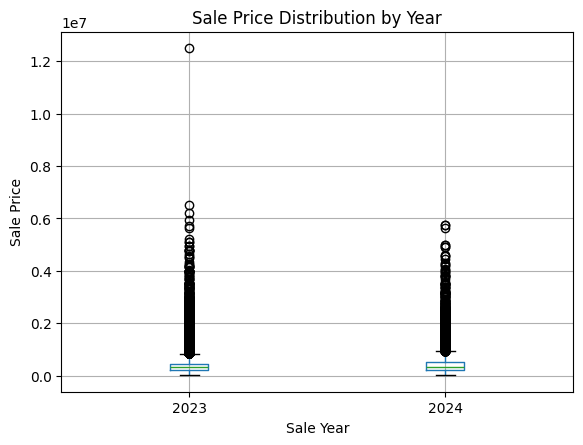

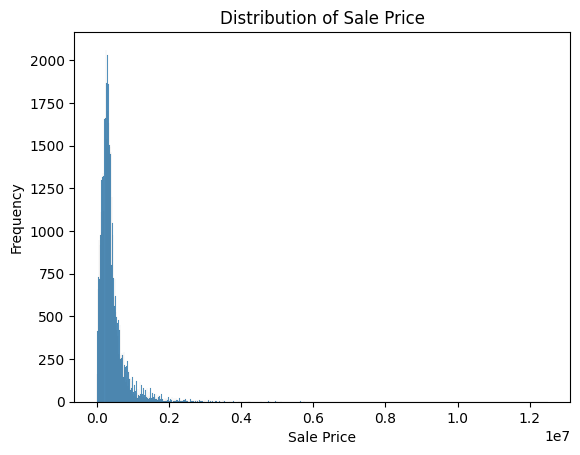

In [22]:
year_price_summary = train_data.groupby('sale_year')['sale_price'].agg(
    count='count',
    mean='mean',
    median='median',
    std='std',
    min='min',
    max='max'
)

print(year_price_summary.round(2))

# Draw the boxplot to find
train_data.boxplot(
    column='sale_price',
    by='sale_year'
)

plt.title('Sale Price Distribution by Year')
plt.suptitle('')
plt.xlabel('Sale Year')
plt.ylabel('Sale Price')
save_figure("01_sale_price_boxplot_by_year")
plt.show()


sns.histplot(train_data['sale_price'])
plt.title('Distribution of Sale Price')
plt.xlabel('Sale Price')
plt.ylabel('Frequency')
save_figure("02_sale_price_histogram")
plt.show()

As shown by the results above, both the median and mean sale prices experienced a significant increase between 2023 and mid-2024. The data also exhibit the influence of extreme values ​​and a right-skewed distribution, which could affect our subsequent exploratory data analysis (EDA). Therefore, we will apply a log transformation to mitigate the impact of these extreme values ​​and bring the distribution closer to a normal distribution.

           count   mean  median   std   min    max
sale_year                                         
2023       37520  12.63   12.66  0.77  9.27  16.34
2024       17333  12.72   12.74  0.76  9.27  15.56


<Figure size 900x500 with 0 Axes>

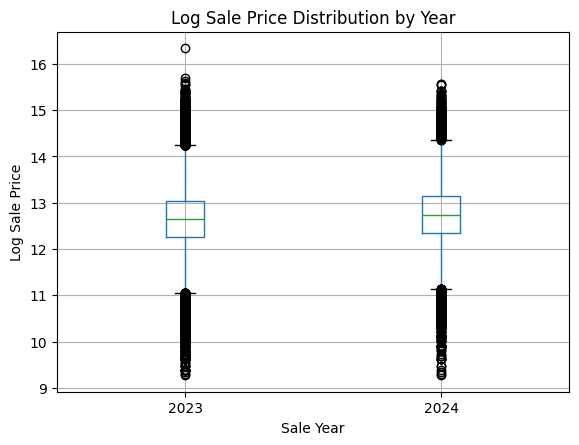

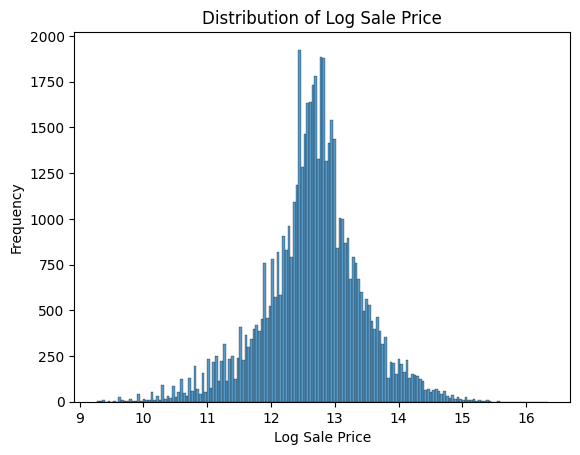

In [23]:
# Already checked that all sale prices are larger than 0
# use log transform to offset the influence of extreme value
train_data['log_sale_price'] = np.log1p(train_data['sale_price'])

year_logprice_summary = train_data.groupby('sale_year')['log_sale_price'].agg(
    count='count',
    mean='mean',
    median='median',
    std='std',
    min='min',
    max='max'
)

plt.figure(figsize=(9, 5))

print(year_logprice_summary.round(2))

# Draw the boxplot to find
train_data.boxplot(
    column='log_sale_price',
    by='sale_year'
)

plt.title('Log Sale Price Distribution by Year')
plt.suptitle('')
plt.xlabel('Sale Year')
plt.ylabel('Log Sale Price')
save_figure("03_log_sale_price_boxplot_by_year")
plt.show()

sns.histplot(train_data['log_sale_price'])
plt.title('Distribution of Log Sale Price')
plt.xlabel('Log Sale Price')
plt.ylabel('Frequency')
save_figure("04_log_sale_price_histogram")
plt.show()

As shown in the figure above, applying a log transformation reduces the influence of extreme values ​​and makes the distribution of the sale price more nearly normal. We derived this log transformation from the response variable in the training set and then applied it to the other two datasets.

In [24]:
val_data['log_sale_price'] = np.log1p(val_data['sale_price'])
test_data['log_sale_price'] = np.log1p(test_data['sale_price'])


Starting data imputation

We first analyze the missing values ​​in the training set to develop an imputation strategy. This strategy is then applied to the validation and test sets, ensuring that data leakage is avoided.

In [25]:
# Filter the feature that have missing value
missing_count_train = train_data.isnull().sum()
missing_fraction_train = train_data.isnull().mean()

missing_report = pd.DataFrame({
    'Count': missing_count_train,
    'Fraction': missing_fraction_train
})

missing_report = missing_report[missing_report['Count'] > 0].sort_values('Fraction', ascending=False)
print(missing_report)


                                                  Count  Fraction
loc_tax_special_service_area_num                  53291  0.971524
loc_school_unified_district_geoid                 52899  0.964378
loc_tax_tif_district_num                          50204  0.915246
char_tp_dsgn                                      29566  0.539004
char_tp_plan                                      15620  0.284761
prox_avg_school_rating_in_half_mile               13549  0.247006
acs5_median_household_total_occupied_year_built   12204  0.222486
char_gar1_cnst                                     9119  0.166244
other_school_district_elementary_avg_rating        2110  0.038466
other_school_district_secondary_avg_rating         2010  0.036643
loc_school_secondary_district_geoid                1954  0.035622
loc_school_elementary_district_geoid               1954  0.035622
acs5_median_household_renter_occupied_gross_rent   1377  0.025103
char_apts                                           487  0.008878
prox_num_f

Examine features with a missing value fraction of 1% or less, and determine whether the sample data associated with these minor missing values ​​have a significant impact on the price.

In [26]:
# Handle features whose missing value fractions are under 1%
# Extract features whose missing value fractions are under 1%
low_missing_cols = missing_report[missing_report['Fraction'] < 0.01].index
low_missing_cols_list = low_missing_cols.tolist()

print("Feature having missing fraction between 0% and 1% has amount", len(low_missing_cols_list), " ：")
print(low_missing_cols_list,'\n')

# Compare median sales price in missing value part to that in non-missing part
mnar_candidates = []

for col in low_missing_cols_list:
    missing_group = train_data[train_data[col].isnull()]["sale_price"]
    non_missing_group = train_data[train_data[col].notna()]["sale_price"]

    med_miss = missing_group.median()
    med_non_miss = non_missing_group.median()

    # If notna group's median not equal to 0, calculate diff percentage
    if med_non_miss > 0 and med_miss > 0:
        diff_pct = abs(med_miss - med_non_miss) / med_non_miss

        print(f"--- {col} ---")
        print(f"Missing median: {med_miss:.0f} | Non-missing median: {med_non_miss:.0f} | Diff: {diff_pct:.2%}")

        # if median's diff percentage outweigh 10%, identified as MNAR
        if diff_pct > 0.10:
            mnar_candidates.append(col)

print(f"\nFeatures identified as MNAR (price diff > 10%): {mnar_candidates}")



Feature having missing fraction between 0% and 1% has amount 19  ：
['char_apts', 'prox_num_foreclosure_per_1000_pin_past_5_years', 'loc_property_zip', 'acs5_median_household_owner_occupied_value', 'meta_cdu', 'loc_env_flood_fs_risk_direction', 'loc_env_flood_fs_factor', 'char_frpl', 'other_tax_bill_rate', 'char_gar1_att', 'char_gar1_area', 'char_porch', 'char_attic_fnsh', 'char_heat', 'char_bsmt_fin', 'char_gar1_size', 'char_bsmt', 'loc_access_cmap_walk_total_score', 'loc_access_cmap_walk_nta_score'] 

--- char_apts ---
Missing median: 242000 | Non-missing median: 325000 | Diff: 25.54%
--- prox_num_foreclosure_per_1000_pin_past_5_years ---
Missing median: 695000 | Non-missing median: 324000 | Diff: 114.51%
--- loc_property_zip ---
Missing median: 415000 | Non-missing median: 325000 | Diff: 27.69%
--- acs5_median_household_owner_occupied_value ---
Missing median: 203000 | Non-missing median: 325000 | Diff: 37.54%
--- meta_cdu ---
Missing median: 680000 | Non-missing median: 325000 | Dif

For these specific missing-value categories, we identified cases where the median price of samples with missing values ​​differed by more than 10% from the median price of samples without missing values; all items listed above meet this criterion. For features with more than 50 missing entries, we applied a "missing indicator" approach combined with mode/median imputation, while for features with fewer than 50 missing entries, we used simple imputation methods.

In [27]:
# Select those feature having less than 50 missing value to replace by mode or median
# 1. Extract columns with minor or low-to-moderate levels of missing data
tiny_missing_cols_list = missing_report[missing_report['Count'] <= 50].index.tolist()
mnar_list = [col for col in low_missing_cols_list if col not in tiny_missing_cols_list]

medians_dict = {}
modes_dict = {}
boolean_cols = []

for col in tiny_missing_cols_list + mnar_list:
    if col not in train_data.columns: continue

    # --- identify Boolean (Non-null value <= 2) ---
    unique_vals = train_data[col].dropna().unique()
    if len(unique_vals) <= 2 and len(unique_vals) > 0:
        boolean_cols.append(col)
        # Use mode to impute Boolean
        mode_series = train_data[col].mode()
        medians_dict[col] = mode_series.iloc[0] if not mode_series.empty else 0
        continue

    # --- exisiting logic ---
    if pd.api.types.is_numeric_dtype(train_data[col]):
        median_val = train_data[col].median()
        medians_dict[col] = median_val if pd.notna(median_val) else 0
    else:
        mode_series = train_data[col].mode()
        modes_dict[col] = mode_series.iloc[0] if not mode_series.empty else "Unknown"


def fill_datasets(df):
    df = df.copy()

    for col in tiny_missing_cols_list:
        if col not in df.columns: continue

        if col in boolean_cols:
            # Boolean: Filling in and Enforcing the Retention of Int64 Format
            df[col] = df[col].fillna(medians_dict[col]).astype('Int64')
        elif col in medians_dict:
            df[col] = df[col].astype(float).fillna(medians_dict[col])
        elif col in modes_dict:
            df[col] = df[col].fillna(modes_dict[col])

    for col in mnar_list:
        if col not in df.columns: continue

        ind_col = f"{col}_missing"
        df[ind_col] = df[col].isna().astype(int)

        if col in boolean_cols:
            df[col] = df[col].fillna(medians_dict[col]).astype('Int64')
        elif col in medians_dict:
            df[col] = df[col].astype(float).fillna(medians_dict[col])
        elif col in modes_dict:
            df[col] = df[col].fillna(modes_dict[col])

    return df

# execute imputation
train_data = fill_datasets(train_data)
val_data = fill_datasets(val_data)
test_data = fill_datasets(test_data)


# Check whether any significant gaps remain after the filling process.
remaining_missing = train_data[tiny_missing_cols_list + mnar_list].isnull().sum().sum()
print(f"After imputation, Number of remaining missing values in train_data: {remaining_missing}")

After imputation, Number of remaining missing values in train_data: 0


In [28]:
for col in tiny_missing_cols_list + mnar_list:
    if col in medians_dict and property_list[col].notna().all(): # verify no missing value left
        train_data[col] = train_data[col].astype('int64')

In [29]:
cols_to_fill = [
    'loc_tax_special_service_area_num',
    'loc_school_unified_district_geoid',
    'loc_tax_tif_district_num'
]

for df in [train_data, val_data, test_data]:
    for col in cols_to_fill:
        # 1. define the missingness indicator
        df[f"{col}_is_missing"] = df[col].isnull().astype(int)

        # 2. Fill in missing values ​​(replace existing NaNs with "Unknown")
        df[col] = df[col].fillna("Unknown").astype('string')

        # 3. Convert to the `category` data type
        df[col] = df[col].astype('category')


In [30]:
high_missing_cols_list = missing_report[missing_report['Fraction'] >= 0.01].index.tolist()

cols_already_handled = [
    'loc_tax_special_service_area_num',
    'loc_school_unified_district_geoid',
    'loc_tax_tif_district_num'
]
high_missing_cols_list = [c for c in high_missing_cols_list if c not in cols_already_handled]

# Take a snapshot of the original dtypes first (to avoid fillna/astype changing the basis for judgment later)
original_dtypes = {col: train_data[col].dtype for col in high_missing_cols_list}

high_medians = {}
high_modes = {}
geoid_cols = ['loc_school_elementary_district_geoid', 'loc_school_secondary_district_geoid']

# Identify boolean / 0-1 type columns (Int64, boolean, and integer columns whose value subset is {0,1})
def is_boolean_like(col):
    s = train_data[col]
    if pd.api.types.is_bool_dtype(s):
        return True
    if pd.api.types.is_integer_dtype(s):
        uniq = set(s.dropna().unique().tolist())
        return uniq.issubset({0, 1})
    return False

bool_like_cols = {c for c in high_missing_cols_list if is_boolean_like(c)}

# 2. Extract medians and modes (with crash protection)
for col in high_missing_cols_list:
    if col in geoid_cols:
        continue
    if col in bool_like_cols:
        continue  # Boolean columns don't use median/mode; handled in a separate branch

    if pd.api.types.is_numeric_dtype(train_data[col]):
        med = train_data[col].median()
        high_medians[col] = med if pd.notna(med) else 0.0
    else:
        mode_series = train_data[col].mode()
        if not mode_series.empty and pd.notna(mode_series.iloc[0]):
            high_modes[col] = mode_series.iloc[0]
        else:
            high_modes[col] = "Unknown"

# 3. Define the high-missing-rate imputation function
def fill_high_missing(df, cols_list, medians_map, modes_map, geoids, bool_cols, orig_dtypes):
    df = df.copy()

    for col in cols_list:
        # A. Missing indicator (with dedup protection to prevent duplicate calls)
        miss_col = f"{col}_missing"
        if miss_col not in df.columns:
            df[miss_col] = df[col].isna().astype(int)

        # B. Impute according to column type
        if col in geoids:
            # School district codes: fill with "Unknown", keep as string
            df[col] = df[col].fillna("Unknown").astype('string')

        elif col in bool_cols:
            # Boolean / 0-1 columns: not part of numeric median; fill with 0 or False, keep Int64/boolean
            orig_dtype = orig_dtypes.get(col)
            if pd.api.types.is_bool_dtype(orig_dtype):
                df[col] = df[col].fillna(False).astype('boolean')
            else:
                # Originally an Int64 0/1 column: fill with 0, keep Int64, do not convert to float
                df[col] = df[col].fillna(0).astype('Int64')

        elif col in medians_map:
            # True numeric type: safely convert to numeric then fill with median
            df[col] = pd.to_numeric(df[col], errors='coerce')
            df[col] = df[col].fillna(medians_map[col]).astype(float)

        elif col in modes_map:
            orig_dtype = orig_dtypes.get(col)
            if pd.api.types.is_integer_dtype(orig_dtype):
                # Other integer categorical columns: -1 means Unknown
                df[col] = df[col].fillna(-1).astype('Int64')
            else:
                df[col] = df[col].fillna(modes_map[col]).astype('string')

    return df

# 4. Execute (pass parameters explicitly to avoid global variable pitfalls)
train_data = fill_high_missing(
    train_data, high_missing_cols_list, high_medians, high_modes, geoid_cols, bool_like_cols, original_dtypes
)
val_data = fill_high_missing(
    val_data, high_missing_cols_list, high_medians, high_modes, geoid_cols, bool_like_cols, original_dtypes
)
test_data = fill_high_missing(
    test_data, high_missing_cols_list, high_medians, high_modes, geoid_cols, bool_like_cols, original_dtypes
)

In [31]:
# Check again whether there is any missing value left

check_miss_train = train_data.isnull().sum().sort_values(ascending=False)
check_miss_vali = val_data.isnull().sum().sort_values(ascending=False)
check_miss_test = test_data.isnull().sum().sort_values(ascending=False)

check_miss_train = check_miss_train[check_miss_train > 0]
check_miss_vali = check_miss_vali[check_miss_vali > 0]
check_miss_test = check_miss_test[check_miss_test > 0]

print ('train missing value left: \n',check_miss_train)
print ('\nvali missing value left: \n',check_miss_vali)
print ('\ntest missing value left: \n',check_miss_test)

train missing value left: 
 Series([], dtype: int64)

vali missing value left: 
 char_air      2
char_yrblt    1
dtype: int64

test missing value left: 
 char_air                                  1
acs5_median_income_household_past_year    1
dtype: int64


We have verified that there are no missing values ​​in the training set; however, they do exist in the validation and test sets. This is because, when the data is partitioned by year and quarter, these specific missing values ​​happen to fall exclusively within the latter two datasets. Furthermore, given the very small number of missing values, none were observed in the training set. To prevent data leakage—and noting that the number of missing values ​​requiring imputation is extremely low—we have opted for a simple imputation approach: filling these gaps using the mode or median of the corresponding feature derived from the training set.

In [ ]:
# Define the fallback policy from the training schema, not from held-out missingness.
# Validation/test null checks below only determine where an already defined rule is applied.
policy_columns = [
    col for col in train_data.columns
    if col not in {"sale_price", "log_sale_price", "sale_date", "property_id", "transaction_id"}
]

# 2. Define a safe fill-missing function
def safe_fill_missing(train_df, target_df, col):
    # If the column doesn't exist in train, or is entirely null, skip filling
    if col not in train_df.columns or train_df[col].isnull().all():
        return target_df
    if not target_df[col].isna().any():
        return target_df

    train_dtype = train_df[col].dtype
    target_dtype = target_df[col].dtype

    # ==========================================
    # Case A: categorical / string type (string, object, category) -> never convert to numeric, fill with mode
    # ==========================================
    if pd.api.types.is_string_dtype(train_dtype) or \
       pd.api.types.is_object_dtype(train_dtype) or \
       isinstance(train_dtype, pd.CategoricalDtype):

        mode_series = train_df[col].mode()
        fill_val = mode_series.iloc[0] if not mode_series.empty else "Unknown"

        # If target is a category type, add the new category first
        if isinstance(target_dtype, pd.CategoricalDtype):
            if fill_val not in target_df[col].cat.categories:
                target_df[col] = target_df[col].cat.add_categories([fill_val])

        target_df[col] = target_df[col].fillna(fill_val)

    # ==========================================
    # Case B: nullable integer type (Int64) -> fill with its mode, keep Int64
    # ==========================================
    elif pd.api.types.is_integer_dtype(train_dtype):
        # Integer categories are typically imputed with the mode rather than the median
        # (to avoid meaningless decimals like 2.5)
        mode_series = train_df[col].mode()
        fill_val = mode_series.iloc[0] if not mode_series.empty else 0

        # Fill and keep Int64
        target_df[col] = target_df[col].fillna(fill_val).astype('Int64')

    # ==========================================
    # Case C: pure continuous numeric type (float) -> fill with median
    # ==========================================
    elif pd.api.types.is_numeric_dtype(train_dtype):
        fill_val = train_df[col].median()
        if pd.isna(fill_val):
            fill_val = 0.0
        # Fill directly as float
        target_df[col] = pd.to_numeric(target_df[col], errors='coerce').astype('float64').fillna(fill_val)

    # ==========================================
    # Case D: fallback for everything else
    # ==========================================
    else:
        mode_series = train_df[col].mode()
        fill_val = mode_series.iloc[0] if not mode_series.empty else "Unknown"
        target_df[col] = target_df[col].fillna(fill_val)

    return target_df

# Apply each training-defined fallback to both held-out partitions.
# Only columns that actually need filling require the legacy dtype alignment below.
filled_columns = []
for col in policy_columns:
    if val_data[col].isna().any() or test_data[col].isna().any():
        filled_columns.append(col)
        print(f"Feature [{col:50s}] -> filling held-out nulls with Train statistics...")
    val_data = safe_fill_missing(train_data, val_data, col)
    test_data = safe_fill_missing(train_data, test_data, col)

# 4. Final verification
print("\n--- Final check ---")
print("train missing:", train_data.isnull().sum().sum())
print("val missing:  ", val_data.isnull().sum().sum())
print("test missing: ", test_data.isnull().sum().sum())

# Force dtype alignment (optional, to ensure all three datasets have consistent types)
for col in filled_columns:
    if col in train_data.columns:
        # Align Int64
        if pd.api.types.is_integer_dtype(train_data[col]):
            val_data[col] = val_data[col].round().astype('Int64')
            test_data[col] = test_data[col].round().astype('Int64')
        # Align string
        elif pd.api.types.is_string_dtype(train_data[col]) or isinstance(train_data[col].dtype, pd.CategoricalDtype):
            val_data[col] = val_data[col].astype(train_data[col].dtype)
            test_data[col] = test_data[col].astype(train_data[col].dtype)

For features with missing values ​​identified in the two sets outside of the training set, we applied simple imputation. Although some of these features relate to years, given that no such missing values ​​were observed in the training set—and because the extent of missingness is very minor—we determined that simple imputation (using the median or mode) is a reasonable approach.

Before we set packages for different types of features, we firstly do EDA to analyze price/ log price change over time and across locations

Training-only temporal sale-price diagnostic

Monthly training-period summary
 sale_year  sale_month  transactions  mean_price  median_price      p25      p75 sale_ym
      2023           1          1973   349771.98      275000.0 175000.0 395000.0 2023-01
      2023           2          2274   367060.27      288000.0 185000.0 420000.0 2023-02
      2023           3          3305   391969.52      300000.0 200000.0 450000.0 2023-03
      2023           4          3217   405212.99      320000.0 210000.0 457500.0 2023-04
      2023           5          3847   420153.53      327500.0 220000.0 479900.0 2023-05
      2023           6          4147   448046.70      340000.0 224850.0 525000.0 2023-06
      2023           7          3529   430020.59      335000.0 225000.0 500000.0 2023-07
      2023           8          3682   421039.75      330000.0 223312.5 480000.0 2023-08
      2023           9          3149   412149.97      319900.0 218000.0 475000.0 2023-09
      2023          10          

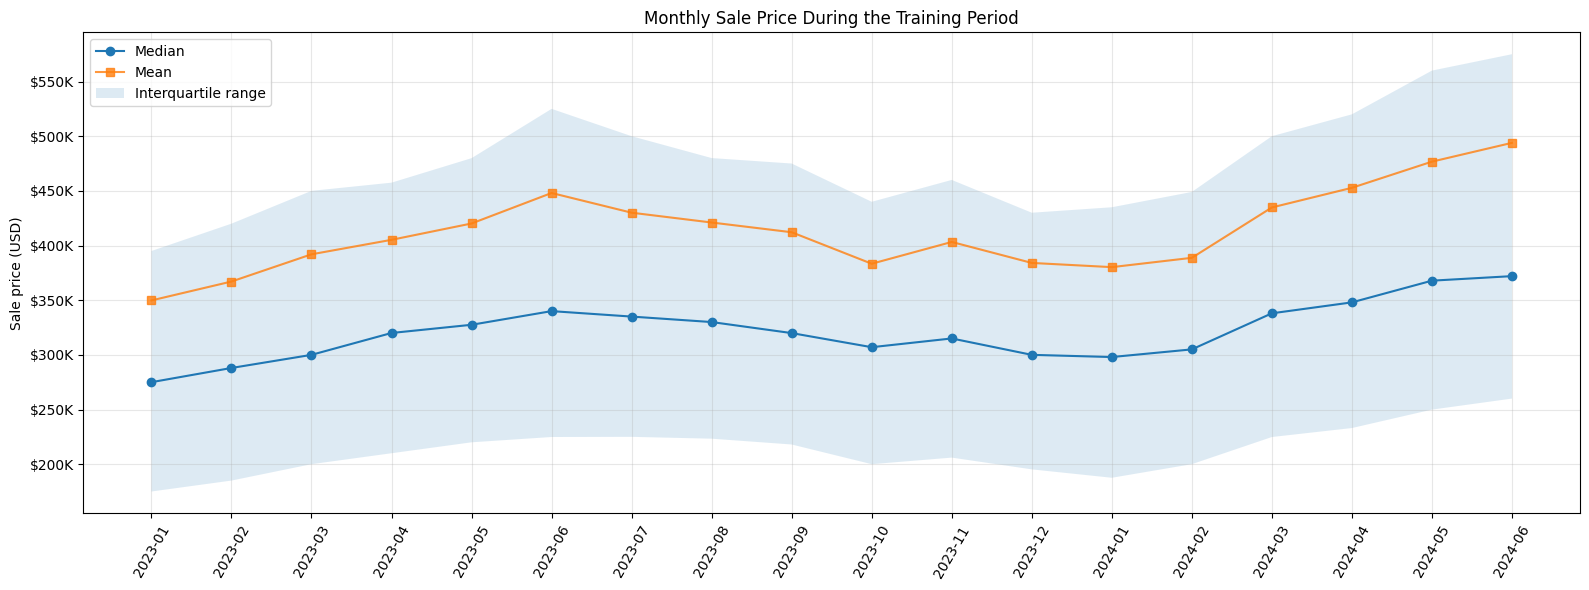


Comparable January-June year summary
           transactions  mean_price  median_price
sale_year                                        
2023              18763  404,956.82    313,000.00
2024              17333  445,232.43    340,000.00
January-June median change from 2023 to 2024: +8.63%

Same-month median comparison
sale_year        2023       2024  change_percent
sale_month                                      
1          275,000.00 298,000.00            8.36
2          288,000.00 305,000.00            5.90
3          300,000.00 338,000.00           12.67
4          320,000.00 348,000.00            8.75
5          327,500.00 367,850.00           12.32
6          340,000.00 372,000.00            9.41

Interpretation guardrail: these are descriptive transaction-price patterns. They may reflect market timing and changes in the mix of properties sold; they do not establish a causal seasonal premium.


In [33]:
print("=" * 80)
print("Training-only temporal sale-price diagnostic")
print("=" * 80)

time_price_summary = (
    train_data.groupby(["sale_year", "sale_month"])["sale_price"]
    .agg(
        transactions="count",
        mean_price="mean",
        median_price="median",
        p25=lambda values: values.quantile(0.25),
        p75=lambda values: values.quantile(0.75),
    )
    .reset_index()
)
time_price_summary["sale_ym"] = (
    time_price_summary["sale_year"].astype(str)
    + "-"
    + time_price_summary["sale_month"].astype(str).str.zfill(2)
)

print("\nMonthly training-period summary")
print(time_price_summary.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(
    time_price_summary["sale_ym"],
    time_price_summary["median_price"],
    marker="o",
    label="Median",
)
ax.plot(
    time_price_summary["sale_ym"],
    time_price_summary["mean_price"],
    marker="s",
    label="Mean",
    alpha=0.8,
)
ax.fill_between(
    time_price_summary["sale_ym"],
    time_price_summary["p25"],
    time_price_summary["p75"],
    alpha=0.15,
    label="Interquartile range",
)
ax.set_title("Monthly Sale Price During the Training Period")
ax.set_ylabel("Sale price (USD)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda value, _: f"${value/1e3:.0f}K"))
ax.tick_params(axis="x", rotation=60)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
save_figure("05_monthly_sale_price_training")
plt.show()

# Compare like-for-like calendar months because the training data contain only
# January-June for 2024 but all twelve months for 2023.
comparable_period = train_data.loc[train_data["sale_month"].between(1, 6)].copy()
comparable_year_summary = (
    comparable_period.groupby("sale_year")["sale_price"]
    .agg(transactions="count", mean_price="mean", median_price="median")
)
jan_jun_2023 = comparable_year_summary.loc[2023, "median_price"]
jan_jun_2024 = comparable_year_summary.loc[2024, "median_price"]
comparable_change = (jan_jun_2024 / jan_jun_2023 - 1) * 100

same_month_medians = comparable_period.pivot_table(
    index="sale_month",
    columns="sale_year",
    values="sale_price",
    aggfunc="median",
)
same_month_medians["change_percent"] = (
    same_month_medians[2024] / same_month_medians[2023] - 1
) * 100

print("\nComparable January-June year summary")
print(comparable_year_summary.to_string(float_format=lambda value: f"{value:,.2f}"))
print(f"January-June median change from 2023 to 2024: {comparable_change:+.2f}%")
print("\nSame-month median comparison")
print(same_month_medians.to_string(float_format=lambda value: f"{value:,.2f}"))
print(
    "\nInterpretation guardrail: these are descriptive transaction-price patterns. "
    "They may reflect market timing and changes in the mix of properties sold; "
    "they do not establish a causal seasonal premium."
)



Training-only spatial sale-price diagnostic
City column: loc_property_city
Non-missing city values: 54,853
Distinct cities: 132


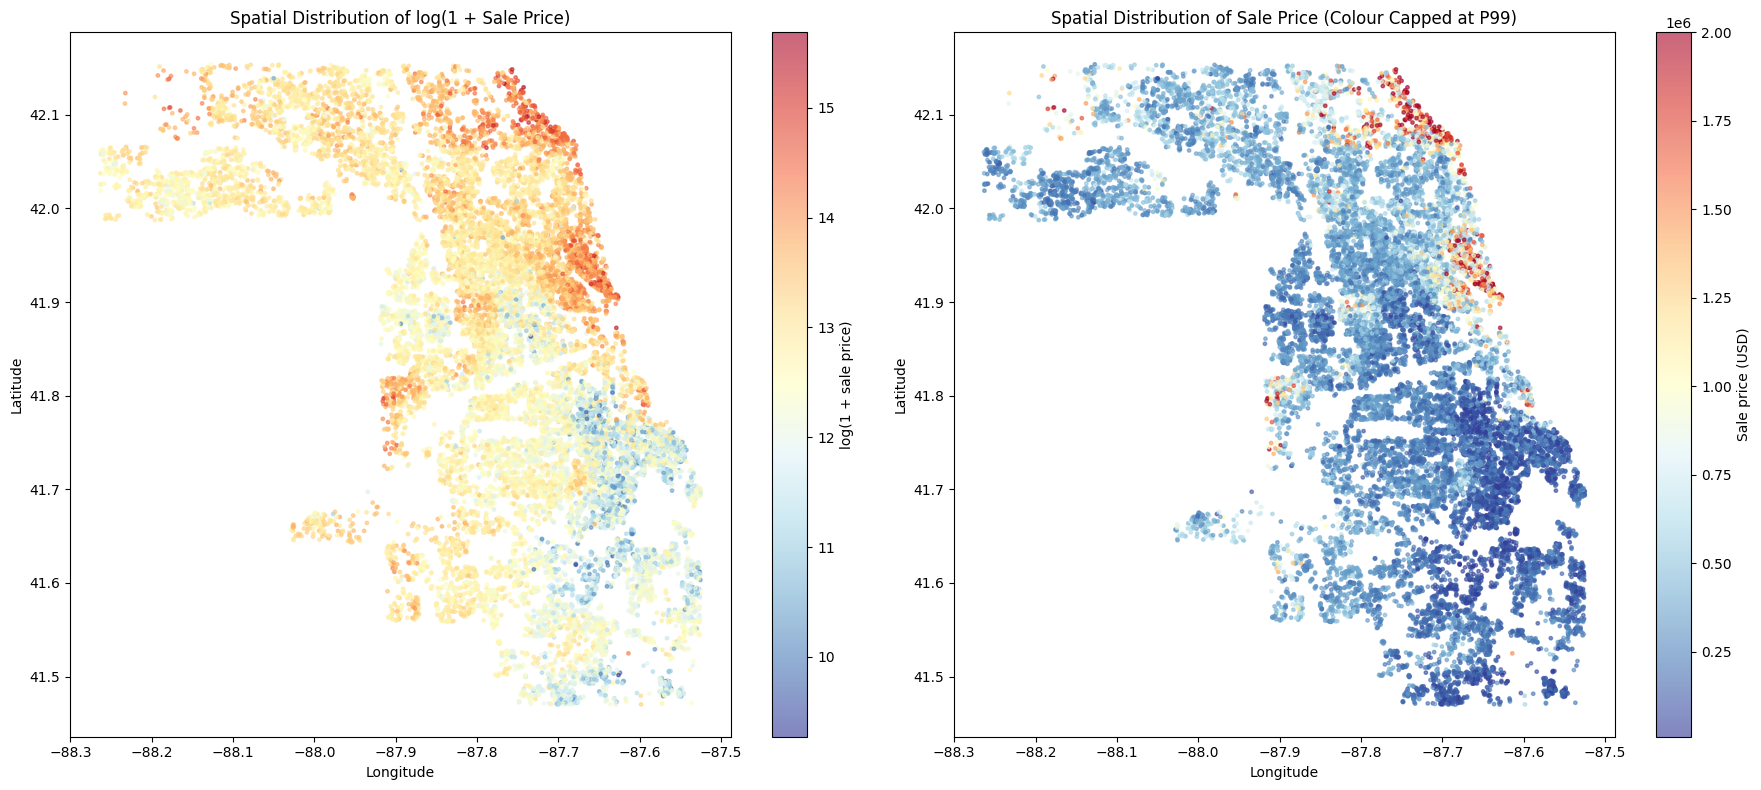

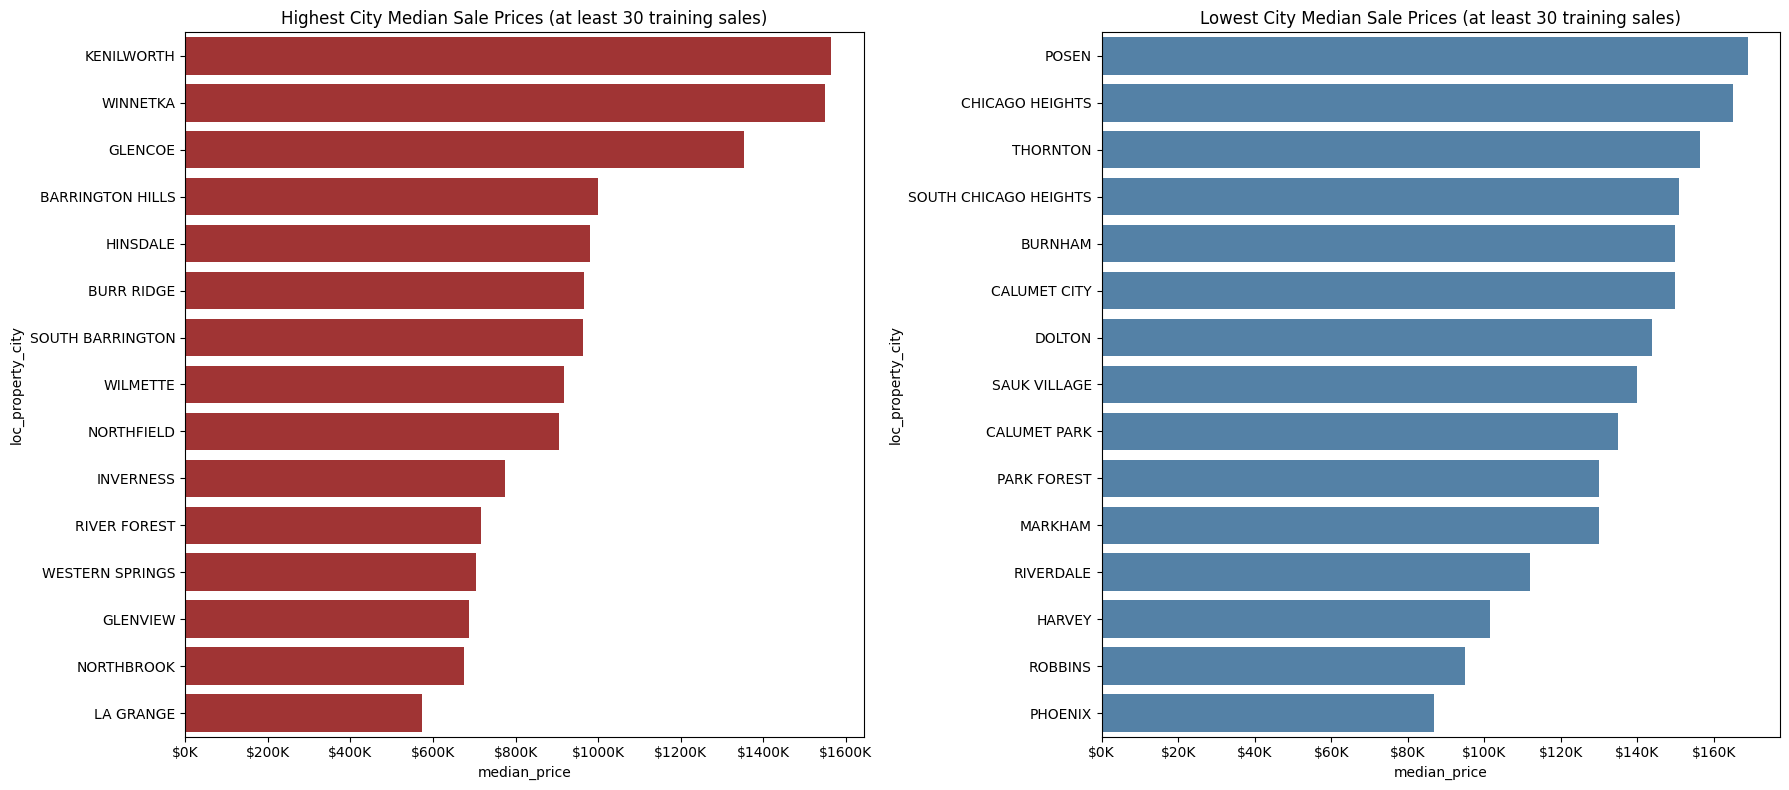


Most frequent cities
                   transactions  mean_price  median_price
loc_property_city                                        
CHICAGO                   22235  421,703.43    310,000.00
ARLINGTON HEIGHTS           981  535,774.36    485,000.00
ORLAND PARK                 923  451,580.93    400,000.00
DES PLAINES                 832  366,691.91    350,000.00
PALATINE                    786  441,564.11    415,000.00
GLENVIEW                    784  818,066.63    687,000.00
OAK PARK                    738  561,564.96    525,000.00
OAK LAWN                    727  306,120.16    301,000.00
SCHAUMBURG                  701  417,919.05    395,000.00
TINLEY PARK                 690  336,830.03    322,000.00

Latitude-decile median ratio: 2.66x
Longitude-decile median ratio: 2.25x
Interpretation guardrail: the maps and grouped medians show spatial association, not a causal location effect. Property type, size, condition, transaction mix and other neighbourhood factors can confound thes

In [34]:
print("\n" + "=" * 80)
print("Training-only spatial sale-price diagnostic")
print("=" * 80)

city_column = "loc_property_city"
required_columns = {
    city_column,
    "loc_longitude",
    "loc_latitude",
    "sale_price",
}
missing_columns = required_columns - set(train_data.columns)
if missing_columns:
    raise KeyError(f"Missing spatial diagnostic columns: {sorted(missing_columns)}")

spatial_eda = train_data[list(required_columns)].copy()
print(f"City column: {city_column}")
print(f"Non-missing city values: {spatial_eda[city_column].notna().sum():,}")
print(f"Distinct cities: {spatial_eda[city_column].nunique(dropna=True):,}")

plot_sample = spatial_eda.sample(min(20_000, len(spatial_eda)), random_state=42)
display_cap = plot_sample["sale_price"].quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

raw_scatter = axes[0].scatter(
    plot_sample["loc_longitude"],
    plot_sample["loc_latitude"],
    c=np.log1p(plot_sample["sale_price"]),
    cmap="RdYlBu_r",
    s=6,
    alpha=0.6,
)
axes[0].set_title("Spatial Distribution of log(1 + Sale Price)")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
plt.colorbar(raw_scatter, ax=axes[0], label="log(1 + sale price)")

clipped_scatter = axes[1].scatter(
    plot_sample["loc_longitude"],
    plot_sample["loc_latitude"],
    c=plot_sample["sale_price"].clip(upper=display_cap),
    cmap="RdYlBu_r",
    s=6,
    alpha=0.6,
)
axes[1].set_title("Spatial Distribution of Sale Price (Colour Capped at P99)")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
plt.colorbar(clipped_scatter, ax=axes[1], label="Sale price (USD)")
plt.tight_layout()
save_figure("06_spatial_sale_price_maps")
plt.show()

city_summary = (
    spatial_eda.groupby(city_column)["sale_price"]
    .agg(transactions="count", mean_price="mean", median_price="median")
)
city_summary = city_summary.loc[city_summary["transactions"] >= 30]
city_summary = city_summary.sort_values("median_price", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
sns.barplot(
    x=city_summary.head(15)["median_price"],
    y=city_summary.head(15).index,
    ax=axes[0],
    color="firebrick",
)
sns.barplot(
    x=city_summary.tail(15)["median_price"],
    y=city_summary.tail(15).index,
    ax=axes[1],
    color="steelblue",
)
axes[0].set_title("Highest City Median Sale Prices (at least 30 training sales)")
axes[1].set_title("Lowest City Median Sale Prices (at least 30 training sales)")
for axis in axes:
    axis.xaxis.set_major_formatter(
        mtick.FuncFormatter(lambda value, _: f"${value/1e3:.0f}K")
    )
plt.tight_layout()
save_figure("07_city_median_sale_prices")
plt.show()

latitude_bins = pd.qcut(spatial_eda["loc_latitude"], q=10, duplicates="drop")
longitude_bins = pd.qcut(spatial_eda["loc_longitude"], q=10, duplicates="drop")
latitude_medians = spatial_eda.groupby(latitude_bins, observed=True)["sale_price"].median()
longitude_medians = spatial_eda.groupby(longitude_bins, observed=True)["sale_price"].median()

print("\nMost frequent cities")
print(
    city_summary.sort_values("transactions", ascending=False)
    .head(10)
    .to_string(float_format=lambda value: f"{value:,.2f}")
)
print(
    f"\nLatitude-decile median ratio: "
    f"{latitude_medians.max() / latitude_medians.min():.2f}x"
)
print(
    f"Longitude-decile median ratio: "
    f"{longitude_medians.max() / longitude_medians.min():.2f}x"
)
print(
    "Interpretation guardrail: the maps and grouped medians show spatial "
    "association, not a causal location effect. Property type, size, condition, "
    "transaction mix and other neighbourhood factors can confound these patterns."
)


Next, we separate feature according to their data type to do EDA.

In [35]:
# delete irrelevant columns for training model

drop_cols = ['sale_date', 'sale_quarter','transaction_id']

train_data = train_data.drop(columns=[c for c in drop_cols if c in train_data.columns])
val_data   = val_data.drop(columns=[c for c in drop_cols if c in val_data.columns])
test_data  = test_data.drop(columns=[c for c in drop_cols if c in test_data.columns])

# Verify whether 3 sets' columns still the same
cols_train = set(train_data.columns)
cols_val   = set(val_data.columns)
cols_test  = set(test_data.columns)

print("train vs val diff:", cols_train ^ cols_val)
print("train vs test diff:", cols_train ^ cols_test)
print("All 3 set columns are the same:", cols_train == cols_val == cols_test)

train vs val diff: set()
train vs test diff: set()
All 3 set columns are the same: True


In [36]:
exclude_cols = ['sale_price', 'log_sale_price','sale_month', 'sale_year']
type_map = var_dict.set_index('variable')['type'].to_dict()
available_features = [c for c in train_data.columns if c not in exclude_cols]

# Initialize four buckets
pkg_continuous = []     # Continuous numeric (float)
pkg_discrete = []       # Discrete numeric (int, counts)
pkg_boolean = []        # Binary / indicator (strictly 0/1)
pkg_category = []       # Categorical / labels (str, or non-true-boolean values like 1/2)

for col in available_features:
    # 1. Get the unique values of the column (convert to a set for comparison; cast to string to avoid mixing 0 and '0')
    unique_set = set(train_data[col].dropna().astype(str).unique())
    n_unique = len(unique_set)

    # ==========================================
    # Priority 1: true Boolean / Indicator type (strict check)
    # ==========================================
    # A true boolean must be 0/1 (or '0'/'1' after casting booleans to strings)
    if n_unique > 0 and unique_set.issubset({'0', '1'}):
        pkg_boolean.append(col)
        continue

    # ==========================================
    # Priority 2: Categorical / Label type (low-cardinality, not 0/1)
    # ==========================================
    col_type = type_map.get(col, 'unknown')

    # If defined as categorical in the dictionary, or the column is already string type
    if col_type == 'categorical' or pd.api.types.is_string_dtype(train_data[col]) or isinstance(train_data[col].dtype, pd.CategoricalDtype):
        pkg_category.append(col)
        continue

    # ==========================================
    # Priority 3: split Numeric into Continuous and Discrete
    # ==========================================
    if col_type == 'numeric':
        # If numeric, with few values (<=15), and all integers
        unique_vals = train_data[col].dropna().unique()
        if n_unique <= 15 and all(float(x).is_integer() for x in unique_vals):
            pkg_discrete.append(col)
        else:
            pkg_continuous.append(col)
        continue

    # ==========================================
    # Priority 4: custom features not in the dictionary (fallback)
    # ==========================================
    if pd.api.types.is_float_dtype(train_data[col]) and n_unique > 15:
        pkg_continuous.append(col)
    elif n_unique <= 15:
        pkg_discrete.append(col)
    else:
        pkg_category.append(col)

# ==========================================
# Print results and split the DataFrame
# ==========================================
print(f"✅ Continuous numeric (float): {len(pkg_continuous)}")
print(f"✅ Discrete numeric (int / low-cardinality): {len(pkg_discrete)}")
print(f"✅ Boolean / indicator (0/1): {len(pkg_boolean)}")
print(f"✅ Categorical / label (str): {len(pkg_category)}")

# Print the columns that were "kicked out" of Boolean to verify they are 1/2-type columns
suspect_cat = [c for c in pkg_category if set(train_data[c].dropna().astype(str).unique()).issubset({'1', '2'})]
if suspect_cat:
    print(f"\n💡 Found {len(suspect_cat)} columns that could have been misclassified as Boolean (1/2 categories) and were correctly assigned to Category: {suspect_cat[:5]}")

# Actually split the data
df_continuous = train_data[pkg_continuous]
df_discrete = train_data[pkg_discrete]
df_boolean = train_data[pkg_boolean]
df_category = train_data[pkg_category]

✅ Continuous numeric (float): 52
✅ Discrete numeric (int / low-cardinality): 7
✅ Boolean / indicator (0/1): 27
✅ Categorical / label (str): 33

💡 Found 2 columns that could have been misclassified as Boolean (1/2 categories) and were correctly assigned to Category: ['char_use', 'char_air']


For features in the `pkg_category` that still contain decimal points or are not of the `string` type, remove the decimal points and convert them to the `string` type.

In [37]:
# 1. Identify categorical columns containing decimal-point-like formats
decimal_cat_cols = []

for col in pkg_category:
    # Get unique non-null values, cast to string
    unique_vals = train_data[col].dropna().astype(str).unique()

    if len(unique_vals) == 0:
        continue

    # Regex check: at least one value matches the "number.number" format (e.g., 1.0, 9.9)
    has_decimal = any(re.match(r'^-?\d+\.\d+$', str(val).strip()) for val in unique_vals)

    if has_decimal:
        # Print the first 5 values to see what they look like
        sample_vals = unique_vals[:5]
        decimal_cat_cols.append(col)
        print(f"⚠️ Column [{col}] appears to contain decimal points: sample values = {sample_vals}")

if not decimal_cat_cols:
    print("✅ No categorical features containing decimal points were found.")
else:
    print(f"\nA total of {len(decimal_cat_cols)} columns containing decimal points were found and need to be handled.")

⚠️ Column [loc_property_zip] appears to contain decimal points: sample values = ['60062.0' '60534.0' '60457.0' '60628.0' '60462.0']
⚠️ Column [char_type_resd] appears to contain decimal points: sample values = ['2' '1' '4' '5' '3']
⚠️ Column [char_tp_plan] appears to contain decimal points: sample values = ['2.0' '1.0']
⚠️ Column [loc_chicago_ward_num] appears to contain decimal points: sample values = ['Non-Chicago' '8.0' '1.0' '37.0' '28.0']
⚠️ Column [loc_school_elementary_district_geoid] appears to contain decimal points: sample values = ['1724420.0' '1723850.0' '1728890.0' '610178.0' '1730220.0']
⚠️ Column [loc_school_secondary_district_geoid] appears to contain decimal points: sample values = ['1729010.0' '1726880.0' '1708400.0' '609710.0' '1738970.0']
⚠️ Column [loc_school_unified_district_geoid] appears to contain decimal points: sample values = ['Unknown' '1713710.0' '1705050.0' '1714100.0' '1708550.0']
⚠️ Column [loc_tax_special_service_area_num] appears to contain decimal po

In [38]:
# Show the first 10 rows + dtype + missing statistics
cat_sample = train_data[pkg_category].head(10).T  # Transpose for easier viewing

# Append dtype and missing information
cat_sample['dtype'] = train_data[pkg_category].dtypes
cat_sample['missing_rate'] = train_data[pkg_category].isnull().mean()

pd.set_option('display.max_rows', None)
pd.set_option('display.width', 300)
print(cat_sample)

                                                   0               1               2               3               4               5                6               7               8               9           dtype  missing_rate
property_id                           04211120100000  18023090540000  23013140100000  25112030810000  27144070010000  29104080390000   32192070200000  02114150230000  08241130090000  13363080100000  string[python]           0.0
loc_property_city                         NORTHBROOK           LYONS   HICKORY HILLS         CHICAGO     ORLAND PARK          DOLTON  CHICAGO HEIGHTS        PALATINE     DES PLAINES         CHICAGO          object           0.0
loc_property_zip                             60062.0         60534.0         60457.0         60628.0         60462.0         60419.0          60411.0         60074.0         60016.0         60647.0  string[python]           0.0
char_type_resd                                     2               1               1    

In [39]:
print("\n🔍 2. Check nunique of all Category features across Train/Val/Test:\n")

datasets = {'Train': train_data, 'Val': val_data, 'Test': test_data}

report_data = []
for col in pkg_category:
    row = {'Feature': col}

    # Compute nunique across the three datasets
    for name, df in datasets.items():
        row[f'{name} nunique'] = df[col].nunique() if col in df.columns else None

    # Extract the actual unique values from the Train set (show at most the first 10 to avoid flooding; show all if fewer than 10)
    if col in train_data.columns:
        unique_vals = train_data[col].dropna().unique()
        sample_str = ", ".join([str(x) for x in unique_vals[:10]])
        if len(unique_vals) > 10:
            sample_str += " ..."
        row['Train Unique Values'] = f"[{sample_str}]"
    else:
        row['Train Unique Values'] = "N/A"

    report_data.append(row)

# Convert to a DataFrame and format the output
report_df = pd.DataFrame(report_data)

# Set pandas display options to prevent column folding and long-string truncation
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 250)
pd.set_option('display.max_colwidth', 80)

print(report_df.to_string(index=False))


🔍 2. Check nunique of all Category features across Train/Val/Test:

                             Feature  Train nunique  Val nunique  Test nunique                                                                                                                                                  Train Unique Values
                         property_id          51667        17850         34973 [04211120100000, 18023090540000, 23013140100000, 25112030810000, 27144070010000, 29104080390000, 32192070200000, 02114150230000, 08241130090000, 13363080100000 ...]
                   loc_property_city            132          129           132                                            [NORTHBROOK, LYONS, HICKORY HILLS, CHICAGO, ORLAND PARK, DOLTON, CHICAGO HEIGHTS, PALATINE, DES PLAINES, WESTCHESTER ...]
                    loc_property_zip            169          167           169                                                                       [60062.0, 60534.0, 60457.0, 60628.0, 60462.0, 6041

In [40]:
print("🚀 1. Starting forced cleaning and conversion of all categorical columns to string[python] ...")

for col in pkg_category:
    for name, df in datasets.items():
        if col in df.columns:
            # 1. First convert everything to plain strings (Int64 becomes '1', float becomes '1.0')
            s = df[col].astype(str)

            # 2. Use regex to strip trailing .0 (e.g., '1.0' -> '1')
            s = s.str.replace(r'\.0$', '', regex=True)

            # 3. Safely convert values that were originally null (now strings like 'nan', 'None') back to pandas <NA>
            s = s.replace(['nan', 'NaN', '<NA>', 'None', 'NaT'], pd.NA)

            # 4. Final forced conversion: cast to pure string[python]
            df[col] = s.astype('string')

🚀 1. Starting forced cleaning and conversion of all categorical columns to string[python] ...


In [41]:
exclude_cols = ['sale_price', 'log_sale_price']
type_map = var_dict.set_index('variable')['type'].to_dict()
available_features = [c for c in train_data.columns if c not in exclude_cols]

# Initialize four buckets
pkg_continuous = []     # Continuous numeric (float)
pkg_discrete = []       # Discrete numeric (int, counts)
pkg_boolean = []        # Binary / indicator (strictly 0/1)
pkg_category = []       # Categorical / labels (str, or non-true-boolean values like 1/2)

for col in available_features:
    # 1. Get the unique values of the column (convert to a set for comparison; cast to string to avoid mixing 0 and '0')
    unique_set = set(train_data[col].dropna().astype(str).unique())
    n_unique = len(unique_set)

    # ==========================================
    # Priority 1: true Boolean / Indicator type (strict check)
    # ==========================================
    # A true boolean must be 0/1 (or '0'/'1' after casting booleans to strings)
    if n_unique > 0 and unique_set.issubset({'0', '1'}):
        pkg_boolean.append(col)
        continue

    # ==========================================
    # Priority 2: Categorical / Label type (low-cardinality, not 0/1)
    # ==========================================
    col_type = type_map.get(col, 'unknown')

    # If defined as categorical in the dictionary, or the column is already string type
    if col_type == 'categorical' or pd.api.types.is_string_dtype(train_data[col]) or isinstance(train_data[col].dtype, pd.CategoricalDtype):
        pkg_category.append(col)
        continue

    # ==========================================
    # Priority 3: split Numeric into Continuous and Discrete
    # ==========================================
    if col_type == 'numeric':
        # If numeric, with few values (<=15), and all integers
        unique_vals = train_data[col].dropna().unique()
        if n_unique <= 15 and all(float(x).is_integer() for x in unique_vals):
            pkg_discrete.append(col)
        else:
            pkg_continuous.append(col)
        continue

    # ==========================================
    # Priority 4: custom features not in the dictionary (fallback)
    # ==========================================
    if pd.api.types.is_float_dtype(train_data[col]) and n_unique > 15:
        pkg_continuous.append(col)
    elif n_unique <= 15:
        pkg_discrete.append(col)
    else:
        pkg_category.append(col)

# ==========================================
# Print results and split the DataFrame
# ==========================================
print(f"✅ Continuous numeric (float): {len(pkg_continuous)}")
print(f"✅ Discrete numeric (int / low-cardinality): {len(pkg_discrete)}")
print(f"✅ Boolean / indicator (0/1): {len(pkg_boolean)}")
print(f"✅ Categorical / label (str): {len(pkg_category)}")

# Print the columns that were "kicked out" of Boolean to verify they are 1/2-type columns
suspect_cat = [c for c in pkg_category if set(train_data[c].dropna().astype(str).unique()).issubset({'1', '2'})]
if suspect_cat:
    print(f"\n💡 Found {len(suspect_cat)} columns that could have been misclassified as Boolean (1/2 categories) and were correctly assigned to Category: {suspect_cat[:5]}")

# Actually split the data
df_continuous = train_data[pkg_continuous]
df_discrete = train_data[pkg_discrete]
df_boolean = train_data[pkg_boolean]
df_category = train_data[pkg_category]

✅ Continuous numeric (float): 52
✅ Discrete numeric (int / low-cardinality): 9
✅ Boolean / indicator (0/1): 27
✅ Categorical / label (str): 33

💡 Found 3 columns that could have been misclassified as Boolean (1/2 categories) and were correctly assigned to Category: ['char_use', 'char_air', 'char_tp_plan']


Check again if the convertion is successful

In [42]:
# Show the first 10 rows + dtype + missing statistics
cat_sample = df_category.head(10).T

cat_sample['dtype'] = df_category.dtypes
cat_sample['missing_rate'] = df_category.isnull().mean()

pd.set_option('display.max_rows', None)
pd.set_option('display.width', 300)
print(cat_sample)

                                                   0               1               2               3               4               5                6               7               8               9           dtype  missing_rate
property_id                           04211120100000  18023090540000  23013140100000  25112030810000  27144070010000  29104080390000   32192070200000  02114150230000  08241130090000  13363080100000  string[python]           0.0
loc_property_city                         NORTHBROOK           LYONS   HICKORY HILLS         CHICAGO     ORLAND PARK          DOLTON  CHICAGO HEIGHTS        PALATINE     DES PLAINES         CHICAGO  string[python]           0.0
loc_property_zip                               60062           60534           60457           60628           60462           60419            60411           60074           60016           60647  string[python]           0.0
char_type_resd                                     2               1               1    

In [43]:
# 1. Identify categorical columns containing decimal-point-like formats
decimal_cat_cols = []

for col in pkg_category:
    # Get unique non-null values, cast to string
    unique_vals = train_data[col].dropna().astype(str).unique()

    if len(unique_vals) == 0:
        continue

    # Regex check: at least one value matches the "number.number" format (e.g., 1.0, 9.9)
    has_decimal = any(re.match(r'^-?\d+\.\d+$', str(val).strip()) for val in unique_vals)

    if has_decimal:
        # Print the first 5 values to see what they look like
        sample_vals = unique_vals[:5]
        decimal_cat_cols.append(col)
        print(f"⚠️ Column [{col}] appears to contain decimal points: sample values = {sample_vals}")

if not decimal_cat_cols:
    print("✅ No categorical features containing decimal points were found.")
else:
    print(f"\nA total of {len(decimal_cat_cols)} columns containing decimal points were found and need to be handled.")

⚠️ Column [char_type_resd] appears to contain decimal points: sample values = ['2' '1' '4' '5' '3']

A total of 1 columns containing decimal points were found and need to be handled.


The categorical variables were examined, and their data types were converted to facilitate subsequent EDA and feature engineering tasks. A final check confirmed the absence of anomalies; the results for `char_type_resd` were manually verified as normal, as the presence of the string value "9.9" had triggered a detection of a decimal point.

Next, set interaction

In [44]:
from scipy.stats import pearsonr, spearmanr
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler

print("Creating domain-motivated interactions on their physical scales...")

# Average quality is the reference category. The main building-area effect is
# therefore the average-quality slope, while these two interactions estimate
# slope differences for Deluxe and Poor properties.
quality_codes = {"1": "deluxe", "3": "poor"}
quality_interaction_columns = []
for quality_code, quality_label in quality_codes.items():
    column = f"inter_bldg_sf_quality_{quality_label}"
    quality_interaction_columns.append(column)
    for frame in (train_data, val_data, test_data):
        building_area = pd.to_numeric(frame["char_bldg_sf"], errors="coerce")
        construction_quality = frame["char_cnst_qlty"].astype("string").str.strip()
        frame[column] = building_area * construction_quality.eq(quality_code).astype(float)

for frame in (train_data, val_data, test_data):
    land_area = pd.to_numeric(frame["char_land_sf"], errors="coerce").clip(lower=0)
    building_area = pd.to_numeric(frame["char_bldg_sf"], errors="coerce").clip(lower=0)
    frame["inter_log1p_land_bldg_product"] = np.log1p(land_area * building_area)

print("Created building-size slope differences for Deluxe and Poor quality.")
print("Created log1p(land square feet x building square feet).")
print(
    "Construction quality is categorical (1=Deluxe, 2=Average, 3=Poor); "
    "the original numeric-code product is intentionally not used."
)


Creating domain-motivated interactions on their physical scales...
Created building-size slope differences for Deluxe and Poor quality.
Created log1p(land square feet x building square feet).
Construction quality is categorical (1=Deluxe, 2=Average, 3=Poor); the original numeric-code product is intentionally not used.


In [45]:
print("Interaction association diagnostic on training data only")
print("=" * 80)

def association_diagnostic(frame, feature, target="log_sale_price"):
    values = frame[[feature, target]].apply(pd.to_numeric, errors="coerce")
    values = values.replace([np.inf, -np.inf], np.nan).dropna()
    if len(values) < 10 or values[feature].nunique() < 2:
        return {
            "feature": feature,
            "observations": len(values),
            "spearman": np.nan,
            "pearson": np.nan,
        }
    return {
        "feature": feature,
        "observations": len(values),
        "spearman": spearmanr(values[feature], values[target])[0],
        "pearson": pearsonr(values[feature], values[target])[0],
    }

diagnostic_features = [
    "char_bldg_sf",
    "char_land_sf",
    *quality_interaction_columns,
    "inter_log1p_land_bldg_product",
]
interaction_association_report = pd.DataFrame(
    [association_diagnostic(train_data, feature) for feature in diagnostic_features]
)
print(interaction_association_report.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
print(
    "\nThese correlations are descriptive screening diagnostics only. "
    "They do not establish incremental predictive value, because each interaction "
    "contains information already present in its component features. Validation "
    "performance must determine whether an interaction is retained."
)


Interaction association diagnostic on training data only
                      feature  observations  spearman  pearson
                 char_bldg_sf         54853    0.5664   0.4916
                 char_land_sf         54853    0.1586   0.0976
 inter_bldg_sf_quality_deluxe         54853    0.1214   0.1395
   inter_bldg_sf_quality_poor         54853    0.0057   0.0077
inter_log1p_land_bldg_product         54853    0.4314   0.4266

These correlations are descriptive screening diagnostics only. They do not establish incremental predictive value, because each interaction contains information already present in its component features. Validation performance must determine whether an interaction is retained.


In [46]:
print("Collinearity diagnostic for the repaired interactions")
print("=" * 80)

def vif_diagnostic(frame, columns):
    numeric = frame[columns].apply(pd.to_numeric, errors="coerce")
    numeric = numeric.replace([np.inf, -np.inf], np.nan).dropna()
    scaled = StandardScaler().fit_transform(numeric)
    return pd.DataFrame(
        {
            "feature": columns,
            "VIF": [variance_inflation_factor(scaled, index) for index in range(len(columns))],
        }
    )

vif_features = [
    "char_bldg_sf",
    "char_land_sf",
    *quality_interaction_columns,
    "inter_log1p_land_bldg_product",
]
interaction_vif_report = vif_diagnostic(train_data, vif_features)
print(interaction_vif_report.to_string(index=False, float_format=lambda value: f"{value:.2f}"))
print(
    "\nLarge VIF values are expected when main effects and their interactions are "
    "included together. They are a stability warning for unregularised coefficients, "
    "not a reason to remove the interaction automatically; Ridge is used for the fair "
    "validation comparison."
)


Collinearity diagnostic for the repaired interactions
                      feature  VIF
                 char_bldg_sf 1.80
                 char_land_sf 1.22
 inter_bldg_sf_quality_deluxe 1.07
   inter_bldg_sf_quality_poor 1.00
inter_log1p_land_bldg_product 2.04

Large VIF values are expected when main effects and their interactions are included together. They are a stability warning for unregularised coefficients, not a reason to remove the interaction automatically; Ridge is used for the fair validation comparison.


In [47]:
print("Numerical health check for repaired interaction features")
print("=" * 80)

interaction_health_rows = []
for dataset_name, frame in {
    "Train": train_data,
    "Validation": val_data,
    "Test": test_data,
}.items():
    for feature in [*quality_interaction_columns, "inter_log1p_land_bldg_product"]:
        values = pd.to_numeric(frame[feature], errors="coerce")
        interaction_health_rows.append(
            {
                "dataset": dataset_name,
                "feature": feature,
                "missing": int(values.isna().sum()),
                "infinite": int(np.isinf(values.dropna()).sum()),
                "minimum": values.min(),
                "median": values.median(),
                "maximum": values.max(),
            }
        )

interaction_health_report = pd.DataFrame(interaction_health_rows)
print(interaction_health_report.to_string(index=False, float_format=lambda value: f"{value:,.3f}"))
assert interaction_health_report["infinite"].eq(0).all()
print("The log1p transformation limits the extreme scale without clipping luxury properties.")


Numerical health check for repaired interaction features
   dataset                       feature  missing  infinite  minimum  median    maximum
     Train  inter_bldg_sf_quality_deluxe        0         0    0.000   0.000 11,110.000
     Train    inter_bldg_sf_quality_poor        0         0    0.000   0.000  7,950.000
     Train inter_log1p_land_bldg_product        0         0   10.252  15.899     23.112
Validation  inter_bldg_sf_quality_deluxe        0         0    0.000   0.000 11,744.000
Validation    inter_bldg_sf_quality_poor        0         0    0.000   0.000  2,466.000
Validation inter_log1p_land_bldg_product        0         0   13.259  15.907     21.974
      Test  inter_bldg_sf_quality_deluxe        0         0    0.000   0.000 13,380.000
      Test    inter_bldg_sf_quality_poor        0         0    0.000   0.000  4,228.000
      Test inter_log1p_land_bldg_product        0         0    0.000  15.900     21.878
The log1p transformation limits the extreme scale without clipp

set 4 types of features again to include new features

In [48]:
exclude_cols = ['sale_price', 'log_sale_price']
type_map = var_dict.set_index('variable')['type'].to_dict()
available_features = [c for c in train_data.columns if c not in exclude_cols]

# Initialize four buckets
pkg_continuous = []     # Continuous numeric (float)
pkg_discrete = []       # Discrete numeric (int, counts)
pkg_boolean = []        # Binary / indicator (strictly 0/1)
pkg_category = []       # Categorical / labels (str, or non-true-boolean values like 1/2)

for col in available_features:
    # 1. Get the unique values of the column (convert to a set for comparison; cast to string to avoid mixing 0 and '0')
    unique_set = set(train_data[col].dropna().astype(str).unique())
    n_unique = len(unique_set)

    # ==========================================
    # Priority 1: true Boolean / Indicator type (strict check)
    # ==========================================
    # A true boolean must be 0/1 (or '0'/'1' after casting booleans to strings)
    if n_unique > 0 and unique_set.issubset({'0', '1'}):
        pkg_boolean.append(col)
        continue

    # ==========================================
    # Priority 2: Categorical / Label type (low-cardinality, not 0/1)
    # ==========================================
    col_type = type_map.get(col, 'unknown')

    # If defined as categorical in the dictionary, or the column is already string type
    if col_type == 'categorical' or pd.api.types.is_string_dtype(train_data[col]) or isinstance(train_data[col].dtype, pd.CategoricalDtype):
        pkg_category.append(col)
        continue

    # ==========================================
    # Priority 3: split Numeric into Continuous and Discrete
    # ==========================================
    if col_type == 'numeric':
        # If numeric, with few values (<=15), and all integers
        unique_vals = train_data[col].dropna().unique()
        if n_unique <= 15 and all(float(x).is_integer() for x in unique_vals):
            pkg_discrete.append(col)
        else:
            pkg_continuous.append(col)
        continue

    # ==========================================
    # Priority 4: custom features not in the dictionary (fallback)
    # ==========================================
    if pd.api.types.is_float_dtype(train_data[col]) and n_unique > 15:
        pkg_continuous.append(col)
    elif n_unique <= 15:
        pkg_discrete.append(col)
    else:
        pkg_category.append(col)

# ==========================================
# Print results and split the DataFrame
# ==========================================
print(f"✅ Continuous numeric (float): {len(pkg_continuous)}")
print(f"✅ Discrete numeric (int / low-cardinality): {len(pkg_discrete)}")
print(f"✅ Boolean / indicator (0/1): {len(pkg_boolean)}")
print(f"✅ Categorical / label (str): {len(pkg_category)}")

# Print the columns that were "kicked out" of Boolean to verify they are 1/2-type columns
suspect_cat = [c for c in pkg_category if set(train_data[c].dropna().astype(str).unique()).issubset({'1', '2'})]
if suspect_cat:
    print(f"\n💡 Found {len(suspect_cat)} columns that could have been misclassified as Boolean (1/2 categories) and were correctly assigned to Category: {suspect_cat[:5]}")

# Actually split the data
df_continuous = train_data[pkg_continuous]
df_discrete = train_data[pkg_discrete]
df_boolean = train_data[pkg_boolean]
df_category = train_data[pkg_category]

✅ Continuous numeric (float): 55
✅ Discrete numeric (int / low-cardinality): 9
✅ Boolean / indicator (0/1): 27
✅ Categorical / label (str): 33

💡 Found 3 columns that could have been misclassified as Boolean (1/2 categories) and were correctly assigned to Category: ['char_use', 'char_air', 'char_tp_plan']


EDA part. use these 4 packages to do EDA individually, and then make feature engineering

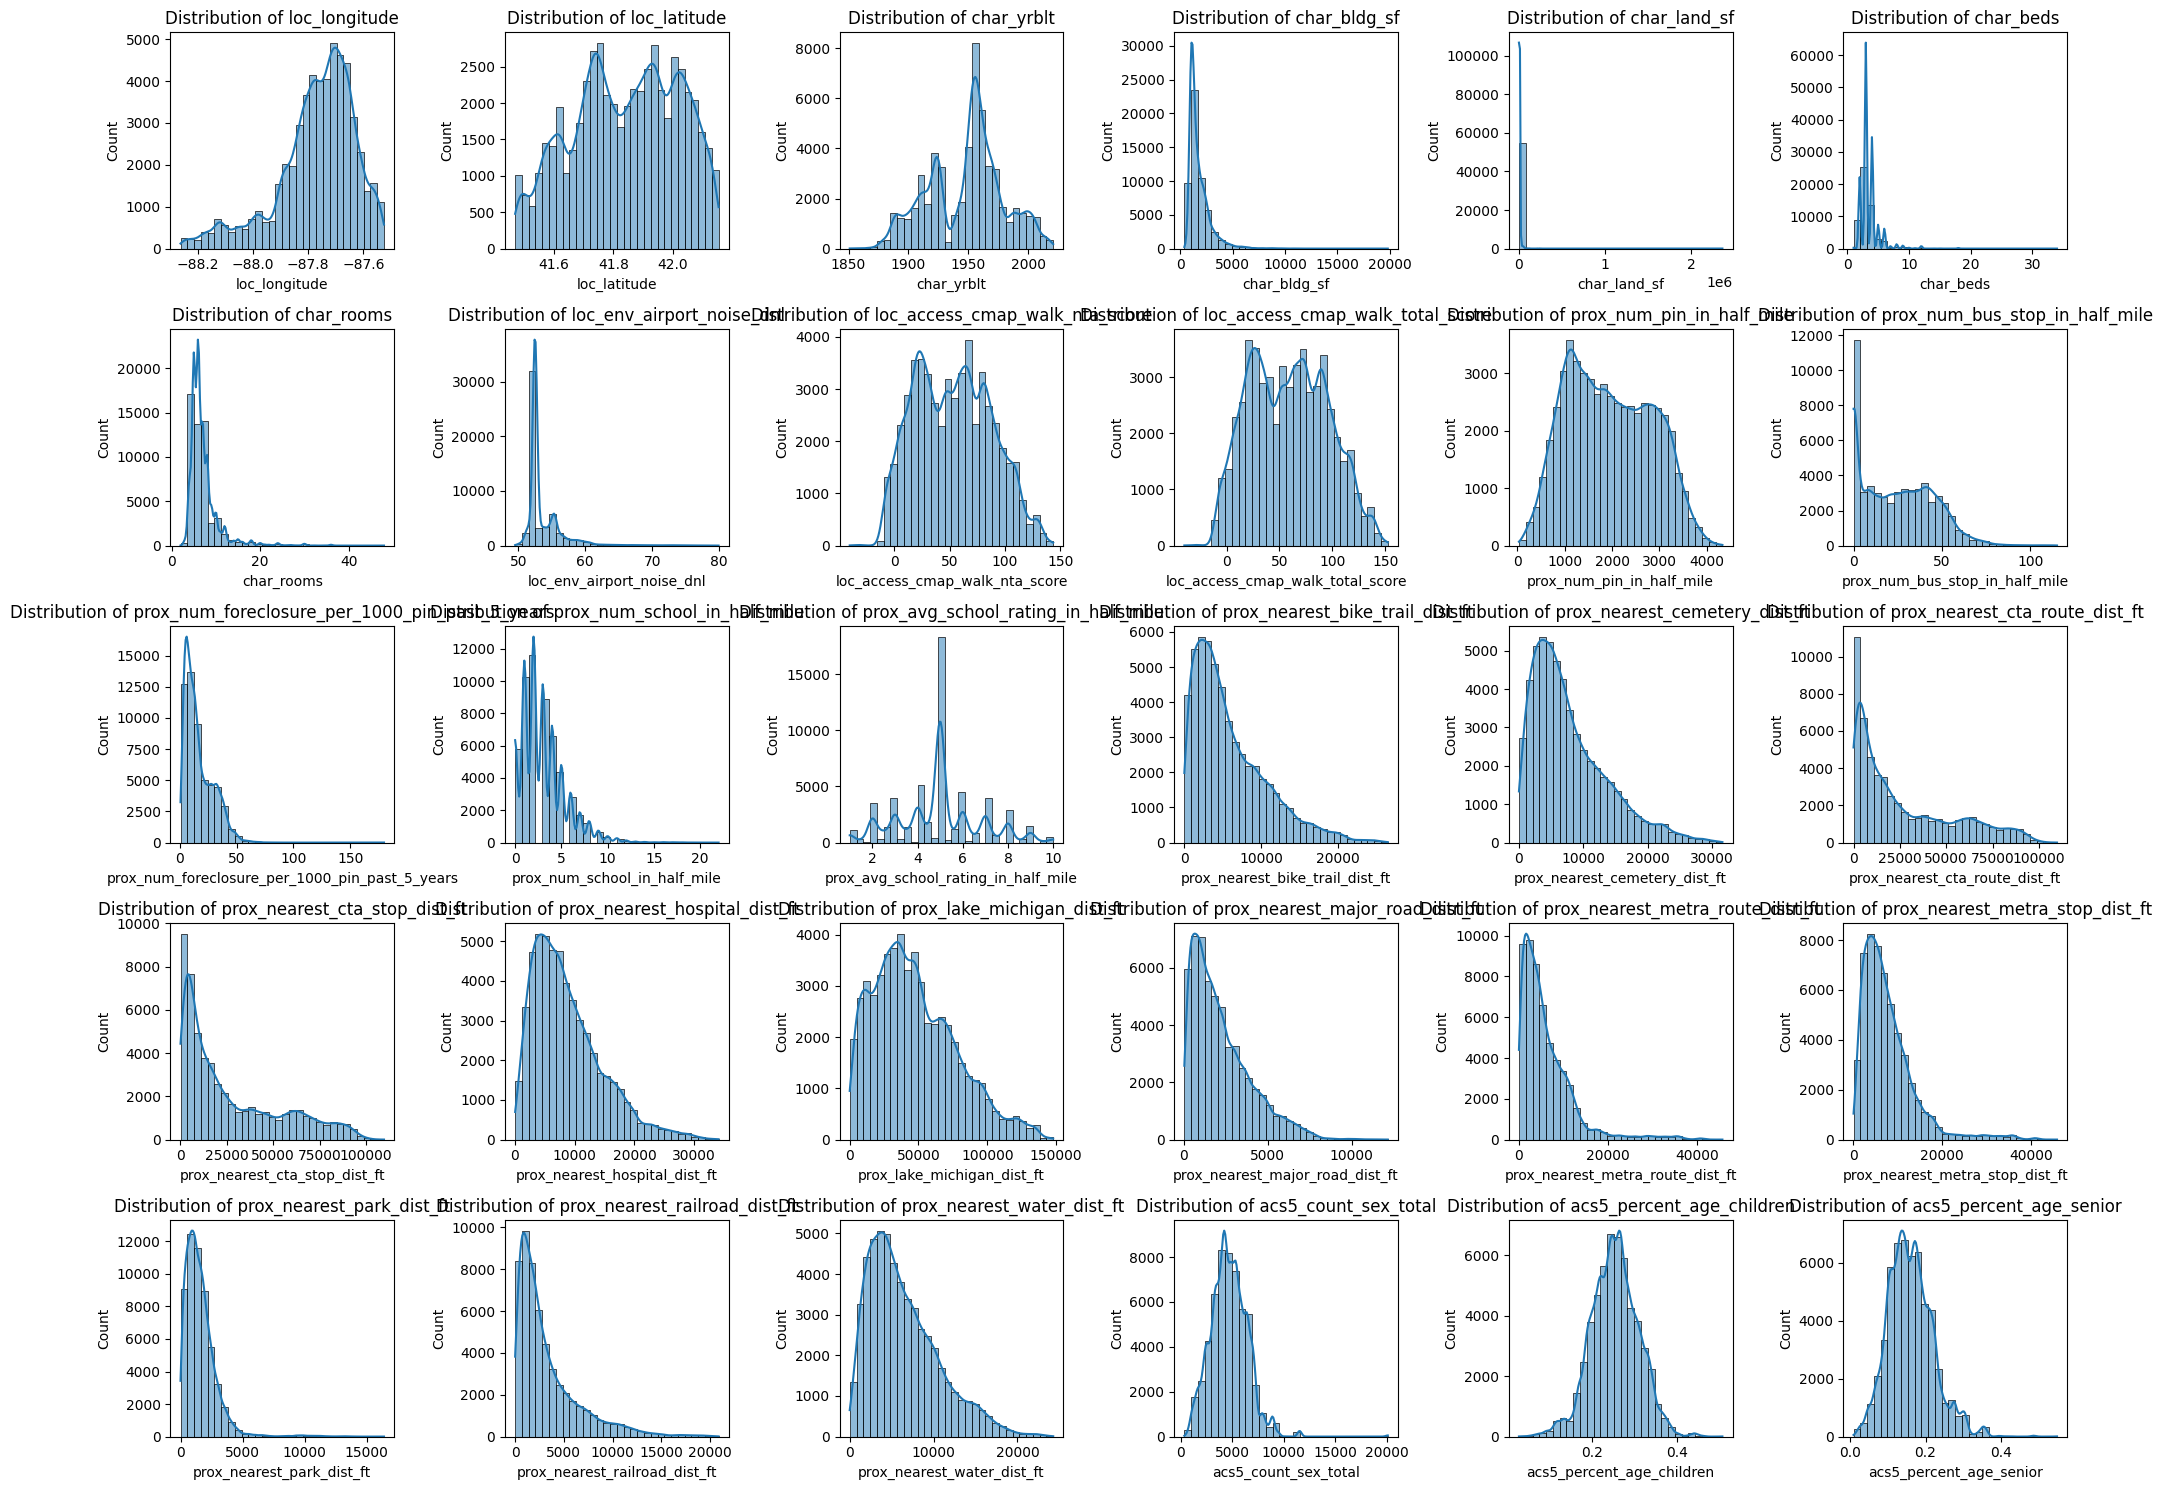

In [49]:
# histplot to make EDA
fig, axes = plt.subplots(nrows=5, ncols=6, figsize=(20, 15))
axes = axes.flatten()

for i, col in enumerate(pkg_continuous[:30]):
    sns.histplot(train_data[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')

plt.tight_layout()
save_figure("08_continuous_feature_distributions_part1")
plt.show()

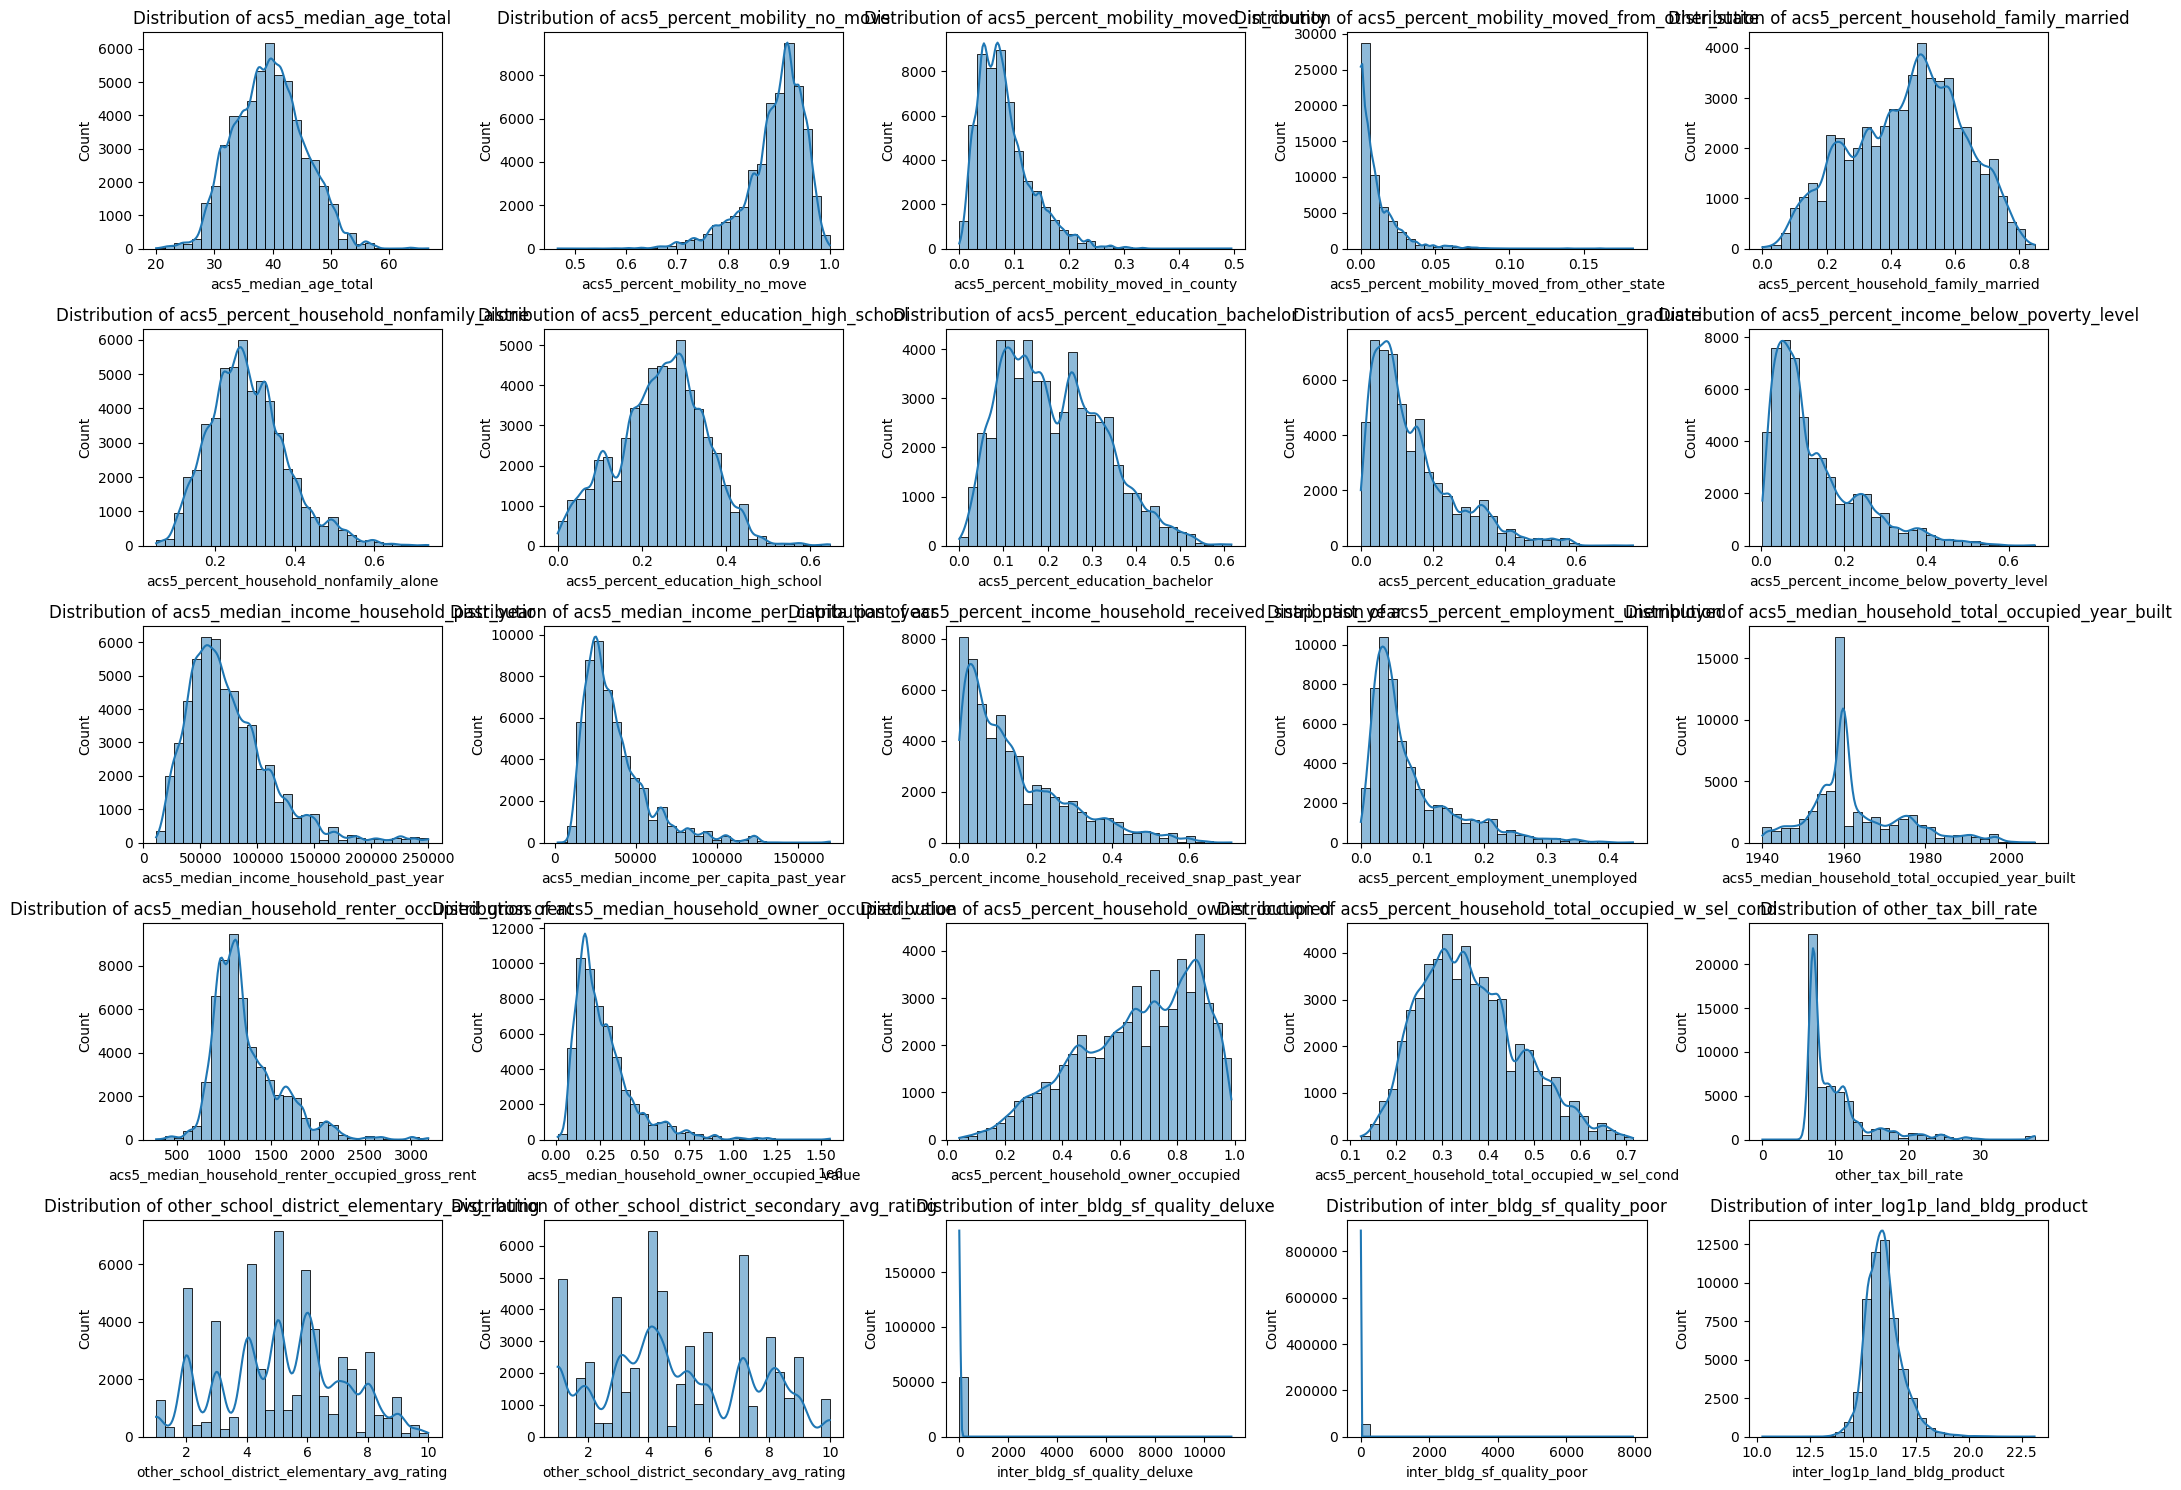

In [50]:
remaining_continuous_features = pkg_continuous[30:]
columns_per_row = 5
row_count = max(1, int(np.ceil(len(remaining_continuous_features) / columns_per_row)))
fig, axes = plt.subplots(
    nrows=row_count,
    ncols=columns_per_row,
    figsize=(20, 3 * row_count),
)
axes = np.atleast_1d(axes).flatten()

for axis, column in zip(axes, remaining_continuous_features):
    sns.histplot(train_data[column], bins=30, kde=True, ax=axis)
    axis.set_title(f"Distribution of {column}")

for unused_axis in axes[len(remaining_continuous_features):]:
    unused_axis.set_visible(False)

plt.tight_layout()
save_figure("09_continuous_feature_distributions_part2")
plt.show()


We identify outliers in continuous data by flagging features with extreme values ​​that deviate significantly from the 1st and 99th percentiles, and then apply truncation to these values. However, this process is not applied to certain specific types of features, such as those representing time.

In [51]:
def generate_continuous_outlier_report(df, lower_q=0.01, upper_q=0.99):
    """
    Generate a summary report DataFrame for checking outliers in continuous features
    """
    report_data = []

    for col in df.columns:
        series = df[col].dropna()
        if len(series) == 0:
            continue

        lower_bound = series.quantile(lower_q)
        upper_bound = series.quantile(upper_q)

        below_values = series[series < lower_bound]
        above_values = series[series > upper_bound]

        report_data.append({
            'Feature': col,
            'Valid_Count': len(series),
            'Min_Value': round(series.min(), 4),
            'Max_Value': round(series.max(), 4),
            '1%_Lower_Bound': round(lower_bound, 4),
            '99%_Upper_Bound': round(upper_bound, 4),
            'Count_Below_1%': len(below_values),
            'Count_Above_99%': len(above_values),
            'Total_Outliers': len(below_values) + len(above_values),
            'Outlier_Ratio(%)': round((len(below_values) + len(above_values)) / len(series) * 100, 2),
            # Extract the top 3 most extreme values as reference
            'Top3_Min_Samples': np.sort(below_values)[:3].tolist(),
            'Top3_Max_Samples': np.sort(above_values)[::-1][:3].tolist()
        })

    return pd.DataFrame(report_data)

# === Usage example ===
report_df = generate_continuous_outlier_report(df_continuous)
display(report_df)
report_df.to_csv("continuous_outlier_report.csv", index=False) # Export for inspection

,Feature,Valid_Count,Min_Value,Max_Value,1%_Lower_Bound,99%_Upper_Bound,Count_Below_1%,Count_Above_99%,Total_Outliers,Outlier_Ratio(%),Top3_Min_Samples,Top3_Max_Samples
0,loc_longitude,54853,-88.2635,-8.752490e+01,-88.2075,-87.5368,549,549,1098,2.00,"[-88.26350610075501, -88.26333689363103, -88.2631566263013]","[-87.52491910282046, -87.52491910282046, -87.52492250946459]"
1,loc_latitude,54853,41.4699,4.215400e+01,41.4822,42.1407,549,549,1098,2.00,"[41.46992834851476, 41.46997659345463, 41.46998370028336]","[42.15397901114071, 42.15395661600107, 42.15394950860588]"
2,char_yrblt,54853,1851.0000,2.021000e+03,1883.0000,2014.0000,493,433,926,1.69,"[1851.0, 1851.0, 1852.0]","[2021.0, 2021.0, 2021.0]"
3,char_bldg_sf,54853,400.0000,1.980000e+04,720.0000,5880.0000,516,543,1059,1.93,"[400.0, 400.0, 400.0]","[19800.0, 19575.0, 15300.0]"
4,char_land_sf,54853,9.0000,2.363130e+06,1097.0000,38826.8800,548,549,1097,2.00,"[9.0, 358.0, 488.0]","[2363130.0, 2363130.0, 653400.0]"
5,char_beds,54853,1.0000,3.400000e+01,2.0000,10.0000,96,465,561,1.02,"[1.0, 1.0, 1.0]","[34.0, 34.0, 22.0]"
6,char_rooms,54853,2.0000,4.800000e+01,4.0000,22.0000,338,499,837,1.53,"[2.0, 2.0, 3.0]","[48.0, 48.0, 46.0]"
7,loc_env_airport_noise_dnl,54853,49.5349,7.989810e+01,50.8998,67.2733,549,549,1098,2.00,"[49.53487396240234, 49.53657531738281, 49.53836441040039]","[79.89813232421875, 79.78201293945312, 79.42108154296875]"
8,loc_access_cmap_walk_nta_score,54853,-40.0000,1.435000e+02,-7.0000,130.0000,536,442,978,1.78,"[-40.0, -40.0, -40.0]","[143.5, 143.5, 143.5]"
9,loc_access_cmap_walk_total_score,54853,-40.0000,1.525000e+02,-7.0000,138.5000,484,414,898,1.64,"[-40.0, -40.0, -38.0]","[152.5, 152.5, 152.5]"


In [52]:
# Verify whether the negative values of loc_access_cmap_walk_nta_score are mostly extreme cases at -40,
# which would indicate unreasonable missing values
print("Number of samples with value < -7:", (train_data['loc_access_cmap_walk_nta_score'] < -7).sum())
print("Number of samples with value == -40:", (train_data['loc_access_cmap_walk_nta_score'] == -40).sum())
print("Number of samples with value < 0 but > -40:", ((train_data['loc_access_cmap_walk_nta_score'] < 0) & (train_data['loc_access_cmap_walk_nta_score'] > -40.0)).sum())

Number of samples with value < -7: 536
Number of samples with value == -40: 3
Number of samples with value < 0 but > -40: 2183


In [53]:
# Verify whether the negative values of other_tax_bill_rate are mostly extreme cases at -40,
# which would indicate unreasonable missing values
print("Number of samples with value < 6:", (train_data['other_tax_bill_rate'] < 6).sum())
print("Number of samples with value == 0:", (train_data['other_tax_bill_rate'] == 0).sum())
print("Number of samples with value < 6 but > 0:", ((train_data['other_tax_bill_rate'] < 6) & (train_data['other_tax_bill_rate'] > 0)).sum())

Number of samples with value < 6: 4
Number of samples with value == 0: 3
Number of samples with value < 6 but > 0: 1


By analyzing the histograms and extreme values ​​mentioned above—while also taking the specific context into account—we have set up an additional CSV file. This file outlines the feature engineering methods to be applied to various features, ensuring a consistent transformation process for all continuous-type feature values.

In [54]:
from sklearn.preprocessing import PowerTransformer, StandardScaler

rule_df = pd.read_csv("data/featureengineer.csv")


def get_cols(column_name):
    """Return unique non-empty feature names from one rule column."""
    if column_name not in rule_df.columns:
        return []
    return (
        rule_df[column_name]
        .dropna()
        .astype(str)
        .str.strip()
        .loc[lambda values: values.ne("")]
        .unique()
        .tolist()
    )


cols_yeojohnson = get_cols("yeojohnson")
cols_scaler = get_cols("standardscaler")
cols_clipping = get_cols("clipping")
cols_binning = get_cols("binning")
cols_remain = get_cols("remain")

# Preserve a deterministic feature order while applying the established
# clipping -> Yeo-Johnson -> scaling sequence.
continuous_cols = list(
    dict.fromkeys(cols_yeojohnson + cols_scaler + cols_clipping)
)
continuous_cols = [
    column for column in continuous_cols if column in train_data.columns
]

print(f"Continuous transformation features: {len(continuous_cols)}")
print(f"Binning features: {len(cols_binning)}")
print(f"Unchanged features: {len(cols_remain)}")

# Fit clipping limits on the training period only.
clip_bounds = {
    column: (
        train_data[column].quantile(0.01),
        train_data[column].quantile(0.99),
    )
    for column in continuous_cols
}


def clip_with_training_bounds(frame):
    clipped = frame[continuous_cols].copy()
    for column, (lower, upper) in clip_bounds.items():
        clipped[column] = clipped[column].clip(lower, upper)
    return clipped


train_clipped = clip_with_training_bounds(train_data)

# PowerTransformer can numerically collapse a non-constant feature when the
# fitted lambda is extreme. Fit on training data, detect that failure on the
# transformed training values, and fall back to clipped physical values before
# applying the training-fitted StandardScaler.
pt = PowerTransformer(method="yeo-johnson", standardize=False)
train_power_array = pt.fit_transform(train_clipped)
train_power = pd.DataFrame(
    train_power_array,
    index=train_clipped.index,
    columns=continuous_cols,
)
def yeo_johnson_collapsed(before, after):
    """Yeo-Johnson is strictly increasing, so a working transform keeps the distinct
    values and their order. A numerical collapse leaves rounding noise instead,
    which can still contain more than one distinct value."""
    after_values = after.to_numpy(dtype=float)
    if not np.isfinite(after_values).all():
        return True
    if after.nunique(dropna=True) < 0.99 * before.nunique(dropna=True):
        return True
    rank_correlation = before.corr(after, method="spearman")
    return not np.isfinite(rank_correlation) or rank_correlation < 0.999


unstable_power_columns = [
    column
    for column in continuous_cols
    if train_clipped[column].nunique(dropna=True) > 1
    and yeo_johnson_collapsed(train_clipped[column], train_power[column])
]
train_transform_input = train_power.copy()
train_transform_input.loc[:, unstable_power_columns] = train_clipped[
    unstable_power_columns
].to_numpy()

scaler = StandardScaler()
scaler.fit(train_transform_input)

for frame in (train_data, val_data, test_data):
    frame_clipped = clip_with_training_bounds(frame)
    frame_power = pd.DataFrame(
        pt.transform(frame_clipped),
        index=frame.index,
        columns=continuous_cols,
    )
    frame_power.loc[:, unstable_power_columns] = frame_clipped[
        unstable_power_columns
    ].to_numpy()
    frame_scaled = pd.DataFrame(
        scaler.transform(frame_power),
        index=frame.index,
        columns=continuous_cols,
    )
    frame.loc[:, continuous_cols] = frame_scaled

for column in continuous_cols:
    if train_clipped[column].nunique(dropna=True) > 1:
        assert not yeo_johnson_collapsed(train_clipped[column], train_data[column]), (
            f"Information loss after continuous transformation: {column}"
        )

print("Continuous transformations completed with training-only fitted parameters.")
print(
    "Yeo-Johnson stability fallbacks: "
    + (", ".join(unstable_power_columns) if unstable_power_columns else "None")
)


Continuous transformation features: 44
Binning features: 6
Unchanged features: 2
Continuous transformations completed with training-only fitted parameters.
Yeo-Johnson stability fallbacks: loc_longitude, loc_env_airport_noise_dnl


In [55]:
print("Processing binned features with training-only category schemas...")


def apply_binning(frame, binning_list):
    transformed = frame.copy()

    if "char_beds" in binning_list and "char_beds" in transformed.columns:
        transformed["char_beds_bin"] = (
            transformed["char_beds"].clip(lower=1, upper=5).fillna(1).astype(int)
        )
    if "char_rooms" in binning_list and "char_rooms" in transformed.columns:
        transformed["char_rooms_bin"] = (
            transformed["char_rooms"].clip(lower=0, upper=10).fillna(0).astype(int)
        )
    if (
        "prox_num_school_in_half_mile" in binning_list
        and "prox_num_school_in_half_mile" in transformed.columns
    ):
        transformed["prox_num_school_bin"] = (
            transformed["prox_num_school_in_half_mile"]
            .clip(lower=0, upper=10)
            .fillna(0)
            .astype(int)
        )
    if (
        "prox_avg_school_rating_in_half_mile" in binning_list
        and "prox_avg_school_rating_in_half_mile" in transformed.columns
    ):
        transformed["prox_avg_school_rating_bin"] = (
            transformed["prox_avg_school_rating_in_half_mile"]
            .round()
            .clip(lower=1, upper=10)
            .fillna(1)
            .astype(int)
        )
    if (
        "other_school_district_elementary_avg_rating" in binning_list
        and "other_school_district_elementary_avg_rating" in transformed.columns
    ):
        transformed["other_elementary_rating_bin"] = (
            transformed["other_school_district_elementary_avg_rating"]
            .round()
            .clip(lower=1, upper=10)
            .fillna(1)
            .astype(int)
        )
    if (
        "other_school_district_secondary_avg_rating" in binning_list
        and "other_school_district_secondary_avg_rating" in transformed.columns
    ):
        transformed["other_secondary_rating_bin"] = (
            transformed["other_school_district_secondary_avg_rating"]
            .round()
            .clip(lower=1, upper=10)
            .fillna(1)
            .astype(int)
        )
    return transformed


train_data = apply_binning(train_data, cols_binning)
val_data = apply_binning(val_data, cols_binning)
test_data = apply_binning(test_data, cols_binning)

bin_column_candidates = [
    "char_beds_bin",
    "char_rooms_bin",
    "prox_num_school_bin",
    "prox_avg_school_rating_bin",
    "other_elementary_rating_bin",
    "other_secondary_rating_bin",
]
bin_column_names = [
    column for column in bin_column_candidates if column in train_data.columns
]


def one_hot_binned_from_training(
    training_frame,
    validation_frame,
    test_frame,
    column,
):
    training_categories = sorted(
        training_frame[column].dropna().unique().tolist()
    )

    def encode(frame):
        categorical = pd.Categorical(
            frame[column],
            categories=training_categories,
        )
        encoded = pd.get_dummies(
            categorical,
            prefix=column,
            drop_first=True,
            dtype=int,
        )
        encoded.index = frame.index
        return encoded

    encoded_training = encode(training_frame)
    encoded_validation = encode(validation_frame).reindex(
        columns=encoded_training.columns,
        fill_value=0,
    )
    encoded_test = encode(test_frame).reindex(
        columns=encoded_training.columns,
        fill_value=0,
    )
    return (
        pd.concat(
            [training_frame.drop(columns=column), encoded_training],
            axis=1,
        ),
        pd.concat(
            [validation_frame.drop(columns=column), encoded_validation],
            axis=1,
        ),
        pd.concat(
            [test_frame.drop(columns=column), encoded_test],
            axis=1,
        ),
    )


for bin_column in bin_column_names:
    train_data, val_data, test_data = one_hot_binned_from_training(
        train_data,
        val_data,
        test_data,
        bin_column,
    )

# Remove the original variables that the established binning rules replace.
original_binning_columns = [
    column for column in cols_binning if column in train_data.columns
]
for frame in (train_data, val_data, test_data):
    frame.drop(
        columns=original_binning_columns,
        inplace=True,
        errors="ignore",
    )

assert train_data.columns.tolist() == val_data.columns.tolist() == test_data.columns.tolist()
print(f"Training-fitted binned indicators: {len(bin_column_names)} source bins.")
print(
    f"Shapes after binning: Train={train_data.shape}, "
    f"Validation={val_data.shape}, Test={test_data.shape}"
)


Processing binned features with training-only category schemas...
Training-fitted binned indicators: 6 source bins.
Shapes after binning: Train=(54853, 169), Validation=(18132, 169), Test=(36322, 169)


Perform EDA on discrete-type feature sets using bar charts and box plots.

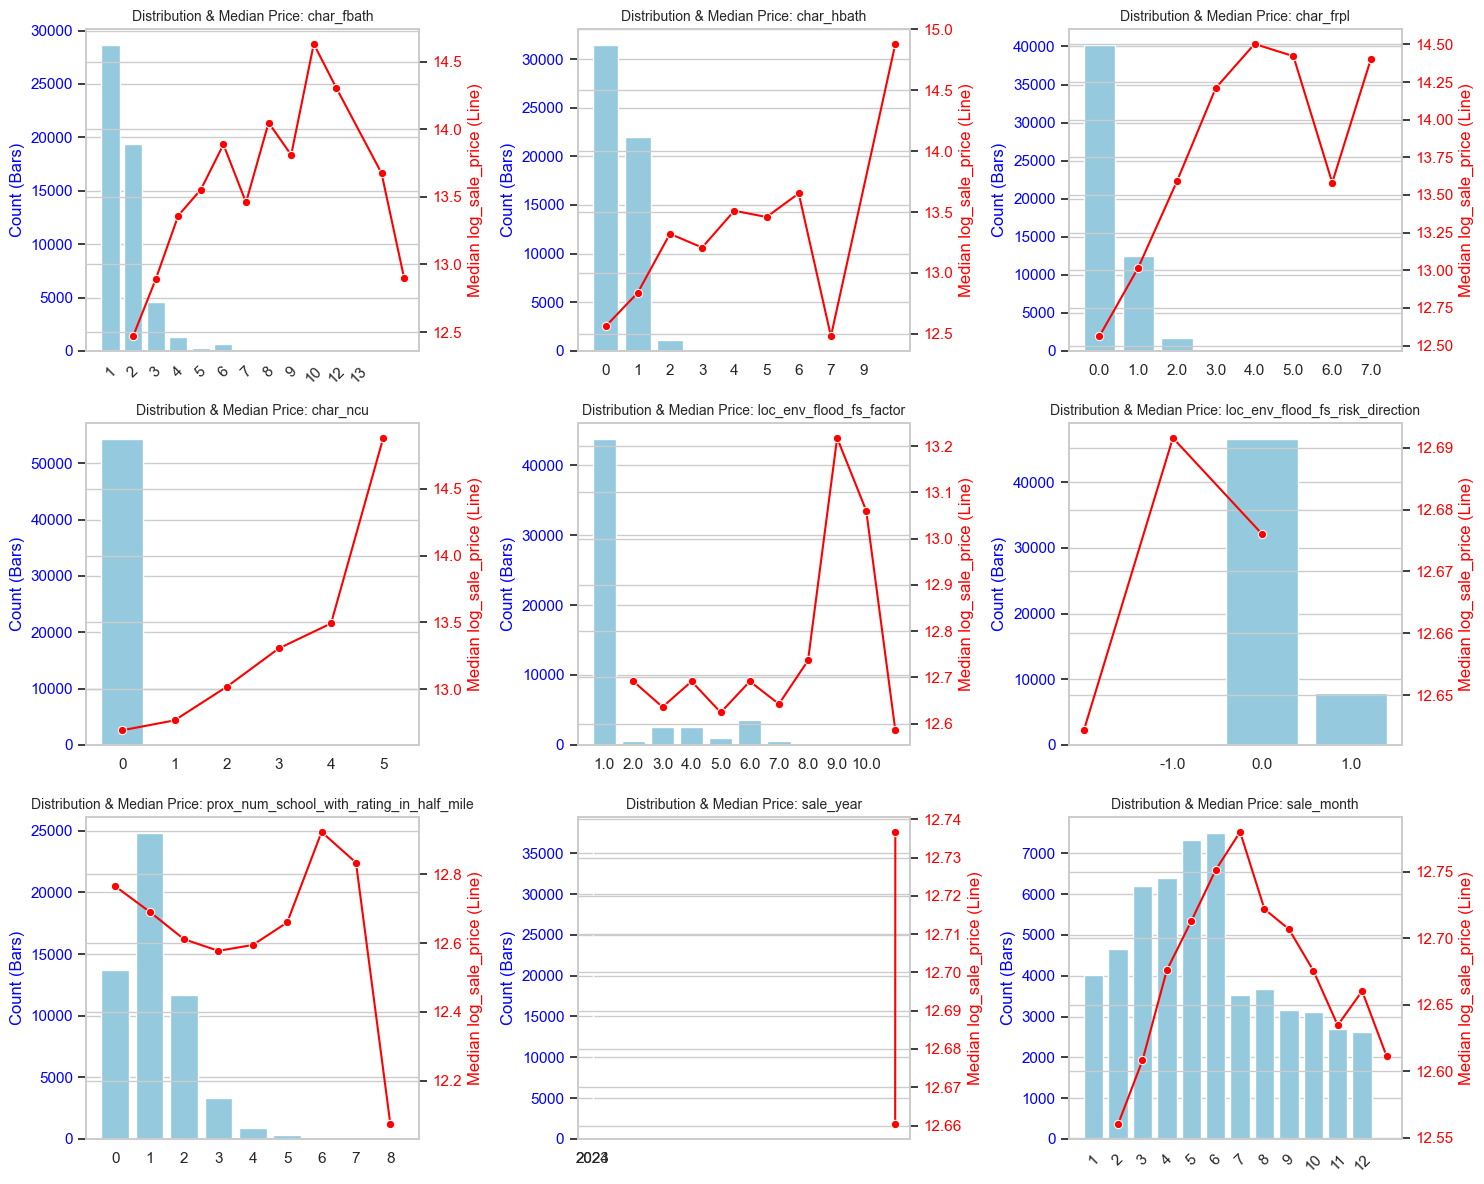

In [56]:
sns.set_theme(style="whitegrid")

if len(pkg_discrete) > 0:
    # Compute the number of rows and columns needed (at most 3 plots per row)
    n_cols = 3
    n_rows = math.ceil(len(pkg_discrete) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
    axes = axes.flatten()

    for i, col in enumerate(pkg_discrete):
        # 1. Draw the frequency bar chart (blue indicates frequency)
        ax1 = axes[i]
        sns.countplot(data=train_data, x=col, ax=ax1, color='skyblue')

        # 2. Place the dual-axis plot in the same subplot (use twinx to share the X axis)
        ax2 = ax1.twinx()
        # Compute the median price for each value of the feature
        median_price = train_data.groupby(col)['log_sale_price'].median().reset_index()
        # Draw the line chart (red dots indicate the median price trend)
        sns.lineplot(data=median_price, x=col, y='log_sale_price',
                     ax=ax2, color='red', marker='o', sort=False)

        # 3. Set the title and axes
        ax1.set_title(f'Distribution & Median Price: {col}', fontsize=10)
        ax1.set_xlabel('')
        ax1.set_ylabel('Count (Bars)', color='blue')
        ax2.set_ylabel('Median log_sale_price (Line)', color='red')
        ax1.tick_params(axis='y', labelcolor='blue')
        ax2.tick_params(axis='y', labelcolor='red')

        # Optimize the X-axis ticks: if there are too many values, show only some of them to prevent overlap
        if len(train_data[col].unique()) > 10:
            for label in ax1.get_xticklabels():
                label.set_rotation(45)

    # Hide any extra empty subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    save_figure("10_discrete_features_vs_log_price")
    plt.show()
else:
    print("There are currently no discrete features.")

Feature engineering for discrete feature

In [57]:
# char_fbath: clip extreme values, cap at 3
for df in [train_data, val_data, test_data]:
    if 'char_fbath' in df.columns:
        df['char_fbath'] = df['char_fbath'].clip(upper=3).astype('Int64')

# char_hbath: clip extreme values, cap at 2
for df in [train_data, val_data, test_data]:
    if 'char_hbath' in df.columns:
        df['char_hbath'] = df['char_hbath'].clip(upper=2).astype('Int64')

# char_ncu: clip extreme values, cap at 2
for df in [train_data, val_data, test_data]:
    if 'char_ncu' in df.columns:
        df['char_ncu'] = df['char_ncu'].clip(upper=2).astype('Int64')

# prox_num_school_with_rating_in_half_mile: clip extreme values, cap at 3
for df in [train_data, val_data, test_data]:
    if 'prox_num_school_with_rating_in_half_mile' in df.columns:
        df['prox_num_school_with_rating_in_half_mile'] = df['prox_num_school_with_rating_in_half_mile'].clip(upper=3).astype('Int64')

# ==========================================
# 2. Binarization — handle features where "0 dominates the vast majority"
# ==========================================

# char_frpl: convert to whether there is a fireplace (0 = no, 1 = yes)
for df in [train_data, val_data, test_data]:
    if 'char_frpl' in df.columns:
        df['char_frpl'] = (df['char_frpl'] > 0).astype('Int64')

# ==========================================
# 3. Flood-related features (keep as-is, only confirm type safety)
# ==========================================
# These two features are extremely skewed (almost all zeros) and need no changes; tree models can handle them directly
# Just ensure they are float or Int
for df in [train_data, val_data, test_data]:
    if 'loc_env_flood_fs_factor' in df.columns:
        df['loc_env_flood_fs_factor'] = pd.to_numeric(df['loc_env_flood_fs_factor'], errors='coerce').astype('float64')
    if 'loc_env_flood_fs_risk_direction' in df.columns:
        df['loc_env_flood_fs_risk_direction'] = pd.to_numeric(df['loc_env_flood_fs_risk_direction'], errors='coerce').astype('float64')

print("✅ pkg_discrete feature engineering transformations complete!")

✅ pkg_discrete feature engineering transformations complete!


Next, we examine the feature set of the boolean category using box plots.

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\4196266574.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_data, x=col, y='log_sale_price', ax=ax,
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\4196266574.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_data, x=col, y='log_sale_price', ax=ax,
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\4196266574.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_data, x=col, y='log_sale_price', ax=ax,
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\41962

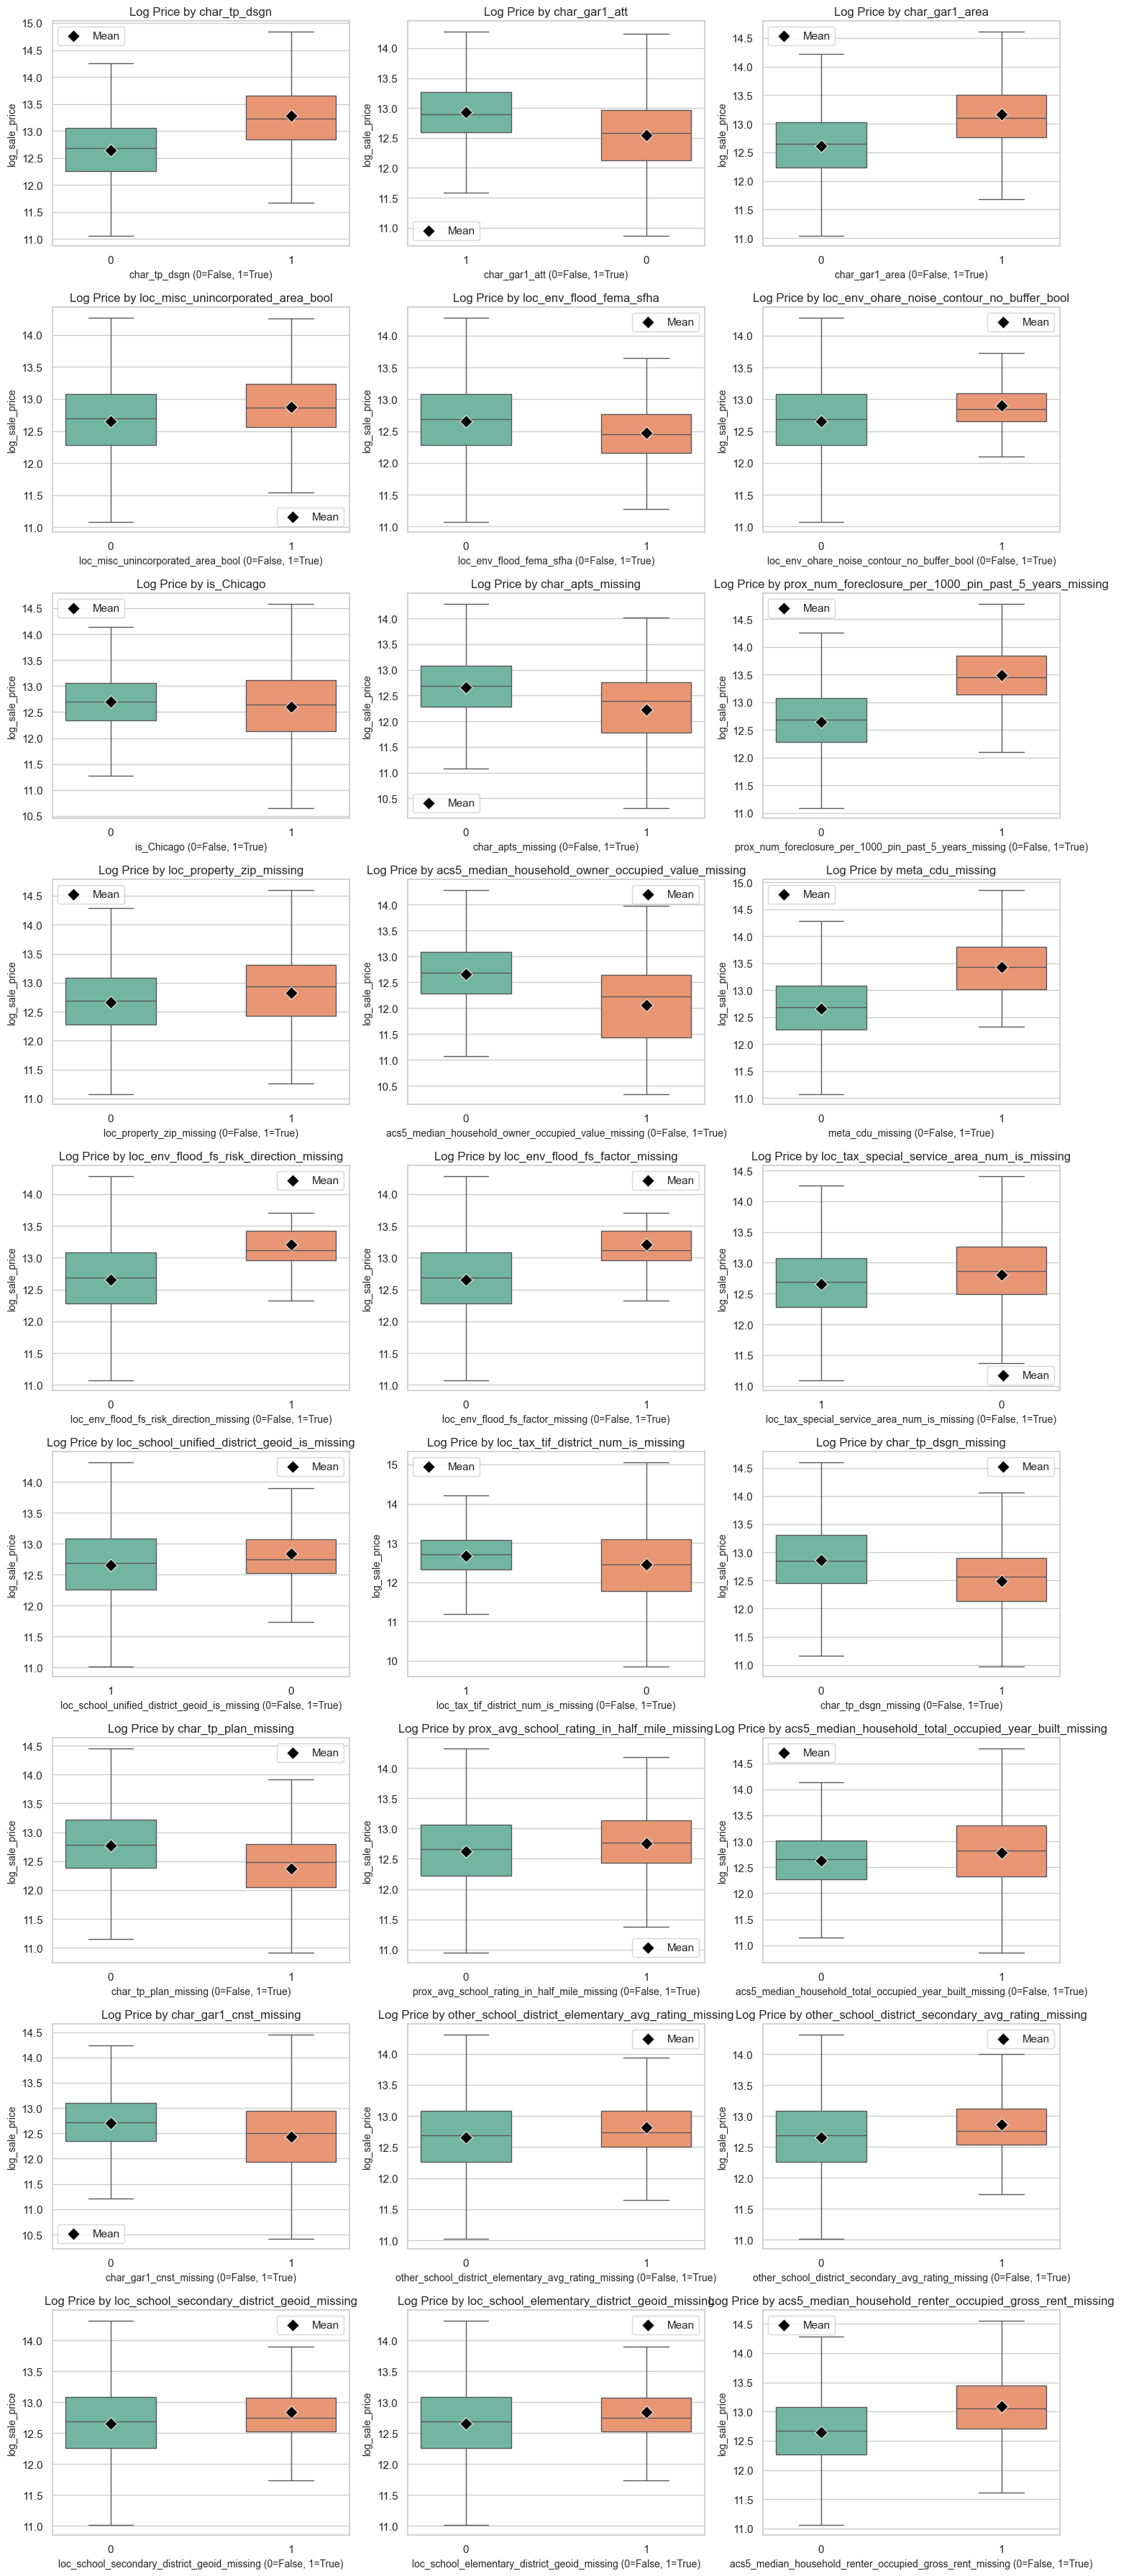

In [58]:
if len(pkg_boolean) > 0:
    n_cols = 3
    n_rows = math.ceil(len(pkg_boolean) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
    axes = axes.flatten()

    for i, col in enumerate(pkg_boolean):
        ax = axes[i]

        # 1. Temporarily convert the Boolean column back to string or object so Seaborn correctly treats it as a discrete category
        # If your column is of category type, Seaborn sometimes misbehaves
        plot_data = train_data[[col, 'log_sale_price']].copy()
        plot_data[col] = plot_data[col].astype(str)

        # 2. Draw the box plot
        sns.boxplot(data=plot_data, x=col, y='log_sale_price', ax=ax,
                    palette="Set2", width=0.5, showfliers=False) # showfliers=False hides extreme outliers to keep the plot clean

        # 3. Compute the means
        means = plot_data.groupby(col, observed=True)['log_sale_price'].mean().reset_index()

        # 4. Draw mean points (use scatter instead of pointplot to guarantee no errors)
        sns.scatterplot(data=means, x=col, y='log_sale_price', ax=ax,
                        color='black', marker='D', s=80, zorder=5, label='Mean')

        ax.set_title(f'Log Price by {col}', fontsize=12)
        ax.set_xlabel(f'{col} (0=False, 1=True)', fontsize=10)
        ax.set_ylabel('log_sale_price', fontsize=10)
        ax.legend(loc='best')

    # Hide any extra empty subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    save_figure("11_boolean_features_vs_log_price")
    plt.show()
else:
    print("There are currently no boolean features.")

Check again whether there are features belonging to other categories within the `category` package.

In [59]:
cat_dtypes = train_data[pkg_category].dtypes

# Filter out columns whose actual type is float
float_in_cat = cat_dtypes[cat_dtypes == 'float64'].index.tolist()
# Include other floating-point types such as float32
float_in_cat = cat_dtypes[cat_dtypes.apply(lambda x: pd.api.types.is_float_dtype(x))].index.tolist()

if float_in_cat:
    print(f"⚠️ Found {len(float_in_cat)} columns that are originally of float type but ended up in the Category bucket:")
    for col in float_in_cat:
        print(f"  - {col}: dtype={train_data[col].dtype}")
else:
    print("✅ No direct float dtype columns in pkg_category.")

✅ No direct float dtype columns in pkg_category.


Generating distribution and price-relationship plots for each feature...


C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


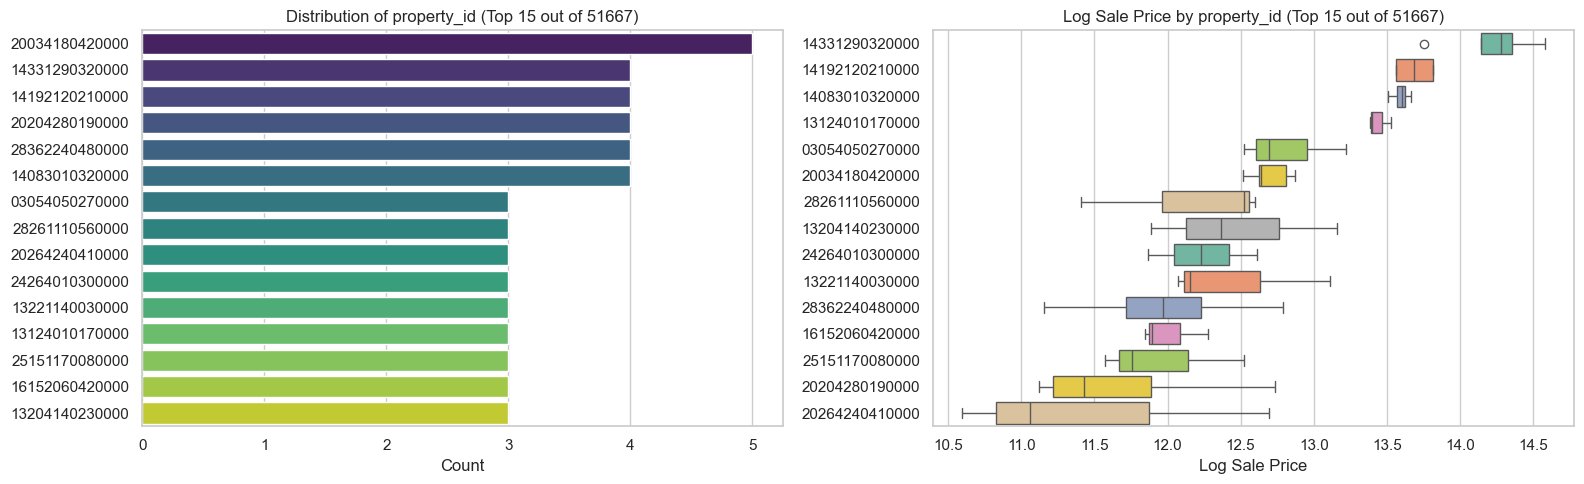

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


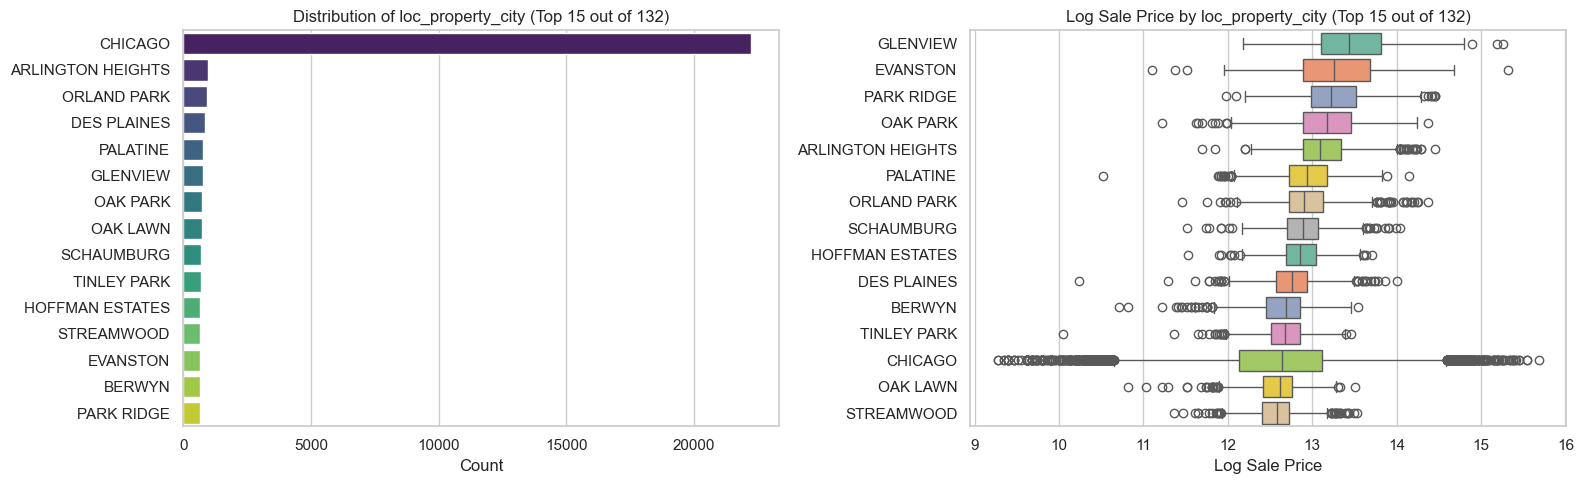

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


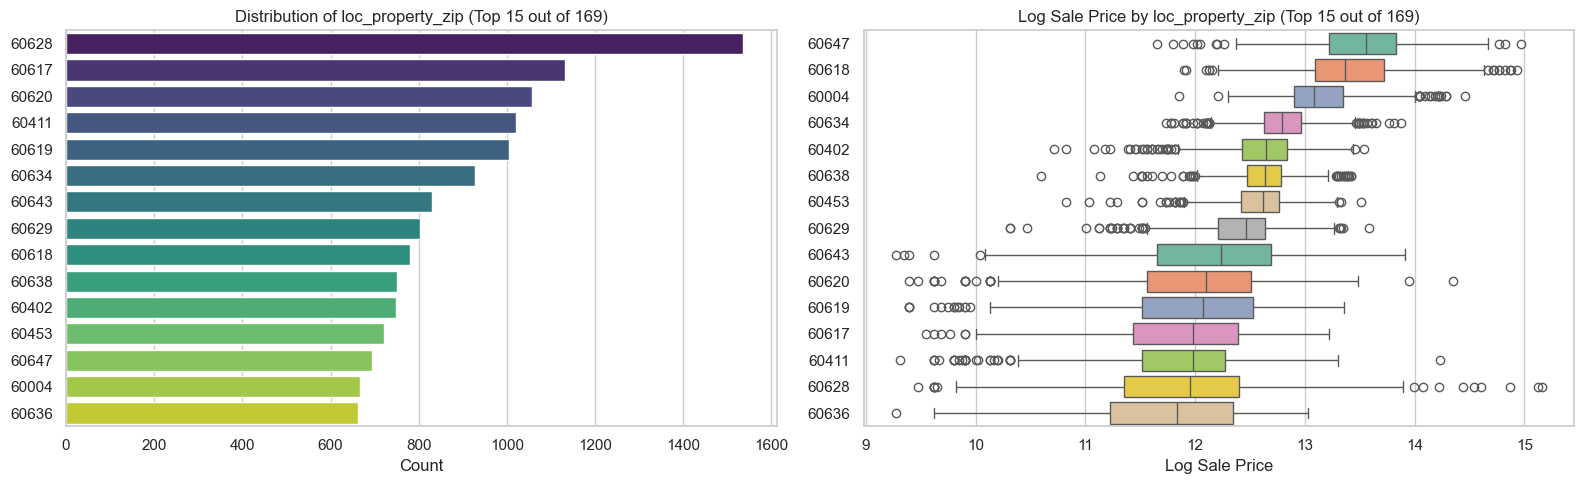

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


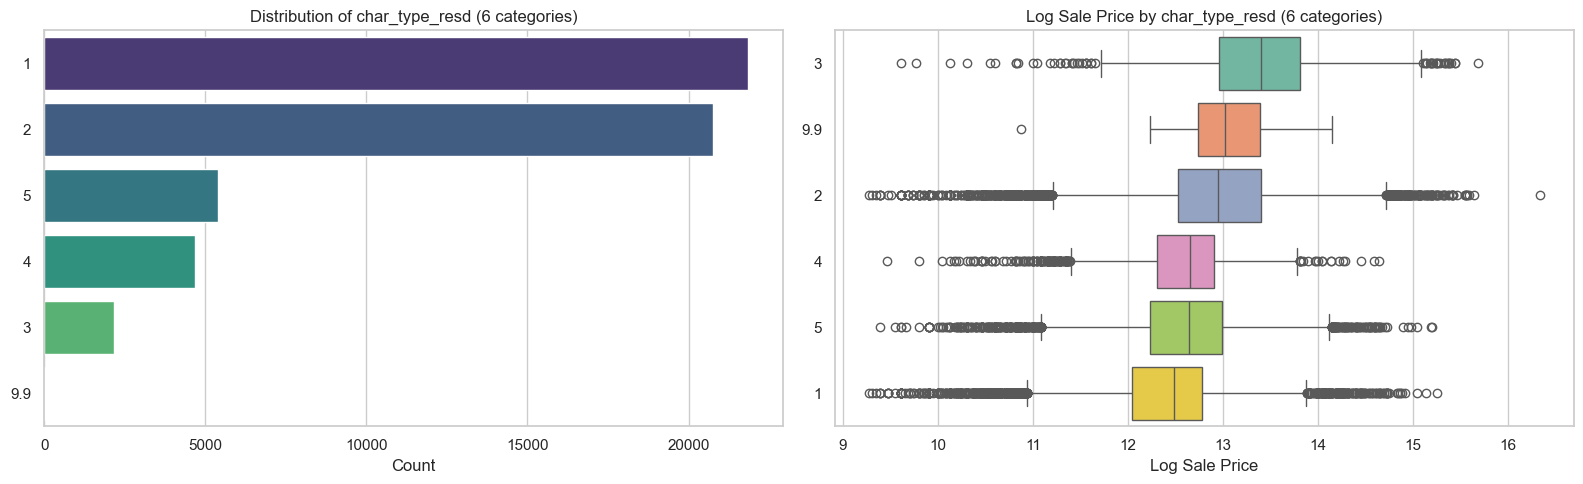

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


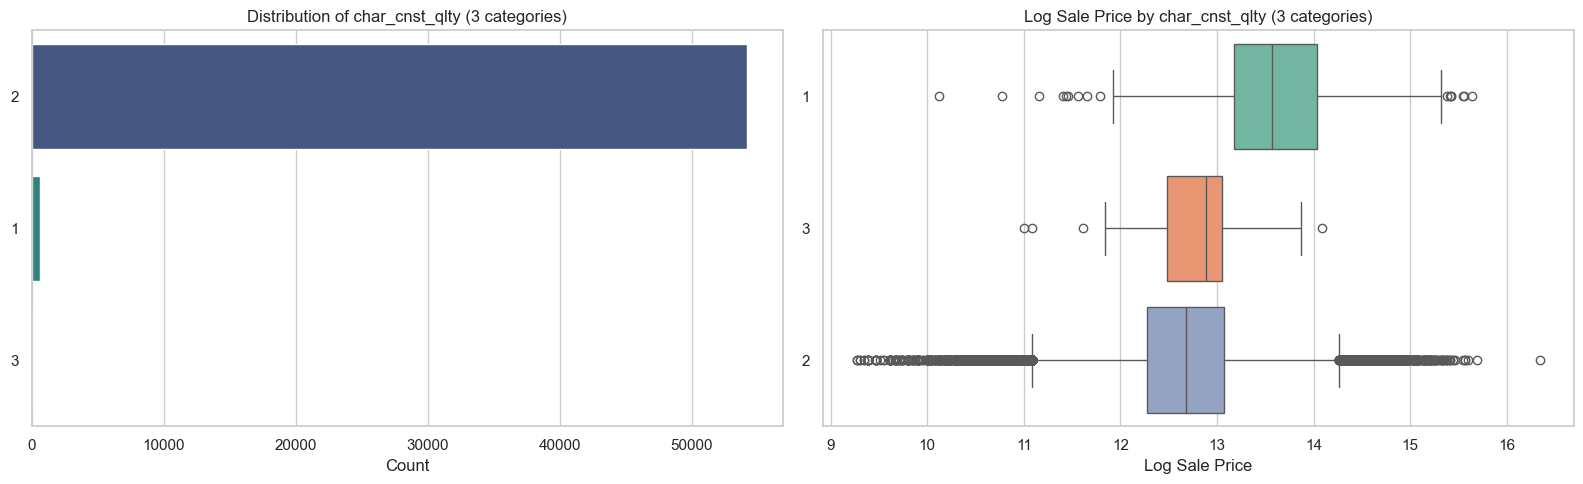

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


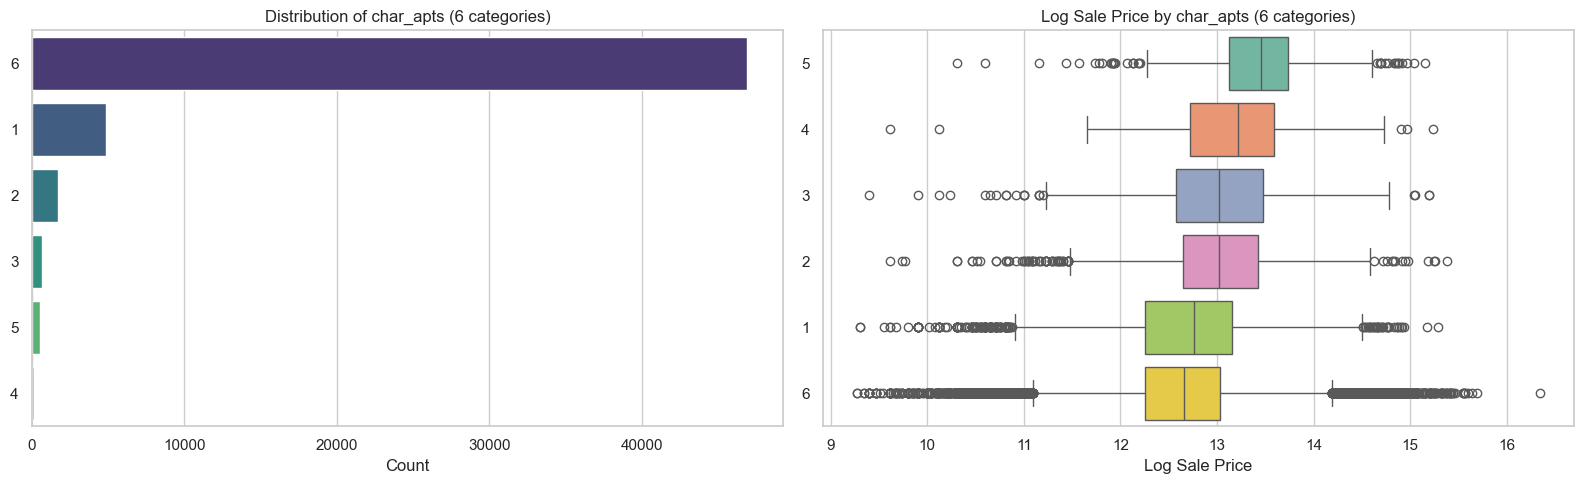

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


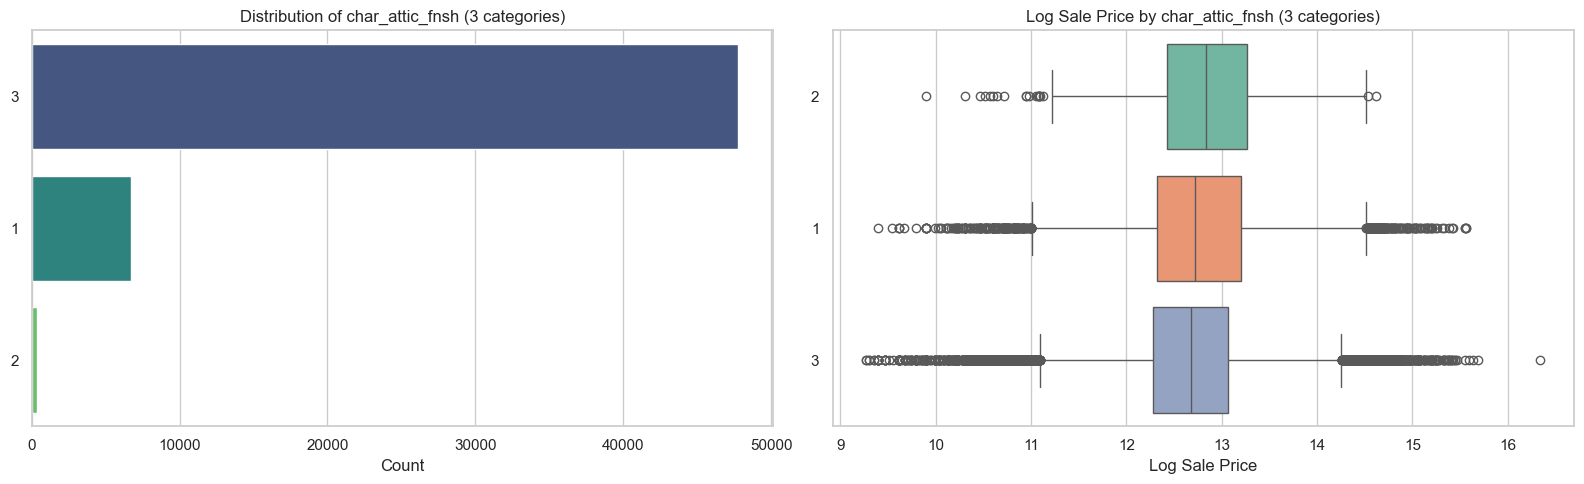

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


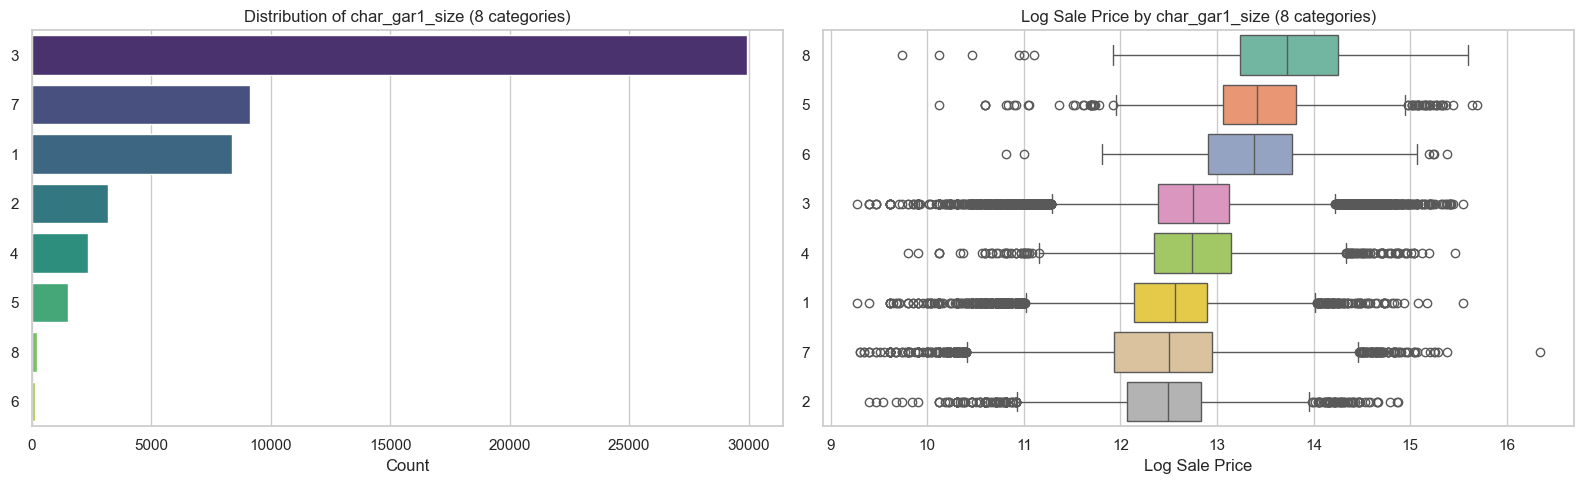

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


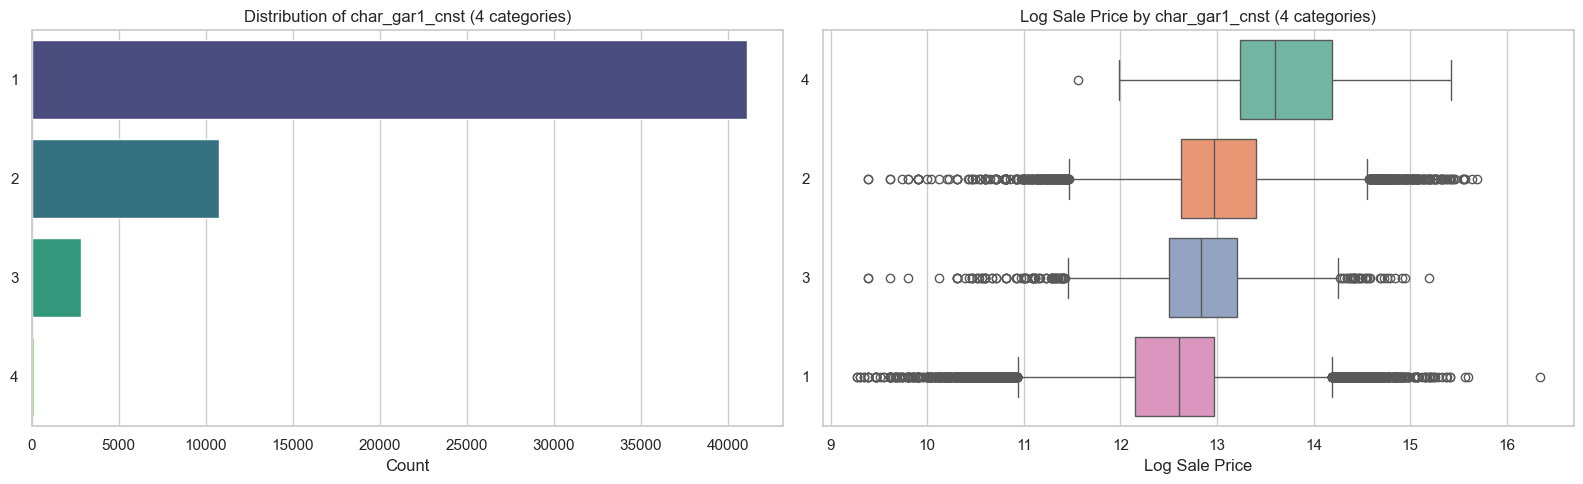

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


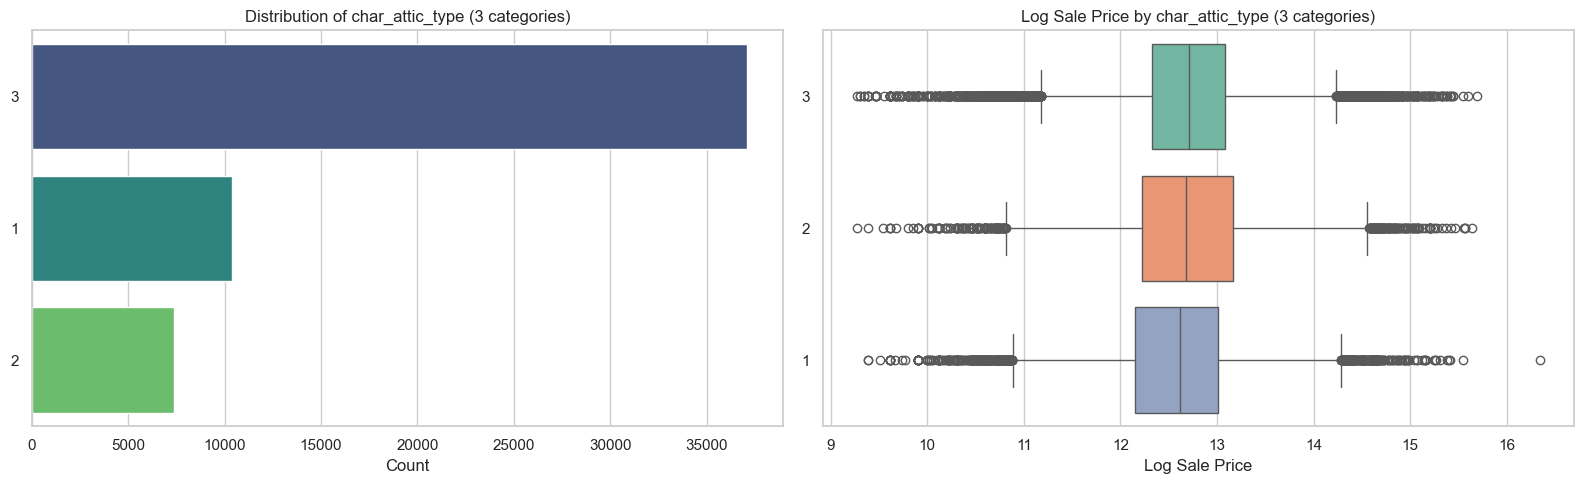

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


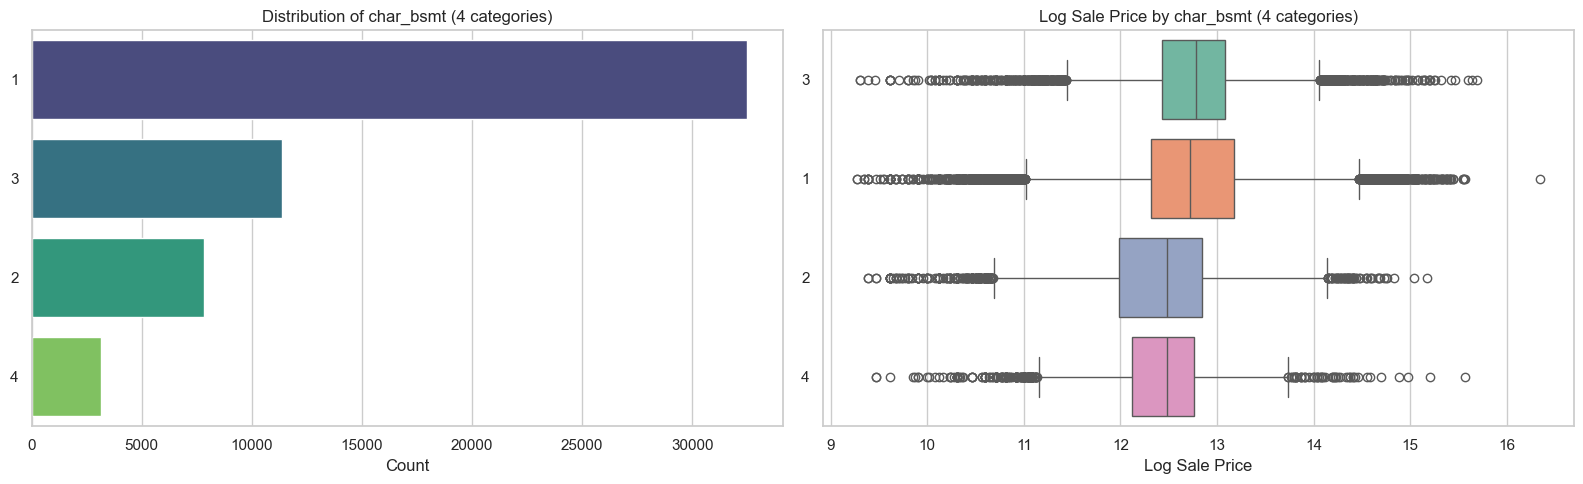

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


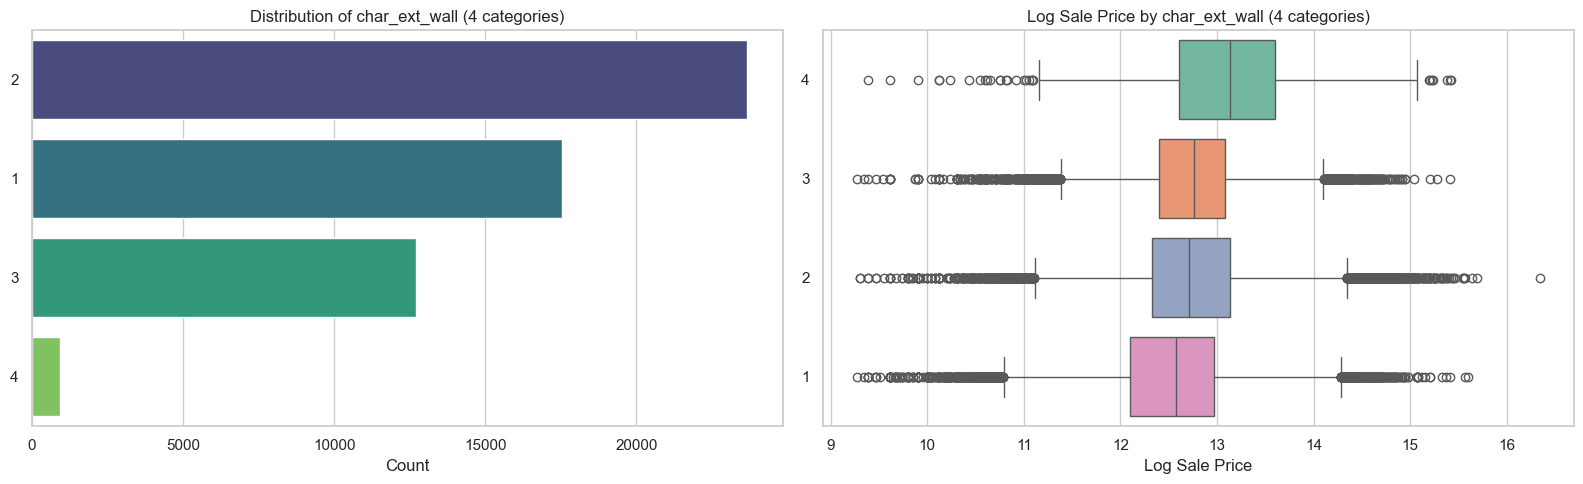

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


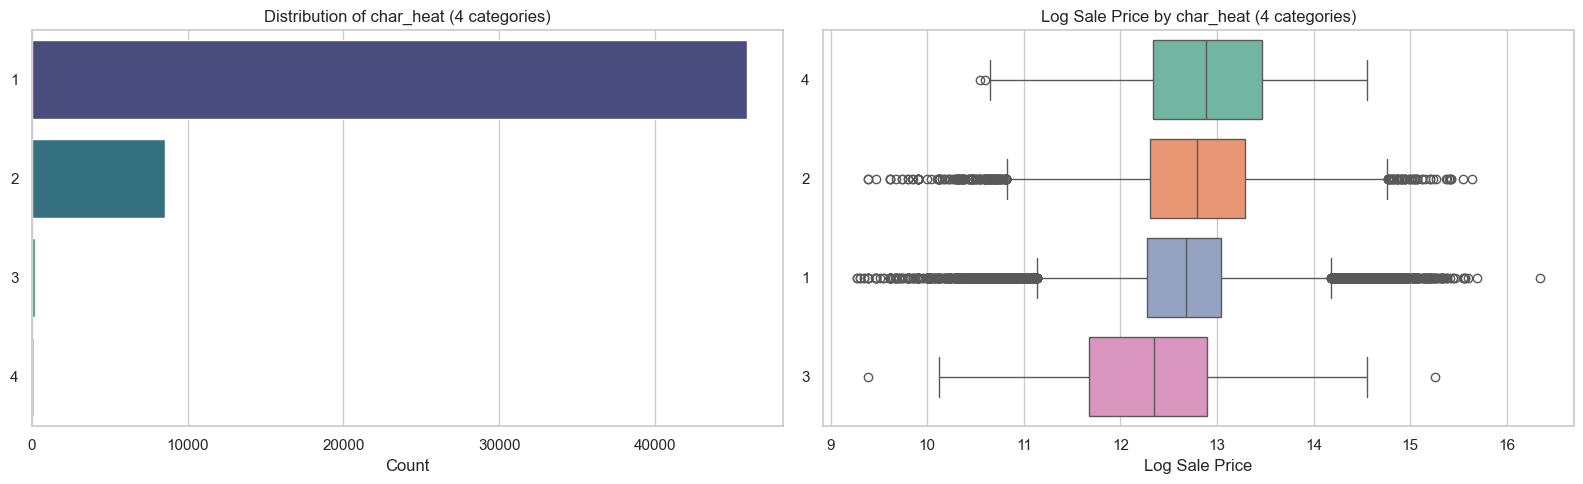

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


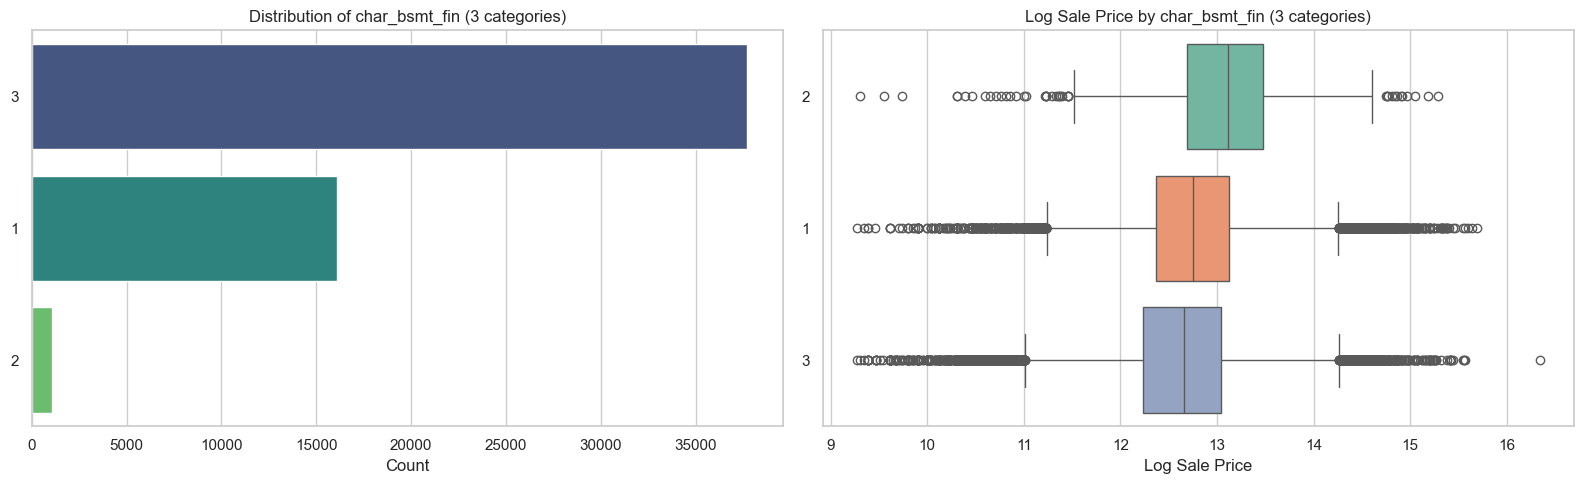

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


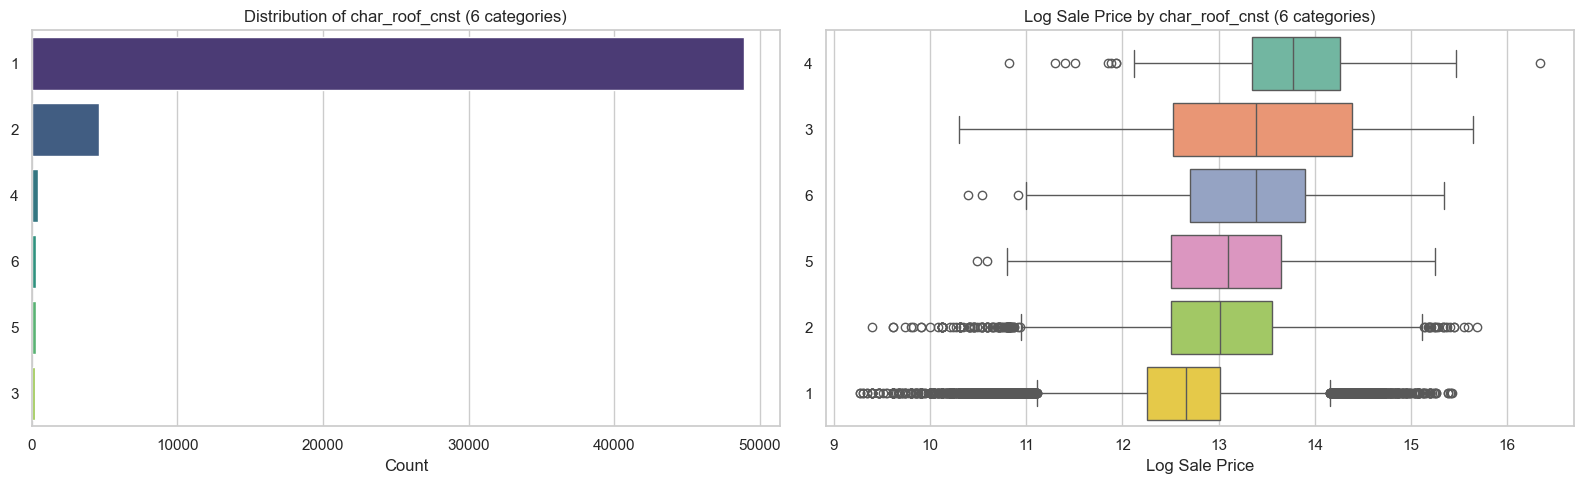

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


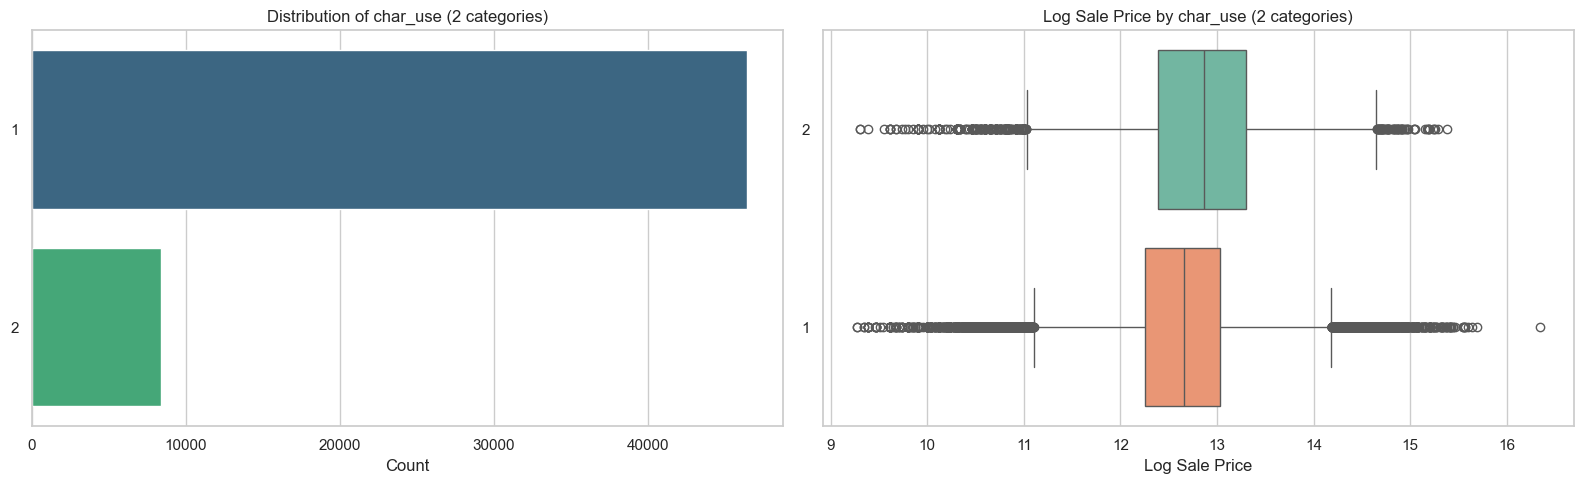

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


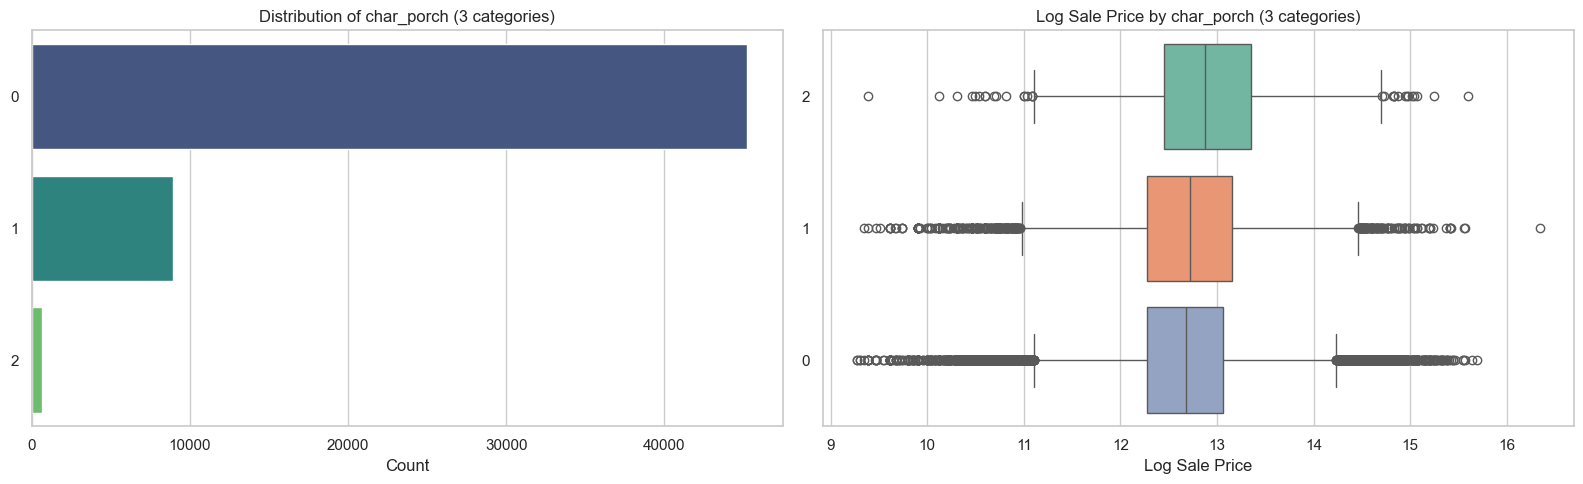

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


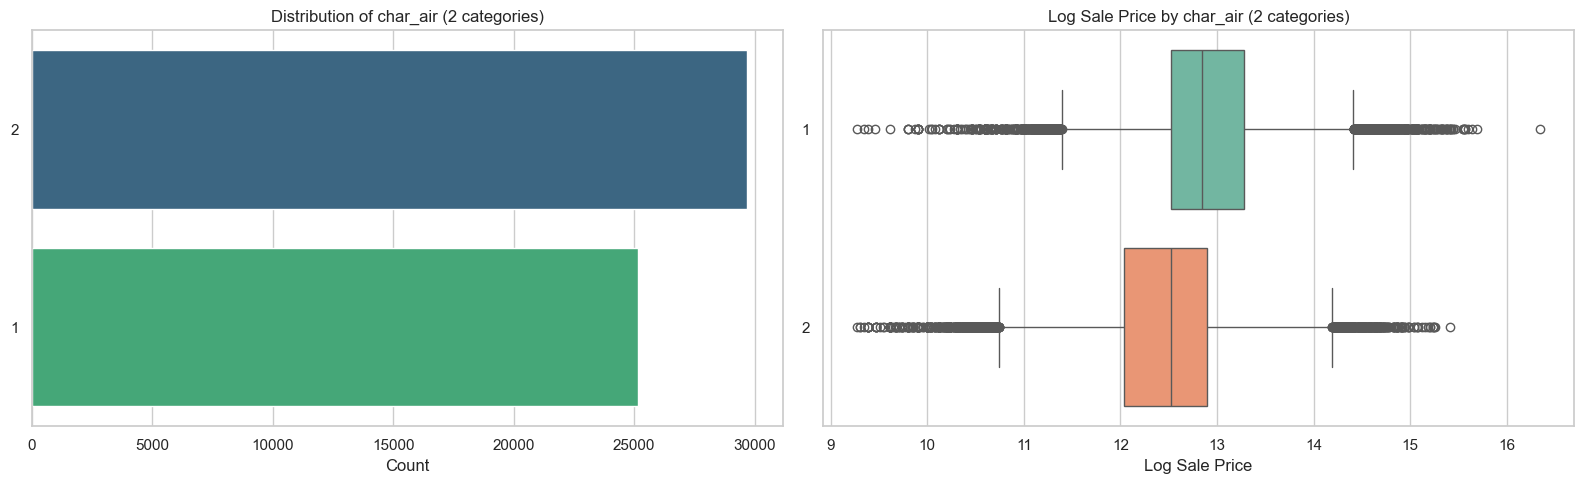

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


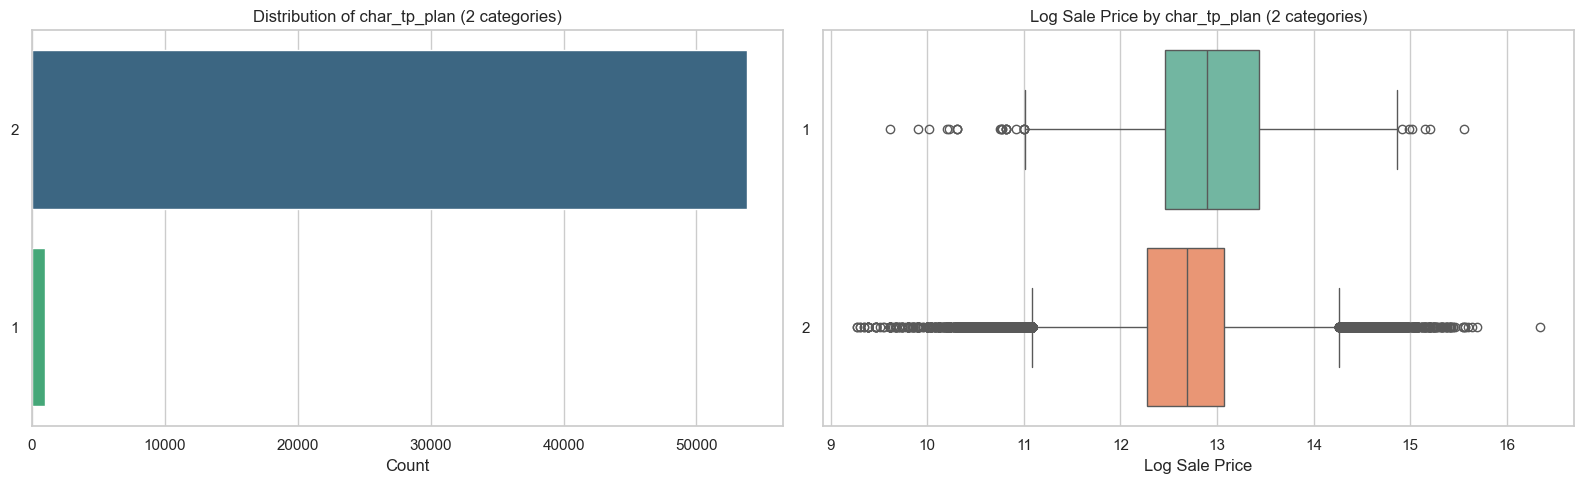

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


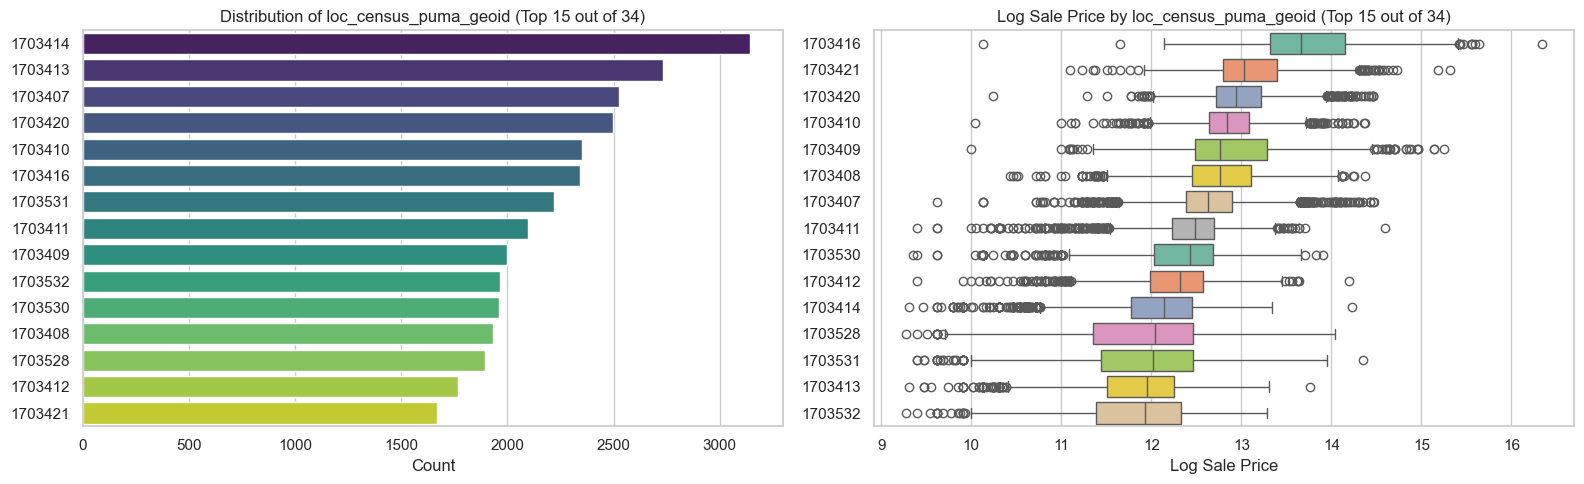

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


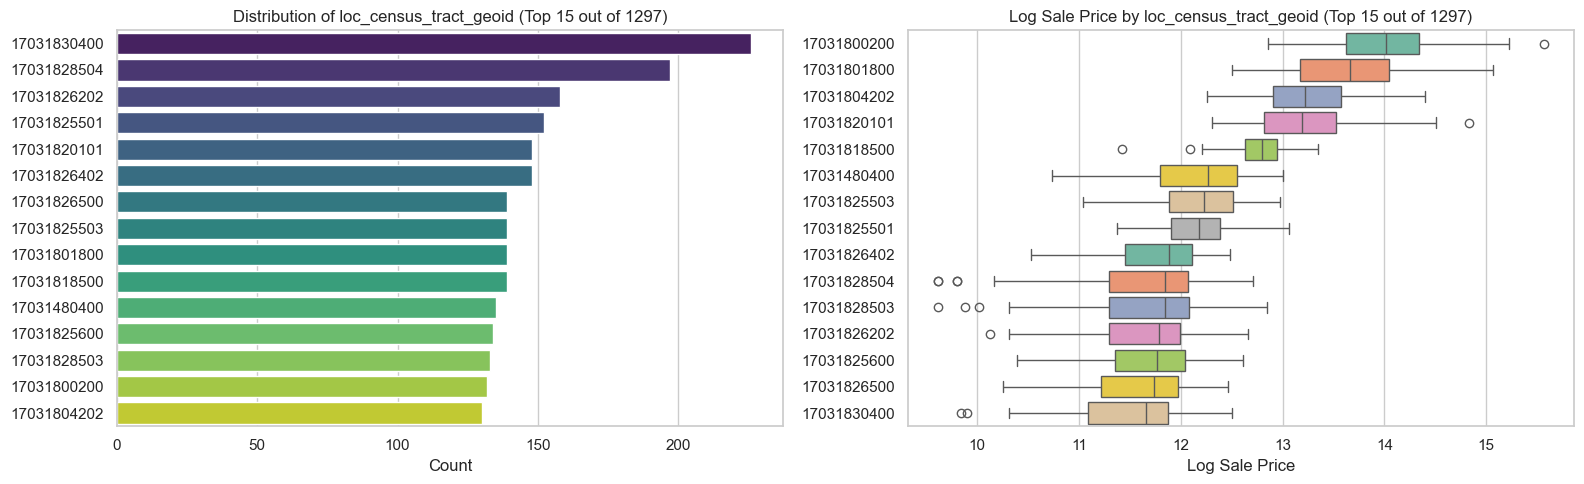

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


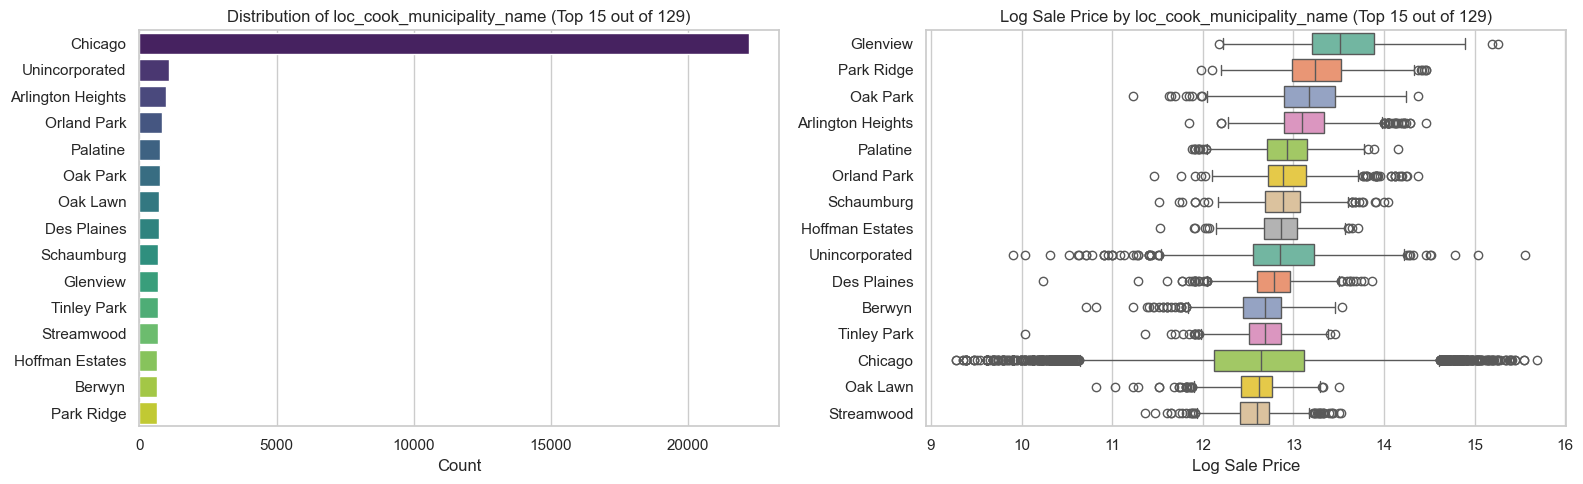

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


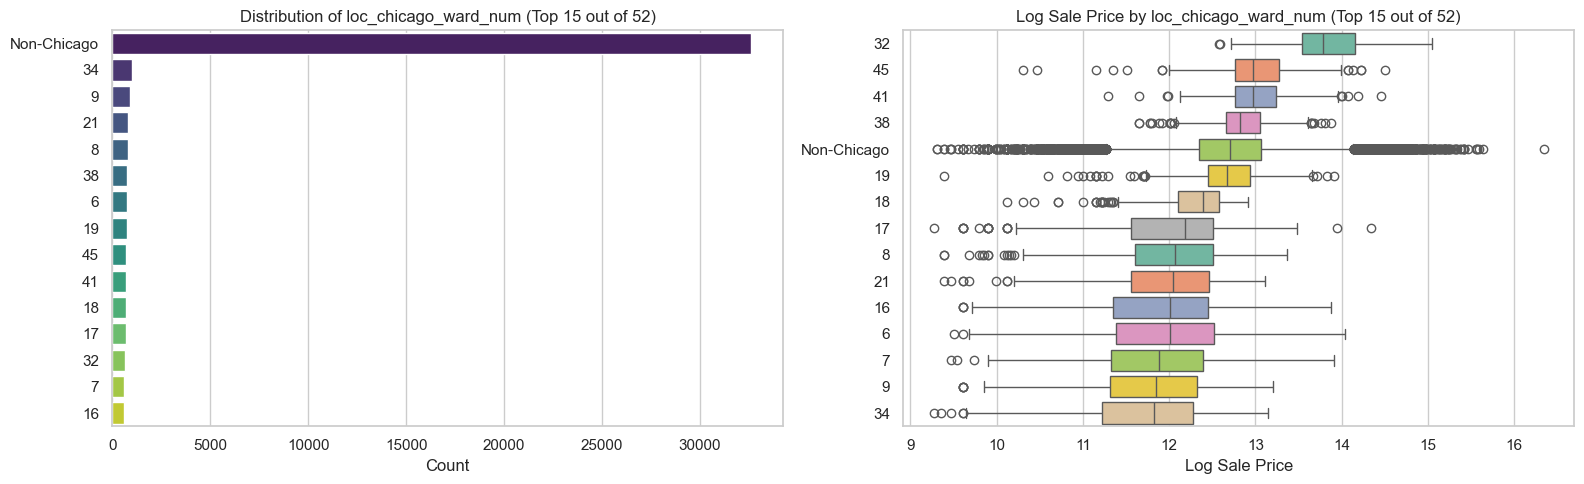

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


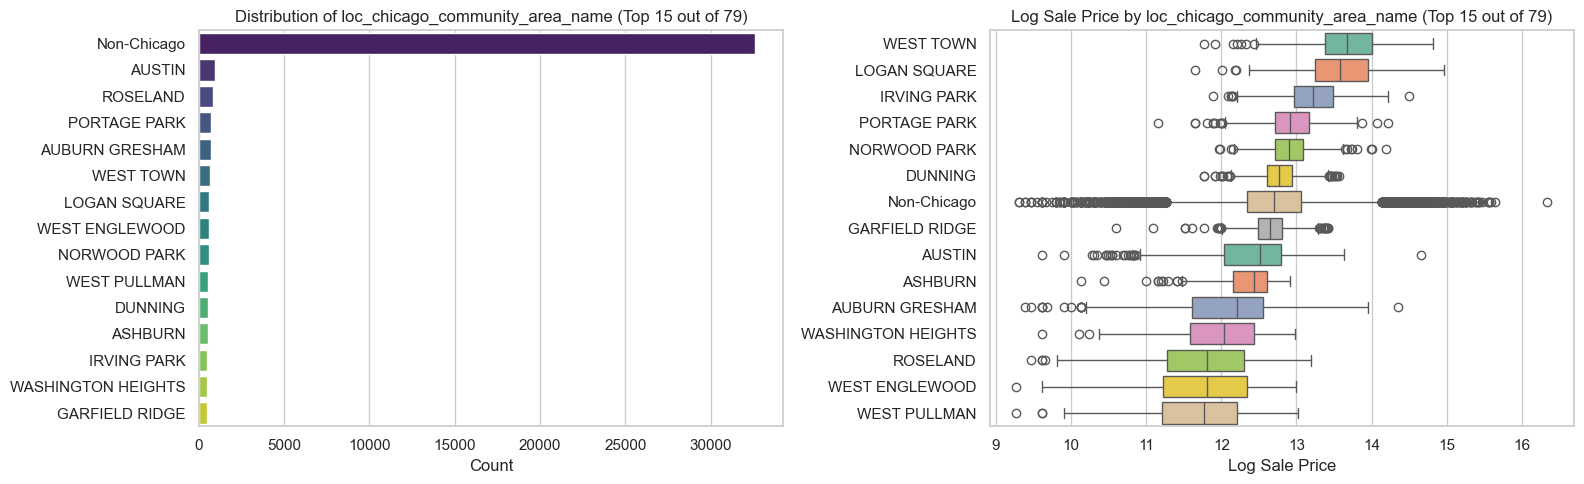

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


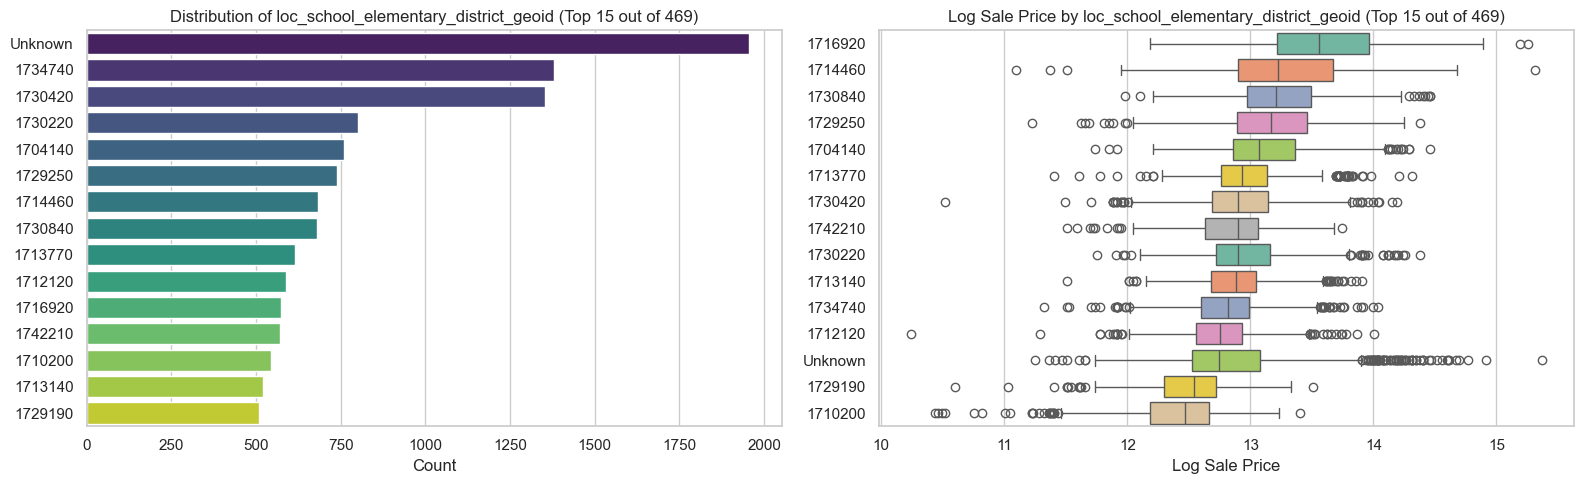

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


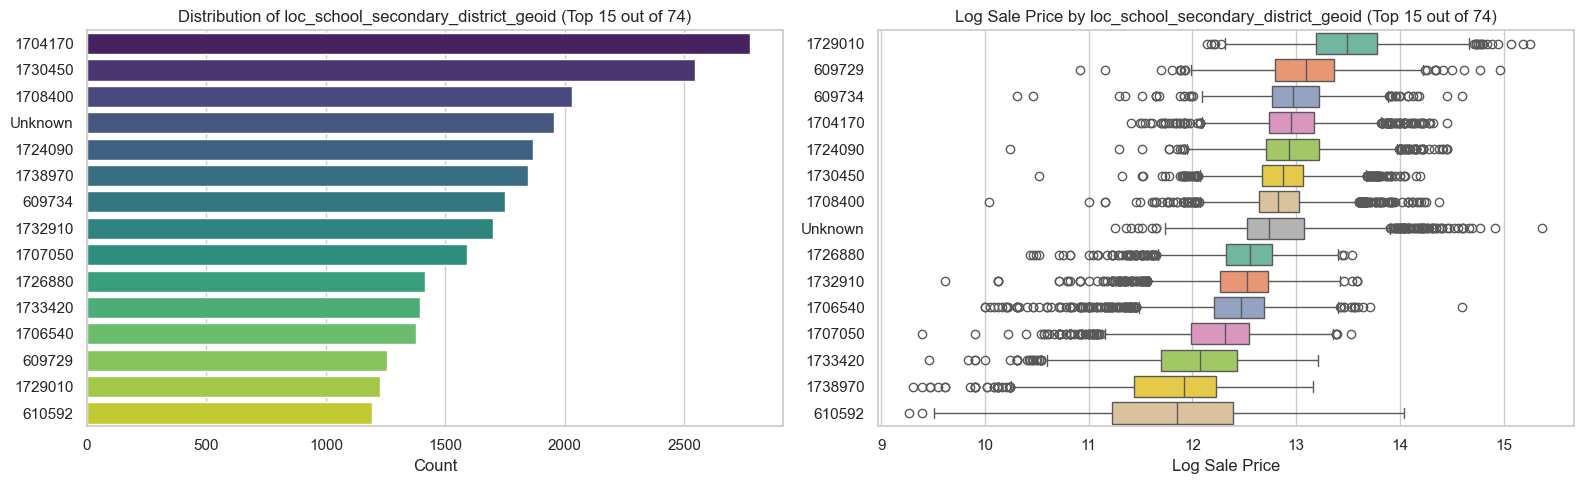

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


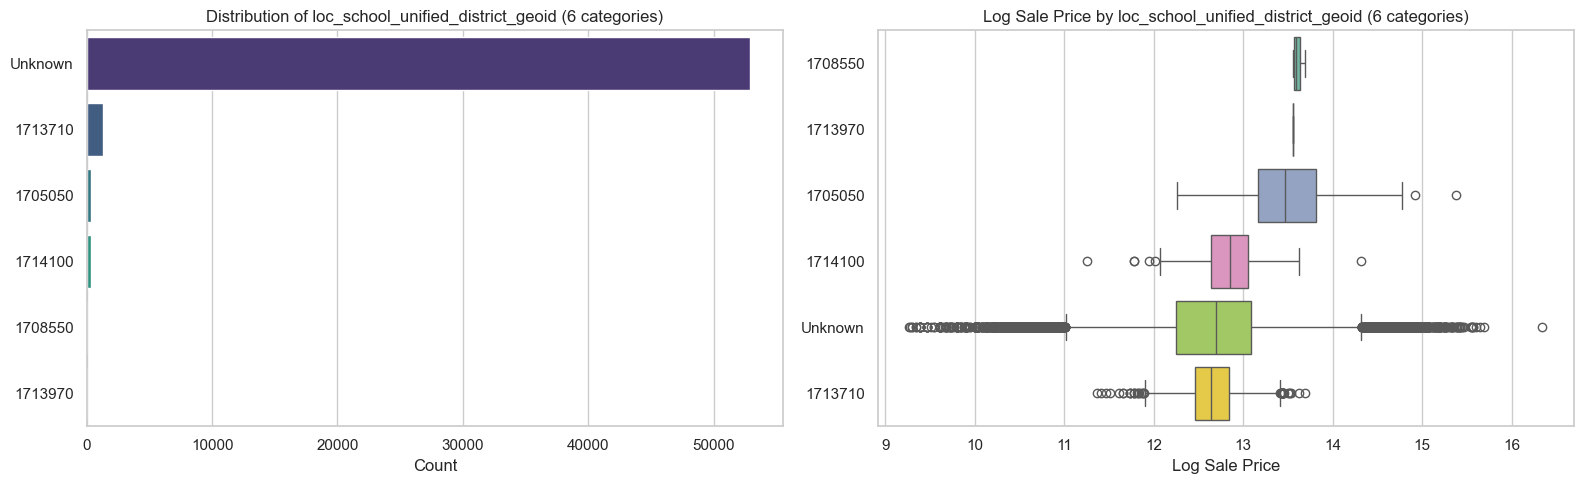

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


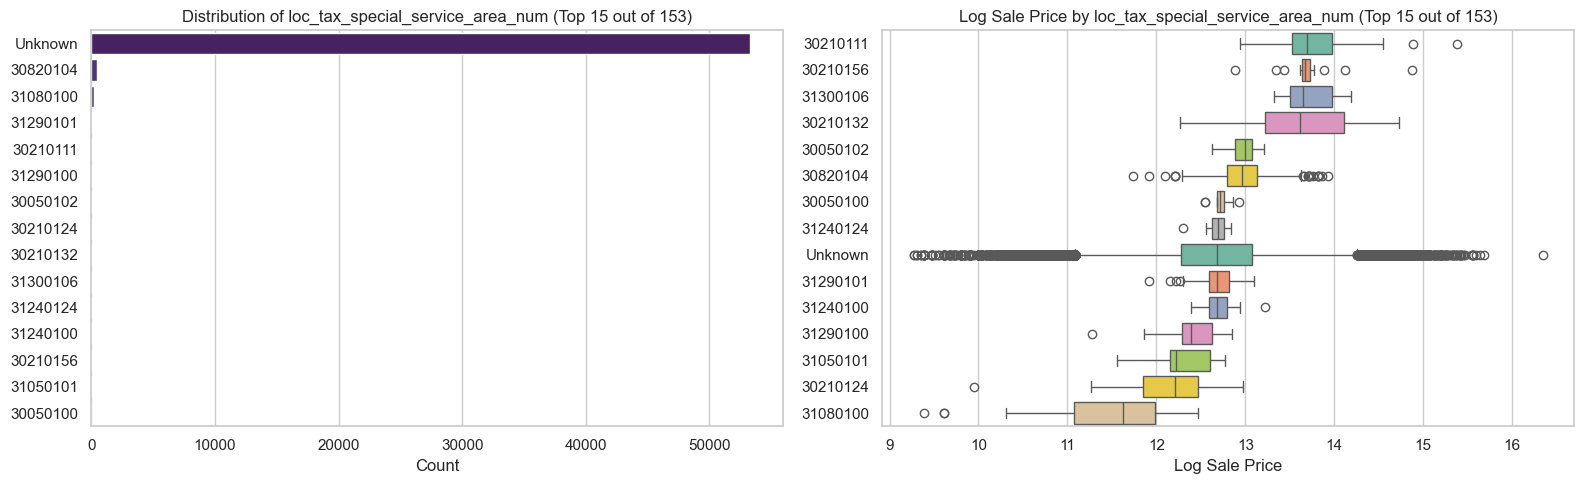

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


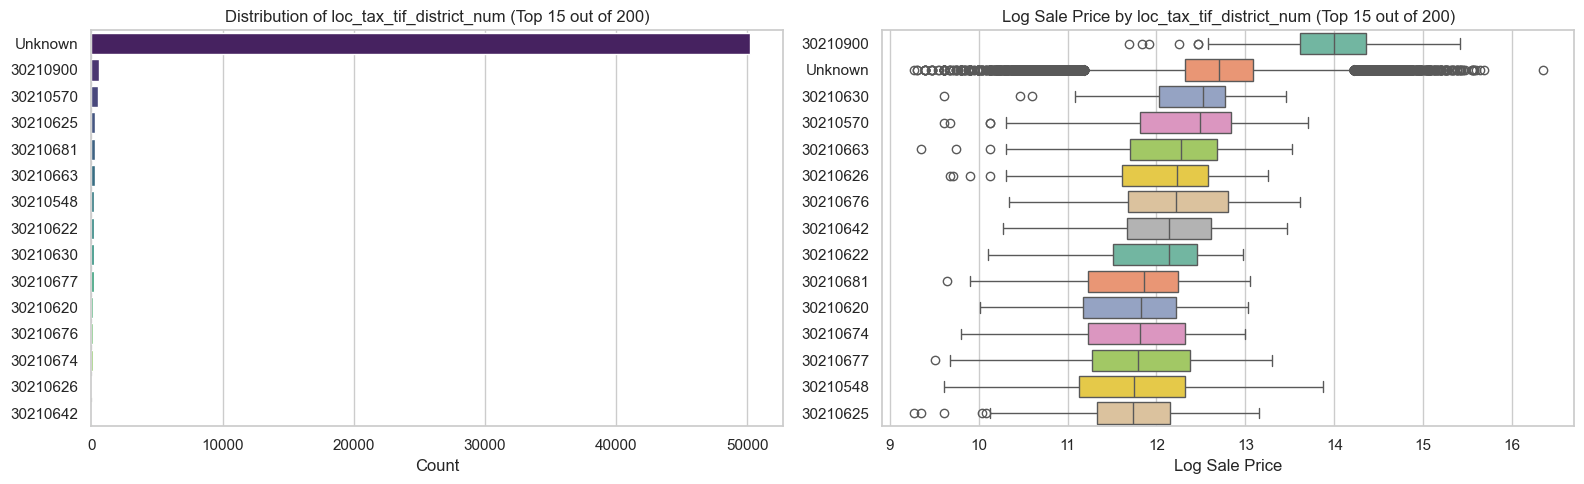

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


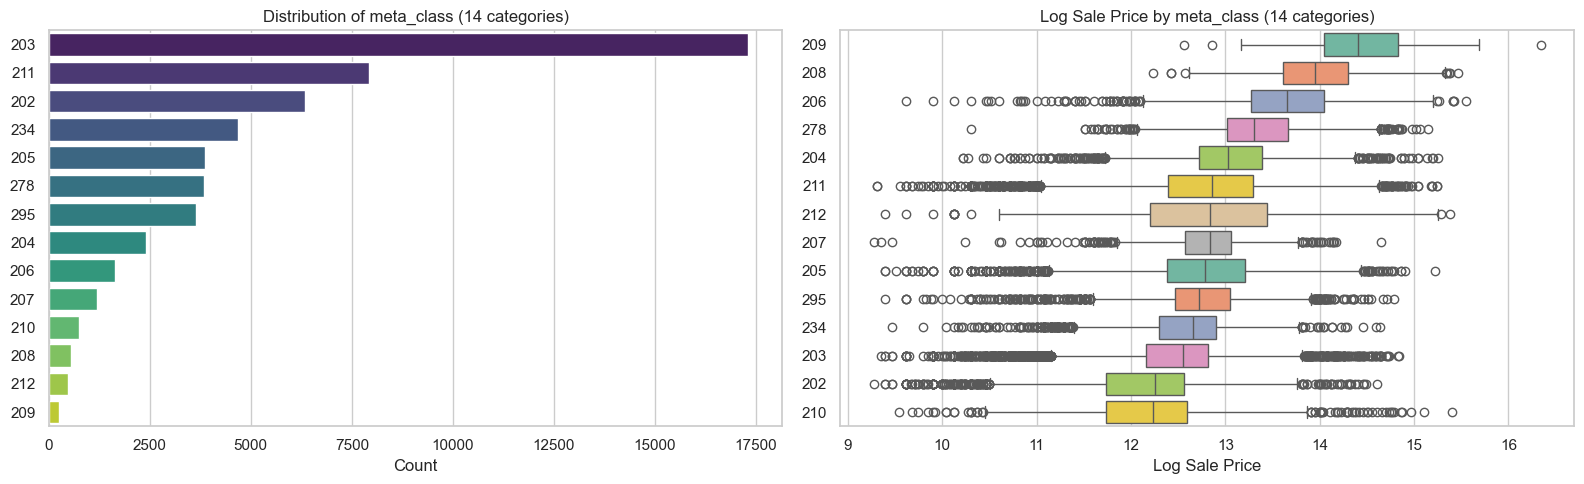

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


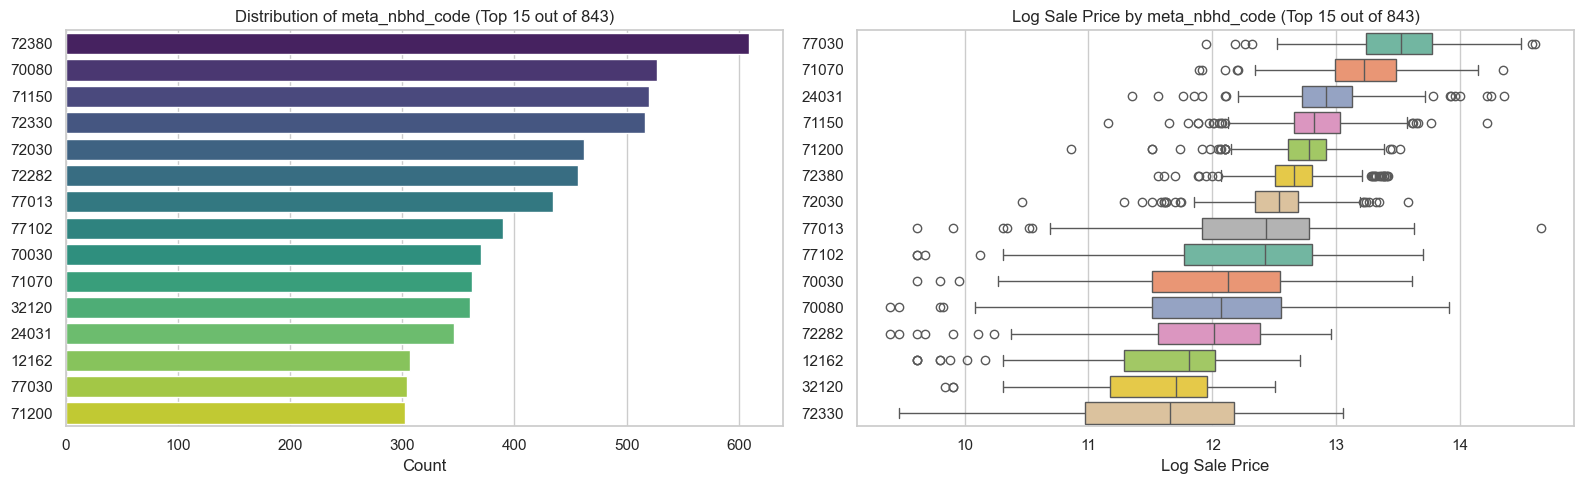

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


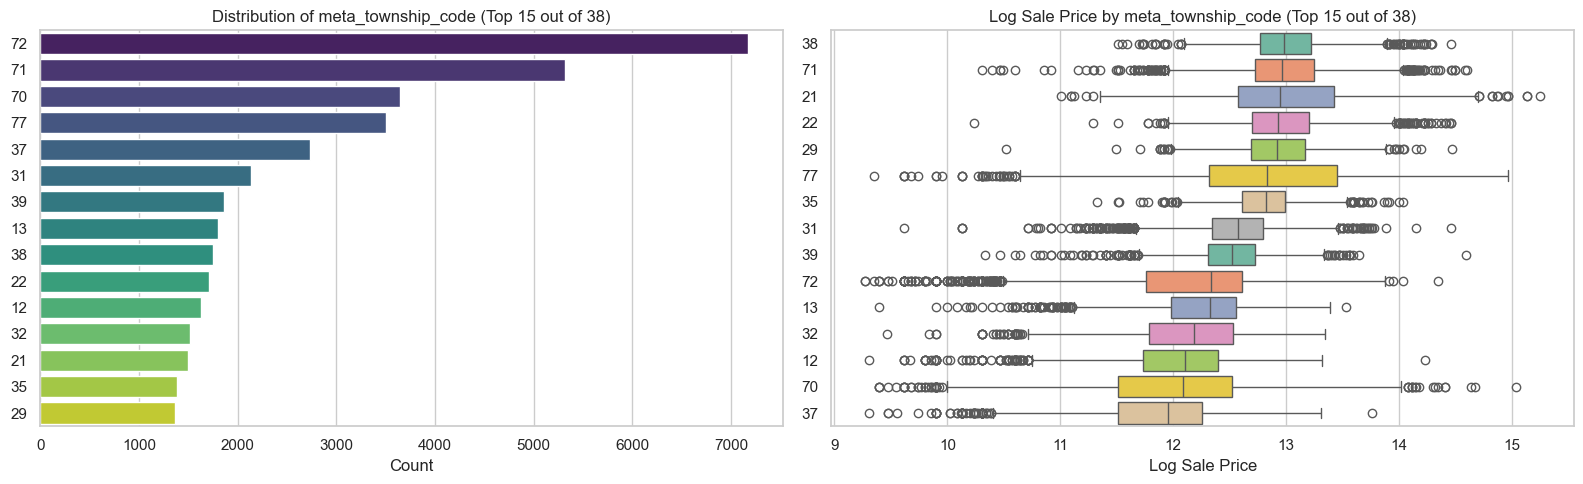

C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\20166\AppData\Local\Temp\ipykernel_40644\899930528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


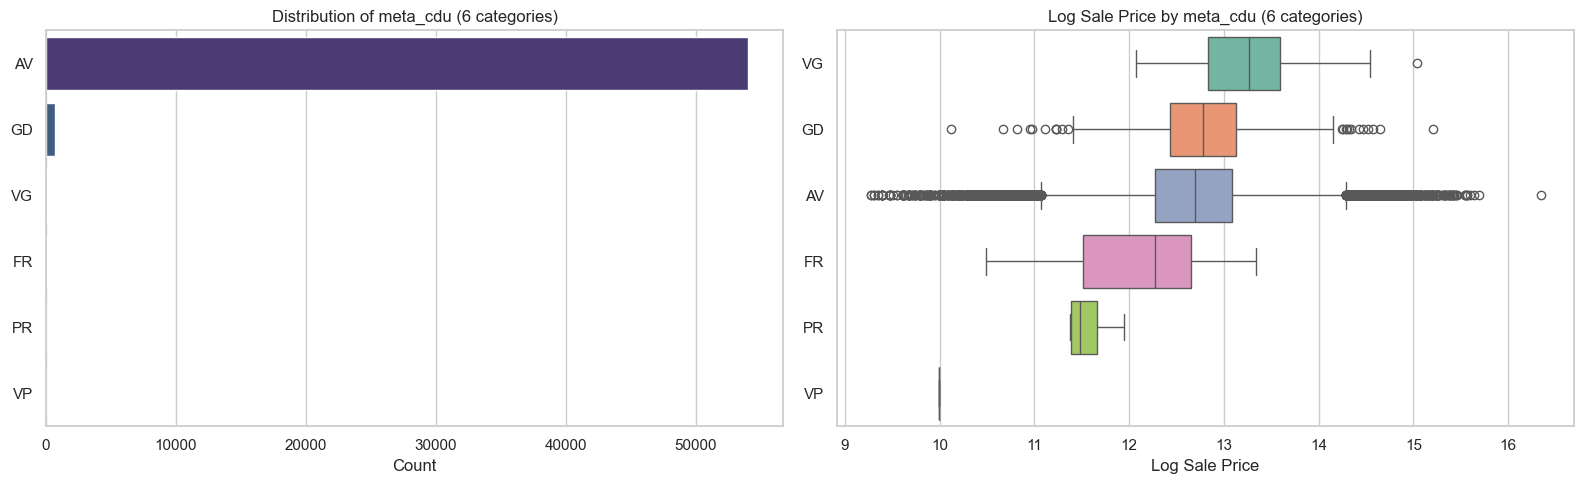


Median price per category for each feature (sorted by median descending):

--- property_id (cardinality: 51667) ---
                count  median    mean
property_id                          
05161060440000      1  16.341  16.341
17031100060000      1  15.687  15.687
05204070100000      1  15.640  15.640
05083030290000      1  15.595  15.595
05204000610000      1  15.565  15.565
05071090420000      1  15.565  15.565
05291010380000      1  15.556  15.556
17042110170000      1  15.547  15.547
17032040230000      1  15.547  15.547
05212000030000      1  15.464  15.464

--- loc_property_city (cardinality: 132) ---
                   count  median    mean
loc_property_city                       
KENILWORTH            68  14.263  14.262
WINNETKA             251  14.254  14.292
GLENCOE              176  14.119  14.140
BARRINGTON HILLS      35  13.816  13.871
GOLF                   4  13.799  13.808
HINSDALE              50  13.795  13.791
BURR RIDGE            52  13.781  13.776
SOUTH BARRIN

In [60]:
# 1. Bar charts and box plots (for low-cardinality and Top N categories)
# ==========================================
print("Generating distribution and price-relationship plots for each feature...")

for col in pkg_category:
    if col not in train_data.columns:
        continue

    # Compute the cardinality of the category
    n_unique = train_data[col].nunique()

    # If there are too many categories, only plot the top 15 most frequent categories
    if n_unique > 15:
        top_categories = train_data[col].value_counts().nlargest(15).index
        df_plot = train_data[train_data[col].isin(top_categories)]
        title_suffix = f" (Top 15 out of {n_unique})"
    else:
        df_plot = train_data
        title_suffix = f" ({n_unique} categories)"

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))

    # Left plot: Count Plot (category distribution)
    sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
    axes[0].set_title(f'Distribution of {col}{title_suffix}')
    axes[0].set_xlabel('Count')
    axes[0].set_ylabel('')

    # Right plot: Box Plot (price distribution across categories)
    # Ensure categories are ordered by median price to make the chart easier to read
    order = df_plot.groupby(col)['log_sale_price'].median().sort_values(ascending=False).index
    sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")
    axes[1].set_title(f'Log Sale Price by {col}{title_suffix}')
    axes[1].set_xlabel('Log Sale Price')
    axes[1].set_ylabel('')

    plt.tight_layout()
    save_figure(f"12_category_{col}")
    plt.show()

# ==========================================
# 2. Summary table: median price per category
# ==========================================
print("\nMedian price per category for each feature (sorted by median descending):")
for col in pkg_category:
    if col in train_data.columns:
        print(f"\n--- {col} (cardinality: {train_data[col].nunique()}) ---")
        target_summary = train_data.groupby(col)['log_sale_price'].agg(
            count='count',
            median='median',
            mean='mean'
        ).sort_values('median', ascending=False).round(3)
        print(target_summary.head(10)) # Show only the top 10

# ==========================================
# 3. Category coverage alignment between train and test sets
# ==========================================
print("\nCategory difference check between train and test sets:")
for col in pkg_category:
    if col in train_data.columns and col in test_data.columns:
        train_cats = set(train_data[col].dropna().unique())
        test_cats = set(test_data[col].dropna().unique())

        unseen_in_test = test_cats - train_cats
        if len(unseen_in_test) > 0:
            print(f"⚠️ {col}: Test set has {len(unseen_in_test)} new categories (not seen in Train set): {list(unseen_in_test)[:5]} ...")
        else:
            print(f"✅ {col}: All Test set categories are fully covered by the Train set.")


Next, we perform feature engineering on the categorical features. For features with a cardinality greater than 30, we apply target encoding. For those with a cardinality between 10 and 30, we use one-hot encoding combined with the grouping of rare categories. For features with a cardinality of 10 or less, we check whether any single value accounts for a disproportionately large share; if so, we group the rare categories, otherwise, we apply only one-hot encoding.

In [61]:
from sklearn.model_selection import KFold

target_column = "log_sale_price"

def target_encode_with_smoothing(
    training_frame,
    validation_frame,
    test_frame,
    column,
    target,
    smoothing=50,
    folds=5,
):
    """Create out-of-fold training encodings and training-only holdout mappings."""
    training_global_mean = training_frame[target].mean()
    training_encoded = np.zeros(len(training_frame), dtype=float)
    splitter = KFold(n_splits=folds, shuffle=True, random_state=42)

    for fit_positions, heldout_positions in splitter.split(training_frame):
        fit_part = training_frame.iloc[fit_positions]
        heldout_part = training_frame.iloc[heldout_positions]
        fit_global_mean = fit_part[target].mean()
        category_stats = fit_part.groupby(column)[target].agg(["mean", "count"])
        smoothed_map = (
            category_stats["count"] * category_stats["mean"]
            + smoothing * fit_global_mean
        ) / (category_stats["count"] + smoothing)
        training_encoded[heldout_positions] = (
            heldout_part[column].map(smoothed_map).fillna(fit_global_mean)
        )

    full_stats = training_frame.groupby(column)[target].agg(["mean", "count"])
    full_map = (
        full_stats["count"] * full_stats["mean"]
        + smoothing * training_global_mean
    ) / (full_stats["count"] + smoothing)

    training_frame[f"{column}_te"] = training_encoded
    validation_frame[f"{column}_te"] = validation_frame[column].map(full_map).fillna(training_global_mean)
    test_frame[f"{column}_te"] = test_frame[column].map(full_map).fillna(training_global_mean)
    for frame in (training_frame, validation_frame, test_frame):
        frame.drop(columns=column, inplace=True)
    print(f"  Target encoded: {column}")


def group_rare_and_onehot(
    training_frame,
    validation_frame,
    test_frame,
    column,
    threshold_fraction=0.01,
):
    """Fit rare grouping and dummy columns on training categories only."""
    training_values = training_frame[column].astype("string").fillna("Missing")
    validation_values = validation_frame[column].astype("string").fillna("Missing")
    test_values = test_frame[column].astype("string").fillna("Missing")

    training_frequency = training_values.value_counts(normalize=True)
    rare_categories = set(
        training_frequency.loc[training_frequency < threshold_fraction].index
    )

    def apply_training_map(values):
        mapped = values.where(~values.isin(rare_categories), "Other")
        known_categories = set(training_frequency.index) - rare_categories
        return mapped.where(mapped.isin(known_categories | {"Other"}), "Other")

    mapped_training = apply_training_map(training_values)
    mapped_validation = apply_training_map(validation_values)
    mapped_test = apply_training_map(test_values)
    training_categories = sorted(mapped_training.unique())

    def encode(values):
        categorical = pd.Categorical(values, categories=training_categories)
        return pd.get_dummies(
            categorical,
            prefix=column,
            drop_first=True,
            dtype=int,
        )

    encoded_training = encode(mapped_training)
    encoded_validation = encode(mapped_validation)
    encoded_test = encode(mapped_test)
    encoded_validation = encoded_validation.reindex(columns=encoded_training.columns, fill_value=0)
    encoded_test = encoded_test.reindex(columns=encoded_training.columns, fill_value=0)

    for frame, encoded in (
        (training_frame, encoded_training),
        (validation_frame, encoded_validation),
        (test_frame, encoded_test),
    ):
        frame.drop(columns=column, inplace=True)
        for dummy_column in encoded.columns:
            frame[dummy_column] = encoded[dummy_column].to_numpy()

    print(
        f"  One-hot encoded from training categories: {column} "
        f"({len(rare_categories)} rare categories grouped)"
    )
    return training_frame, validation_frame, test_frame


print("Processing categorical features with training-only fitted mappings...")
excluded_encoding_columns = {
    "property_id",
    "transaction_id",
    "sale_price",
    "log_sale_price",
    "sale_date",
}
for column in pkg_category:
    if column not in train_data.columns or column in excluded_encoding_columns:
        continue
    for frame in (train_data, val_data, test_data):
        frame[column] = frame[column].astype("string").fillna("Missing")

    distinct_training_categories = train_data[column].nunique()
    if distinct_training_categories >= 30:
        target_encode_with_smoothing(
            train_data,
            val_data,
            test_data,
            column,
            target_column,
            smoothing=50,
        )
    else:
        category_frequency = train_data[column].value_counts(normalize=True)
        top_two_fraction = category_frequency.head(2).sum()
        threshold = 0.05 if distinct_training_categories >= 10 else (
            0.02 if top_two_fraction > 0.95 else 0.0
        )
        train_data, val_data, test_data = group_rare_and_onehot(
            train_data,
            val_data,
            test_data,
            column,
            threshold_fraction=threshold,
        )

print("Categorical processing complete.")
print(f"Final shapes: Train={train_data.shape}, Validation={val_data.shape}, Test={test_data.shape}")
print("Validation and test category levels were not used to fit encoders.")
assert not any(
    column.startswith(("property_id_", "transaction_id_"))
    for column in train_data.columns
), "Identifier-derived predictor detected."


Processing categorical features with training-only fitted mappings...
  Target encoded: loc_property_city
  Target encoded: loc_property_zip
  One-hot encoded from training categories: char_type_resd (0 rare categories grouped)
  One-hot encoded from training categories: char_cnst_qlty (2 rare categories grouped)
  One-hot encoded from training categories: char_apts (0 rare categories grouped)
  One-hot encoded from training categories: char_attic_fnsh (1 rare categories grouped)
  One-hot encoded from training categories: char_gar1_size (0 rare categories grouped)
  One-hot encoded from training categories: char_gar1_cnst (0 rare categories grouped)
  One-hot encoded from training categories: char_attic_type (0 rare categories grouped)
  One-hot encoded from training categories: char_bsmt (0 rare categories grouped)
  One-hot encoded from training categories: char_ext_wall (0 rare categories grouped)
  One-hot encoded from training categories: char_heat (2 rare categories grouped)
  O

This cell performs a final validation across the Train, Validation, and Test datasets before modeling:

1. **Column alignment** – Confirms that all three datasets share exactly the same columns (same order and names).
2. **Target integrity** – Verifies that `log_sale_price` has no missing values and contains only finite numbers in every dataset.
3. **Predictor integrity** – Checks that all predictor features contain no missing values and that all numeric predictors are finite (no NaN/inf).
4. **No leftover object columns** – Ensures no unencoded `object`-type columns remain in the training data.

In [62]:
training_columns = train_data.columns.tolist()
assert training_columns == val_data.columns.tolist() == test_data.columns.tolist()

for dataset_name, frame in {
    "Train": train_data,
    "Validation": val_data,
    "Test": test_data,
}.items():
    assert frame["log_sale_price"].notna().all()
    assert np.isfinite(frame["log_sale_price"]).all()
    predictors = frame.drop(columns=["log_sale_price", "sale_price"], errors="ignore")
    numeric_predictors = predictors.select_dtypes(include=[np.number])
    assert np.isfinite(numeric_predictors.to_numpy(dtype=float)).all()
    assert not predictors.isna().any().any()
    print(f"{dataset_name}: target and predictors passed missing/infinite checks.")

remaining_object_columns = train_data.select_dtypes(include=["object"]).columns.tolist()
assert not remaining_object_columns, f"Unexpected object columns: {remaining_object_columns}"
print("Train, validation and test columns are aligned.")


Train: target and predictors passed missing/infinite checks.
Validation: target and predictors passed missing/infinite checks.
Test: target and predictors passed missing/infinite checks.
Train, validation and test columns are aligned.


### Missing-indicator diagnostic

Training-set target differences are reported as descriptive evidence only. Indicators are not deleted from this legacy matrix based on a single mean-difference threshold. Their incremental value is assessed later with a fixed-model validation ablation.


In [63]:
print("Missing-indicator diagnostic on training data only")
print("=" * 80)

missing_indicator_columns = [
    column for column in train_data.columns if column.endswith("_missing")
]
indicator_rows = []
for indicator in missing_indicator_columns:
    nonmissing_group = train_data.loc[train_data[indicator] == 0, "log_sale_price"]
    missing_group = train_data.loc[train_data[indicator] == 1, "log_sale_price"]
    indicator_rows.append(
        {
            "indicator": indicator,
            "nonmissing_count": len(nonmissing_group),
            "missing_count": len(missing_group),
            "mean_log_price_difference": (
                missing_group.mean() - nonmissing_group.mean()
                if len(nonmissing_group) and len(missing_group)
                else np.nan
            ),
        }
    )

missing_indicator_report = pd.DataFrame(indicator_rows)
if not missing_indicator_report.empty:
    missing_indicator_report["absolute_difference"] = missing_indicator_report[
        "mean_log_price_difference"
    ].abs()
    missing_indicator_report = missing_indicator_report.sort_values(
        "absolute_difference", ascending=False
    )
    print(missing_indicator_report.head(20).to_string(index=False, float_format=lambda value: f"{value:.4f}"))
else:
    print("No explicit legacy missing-indicator columns were found.")

print(
    "\nNo indicators are removed here. A marginal target difference does not measure "
    "conditional or nonlinear predictive value and is not a fair feature-selection test."
)


Missing-indicator diagnostic on training data only
                                               indicator  nonmissing_count  missing_count  mean_log_price_difference  absolute_difference
  prox_num_foreclosure_per_1000_pin_past_5_years_missing             54411            442                     0.8437               0.8437
                                        meta_cdu_missing             54796             57                     0.7798               0.7798
      acs5_median_household_owner_occupied_value_missing             54765             88                    -0.5925               0.5925
                 loc_env_flood_fs_risk_direction_missing             54799             54                     0.5461               0.5461
                         loc_env_flood_fs_factor_missing             54799             54                     0.5461               0.5461
acs5_median_household_renter_occupied_gross_rent_missing             53476           1377                     0.4424     

### `is_Chicago` redundancy diagnostic

`is_Chicago` is a deterministic summary of the richer city field. Correlations with target-encoded location columns are descriptive only; the feature is not removed from the legacy matrix until a validation ablation is reported. The leakage-safe modelling pipeline below rebuilds predictors from the original property file and does not include this manually created field.


In [64]:
location_encoding_columns = [
    "loc_property_city_te",
    "loc_chicago_ward_num_te",
    "loc_chicago_community_area_name_te",
]
available_location_encodings = [
    column for column in location_encoding_columns if column in train_data.columns
]

if "is_Chicago" in train_data.columns:
    chicago_summary = train_data.groupby("is_Chicago")["log_sale_price"].agg(
        transactions="count",
        mean_log_price="mean",
        median_log_price="median",
    )
    print("Training-only is_Chicago target summary")
    print(chicago_summary.to_string(float_format=lambda value: f"{value:.4f}"))
    print("\nCorrelation with legacy target-encoded location columns")
    for column in available_location_encodings:
        correlation = train_data[[column, "is_Chicago"]].corr().iloc[0, 1]
        print(f"{column}: {correlation:.4f}")
else:
    print("is_Chicago is not present in the legacy matrix.")

print(
    "\nThis diagnostic does not justify feature deletion. The later validation "
    "ablation holds the model, split and metrics fixed."
)


Training-only is_Chicago target summary
            transactions  mean_log_price  median_log_price
is_Chicago                                                
0                  32611         12.6972           12.7069
1                  22242         12.6006           12.6443

Correlation with legacy target-encoded location columns
loc_property_city_te: -0.1346
loc_chicago_ward_num_te: -0.1449
loc_chicago_community_area_name_te: -0.1284

This diagnostic does not justify feature deletion. The later validation ablation holds the model, split and metrics fixed.


In [65]:
print("is_Chicago is retained in the legacy matrix pending validation ablation.")
print(
    "It is absent from the leakage-safe raw-property feature inventory unless "
    "explicitly added in the ablation experiment."
)


is_Chicago is retained in the legacy matrix pending validation ablation.
It is absent from the leakage-safe raw-property feature inventory unless explicitly added in the ablation experiment.


In [66]:
print("Creating house age at the sale valuation year...")

for dataset_name, frame in {
    "Train": train_data,
    "Validation": val_data,
    "Test": test_data,
}.items():
    if {"char_yrblt", "sale_year"}.issubset(frame.columns):
        year_built = pd.to_numeric(frame["char_yrblt"], errors="coerce").round()
        frame["house_age"] = (frame["sale_year"] - year_built).clip(lower=0, upper=300)
        frame["house_age"] = frame["house_age"].astype("Int64")
        print(f"{dataset_name}: house_age created.")
    else:
        print(f"{dataset_name}: required columns unavailable; house_age skipped.")

print("House age uses only the valuation year and the archived year built.")


Creating house age at the sale valuation year...
Train: house_age created.
Validation: house_age created.
Test: house_age created.
House age uses only the valuation year and the archived year built.


### Final legacy-matrix cleanup

Identifiers and targets are excluded from predictors. Month indicators are generated from a predefined calendar-month template, so validation and test values do not define the training feature space.


In [67]:
leakage_and_identifier_columns = [
    "sale_price",
    "sale_date",
    "sale_year",
    "sale_quarter",
    "sale_ym",
    "lat_bin",
    "lon_bin",
    "transaction_id",
    "property_id",
]
for dataset_name in ("train_data", "val_data", "test_data"):
    frame = globals()[dataset_name]
    frame.drop(
        columns=[
            column for column in leakage_and_identifier_columns if column in frame.columns
        ],
        inplace=True,
    )

month_template = [str(month) for month in range(1, 13)]
month_dtype = pd.CategoricalDtype(categories=month_template, ordered=True)
month_dummy_columns = pd.get_dummies(
    pd.Series(month_template, dtype="string"),
    prefix="month",
    drop_first=True,
    dtype=int,
).columns.tolist()

for dataset_name in ("train_data", "val_data", "test_data"):
    frame = globals()[dataset_name]
    month_values = frame["sale_month"].astype("string")
    assert month_values.isin(month_template).all(), "Unexpected sale month."
    # Use January as the reference in every split, including July-December validation.
    month_dummies = pd.get_dummies(
        month_values.astype(month_dtype),
        prefix="month",
        drop_first=True,
        dtype=int,
    ).reindex(columns=month_dummy_columns, fill_value=0)
    assert month_dummies.index.equals(frame.index)
    globals()[dataset_name] = pd.concat(
        [frame.drop(columns="sale_month"), month_dummies], axis=1
    )

assert train_data.columns.tolist() == val_data.columns.tolist() == test_data.columns.tolist()
print("Identifiers and direct target fields were removed from predictors.")
print("Month indicators were aligned to a fixed 1-12 month template.")
print(f"Final legacy matrix columns: {train_data.shape[1]:,}")


Identifiers and direct target fields were removed from predictors.
Month indicators were aligned to a fixed 1-12 month template.
Final legacy matrix columns: 210


In [68]:
assert train_data.columns.tolist() == val_data.columns.tolist() == test_data.columns.tolist()
for dataset_name, frame in {
    "Train": train_data,
    "Validation": val_data,
    "Test": test_data,
}.items():
    assert frame["log_sale_price"].notna().all()
    numeric_frame = frame.select_dtypes(include=[np.number])
    assert np.isfinite(numeric_frame.to_numpy(dtype=float)).all()
    assert not frame.isna().any().any()
    print(f"{dataset_name}: {frame.shape[0]:,} rows x {frame.shape[1]:,} columns")
print("Final legacy matrices passed column-alignment and numeric-health checks.")


Train: 54,853 rows x 210 columns
Validation: 18,132 rows x 210 columns
Test: 36,322 rows x 210 columns
Final legacy matrices passed column-alignment and numeric-health checks.


### Safe chronological feature snapshot export

The transaction membership remains fixed from the original identifiers and dates. The export cell writes regenerated snapshots to a candidate directory, validates membership order, targets, schema, numeric information retention and CSV round-trip fidelity, then atomically replaces the official files. The pre-repair files and manifest are retained in `data/split/backup_before_export_fix_20261026/`. All learned preprocessing parameters and category mappings are fitted on the training split only.


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import os
import shutil

split_dir = Path("data") / "split"
candidate_dir = split_dir / "candidate_export"
backup_dir = split_dir / "backup_before_export_fix_20261026"
split_dir.mkdir(parents=True, exist_ok=True)
candidate_dir.mkdir(parents=True, exist_ok=True)
backup_dir.mkdir(parents=True, exist_ok=True)
expected_rows = {"train": 54853, "validation": 18132, "test": 36322}


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


raw_sales = pd.read_csv(
    Path("data") / "sales.csv",
    usecols=["transaction_id", "property_id", "sale_date", "sale_price"],
    dtype={"transaction_id": "string", "property_id": "string"},
)
raw_sales["transaction_id"] = raw_sales["transaction_id"].str.strip()
raw_sales["property_id"] = raw_sales["property_id"].str.strip()
raw_sales["sale_date"] = pd.to_datetime(raw_sales["sale_date"], errors="raise")

raw_split_masks = {
    "train": raw_sales["sale_date"].between("2023-01-01", "2024-06-30"),
    "validation": raw_sales["sale_date"].between("2024-07-01", "2024-12-31"),
    "test": raw_sales["sale_date"].between("2025-01-01", "2025-12-31"),
}
raw_splits = {
    name: raw_sales.loc[mask].reset_index(drop=True)
    for name, mask in raw_split_masks.items()
}
current_frames = {
    "train": train_data.reset_index(drop=True),
    "validation": val_data.reset_index(drop=True),
    "test": test_data.reset_index(drop=True),
}

# Verify and preserve the identifier-based membership records.
membership_details = {}
for name, raw_split in raw_splits.items():
    assert len(raw_split) == expected_rows[name], f"Unexpected {name} row count."
    identity = raw_split[["transaction_id", "property_id", "sale_date"]].copy()
    identity["sale_date"] = identity["sale_date"].dt.strftime("%Y-%m-%d")
    identity_path = split_dir / f"{name}_membership.csv"
    if identity_path.exists():
        saved_identity = pd.read_csv(
            identity_path,
            dtype={"transaction_id": "string", "property_id": "string"},
        )
        pd.testing.assert_frame_equal(saved_identity, identity, check_dtype=False)
    else:
        identity.to_csv(identity_path, index=False)
    membership_details[name] = {
        "file": identity_path.name,
        "rows": len(identity),
        "sha256": sha256_file(identity_path),
    }

# Confirm target order before creating any candidate file. The 2025 target is
# checked for export alignment only and is not used to fit preprocessing.
for name, current_frame in current_frames.items():
    assert len(current_frame) == expected_rows[name]
    assert not {"property_id", "transaction_id", "sale_price"}.intersection(
        current_frame.columns
    )
    expected_log_target = np.log1p(
        raw_splits[name]["sale_price"].to_numpy(dtype=float)
    )
    np.testing.assert_allclose(
        current_frame["log_sale_price"].to_numpy(dtype=float),
        expected_log_target,
        rtol=1e-12,
        atol=1e-12,
    )

assert (
    current_frames["train"].columns.tolist()
    == current_frames["validation"].columns.tolist()
    == current_frames["test"].columns.tolist()
)

# Detect unexplained information loss across every surviving raw numeric feature.
raw_properties = pd.read_csv(
    Path("data") / "properties_2022.csv",
    dtype={"property_id": "string"},
    low_memory=False,
)
raw_properties["property_id"] = raw_properties["property_id"].str.strip()
variable_dictionary = pd.read_csv(Path("data") / "variable_dictionary.csv")
numeric_source_features = variable_dictionary.loc[
    variable_dictionary["type"].eq("numeric"),
    "variable",
].tolist()
raw_training_features = raw_splits["train"][["property_id"]].merge(
    raw_properties,
    on="property_id",
    how="left",
    validate="many_to_one",
    sort=False,
)
surviving_numeric_features = [
    column
    for column in numeric_source_features
    if column in current_frames["train"].columns
    and pd.api.types.is_numeric_dtype(current_frames["train"][column])
]
unexpected_constant_features = []
for column in surviving_numeric_features:
    raw_values = pd.to_numeric(raw_training_features[column], errors="coerce")
    exported_values = pd.to_numeric(
        current_frames["train"][column],
        errors="coerce",
    )
    if (
        raw_values.nunique(dropna=True) > 1
        and exported_values.nunique(dropna=True) <= 1
    ):
        unexpected_constant_features.append(column)
assert not unexpected_constant_features, (
    "Unexpected information loss in numeric features: "
    f"{unexpected_constant_features}"
)

candidate_snapshots = {}
candidate_hashes = {}
for name, current_frame in current_frames.items():
    snapshot = current_frame.copy()
    snapshot.insert(0, "sale_price", raw_splits[name]["sale_price"].to_numpy())
    candidate_path = candidate_dir / f"{name}.csv"
    snapshot.to_csv(candidate_path, index=False, float_format="%.17g")
    saved_candidate = pd.read_csv(candidate_path)
    pd.testing.assert_frame_equal(
        saved_candidate,
        snapshot,
        check_dtype=False,
        check_exact=False,
        rtol=1e-12,
        atol=1e-12,
    )
    candidate_snapshots[name] = snapshot
    candidate_hashes[name] = sha256_file(candidate_path)

# A second independent serialization must produce the same bytes.
for name, snapshot in candidate_snapshots.items():
    repeat_path = candidate_dir / f"{name}.repeat.csv"
    snapshot.to_csv(repeat_path, index=False, float_format="%.17g")
    assert sha256_file(repeat_path) == candidate_hashes[name]
    repeat_path.unlink()

# Build and validate the candidate manifest before any official file is replaced.
snapshot_details = {
    name: {
        "file": f"{name}.csv",
        "rows": len(snapshot),
        "columns": len(snapshot.columns),
        "sha256": candidate_hashes[name],
    }
    for name, snapshot in candidate_snapshots.items()
}

source_notebook_path = Path("QBUS6810_assignment_merged_revised.ipynb")
if not source_notebook_path.is_file():
    raise FileNotFoundError(
        f"The merged notebook is required for the manifest: {source_notebook_path}"
    )
notebook_content = json.loads(source_notebook_path.read_text(encoding="utf-8"))
split_cell_index = next(
    index
    for index, cell in enumerate(notebook_content["cells"])
    if "candidate_snapshots = {}" in "".join(cell.get("source", []))
)
pipeline_sources = [
    {"cell_type": cell["cell_type"], "source": cell.get("source", [])}
    for cell in notebook_content["cells"][: split_cell_index + 1]
]
pipeline_digest = hashlib.sha256(
    json.dumps(pipeline_sources, sort_keys=True, ensure_ascii=False).encode("utf-8")
).hexdigest()

manifest_path = split_dir / "manifest.json"
previous_manifest = (
    json.loads(manifest_path.read_text(encoding="utf-8"))
    if manifest_path.exists()
    else {}
)
source_files = [
    "data/properties_2022.csv",
    "data/sales.csv",
    "data/variable_dictionary.csv",
    "data/featureengineer.csv",
]
manifest = {
    "created_utc": previous_manifest.get("created_utc", datetime.now(timezone.utc).isoformat()),
    "format": "csv",
    "source_notebook": source_notebook_path.name,
    "pipeline_code_sha256": pipeline_digest,
    "input_sha256": {path: sha256_file(path) for path in source_files},
    "target": "sale_price",
    "derived_target": "log_sale_price",
    "preprocessing_fit_scope": "training split only",
    "numeric_information_loss_check": {
        "surviving_raw_numeric_features_checked": len(surviving_numeric_features),
        "unexpected_constant_features": unexpected_constant_features,
    },
    "time_split": {
        "train": "2023-01-01 through 2024-06-30",
        "validation": "2024-07-01 through 2024-12-31",
        "test": "2025-01-01 through 2025-12-31",
    },
    "membership": membership_details,
    "splits": snapshot_details,
    "backup_directory": backup_dir.name,
    "candidate_directory": candidate_dir.name,
}
# Preserve the verification timestamp on an identical rerun, so the entire
# already-published bundle can be recognized and left untouched.
previous_without_timestamp = {
    key: value for key, value in previous_manifest.items()
    if key != "last_verified_utc"
}
manifest["last_verified_utc"] = (
    previous_manifest["last_verified_utc"]
    if previous_without_timestamp == manifest and "last_verified_utc" in previous_manifest
    else datetime.now(timezone.utc).isoformat()
)
candidate_manifest_path = candidate_dir / "manifest.json"
candidate_manifest_path.write_text(json.dumps(manifest, indent=2) + "\n", encoding="utf-8")
assert json.loads(candidate_manifest_path.read_text(encoding="utf-8")) == manifest

# Keep the historical pre-fix archive. A fresh rollback snapshot below protects
# the CURRENT official version, which may be newer than that archive.
for official_path in [
    split_dir / "train.csv", split_dir / "validation.csv",
    split_dir / "test.csv", manifest_path,
]:
    if official_path.exists():
        historical_backup = backup_dir / official_path.name
        if not historical_backup.exists():
            shutil.copy2(official_path, historical_backup)


def publish_validated_bundle(pairs, rollback_directory):
    """Publish CSVs then manifest; restore all changed targets on failure.

    Four os.replace calls are not one atomic transaction. The manifest is the
    last commit marker, and verified current-version copies support rollback.
    """
    if rollback_directory.exists():
        raise RuntimeError(
            f"Previous rollback directory needs inspection before publishing: {rollback_directory}"
        )
    changed = [
        (candidate, official)
        for candidate, official in pairs
        if not official.exists() or sha256_file(candidate) != sha256_file(official)
    ]
    if not changed:
        return []

    # Check every existing target can at least be opened for writing before
    # replacing any target. Windows sharing locks may still change later.
    for _, official in changed:
        if official.exists():
            try:
                with official.open("rb+"):
                    pass
            except OSError as exc:
                raise PermissionError(f"Official file is not writable: {official}") from exc

    original_hashes = {
        official: sha256_file(official) if official.exists() else None
        for _, official in changed
    }
    staged = []
    published = []
    rollback_ready = False
    try:
        # Stage and hash-check EVERY replacement before the first os.replace.
        for candidate, official in changed:
            temporary = official.with_name(f".{official.name}.publish.tmp")
            if temporary.exists():
                raise FileExistsError(f"Unresolved publication temp file: {temporary}")
            shutil.copy2(candidate, temporary)
            staged.append(temporary)
            assert sha256_file(temporary) == sha256_file(candidate)

        rollback_directory.mkdir()
        rollback_ready = True
        for _, official in changed:
            if official.exists():
                saved = rollback_directory / official.name
                shutil.copy2(official, saved)
                assert sha256_file(saved) == original_hashes[official]

        for (candidate, official), temporary in zip(changed, staged):
            os.replace(temporary, official)
            published.append(official)
            assert sha256_file(official) == sha256_file(candidate)
    except Exception as publish_error:
        restoration_errors = []
        if rollback_ready:
            for official in reversed(published):
                try:
                    original_hash = original_hashes[official]
                    if original_hash is None:
                        official.unlink()
                    else:
                        restore_temp = official.with_name(f".{official.name}.restore.tmp")
                        shutil.copy2(rollback_directory / official.name, restore_temp)
                        os.replace(restore_temp, official)
                    current_hash = sha256_file(official) if official.exists() else None
                    if current_hash != original_hash:
                        raise RuntimeError(f"Rollback hash mismatch: {official}")
                except Exception as restore_error:
                    restoration_errors.append(f"{official}: {restore_error}")
            for _, target in changed:
                try:
                    current_hash = sha256_file(target) if target.exists() else None
                    if current_hash != original_hashes[target]:
                        restoration_errors.append(f"Original-version hash mismatch: {target}")
                except Exception as verify_error:
                    restoration_errors.append(f"Cannot verify restored file {target}: {verify_error}")
        if restoration_errors:
            raise RuntimeError(
                f"Publication failed at {official}; rollback incomplete. "
                f"Recovery files remain in {rollback_directory}. "
                + "; ".join(restoration_errors)
            ) from publish_error
        if rollback_ready:
            try:
                for saved in rollback_directory.iterdir():
                    if saved.is_file():
                        saved.unlink()
                rollback_directory.rmdir()
            except OSError as cleanup_error:
                print(f"Files restored; inspect rollback directory: {cleanup_error}")
        raise RuntimeError(
            f"Publication failed at {official}; all changed official files were restored."
        ) from publish_error
    finally:
        for temporary in staged:
            if temporary.exists():
                temporary.unlink()

    # All four final hashes now match the validated candidates. Remove only the
    # known rollback copies; leave them in place if cleanup itself fails.
    try:
        for saved in rollback_directory.iterdir():
            if saved.is_file():
                saved.unlink()
        rollback_directory.rmdir()
    except OSError as cleanup_error:
        print(f"Published bundle verified; inspect rollback directory: {cleanup_error}")
    return [official.name for _, official in changed]


bundle_pairs = [
    (candidate_dir / f"{name}.csv", split_dir / f"{name}.csv")
    for name in ("train", "validation", "test")
] + [(candidate_manifest_path, manifest_path)]  # manifest last
published_names = publish_validated_bundle(
    bundle_pairs, split_dir / ".export_publish_rollback"
)

# Verify the committed bundle once more without changing the official files.
for name, expected_snapshot in candidate_snapshots.items():
    official_path = split_dir / f"{name}.csv"
    assert sha256_file(official_path) == candidate_hashes[name]
    saved_snapshot = pd.read_csv(official_path)
    pd.testing.assert_frame_equal(
        saved_snapshot, expected_snapshot, check_dtype=False,
        check_exact=False, rtol=1e-12, atol=1e-12,
    )
assert sha256_file(manifest_path) == sha256_file(candidate_manifest_path)
assert json.loads(manifest_path.read_text(encoding="utf-8")) == manifest

print("Validated bundle published:" if published_names else "Validated bundle already current:",
      ", ".join(published_names) if published_names else "no replacement needed")
print("Preprocessing parameters and category schemas were fitted on training data only.")
print(f"Unexpected constant numeric features: {unexpected_constant_features}")
for name, details in snapshot_details.items():
    print(
        f"{name}: {details['rows']:,} rows x {details['columns']:,} columns; "
        f"sha256={details['sha256']}"
    )


### Global Mean baseline on the frozen validation set

Predict the training mean sale price in dollars for every validation transaction. Table 1 reports MSE, MAE, R² and the pre-selected 2:1 overvaluation-priority WAE. Table 2 reports baseline WAE under all three required weighting scenarios while keeping predictions fixed. MSE is in squared dollars; MAE and WAE are in dollars; R² is unitless. The 2025 test set is not scored.

In [70]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Load the frozen training and validation data and verify their checksums.
with (split_dir / "manifest.json").open(encoding="utf-8") as stream:
    saved_manifest = json.load(stream)
frozen = {}
for name in ("train", "validation"):
    details = saved_manifest["splits"][name]
    path = split_dir / details["file"]
    assert sha256_file(path) == details["sha256"], f"{name} split checksum changed."
    frozen[name] = pd.read_csv(path)

# Predict the training mean sale price for every validation transaction.
global_mean = frozen["train"]["sale_price"].mean()
baseline_prediction = np.full(len(frozen["validation"]), global_mean)
actual_price = frozen["validation"]["sale_price"].to_numpy()

# Apply direction-specific weights without changing the predictions.
def weighted_absolute_error(y_true, y_pred, overvaluation_weight, undervaluation_weight):
    prediction_error = np.asarray(y_pred) - np.asarray(y_true)
    direction_weights = np.where(
        prediction_error > 0,
        overvaluation_weight,
        np.where(prediction_error < 0, undervaluation_weight, 1.0),
    )
    return np.mean(np.abs(prediction_error) * direction_weights)

weighting_scenarios = [
    ("Equal priority", 1, 1),
    ("Greater concern about overvaluation", 2, 1),
    ("Greater concern about undervaluation", 1, 2),
]
baseline_wae_sensitivity = pd.DataFrame([
    {
        "Scenario": scenario,
        "Overvaluation Weight": overvaluation_weight,
        "Undervaluation Weight": undervaluation_weight,
        "Baseline WAE ($)": weighted_absolute_error(
            actual_price,
            baseline_prediction,
            overvaluation_weight,
            undervaluation_weight,
        ),
    }
    for scenario, overvaluation_weight, undervaluation_weight in weighting_scenarios
])
main_wae = baseline_wae_sensitivity.loc[
    baseline_wae_sensitivity["Scenario"] == "Greater concern about overvaluation",
    "Baseline WAE ($)",
].iloc[0]

baseline_metrics = pd.DataFrame([{
    "Baseline": "Global Mean",
    "MSE ($²)": mean_squared_error(actual_price, baseline_prediction),
    "MAE ($)": mean_absolute_error(actual_price, baseline_prediction),
    "R²": r2_score(actual_price, baseline_prediction),
    "Main WAE 2:1 ($)": main_wae,
}])
print(f"Training mean sale price (USD): {global_mean:,.2f}")
print(f"Training transactions: {len(frozen['train']):,}")
print(f"Validation transactions: {len(frozen['validation']):,}")
print("\nTable 1. Global Mean baseline metrics (2024 validation)")
print(baseline_metrics.to_string(index=False, float_format=lambda value: f"{value:,.4f}"))
print("\nTable 2. Baseline WAE sensitivity (2024 validation; predictions fixed)")
print(baseline_wae_sensitivity.to_string(index=False, float_format=lambda value: f"{value:,.4f}"))

baseline_output_dir = Path("data") / "result" / "baseline"
baseline_output_dir.mkdir(parents=True, exist_ok=True)
baseline_metrics.to_csv(baseline_output_dir / "global_mean_baseline_metrics.csv", index=False, encoding="utf-8-sig")
baseline_wae_sensitivity.to_csv(
    baseline_output_dir / "global_mean_baseline_wae_sensitivity.csv", index=False, encoding="utf-8-sig"
)
print("\nBaseline tables saved to data/result/baseline/")

Training mean sale price (USD): 418,490.00
Training transactions: 54,853
Validation transactions: 18,132

Table 1. Global Mean baseline metrics (2024 validation)
   Baseline             MSE ($²)      MAE ($)      R²  Main WAE 2:1 ($)
Global Mean 191,693,119,024.9673 238,599.6175 -0.0050      342,381.8231

Table 2. Baseline WAE sensitivity (2024 validation; predictions fixed)
                            Scenario  Overvaluation Weight  Undervaluation Weight  Baseline WAE ($)
                      Equal priority                     1                      1      238,599.6175
 Greater concern about overvaluation                     2                      1      342,381.8231
Greater concern about undervaluation                     1                      2      373,417.0295

Baseline tables saved to data/result/baseline/


### Supplementary baseline: neighbourhood median sale price

The Global Mean ignores location, so almost any model beats it. As a more realistic reference, this baseline predicts each validation sale with the median training-period sale price of its neighbourhood (`meta_nbhd_code`). A neighbourhood with no training sales falls back to its township median, then to the overall training median. It mirrors a simple rule the office could apply without a model. Neighbourhood codes come from `properties_2022.csv` through the split membership files; only training prices are used to compute the medians. This baseline is a reference for evaluation only: it does not change the pre-specified model-selection rule (validation WAE 2:1), and the 2025 test set is not scored here.

In [71]:
# Supplementary baseline: training-period median sale price of each neighbourhood.
neighbourhood_properties = pd.read_csv(
    Path("data") / "properties_2022.csv",
    usecols=["property_id", "meta_nbhd_code", "meta_township_code"],
    dtype={"property_id": "string", "meta_nbhd_code": "string", "meta_township_code": "string"},
)
neighbourhood_properties["property_id"] = neighbourhood_properties["property_id"].str.strip()
assert neighbourhood_properties["property_id"].is_unique


def neighbourhood_codes(split_name):
    # Membership files hold transaction and property IDs in the same row order as the frozen CSVs.
    membership = pd.read_csv(
        split_dir / f"{split_name}_membership.csv",
        dtype={"transaction_id": "string", "property_id": "string"},
    )
    assert len(membership) == len(frozen[split_name])
    codes = membership.merge(
        neighbourhood_properties, on="property_id", how="left", validate="many_to_one", sort=False
    )
    assert len(codes) == len(frozen[split_name])
    assert codes["meta_township_code"].notna().all()
    return codes


neighbourhood_train = neighbourhood_codes("train")
neighbourhood_validation = neighbourhood_codes("validation")
neighbourhood_train["sale_price"] = frozen["train"]["sale_price"].to_numpy()

training_neighbourhood_median = neighbourhood_train.groupby("meta_nbhd_code")["sale_price"].median()
training_township_median = neighbourhood_train.groupby("meta_township_code")["sale_price"].median()
training_overall_median = float(neighbourhood_train["sale_price"].median())

neighbourhood_level = neighbourhood_validation["meta_nbhd_code"].map(training_neighbourhood_median)
township_level = neighbourhood_validation["meta_township_code"].map(training_township_median)
uses_township_fallback = neighbourhood_level.isna() & township_level.notna()
uses_overall_fallback = neighbourhood_level.isna() & township_level.isna()
neighbourhood_prediction = (
    neighbourhood_level.fillna(township_level).fillna(training_overall_median).to_numpy(dtype=float)
)
assert np.isfinite(neighbourhood_prediction).all()


def baseline_row(name, prediction):
    return {
        "Baseline": name,
        "MSE ($²)": mean_squared_error(actual_price, prediction),
        "MAE ($)": mean_absolute_error(actual_price, prediction),
        "R²": r2_score(actual_price, prediction),
        "Main WAE 2:1 ($)": weighted_absolute_error(actual_price, prediction, 2, 1),
        "Mean signed error ($)": float(np.mean(prediction - actual_price)),
        "Median prediction / actual": float(np.median(prediction / actual_price)),
    }


baseline_comparison = pd.DataFrame([
    baseline_row("Global Mean", baseline_prediction),
    baseline_row("Neighbourhood median", neighbourhood_prediction),
])
neighbourhood_wae_sensitivity = pd.DataFrame([
    {
        "Scenario": scenario,
        "Overvaluation Weight": overvaluation_weight,
        "Undervaluation Weight": undervaluation_weight,
        "Global Mean WAE ($)": weighted_absolute_error(
            actual_price, baseline_prediction, overvaluation_weight, undervaluation_weight
        ),
        "Neighbourhood median WAE ($)": weighted_absolute_error(
            actual_price, neighbourhood_prediction, overvaluation_weight, undervaluation_weight
        ),
    }
    for scenario, overvaluation_weight, undervaluation_weight in weighting_scenarios
])

print(f"Neighbourhoods with training sales: {training_neighbourhood_median.size:,}")
print(f"Validation sales using the township fallback: {int(uses_township_fallback.sum()):,}")
print(f"Validation sales using the overall fallback: {int(uses_overall_fallback.sum()):,}")
print("\nTable 3. Global Mean and neighbourhood-median baselines (2024 validation)")
print(baseline_comparison.to_string(index=False, float_format=lambda value: f"{value:,.4f}"))
print("\nTable 4. Baseline WAE sensitivity (2024 validation; predictions fixed)")
print(neighbourhood_wae_sensitivity.to_string(index=False, float_format=lambda value: f"{value:,.4f}"))

baseline_comparison.to_csv(
    baseline_output_dir / "neighbourhood_median_baseline_metrics.csv", index=False, encoding="utf-8-sig"
)
neighbourhood_wae_sensitivity.to_csv(
    baseline_output_dir / "neighbourhood_median_baseline_wae_sensitivity.csv", index=False, encoding="utf-8-sig"
)
print("\nNeighbourhood-median baseline tables saved to data/result/baseline/")

Neighbourhoods with training sales: 843
Validation sales using the township fallback: 7
Validation sales using the overall fallback: 0

Table 3. Global Mean and neighbourhood-median baselines (2024 validation)
            Baseline             MSE ($²)      MAE ($)      R²  Main WAE 2:1 ($)  Mean signed error ($)  Median prediction / actual
         Global Mean 191,693,119,024.9673 238,599.6175 -0.0050      342,381.8231           -31,035.2064                      1.1991
Neighbourhood median  85,562,881,221.0189 135,959.8624  0.5514      177,265.2805           -53,349.0261                      0.9412

Table 4. Baseline WAE sensitivity (2024 validation; predictions fixed)
                            Scenario  Overvaluation Weight  Undervaluation Weight  Global Mean WAE ($)  Neighbourhood median WAE ($)
                      Equal priority                     1                      1         238,599.6175                  135,959.8624
 Greater concern about overvaluation                    

### Section 3c – Repeated Property Overlap Check

Recalculate property overlap from the original `property_id` field in `sales.csv`. The ID is used only for this diagnostic and is not included as a predictive feature.

In [72]:
# Read property identifiers as strings to preserve their original formatting.
overlap_sales = pd.read_csv(
    Path("data") / "sales.csv",
    usecols=["property_id", "sale_date"],
    dtype={"property_id": "string"},
)
overlap_sales["property_id"] = overlap_sales["property_id"].str.strip()
overlap_sales["sale_date"] = pd.to_datetime(overlap_sales["sale_date"], errors="raise")

assert overlap_sales["property_id"].notna().all(), "Missing property IDs found."
assert overlap_sales["property_id"].ne("").all(), "Empty property IDs found."

# Apply the same chronological boundaries used by the existing split.
overlap_train = overlap_sales.loc[
    (overlap_sales["sale_date"] >= "2023-01-01")
    & (overlap_sales["sale_date"] < "2024-07-01")
].copy()
overlap_validation = overlap_sales.loc[
    (overlap_sales["sale_date"] >= "2024-07-01")
    & (overlap_sales["sale_date"] < "2025-01-01")
].copy()

training_property_ids = set(overlap_train["property_id"])
seen_mask = overlap_validation["property_id"].isin(training_property_ids)
seen_transactions = int(seen_mask.sum())
unseen_transactions = int((~seen_mask).sum())
overlapping_property_ids = set(overlap_validation.loc[seen_mask, "property_id"])
seen_percentage = seen_transactions / len(overlap_validation) * 100

print(f"Property ID dtype: {overlap_sales['property_id'].dtype}")
print(f"Missing property IDs: {overlap_sales['property_id'].isna().sum():,}")
print(f"Empty property IDs: {overlap_sales['property_id'].eq('').sum():,}")
print(f"Training period: {overlap_train['sale_date'].min().date()} to {overlap_train['sale_date'].max().date()}")
print(f"Validation period: {overlap_validation['sale_date'].min().date()} to {overlap_validation['sale_date'].max().date()}")
print(f"Training transactions: {len(overlap_train):,}")
print(f"Validation transactions: {len(overlap_validation):,}")
print(f"Seen transactions: {seen_transactions:,}")
print(f"Unseen transactions: {unseen_transactions:,}")
print(f"Distinct overlapping properties: {len(overlapping_property_ids):,}")
print(f"Seen percentage: {seen_percentage:.4f}%")

diagnostics_dir = Path("data") / "result" / "diagnostics"
diagnostics_dir.mkdir(parents=True, exist_ok=True)
pd.DataFrame([{
    "training_period": f"{overlap_train['sale_date'].min().date()} to {overlap_train['sale_date'].max().date()}",
    "validation_period": f"{overlap_validation['sale_date'].min().date()} to {overlap_validation['sale_date'].max().date()}",
    "training_transactions": len(overlap_train),
    "validation_transactions": len(overlap_validation),
    "seen_transactions": seen_transactions,
    "unseen_transactions": unseen_transactions,
    "distinct_overlapping_properties": len(overlapping_property_ids),
    "seen_percentage": seen_percentage,
}]).to_csv(diagnostics_dir / "property_overlap_summary.csv", index=False)
print("Overlap summary saved to data/result/diagnostics/property_overlap_summary.csv")

Property ID dtype: string
Missing property IDs: 0
Empty property IDs: 0
Training period: 2023-01-01 to 2024-06-30
Validation period: 2024-07-01 to 2024-12-31
Training transactions: 54,853
Validation transactions: 18,132
Seen transactions: 1,677
Unseen transactions: 16,455
Distinct overlapping properties: 1,666
Seen percentage: 9.2488%
Overlap summary saved to data/result/diagnostics/property_overlap_summary.csv


The earlier zero was an indexing artefact: `ignore_index=True` replaced the original property index with non-overlapping row positions, so `train_data.index` and `val_data.index` no longer represented `property_id`. Using the original IDs, 1,677 of the 18,132 validation transactions (9.25%) relate to 1,666 properties also observed during training; the remaining 16,455 transactions are unseen properties. This property overlap does not by itself constitute data leakage because the split remains chronological and no post-June 2024 sale outcome is used to fit the model. Leakage would arise only if validation-period information, including sale outcomes or preprocessing statistics learned from validation data, entered model training. Seen and unseen performance can therefore be reported as a diagnostic without changing the validation design.

### Section 3d — Leakage-Safe Linear Regression Feature-Set Experiments

The legacy prepared feature matrices are not used for modelling because earlier cells combined Train, Validation and Test during encoding. The experiment below rebuilds development data from the original frozen property inputs, materialises sale prices only for 2023–2024 development rows, and fits every learned preprocessing step on Training only.

In [73]:
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

experiment_data_dir = Path("data")
experiment_output_dir = experiment_data_dir / "result" / "linear_models"
experiment_output_dir.mkdir(parents=True, exist_ok=True)

# Load identifiers and dates first so 2025 sale prices are never materialised.
sales_keys = pd.read_csv(
    experiment_data_dir / "sales.csv",
    usecols=["property_id", "transaction_id", "sale_date"],
    dtype={"property_id": "string", "transaction_id": "string"},
)
sales_keys["property_id"] = sales_keys["property_id"].str.strip()
sales_keys["transaction_id"] = sales_keys["transaction_id"].str.strip()
sales_keys["sale_date"] = pd.to_datetime(sales_keys["sale_date"], errors="raise")
development_row_mask = (
    (sales_keys["sale_date"] >= "2023-01-01")
    & (sales_keys["sale_date"] < "2025-01-01")
)
development_positions = set(np.flatnonzero(development_row_mask))
development_prices = pd.read_csv(
    experiment_data_dir / "sales.csv",
    usecols=["sale_price"],
    skiprows=lambda row_number: (
        row_number > 0 and (row_number - 1) not in development_positions
    ),
)
development_sales = sales_keys.loc[development_row_mask].reset_index(drop=True)
assert len(development_sales) == len(development_prices)
development_sales["sale_price"] = development_prices["sale_price"].to_numpy()

properties_for_modelling = pd.read_csv(
    experiment_data_dir / "properties_2022.csv",
    dtype={"property_id": "string"},
    low_memory=False,
)
properties_for_modelling["property_id"] = properties_for_modelling["property_id"].str.strip()
assert properties_for_modelling["property_id"].is_unique
development_data = development_sales.merge(
    properties_for_modelling,
    on="property_id",
    how="left",
    validate="many_to_one",
    sort=False,
    indicator=True,
)
assert development_data["_merge"].eq("both").all()
development_data = development_data.drop(columns="_merge")
assert development_data["transaction_id"].is_unique

train_mask_model = (
    (development_data["sale_date"] >= "2023-01-01")
    & (development_data["sale_date"] < "2024-07-01")
)
validation_mask_model = (
    (development_data["sale_date"] >= "2024-07-01")
    & (development_data["sale_date"] < "2025-01-01")
)
model_train = development_data.loc[train_mask_model].copy().reset_index(drop=True)
model_validation = development_data.loc[validation_mask_model].copy().reset_index(drop=True)
assert len(model_train) == 54853
assert len(model_validation) == 18132
assert (model_train["sale_price"] > 0).all()
assert (model_validation["sale_price"] > 0).all()

variable_dictionary_model = pd.read_csv(experiment_data_dir / "variable_dictionary.csv")
dictionary_type_map = variable_dictionary_model.set_index("variable")["type"].to_dict()
dictionary_availability_map = variable_dictionary_model.set_index("variable")["availability"].to_dict()
all_property_predictors = [
    column for column in properties_for_modelling.columns if column != "property_id"
]
feature_set_A = [
    column
    for column in all_property_predictors
    if column.startswith(("loc_", "prox_", "acs5_", "other_"))
    or column in ["meta_nbhd_code", "meta_township_code"]
]
feature_set_B = [
    column
    for column in all_property_predictors
    if column.startswith("char_") or column in ["meta_class", "meta_cdu"]
]
feature_sets = {
    "A - Location": feature_set_A,
    "B - Property Characteristics": feature_set_B,
    "C - Combined": feature_set_A + feature_set_B,
}
assert set(feature_set_A).isdisjoint(feature_set_B)
assert set(feature_sets["C - Combined"]) == set(all_property_predictors)
assert all(dictionary_type_map[column] in {"numeric", "categorical"} for column in all_property_predictors)
assert all(
    str(dictionary_availability_map[column]).startswith("Frozen 2022 model input")
    for column in all_property_predictors
)

feature_inventory_rows = []
for feature_group, columns in {"A": feature_set_A, "B": feature_set_B}.items():
    for column in columns:
        feature_inventory_rows.append(
            {
                "feature_group": feature_group,
                "feature": column,
                "dictionary_type": dictionary_type_map[column],
                "raw_dtype": str(properties_for_modelling[column].dtype),
                "training_missing_fraction": model_train[column].isna().mean(),
                "training_distinct_nonmissing": model_train[column].nunique(dropna=True),
                "availability": dictionary_availability_map[column],
            }
        )
feature_set_inventory = pd.DataFrame(feature_inventory_rows)
feature_set_inventory.to_csv(
    experiment_output_dir / "feature_set_inventory.csv",
    index=False,
)

def weighted_absolute_error(
    y_true,
    y_pred,
    overvaluation_weight,
    undervaluation_weight,
):
    y_true_array = np.asarray(y_true, dtype=float)
    y_pred_array = np.asarray(y_pred, dtype=float)
    assert y_true_array.ndim == 1
    assert y_true_array.shape == y_pred_array.shape
    assert np.isfinite(y_true_array).all()
    assert np.isfinite(y_pred_array).all()
    prediction_error = y_pred_array - y_true_array
    direction_weights = np.where(
        prediction_error > 0,
        overvaluation_weight,
        np.where(prediction_error < 0, undervaluation_weight, 1.0),
    )
    return float(np.mean(np.abs(prediction_error) * direction_weights))

def evaluate_regression_predictions(y_true, y_pred):
    metrics = {
        "WAE_2_1": weighted_absolute_error(y_true, y_pred, 2, 1),
        "WAE_1_1": weighted_absolute_error(y_true, y_pred, 1, 1),
        "WAE_1_2": weighted_absolute_error(y_true, y_pred, 1, 2),
        "MSE": mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
    }
    assert np.isclose(metrics["WAE_1_1"], metrics["MAE"], rtol=1e-12, atol=1e-8)
    return metrics

# Manually check error direction and the observation-count denominator.
manual_actual = np.array([100.0, 100.0, 100.0])
manual_prediction = np.array([120.0, 70.0, 100.0])
assert np.isclose(weighted_absolute_error(manual_actual, manual_prediction, 2, 1), 70 / 3)
assert np.isclose(weighted_absolute_error(manual_actual, manual_prediction, 1, 1), 50 / 3)
assert np.isclose(weighted_absolute_error(manual_actual, manual_prediction, 1, 2), 80 / 3)

print(f"Python version: {platform.python_version()}")
print(f"scikit-learn version: {sklearn.__version__}")
print(f"Training transactions: {len(model_train):,}")
print(f"Validation transactions: {len(model_validation):,}")
print("2025 sale prices materialised: False")
print("WAE manual checks: passed")
print(f"Feature Set A original predictors: {len(feature_set_A)}")
print(f"Feature Set B original predictors: {len(feature_set_B)}")
print(f"Feature Set C original predictors: {len(feature_sets['C - Combined'])}")
print("Feature inventory saved to data/result/linear_models/feature_set_inventory.csv")

Python version: 3.13.2
scikit-learn version: 1.8.0
Training transactions: 54,853
Validation transactions: 18,132
2025 sale prices materialised: False
WAE manual checks: passed
Feature Set A original predictors: 67
Feature Set B original predictors: 30
Feature Set C original predictors: 97
Feature inventory saved to data/result/linear_models/feature_set_inventory.csv


In [74]:
def prepare_model_features(frame, features, categorical_features):
    prepared = frame[features].copy()
    for column in categorical_features:
        prepared[column] = prepared[column].map(
            lambda value: str(value) if pd.notna(value) else np.nan
        )
    return prepared

def build_linear_pipeline(features):
    numeric_features = [
        column for column in features if dictionary_type_map[column] == "numeric"
    ]
    categorical_features = [
        column for column in features if dictionary_type_map[column] == "categorical"
    ]
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                Pipeline(
                    steps=[
                        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                        ("scaler", StandardScaler()),
                    ]
                ),
                numeric_features,
            ),
            (
                "categorical",
                Pipeline(
                    steps=[
                        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
                        (
                            "onehot",
                            OneHotEncoder(
                                handle_unknown="ignore",
                                drop="first",
                                sparse_output=True,
                            ),
                        ),
                    ]
                ),
                categorical_features,
            ),
        ],
        remainder="drop",
        sparse_threshold=1.0,
    )
    return (
        Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                ("regressor", LinearRegression(n_jobs=-1)),
            ]
        ),
        numeric_features,
        categorical_features,
    )

all_categorical_features = [
    column
    for column in feature_sets["C - Combined"]
    if dictionary_type_map[column] == "categorical"
]
unseen_category_rows = []
for column in all_categorical_features:
    training_values = set(model_train[column].dropna().astype(str))
    validation_values = model_validation[column].dropna().astype(str)
    unseen_values = set(validation_values) - training_values
    if unseen_values:
        unseen_category_rows.append(
            {
                "feature": column,
                "unseen_categories": len(unseen_values),
                "affected_validation_rows": int(validation_values.isin(unseen_values).sum()),
            }
        )
unseen_category_summary = pd.DataFrame(unseen_category_rows)

y_train_model = model_train["sale_price"].copy()
y_validation_model = model_validation["sale_price"].copy()
validation_transaction_ids = model_validation["transaction_id"].copy()
assert validation_transaction_ids.is_unique
validation_alignment_signature = int(
    pd.util.hash_pandas_object(validation_transaction_ids, index=False).sum()
)

linear_feature_models = {}
linear_feature_predictions = {}
linear_feature_result_rows = []
linear_feature_diagnostics_rows = []
for feature_set_name, features in feature_sets.items():
    linear_pipeline, numeric_features, categorical_features = build_linear_pipeline(features)
    X_train_model = prepare_model_features(model_train, features, categorical_features)
    X_validation_model = prepare_model_features(
        model_validation,
        features,
        categorical_features,
    )
    assert X_train_model.index.equals(y_train_model.index)
    assert X_validation_model.index.equals(y_validation_model.index)
    assert int(
        pd.util.hash_pandas_object(validation_transaction_ids, index=False).sum()
    ) == validation_alignment_signature

    linear_pipeline.fit(X_train_model, y_train_model)
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message="Found unknown categories.*",
            category=UserWarning,
        )
        validation_prediction = linear_pipeline.predict(X_validation_model)

    assert len(validation_prediction) == len(y_validation_model)
    metrics = evaluate_regression_predictions(
        y_validation_model.to_numpy(),
        validation_prediction,
    )
    encoded_feature_count = linear_pipeline.named_steps["preprocessor"].transform(
        X_train_model.iloc[:1]
    ).shape[1]
    linear_feature_models[feature_set_name] = linear_pipeline
    linear_feature_predictions[feature_set_name] = validation_prediction
    linear_feature_result_rows.append(
        {
            "feature_set": feature_set_name,
            "original_predictor_count": len(features),
            "encoded_feature_count": encoded_feature_count,
            **metrics,
        }
    )
    linear_feature_diagnostics_rows.append(
        {
            "feature_set": feature_set_name,
            "minimum_prediction": float(validation_prediction.min()),
            "negative_prediction_count": int((validation_prediction < 0).sum()),
        }
    )

linear_feature_results = pd.DataFrame(linear_feature_result_rows)
linear_feature_diagnostics = pd.DataFrame(linear_feature_diagnostics_rows)
linear_feature_results.to_csv(
    experiment_output_dir / "linear_feature_set_results.csv",
    index=False,
)

print("Validation-only categories handled with OneHotEncoder(handle_unknown='ignore'):")
print(unseen_category_summary.to_string(index=False))
print("\nTable 1. Linear Regression feature-set comparison")
print(
    linear_feature_results.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nPrediction diagnostics")
print(
    linear_feature_diagnostics.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nResults saved to data/result/linear_models/linear_feature_set_results.csv")

Validation-only categories handled with OneHotEncoder(handle_unknown='ignore'):
                         feature  unseen_categories  affected_validation_rows
          loc_census_tract_geoid                  5                         7
loc_tax_special_service_area_num                  8                        11
        loc_tax_tif_district_num                 10                        16
                  meta_nbhd_code                  3                         7

Table 1. Linear Regression feature-set comparison
                 feature_set  original_predictor_count  encoded_feature_count      WAE_2_1      WAE_1_1      WAE_1_2                 MSE     R2          MAE
                A - Location                        67                   3725 192,465.6011 136,668.2328 217,539.0973 79,617,105,463.5263 0.5826 136,668.2328
B - Property Characteristics                        30                     91 246,660.9301 173,941.6285 275,163.9553 98,797,422,182.3965 0.4820 173,941.6285
        

In [75]:
scenario_names = {
    "WAE_2_1": "Main - Overvaluation Priority (2:1)",
    "WAE_1_1": "Alternative - Equal Priority (1:1)",
    "WAE_1_2": "Alternative - Undervaluation Priority (1:2)",
}
feature_winner_rows = []
for metric_column, scenario_name in scenario_names.items():
    winner = linear_feature_results.loc[
        linear_feature_results[metric_column].idxmin()
    ]
    feature_winner_rows.append(
        {
            "scenario": scenario_name,
            "winning_feature_set": winner["feature_set"],
            "selected_WAE": winner[metric_column],
            "MSE": winner["MSE"],
            "R2": winner["R2"],
            "MAE": winner["MAE"],
        }
    )
feature_set_validation_winners = pd.DataFrame(feature_winner_rows)
assert (
    feature_set_validation_winners["winning_feature_set"]
    == "C - Combined"
).all()

print("Scenario-specific Linear Regression validation winners")
print(
    feature_set_validation_winners.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)

Scenario-specific Linear Regression validation winners
                                   scenario winning_feature_set  selected_WAE                 MSE     R2          MAE
        Main - Overvaluation Priority (2:1)        C - Combined  157,672.5196 54,782,034,671.5973 0.7128 113,327.4054
         Alternative - Equal Priority (1:1)        C - Combined  113,327.4054 54,782,034,671.5973 0.7128 113,327.4054
Alternative - Undervaluation Priority (1:2)        C - Combined  182,309.6965 54,782,034,671.5973 0.7128 113,327.4054


### Optional Feature Set D — Building Size × Building Age

Feature Set D adds one domain-motivated interaction to C: building area multiplied by building age at the frozen 2022 property reference date. No pairwise interaction search is performed.

In [76]:
interaction_feature = "char_bldg_sf_x_building_age_2022"
for frame in (model_train, model_validation):
    frame[interaction_feature] = (
        frame["char_bldg_sf"] * (2022 - frame["char_yrblt"])
    )

dictionary_type_map[interaction_feature] = "numeric"
feature_set_D = feature_sets["C - Combined"] + [interaction_feature]
linear_pipeline_D, numeric_features_D, categorical_features_D = build_linear_pipeline(
    feature_set_D
)
X_train_D = prepare_model_features(
    model_train,
    feature_set_D,
    categorical_features_D,
)
X_validation_D = prepare_model_features(
    model_validation,
    feature_set_D,
    categorical_features_D,
)
assert X_train_D.index.equals(y_train_model.index)
assert X_validation_D.index.equals(y_validation_model.index)

linear_pipeline_D.fit(X_train_D, y_train_model)
with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message="Found unknown categories.*",
        category=UserWarning,
    )
    validation_prediction_D = linear_pipeline_D.predict(X_validation_D)

metrics_D = evaluate_regression_predictions(
    y_validation_model.to_numpy(),
    validation_prediction_D,
)
encoded_feature_count_D = linear_pipeline_D.named_steps["preprocessor"].transform(
    X_train_D.iloc[:1]
).shape[1]
feature_set_D_result = pd.DataFrame(
    [
        {
            "feature_set": "D - Combined + Size x Age Interaction",
            "original_predictor_count": len(feature_set_D),
            "encoded_feature_count": encoded_feature_count_D,
            **metrics_D,
        }
    ]
)
linear_feature_results_with_D = pd.concat(
    [linear_feature_results, feature_set_D_result],
    ignore_index=True,
)
linear_feature_results_with_D.to_csv(
    experiment_output_dir / "linear_feature_set_results.csv",
    index=False,
)

interaction_inventory = pd.DataFrame(
    [
        {
            "feature_group": "D-only",
            "feature": interaction_feature,
            "dictionary_type": "numeric",
            "raw_dtype": str(model_train[interaction_feature].dtype),
            "training_missing_fraction": model_train[interaction_feature].isna().mean(),
            "training_distinct_nonmissing": model_train[interaction_feature].nunique(
                dropna=True
            ),
            "availability": "Derived from frozen 2022 property inputs",
        }
    ]
)
feature_set_inventory_with_D = pd.concat(
    [feature_set_inventory, interaction_inventory],
    ignore_index=True,
)
feature_set_inventory_with_D.to_csv(
    experiment_output_dir / "feature_set_inventory.csv",
    index=False,
)

comparison_C_D = linear_feature_results_with_D.loc[
    linear_feature_results_with_D["feature_set"].isin(
        ["C - Combined", "D - Combined + Size x Age Interaction"]
    )
].copy()
winner_rows_with_D = []
for metric_column, scenario_name in scenario_names.items():
    winner = linear_feature_results_with_D.loc[
        linear_feature_results_with_D[metric_column].idxmin()
    ]
    winner_rows_with_D.append(
        {
            "scenario": scenario_name,
            "winning_feature_set": winner["feature_set"],
            "selected_WAE": winner[metric_column],
        }
    )
feature_set_winners_with_D = pd.DataFrame(winner_rows_with_D)

print("C versus D validation comparison")
print(
    comparison_C_D.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print(
    f"\nD negative predictions: {int((validation_prediction_D < 0).sum()):,}"
)
print("\nScenario-specific winners including D")
print(
    feature_set_winners_with_D.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nA-D results saved to data/result/linear_models/linear_feature_set_results.csv")

C versus D validation comparison
                          feature_set  original_predictor_count  encoded_feature_count      WAE_2_1      WAE_1_1      WAE_1_2                 MSE     R2          MAE
                         C - Combined                        97                   3816 157,672.5196 113,327.4054 182,309.6965 54,782,034,671.5973 0.7128 113,327.4054
D - Combined + Size x Age Interaction                        98                   3817 157,254.4194 113,051.1736 181,899.1012 54,137,242,604.0276 0.7162 113,051.1736

D negative predictions: 55

Scenario-specific winners including D
                                   scenario                   winning_feature_set  selected_WAE
        Main - Overvaluation Priority (2:1) D - Combined + Size x Age Interaction  157,254.4194
         Alternative - Equal Priority (1:1) D - Combined + Size x Age Interaction  113,051.1736
Alternative - Undervaluation Priority (1:2) D - Combined + Size x Age Interaction  181,899.1012

A-D results saved

### Section 3e — Initial Ridge and Lasso Comparison on Feature Set D

All candidates use the same fitted Feature Set D preprocessing and the same validation rows. Ridge uses the sparse-compatible `sparse_cg` solver. Lasso follows a descending warm-start alpha path; convergence warnings are retained rather than hidden. The low-alpha Lasso results are preliminary and are not treated as stable when a convergence warning is present.

In [77]:
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, Ridge

with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message="Found unknown categories.*",
        category=UserWarning,
    )
    X_train_D_transformed = linear_pipeline_D.named_steps["preprocessor"].transform(
        X_train_D
    )
    X_validation_D_transformed = linear_pipeline_D.named_steps[
        "preprocessor"
    ].transform(X_validation_D)

assert X_train_D_transformed.shape == (54853, 3817)
assert X_validation_D_transformed.shape == (18132, 3817)
assert len(y_validation_model) == X_validation_D_transformed.shape[0]

model_candidate_rows = [
    {
        "model_family": "Linear Regression",
        "feature_set": "D",
        "model_configuration": "default",
        "alpha": np.nan,
        **evaluate_regression_predictions(
            y_validation_model.to_numpy(),
            validation_prediction_D,
        ),
        "nonzero_coefficients": int(
            (
                np.abs(
                    linear_pipeline_D.named_steps["regressor"].coef_
                )
                > 1e-8
            ).sum()
        ),
        "convergence_warning": False,
        "n_iter": np.nan,
    }
]

ridge_alphas = [0.1, 1.0, 10.0, 100.0, 1000.0]
for alpha in ridge_alphas:
    ridge_model = Ridge(
        alpha=alpha,
        solver="sparse_cg",
        tol=1e-10,
        max_iter=20000,
    )
    ridge_model.fit(X_train_D_transformed, y_train_model)
    ridge_prediction = ridge_model.predict(X_validation_D_transformed)
    model_candidate_rows.append(
        {
            "model_family": "Ridge",
            "feature_set": "D",
            "model_configuration": f"alpha={alpha:g}",
            "alpha": alpha,
            **evaluate_regression_predictions(
                y_validation_model.to_numpy(),
                ridge_prediction,
            ),
            "nonzero_coefficients": int(
                (np.abs(ridge_model.coef_) > 1e-8).sum()
            ),
            "convergence_warning": False,
            "n_iter": np.nan,
        }
    )

lasso_alphas = [10000.0, 1000.0, 100.0, 10.0]
lasso_model = Lasso(
    alpha=lasso_alphas[0],
    max_iter=500,
    tol=1e-3,
    selection="random",
    random_state=42,
    warm_start=True,
)
for alpha in lasso_alphas:
    lasso_model.set_params(alpha=alpha)
    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        lasso_model.fit(X_train_D_transformed, y_train_model)
    has_convergence_warning = any(
        issubclass(warning.category, ConvergenceWarning)
        for warning in caught_warnings
    )
    lasso_prediction = lasso_model.predict(X_validation_D_transformed)
    model_candidate_rows.append(
        {
            "model_family": "Lasso",
            "feature_set": "D",
            "model_configuration": f"alpha={alpha:g}",
            "alpha": alpha,
            **evaluate_regression_predictions(
                y_validation_model.to_numpy(),
                lasso_prediction,
            ),
            "nonzero_coefficients": int(
                (np.abs(lasso_model.coef_) > 1e-8).sum()
            ),
            "convergence_warning": has_convergence_warning,
            "n_iter": int(lasso_model.n_iter_),
        }
    )

model_candidate_results = pd.DataFrame(model_candidate_rows)
model_candidate_results.to_csv(
    experiment_output_dir / "model_candidate_results.csv",
    index=False,
)

scenario_metric_map = {
    "Main - Overvaluation Priority (2:1)": "WAE_2_1",
    "Alternative - Equal Priority (1:1)": "WAE_1_1",
    "Alternative - Undervaluation Priority (1:2)": "WAE_1_2",
}
scenario_winner_rows = []
for model_family in ["Linear Regression", "Ridge", "Lasso"]:
    family_candidates = model_candidate_results.loc[
        model_candidate_results["model_family"] == model_family
    ]
    for scenario, metric_column in scenario_metric_map.items():
        winner = family_candidates.loc[family_candidates[metric_column].idxmin()]
        scenario_winner_rows.append(
            {
                "model_family": model_family,
                "scenario": scenario,
                "winning_configuration": winner["model_configuration"],
                "feature_set": winner["feature_set"],
                "selected_WAE": winner[metric_column],
                "MSE": winner["MSE"],
                "R2": winner["R2"],
                "MAE": winner["MAE"],
                "convergence_warning": winner["convergence_warning"],
            }
        )
scenario_validation_winners = pd.DataFrame(scenario_winner_rows)
scenario_validation_winners.to_csv(
    experiment_output_dir / "scenario_validation_winners.csv",
    index=False,
)

converged_lasso_candidates = model_candidate_results.loc[
    (model_candidate_results["model_family"] == "Lasso")
    & (~model_candidate_results["convergence_warning"])
]
stable_lasso_winner = converged_lasso_candidates.loc[
    converged_lasso_candidates["WAE_2_1"].idxmin()
]

experiment_log = pd.DataFrame(
    [
        {
            "event": "Ridge solver correction",
            "status": "Corrected",
            "detail": (
                "solver='lsqr' failed with sparse input and fit_intercept=True "
                "under scikit-learn 1.0.2; solver='sparse_cg' was used."
            ),
        },
        {
            "event": "Lasso low-alpha convergence",
            "status": "Warning retained",
            "detail": (
                "alpha=10 reached max_iter=500 at tol=1e-3. "
                "Its metrics are preliminary; alpha=100 is the lowest-WAE "
                "candidate without a convergence warning."
            ),
        },
    ]
)
experiment_log.to_csv(
    experiment_output_dir / "experiment_log.csv",
    index=False,
)

print("Table 2. Model candidate comparison")
print(
    model_candidate_results.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nTable 3. Scenario-specific validation winners")
print(
    scenario_validation_winners.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nStable Lasso main-scenario winner (excluding convergence warnings)")
print(
    stable_lasso_winner[
        [
            "model_configuration",
            "WAE_2_1",
            "WAE_1_1",
            "WAE_1_2",
            "MSE",
            "R2",
            "MAE",
            "nonzero_coefficients",
        ]
    ].to_string(float_format=lambda value: f"{value:,.4f}")
)
print("\nExperiment log")
print(experiment_log.to_string(index=False))
print("\nStructured model results saved to data/result/linear_models/")

Table 2. Model candidate comparison
     model_family feature_set model_configuration       alpha      WAE_2_1      WAE_1_1      WAE_1_2                 MSE     R2          MAE  nonzero_coefficients  convergence_warning   n_iter
Linear Regression           D             default         NaN 157,254.4194 113,051.1736 181,899.1012 54,137,242,604.0276 0.7162 113,051.1736                  3817                False      NaN
            Ridge           D           alpha=0.1      0.1000 156,453.1531 112,520.4096 181,108.0756 53,562,848,331.7634 0.7192 112,520.4096                  3817                False      NaN
            Ridge           D             alpha=1      1.0000 154,547.1219 111,288.8988 179,319.5745 52,329,447,994.8550 0.7256 111,288.8988                  3817                False      NaN
            Ridge           D            alpha=10     10.0000 153,123.2710 110,441.1020 178,200.0351 52,214,948,165.1071 0.7262 110,441.1020                  3817                False      NaN

### Section 3f — Refined Alpha Tuning on Feature Set D

This refinement keeps Feature Set D, the fitted training-only preprocessing design and the July–December 2024 validation set fixed. Ridge is searched around the initial optimum of 10. Lasso uses a two-stage design: all prespecified alphas from 10 to 200 are screened with `max_iter=5000` and `tol=1e-3`, then the main-scenario screening winner is confirmed with `max_iter=5000` and `tol=1e-4`. This avoids spending the full strict convergence budget on clearly inferior candidates while retaining a strict check for the selected alpha. Alpha values are prespecified rather than sampled randomly. For Lasso, `selection='random'` changes only the coordinate-update order and is reproducible through `random_state=42`. Stable selection requires the strict confirmation fit to converge. The 2025 test outcomes remain unused.

In [78]:
import time

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, Ridge

assert X_train_D_transformed.shape == (54853, 3817)
assert X_validation_D_transformed.shape == (18132, 3817)
assert int(
    pd.util.hash_pandas_object(validation_transaction_ids, index=False).sum()
) == validation_alignment_signature

refined_result_rows = []
refined_results_path = experiment_output_dir / "refined_alpha_results.csv"

ridge_refined_alphas = [2.0, 5.0, 8.0, 10.0, 12.0, 15.0, 20.0, 30.0, 50.0]
for alpha in ridge_refined_alphas:
    start_time = time.perf_counter()
    refined_ridge_model = Ridge(
        alpha=alpha,
        solver="sparse_cg",
        tol=1e-10,
        max_iter=20000,
    )
    refined_ridge_model.fit(X_train_D_transformed, y_train_model)
    refined_ridge_prediction = refined_ridge_model.predict(
        X_validation_D_transformed
    )
    ridge_metrics = evaluate_regression_predictions(
        y_validation_model.to_numpy(),
        refined_ridge_prediction,
    )
    refined_result_rows.append(
        {
            "model_family": "Ridge",
            "tuning_stage": "refined_grid",
            "feature_set": "D",
            "alpha": alpha,
            **ridge_metrics,
            "nonzero_coefficients": int(
                (np.abs(refined_ridge_model.coef_) > 1e-8).sum()
            ),
            "convergence_warning": False,
            "n_iter": np.nan,
            "dual_gap": np.nan,
            "elapsed_seconds": time.perf_counter() - start_time,
        }
    )
    pd.DataFrame(refined_result_rows).to_csv(refined_results_path, index=False)
    print(f"Completed Ridge alpha={alpha:g}")

lasso_warmup_alphas = [10000.0, 1000.0]
lasso_refined_alphas = [200.0, 150.0, 100.0, 70.0, 50.0, 30.0, 20.0, 10.0]
refined_lasso_model = Lasso(
    alpha=lasso_warmup_alphas[0],
    max_iter=5000,
    tol=1e-3,
    selection="random",
    random_state=42,
    warm_start=True,
)
lasso_screening_states = {}
for warmup_alpha in lasso_warmup_alphas:
    refined_lasso_model.set_params(alpha=warmup_alpha)
    refined_lasso_model.fit(X_train_D_transformed, y_train_model)
    print(f"Completed Lasso warm-up alpha={warmup_alpha:g}")
for alpha in lasso_refined_alphas:
    start_time = time.perf_counter()
    refined_lasso_model.set_params(alpha=alpha)
    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        refined_lasso_model.fit(X_train_D_transformed, y_train_model)
    has_convergence_warning = any(
        issubclass(warning.category, ConvergenceWarning)
        for warning in caught_warnings
    )
    refined_lasso_prediction = refined_lasso_model.predict(
        X_validation_D_transformed
    )
    lasso_metrics = evaluate_regression_predictions(
        y_validation_model.to_numpy(),
        refined_lasso_prediction,
    )
    refined_result_rows.append(
        {
            "model_family": "Lasso",
            "tuning_stage": "screening",
            "feature_set": "D",
            "alpha": alpha,
            **lasso_metrics,
            "nonzero_coefficients": int(
                (np.abs(refined_lasso_model.coef_) > 1e-8).sum()
            ),
            "convergence_warning": has_convergence_warning,
            "n_iter": int(refined_lasso_model.n_iter_),
            "dual_gap": float(refined_lasso_model.dual_gap_),
            "elapsed_seconds": time.perf_counter() - start_time,
        }
    )
    lasso_screening_states[alpha] = {
        "coef": refined_lasso_model.coef_.copy(),
        "intercept": float(refined_lasso_model.intercept_),
    }
    pd.DataFrame(refined_result_rows).to_csv(refined_results_path, index=False)
    print(
        f"Completed Lasso alpha={alpha:g}; "
        f"convergence_warning={has_convergence_warning}"
    )

lasso_screening_results = pd.DataFrame(refined_result_rows).loc[
    lambda frame: (frame["model_family"] == "Lasso")
    & (frame["tuning_stage"] == "screening")
]
best_screening_alpha = float(
    lasso_screening_results.loc[
        lasso_screening_results["WAE_2_1"].idxmin(),
        "alpha",
    ]
)
strict_lasso_model = Lasso(
    alpha=best_screening_alpha,
    max_iter=5000,
    tol=1e-4,
    selection="random",
    random_state=42,
    warm_start=True,
)
strict_lasso_model.coef_ = lasso_screening_states[best_screening_alpha]["coef"]
strict_lasso_model.intercept_ = lasso_screening_states[best_screening_alpha][
    "intercept"
]
strict_start_time = time.perf_counter()
with warnings.catch_warnings(record=True) as strict_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    strict_lasso_model.fit(X_train_D_transformed, y_train_model)
strict_convergence_warning = any(
    issubclass(warning.category, ConvergenceWarning)
    for warning in strict_warnings
)
strict_lasso_prediction = strict_lasso_model.predict(X_validation_D_transformed)
strict_lasso_metrics = evaluate_regression_predictions(
    y_validation_model.to_numpy(),
    strict_lasso_prediction,
)
refined_result_rows.append(
    {
        "model_family": "Lasso",
        "tuning_stage": "strict_confirmation",
        "feature_set": "D",
        "alpha": best_screening_alpha,
        **strict_lasso_metrics,
        "nonzero_coefficients": int(
            (np.abs(strict_lasso_model.coef_) > 1e-8).sum()
        ),
        "convergence_warning": strict_convergence_warning,
        "n_iter": int(strict_lasso_model.n_iter_),
        "dual_gap": float(strict_lasso_model.dual_gap_),
        "elapsed_seconds": time.perf_counter() - strict_start_time,
    }
)
print(
    f"Completed strict Lasso confirmation alpha={best_screening_alpha:g}; "
    f"convergence_warning={strict_convergence_warning}"
)

refined_alpha_results = pd.DataFrame(refined_result_rows).sort_values(
    ["model_family", "tuning_stage", "alpha"]
).reset_index(drop=True)
assert np.allclose(
    refined_alpha_results["WAE_1_1"],
    refined_alpha_results["MAE"],
)
refined_alpha_results.to_csv(refined_results_path, index=False)

stable_refined_results = refined_alpha_results.loc[
    (~refined_alpha_results["convergence_warning"])
    & (
        (refined_alpha_results["model_family"] == "Ridge")
        | (refined_alpha_results["tuning_stage"] == "strict_confirmation")
    )
].copy()
refined_winner_rows = []
for model_family in ["Ridge", "Lasso"]:
    stable_family_results = stable_refined_results.loc[
        stable_refined_results["model_family"] == model_family
    ]
    if stable_family_results.empty:
        for scenario in scenario_metric_map:
            refined_winner_rows.append(
                {
                    "model_family": model_family,
                    "scenario": scenario,
                    "selection_status": "No converged strict candidate",
                    "selected_alpha": np.nan,
                    "selected_WAE": np.nan,
                    "MSE": np.nan,
                    "R2": np.nan,
                    "MAE": np.nan,
                    "nonzero_coefficients": np.nan,
                }
            )
        continue
    for scenario, metric_column in scenario_metric_map.items():
        winner = stable_family_results.loc[
            stable_family_results[metric_column].idxmin()
        ]
        refined_winner_rows.append(
            {
                "model_family": model_family,
                "scenario": scenario,
                "selection_status": "Converged",
                "selected_alpha": winner["alpha"],
                "selected_WAE": winner[metric_column],
                "MSE": winner["MSE"],
                "R2": winner["R2"],
                "MAE": winner["MAE"],
                "nonzero_coefficients": winner["nonzero_coefficients"],
            }
        )
refined_scenario_winners = pd.DataFrame(refined_winner_rows)
refined_scenario_winners.to_csv(
    experiment_output_dir / "refined_scenario_winners.csv",
    index=False,
)

stable_main_winner = stable_refined_results.loc[
    stable_refined_results["WAE_2_1"].idxmin()
]
refined_tuning_summary = pd.DataFrame(
    [
        {
            "selection_metric": "WAE_2_1",
            "selected_model_family": stable_main_winner["model_family"],
            "selected_alpha": stable_main_winner["alpha"],
            "WAE_2_1": stable_main_winner["WAE_2_1"],
            "WAE_1_1": stable_main_winner["WAE_1_1"],
            "WAE_1_2": stable_main_winner["WAE_1_2"],
            "MSE": stable_main_winner["MSE"],
            "R2": stable_main_winner["R2"],
            "MAE": stable_main_winner["MAE"],
        }
    ]
)
refined_tuning_summary.to_csv(
    experiment_output_dir / "refined_tuning_summary.csv",
    index=False,
)

print("\nTable 4. Refined alpha validation results")
print(
    refined_alpha_results.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nTable 5. Stable scenario-specific winners")
print(
    refined_scenario_winners.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nSelected stable main-scenario model")
print(
    refined_tuning_summary.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nRefined tuning results saved to data/result/linear_models/")

Completed Ridge alpha=2
Completed Ridge alpha=5
Completed Ridge alpha=8
Completed Ridge alpha=10
Completed Ridge alpha=12
Completed Ridge alpha=15
Completed Ridge alpha=20
Completed Ridge alpha=30
Completed Ridge alpha=50
Completed Lasso warm-up alpha=10000
Completed Lasso warm-up alpha=1000
Completed Lasso alpha=200; convergence_warning=False
Completed Lasso alpha=150; convergence_warning=False
Completed Lasso alpha=100; convergence_warning=False
Completed Lasso alpha=70; convergence_warning=False
Completed Lasso alpha=50; convergence_warning=False
Completed Lasso alpha=30; convergence_warning=False
Completed Lasso alpha=20; convergence_warning=False
Completed Lasso alpha=10; convergence_warning=True
Completed strict Lasso confirmation alpha=20; convergence_warning=True

Table 4. Refined alpha validation results
model_family        tuning_stage feature_set    alpha      WAE_2_1      WAE_1_1      WAE_1_2                 MSE     R2          MAE  nonzero_coefficients  convergence_warning

### Section 3g — Domain-Guided Interaction Experiments

These experiments test a small prespecified set of interactions supported by property-valuation logic. The common time-aware base adds a valuation month index and building age at the valuation date; both are available when an estimate is requested. The interaction candidates allow the marginal value of building size or land to vary by property class or township, and allow flood risk to vary by basement type. CDU interactions are excluded because the training distribution is extremely imbalanced, with several categories having very few observations. Main effects are retained for every interaction. Each feature set uses training-fitted preprocessing, the same July–December 2024 validation rows, the same Ridge alpha grid and the same metrics. No 2025 outcomes are loaded.

In [79]:
import gc

from sklearn.linear_model import Ridge

interaction_train = model_train.copy()
interaction_validation = model_validation.copy()

for frame in (interaction_train, interaction_validation):
    frame["valuation_month_index"] = (
        (frame["sale_date"].dt.year - 2023) * 12
        + frame["sale_date"].dt.month
        - 1
    )
    frame["building_age_at_valuation"] = (
        frame["sale_date"].dt.year - frame["char_yrblt"]
    )
    frame["size_x_building_age_at_valuation"] = (
        frame["char_bldg_sf"] * frame["building_age_at_valuation"]
    )
    nonnegative_land_area = frame["char_land_sf"].clip(lower=0)
    frame["log1p_land_sf"] = np.log1p(nonnegative_land_area)

assert (interaction_train["building_age_at_valuation"] >= 0).all()
assert interaction_train["building_age_at_valuation"].max() <= 200
assert (interaction_validation["building_age_at_valuation"].dropna() >= 0).all()
assert interaction_validation["building_age_at_valuation"].max() <= 200

new_numeric_main_effects = [
    "valuation_month_index",
    "building_age_at_valuation",
]
base_engineered_features = feature_sets["C - Combined"] + new_numeric_main_effects
for column in [
    *new_numeric_main_effects,
    "size_x_building_age_at_valuation",
    "log1p_land_sf",
]:
    dictionary_type_map[column] = "numeric"

interaction_inventory_rows = [
    {
        "interaction_group": "Time-aware base",
        "feature": "valuation_month_index",
        "definition": "Months since January 2023 at the valuation date",
        "training_support": len(interaction_train),
    },
    {
        "interaction_group": "Time-aware base",
        "feature": "building_age_at_valuation",
        "definition": "Valuation year minus archived year built",
        "training_support": len(interaction_train),
    },
    {
        "interaction_group": "Size x age",
        "feature": "size_x_building_age_at_valuation",
        "definition": "Building square feet multiplied by age at valuation",
        "training_support": len(interaction_train),
    },
    {
        "interaction_group": "Land transformation",
        "feature": "log1p_land_sf",
        "definition": "Natural log of one plus nonnegative land square feet",
        "training_support": len(interaction_train),
    },
]

def category_as_string(series):
    return series.map(lambda value: str(value) if pd.notna(value) else "Missing")

def add_numeric_by_category_interactions(
    training_frame,
    validation_frame,
    numeric_feature,
    categorical_feature,
    prefix,
    group_label,
):
    training_category = category_as_string(training_frame[categorical_feature])
    validation_category = category_as_string(validation_frame[categorical_feature])
    category_counts = training_category.value_counts()
    reference_category = category_counts.index[0]
    numeric_median = training_frame[numeric_feature].median()
    training_numeric = training_frame[numeric_feature].fillna(numeric_median)
    validation_numeric = validation_frame[numeric_feature].fillna(numeric_median)
    created_columns = []
    inventory_rows = []
    comparison_categories = sorted(
        category for category in category_counts.index if category != reference_category
    )
    for category_index, category in enumerate(comparison_categories, start=1):
        column = f"{prefix}_{category_index:02d}"
        training_frame[column] = training_numeric * (
            training_category == category
        ).astype(float)
        validation_frame[column] = validation_numeric * (
            validation_category == category
        ).astype(float)
        dictionary_type_map[column] = "numeric"
        created_columns.append(column)
        inventory_rows.append(
            {
                "interaction_group": group_label,
                "feature": column,
                "definition": (
                    f"{numeric_feature} x indicator({categorical_feature}={category}); "
                    f"reference={reference_category}"
                ),
                "training_support": int(category_counts[category]),
            }
        )
    return created_columns, inventory_rows

size_class_columns, size_class_inventory = add_numeric_by_category_interactions(
    interaction_train,
    interaction_validation,
    "char_bldg_sf",
    "meta_class",
    "int_size_by_class",
    "Size x property class",
)
size_township_columns, size_township_inventory = add_numeric_by_category_interactions(
    interaction_train,
    interaction_validation,
    "char_bldg_sf",
    "meta_township_code",
    "int_size_by_township",
    "Size x township",
)
land_township_columns, land_township_inventory = add_numeric_by_category_interactions(
    interaction_train,
    interaction_validation,
    "log1p_land_sf",
    "meta_township_code",
    "int_log_land_by_township",
    "Log land area x township",
)

training_basement = category_as_string(interaction_train["char_bsmt"])
validation_basement = category_as_string(interaction_validation["char_bsmt"])
training_flood = interaction_train["loc_env_flood_fema_sfha"].fillna(False).astype(bool)
validation_flood = (
    interaction_validation["loc_env_flood_fema_sfha"].fillna(False).astype(bool)
)
basement_counts = training_basement.value_counts()
basement_reference = basement_counts.index[0]
basement_flood_columns = []
basement_flood_inventory = []
eligible_basement_categories = sorted(
    category
    for category, count in basement_counts.items()
    if category != basement_reference and count >= 50
)
for category_index, category in enumerate(eligible_basement_categories, start=1):
    column = f"int_basement_by_flood_{category_index:02d}"
    interaction_train[column] = (
        (training_basement == category) & training_flood
    ).astype(float)
    interaction_validation[column] = (
        (validation_basement == category) & validation_flood
    ).astype(float)
    dictionary_type_map[column] = "numeric"
    basement_flood_columns.append(column)
    basement_flood_inventory.append(
        {
            "interaction_group": "Basement x flood risk",
            "feature": column,
            "definition": (
                f"indicator(char_bsmt={category}) x FEMA flood indicator; "
                f"basement reference={basement_reference}"
            ),
            "training_support": int(
                ((training_basement == category) & training_flood).sum()
            ),
        }
    )

interaction_inventory_rows.extend(size_class_inventory)
interaction_inventory_rows.extend(size_township_inventory)
interaction_inventory_rows.extend(land_township_inventory)
interaction_inventory_rows.extend(basement_flood_inventory)
interaction_feature_inventory = pd.DataFrame(interaction_inventory_rows)
interaction_feature_inventory.to_csv(
    experiment_output_dir / "interaction_feature_inventory.csv",
    index=False,
)

interaction_feature_sets = {
    "C0 - Supplied Combined": feature_sets["C - Combined"],
    "E0 - Time-Aware Base": base_engineered_features,
    "E1 - Time Base + Size x Age": (
        base_engineered_features + ["size_x_building_age_at_valuation"]
    ),
    "E2 - Time Base + Size x Class": base_engineered_features + size_class_columns,
    "E3 - Time Base + Size x Township": (
        base_engineered_features + size_township_columns
    ),
    "E4 - Time Base + Log Land x Township": (
        base_engineered_features + ["log1p_land_sf"] + land_township_columns
    ),
    "E5 - Time Base + Basement x Flood": (
        base_engineered_features + basement_flood_columns
    ),
    "E6 - Combined Domain Interactions": (
        base_engineered_features
        + ["size_x_building_age_at_valuation", "log1p_land_sf"]
        + size_class_columns
        + size_township_columns
        + land_township_columns
        + basement_flood_columns
    ),
}
assert all(len(features) == len(set(features)) for features in interaction_feature_sets.values())

interaction_ridge_alphas = [2.0, 5.0, 8.0, 10.0, 12.0, 15.0, 20.0, 30.0, 50.0]
interaction_candidate_rows = []
for feature_set_name, features in interaction_feature_sets.items():
    _, numeric_features, categorical_features = build_linear_pipeline(features)
    X_train_interaction = prepare_model_features(
        interaction_train,
        features,
        categorical_features,
    )
    X_validation_interaction = prepare_model_features(
        interaction_validation,
        features,
        categorical_features,
    )
    interaction_preprocessor = build_linear_pipeline(features)[0].named_steps[
        "preprocessor"
    ]
    interaction_preprocessor.fit(X_train_interaction, y_train_model)
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message="Found unknown categories.*",
            category=UserWarning,
        )
        X_train_interaction_transformed = interaction_preprocessor.transform(
            X_train_interaction
        )
        X_validation_interaction_transformed = interaction_preprocessor.transform(
            X_validation_interaction
        )
    encoded_feature_count = X_train_interaction_transformed.shape[1]
    for alpha in interaction_ridge_alphas:
        interaction_ridge_model = Ridge(
            alpha=alpha,
            solver="sparse_cg",
            tol=1e-10,
            max_iter=20000,
        )
        interaction_ridge_model.fit(
            X_train_interaction_transformed,
            y_train_model,
        )
        interaction_prediction = interaction_ridge_model.predict(
            X_validation_interaction_transformed
        )
        interaction_candidate_rows.append(
            {
                "feature_set": feature_set_name,
                "original_predictor_count": len(features),
                "encoded_feature_count": encoded_feature_count,
                "alpha": alpha,
                **evaluate_regression_predictions(
                    y_validation_model.to_numpy(),
                    interaction_prediction,
                ),
            }
        )
    print(f"Completed interaction feature set: {feature_set_name}")
    del (
        X_train_interaction,
        X_validation_interaction,
        X_train_interaction_transformed,
        X_validation_interaction_transformed,
        interaction_preprocessor,
    )
    gc.collect()

interaction_ridge_candidate_results = pd.DataFrame(interaction_candidate_rows)
assert np.allclose(
    interaction_ridge_candidate_results["WAE_1_1"],
    interaction_ridge_candidate_results["MAE"],
)
interaction_ridge_candidate_results.to_csv(
    experiment_output_dir / "interaction_ridge_candidate_results.csv",
    index=False,
)

best_interaction_rows = []
for feature_set_name in interaction_feature_sets:
    feature_set_candidates = interaction_ridge_candidate_results.loc[
        interaction_ridge_candidate_results["feature_set"] == feature_set_name
    ]
    winner = feature_set_candidates.loc[feature_set_candidates["WAE_2_1"].idxmin()]
    best_interaction_rows.append(winner.to_dict())
interaction_feature_set_results = pd.DataFrame(best_interaction_rows).reset_index(drop=True)
interaction_feature_set_results.to_csv(
    experiment_output_dir / "interaction_feature_set_results.csv",
    index=False,
)

interaction_scenario_rows = []
interaction_scenario_metric_map = {
    "Main - Overvaluation Priority (2:1)": "WAE_2_1",
    "Alternative - Equal Priority (1:1)": "WAE_1_1",
    "Alternative - Undervaluation Priority (1:2)": "WAE_1_2",
}
for scenario, metric_column in interaction_scenario_metric_map.items():
    winner = interaction_ridge_candidate_results.loc[
        interaction_ridge_candidate_results[metric_column].idxmin()
    ]
    interaction_scenario_rows.append(
        {
            "scenario": scenario,
            "winning_feature_set": winner["feature_set"],
            "selected_alpha": winner["alpha"],
            "selected_WAE": winner[metric_column],
            "MSE": winner["MSE"],
            "R2": winner["R2"],
            "MAE": winner["MAE"],
        }
    )
interaction_scenario_winners = pd.DataFrame(interaction_scenario_rows)
interaction_scenario_winners.to_csv(
    experiment_output_dir / "interaction_scenario_winners.csv",
    index=False,
)

selected_interaction_model = interaction_feature_set_results.loc[
    interaction_feature_set_results["WAE_2_1"].idxmin()
]
print("\nTable 6. Best Ridge configuration within each interaction feature set")
print(
    interaction_feature_set_results.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nTable 7. Scenario-specific winners across interaction experiments")
print(
    interaction_scenario_winners.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nSelected main-scenario interaction model")
print(
    selected_interaction_model[
        ["feature_set", "alpha", "WAE_2_1", "MSE", "R2", "MAE"]
    ].to_string(float_format=lambda value: f"{value:,.4f}")
)
print("\nInteraction experiment results saved to data/result/linear_models/")

Completed interaction feature set: C0 - Supplied Combined
Completed interaction feature set: E0 - Time-Aware Base
Completed interaction feature set: E1 - Time Base + Size x Age
Completed interaction feature set: E2 - Time Base + Size x Class
Completed interaction feature set: E3 - Time Base + Size x Township
Completed interaction feature set: E4 - Time Base + Log Land x Township
Completed interaction feature set: E5 - Time Base + Basement x Flood
Completed interaction feature set: E6 - Combined Domain Interactions

Table 6. Best Ridge configuration within each interaction feature set
                         feature_set  original_predictor_count  encoded_feature_count   alpha      WAE_2_1      WAE_1_1      WAE_1_2                 MSE     R2          MAE
              C0 - Supplied Combined                        97                   3816 12.0000 153,524.0444 110,700.9179 178,578.7092 53,042,771,789.5095 0.7219 110,700.9179
                E0 - Time-Aware Base                        99 

### Section 3h — Overall Development-Stage Selection After Interaction Experiments

The interaction candidates are compared with the previously tuned Feature Set D Ridge model. The overvaluation-priority WAE (2:1) remains the prespecified model-selection metric. Equal-priority and undervaluation-priority results are sensitivity checks and do not retroactively change the main selection rule. The 2025 test set remains unopened.

In [80]:
previous_refined_results = pd.read_csv(
    experiment_output_dir / "refined_alpha_results.csv"
)
previous_D_candidates = previous_refined_results.loc[
    (previous_refined_results["model_family"] == "Ridge")
    & (previous_refined_results["tuning_stage"] == "refined_grid")
].copy()
previous_D_candidates["feature_set"] = "D - Size x Archive Age"
previous_D_candidates["original_predictor_count"] = 98
previous_D_candidates["encoded_feature_count"] = 3817
previous_D_candidates["experiment_source"] = "Previous Feature Set D tuning"

new_interaction_candidates = interaction_ridge_candidate_results.copy()
new_interaction_candidates["model_family"] = "Ridge"
new_interaction_candidates["experiment_source"] = (
    "Domain-guided interaction experiment"
)

overall_candidate_columns = [
    "experiment_source",
    "model_family",
    "feature_set",
    "original_predictor_count",
    "encoded_feature_count",
    "alpha",
    "WAE_2_1",
    "WAE_1_1",
    "WAE_1_2",
    "MSE",
    "R2",
    "MAE",
]
overall_model_selection_candidates = pd.concat(
    [
        previous_D_candidates[overall_candidate_columns],
        new_interaction_candidates[overall_candidate_columns],
    ],
    ignore_index=True,
)
overall_model_selection_candidates.to_csv(
    experiment_output_dir / "overall_model_selection_candidates.csv",
    index=False,
)

overall_selection_rows = []
for scenario, metric_column in interaction_scenario_metric_map.items():
    winner = overall_model_selection_candidates.loc[
        overall_model_selection_candidates[metric_column].idxmin()
    ]
    overall_selection_rows.append(
        {
            "scenario": scenario,
            "selection_metric": metric_column,
            "selected_feature_set": winner["feature_set"],
            "selected_alpha": winner["alpha"],
            "selected_WAE": winner[metric_column],
            "MSE": winner["MSE"],
            "R2": winner["R2"],
            "MAE": winner["MAE"],
        }
    )
overall_model_selection_winners = pd.DataFrame(overall_selection_rows)
overall_model_selection_winners.to_csv(
    experiment_output_dir / "overall_model_selection_winners.csv",
    index=False,
)

main_scenario_selection = overall_model_selection_winners.iloc[0]
assert main_scenario_selection["selection_metric"] == "WAE_2_1"
print("Overall scenario-specific development-stage selections")
print(
    overall_model_selection_winners.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nPrespecified main-scenario selection")
print(
    main_scenario_selection.to_string(
        float_format=lambda value: f"{value:,.4f}"
    )
)
print("\nOverall model-selection results saved to data/result/linear_models/")

Overall scenario-specific development-stage selections
                                   scenario selection_metric              selected_feature_set  selected_alpha  selected_WAE                 MSE     R2          MAE
        Main - Overvaluation Priority (2:1)          WAE_2_1            D - Size x Archive Age         12.0000  153,109.4937 52,303,501,089.9641 0.7258 110,441.4035
         Alternative - Equal Priority (1:1)          WAE_1_1 E6 - Combined Domain Interactions          8.0000  104,068.4312 42,191,241,246.2616 0.7788 104,068.4312
Alternative - Undervaluation Priority (1:2)          WAE_1_2 E6 - Combined Domain Interactions          8.0000  150,381.7012 42,191,241,246.2616 0.7788 104,068.4312

Prespecified main-scenario selection
scenario                Main - Overvaluation Priority (2:1)
selection_metric                                    WAE_2_1
selected_feature_set                 D - Size x Archive Age
selected_alpha                                      12.0000
selecte

### Section 3i — Lasso Convergence Resolution

The previous alpha-20 strict fit reached its iteration limit. This experiment keeps Feature Set D, the original preprocessing, the dollar-scale target and the existing alpha candidates. Training-only centering and a precomputed Gram matrix accelerate the same Lasso objective. All candidates use tol=1e-4 and up to 50,000 iterations; the main-WAE winner is checked again at tol=1e-5. Both the solver dual gap and an independently computed primal-dual gap must meet the training-based threshold. Historical unsuccessful runs remain in the audit results. No 2025 outcomes are used.

In [81]:
import gc
import time
import warnings

from scipy import sparse
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso

# Preserve the existing Feature Set D preprocessing and training observations.
assert X_train_D_transformed.shape == (54853, 3817)
assert X_validation_D_transformed.shape == (18132, 3817)
assert not {"sale_price", "log_sale_price", "property_id", "transaction_id"}.intersection(feature_set_D)
lasso_training_target = np.asarray(y_train_model, dtype=np.float64)
lasso_target_mean = float(lasso_training_target.mean())
lasso_centered_target = lasso_training_target - lasso_target_mean
lasso_feature_means = np.asarray(X_train_D_transformed.mean(axis=0)).ravel()
lasso_centered_design = (
    X_train_D_transformed.toarray(order="F")
    if sparse.issparse(X_train_D_transformed)
    else np.array(X_train_D_transformed, dtype=np.float64, order="F", copy=True)
)
lasso_centered_design -= lasso_feature_means
# Centering handles the unpenalized intercept; no feature rescaling is introduced.
lasso_gram = np.asarray(lasso_centered_design.T @ lasso_centered_design, order="C")
lasso_target_variance = float(np.mean(lasso_centered_target ** 2))
print(f"Training matrix: {lasso_centered_design.shape}")
print(f"Training target variance: {lasso_target_variance:,.4f}")
print("Solver: centered dense Gram coordinate descent; original dollar-scale alpha.")
print("Strict tolerance: 1e-4; maximum iterations: 50,000.")
print("2025 outcomes used: False", flush=True)

lasso_convergence_rows = []
lasso_convergence_predictions = {}
lasso_verified_states = {}
lasso_solver = Lasso(
    alpha=10000.0, fit_intercept=False, precompute=lasso_gram,
    copy_X=False, max_iter=50000, tol=1e-4, selection="cyclic",
    warm_start=True,
)

def record_lasso_solution(model, alpha, stage, elapsed, warning_found):
    coefficients = model.coef_.copy()
    intercept = lasso_target_mean - float(lasso_feature_means @ coefficients)
    training_residual = lasso_centered_target - lasso_centered_design @ coefficients
    gradient = lasso_centered_design.T @ training_residual / len(training_residual)
    active = coefficients != 0
    kkt_residual = np.where(
        active, np.abs(gradient - alpha * np.sign(coefficients)),
        np.maximum(np.abs(gradient) - alpha, 0.0),
    )
    dual_scale = min(1.0, alpha / max(float(np.max(np.abs(gradient))), alpha))
    dual_vector = training_residual * dual_scale
    primal_objective = (
        0.5 * np.mean(training_residual ** 2) + alpha * np.abs(coefficients).sum()
    )
    dual_objective = (
        np.mean(lasso_centered_target * dual_vector) - 0.5 * np.mean(dual_vector ** 2)
    )
    independent_gap = float(primal_objective - dual_objective)
    gap_threshold = model.tol * lasso_target_variance
    converged = (
        not warning_found and model.dual_gap_ <= gap_threshold
        and independent_gap <= gap_threshold
        and independent_gap >= -1e-6 * max(primal_objective, 1.0)
    )
    predictions = np.asarray(X_validation_D_transformed @ coefficients).ravel() + intercept
    row = {
        "model_family": "Lasso", "feature_set": "D", "tuning_stage": stage,
        "alpha": alpha, "tol": model.tol, "max_iter": model.max_iter,
        "selection": model.selection, "n_iter": int(model.n_iter_),
        "convergence_warning": warning_found, "converged": bool(converged),
        "dual_gap": float(model.dual_gap_), "independent_dual_gap": independent_gap,
        "dual_gap_threshold": gap_threshold,
        "relative_dual_gap": independent_gap / lasso_target_variance,
        "max_kkt_violation": float(kkt_residual.max()),
        "training_objective": float(primal_objective),
        "nonzero_coefficients": int(np.count_nonzero(np.abs(coefficients) > 1e-8)),
        "encoded_feature_count": len(coefficients),
        "original_predictor_count": len(feature_set_D),
        "elapsed_seconds": elapsed,
        **evaluate_regression_predictions(y_validation_model.to_numpy(), predictions),
    }
    lasso_convergence_rows.append(row)
    key = f"{stage}_alpha_{alpha:g}"
    lasso_convergence_predictions[key] = predictions
    lasso_verified_states[key] = (coefficients, intercept)
    pd.DataFrame(lasso_convergence_rows).to_csv(
        experiment_output_dir / "lasso_convergence_results.csv", index=False
    )
    print(
        f"{stage}: alpha={alpha:g}, iterations={model.n_iter_}, "
        f"gap={independent_gap:,.2f}, threshold={gap_threshold:,.2f}, "
        f"converged={converged}, WAE 2:1={row['WAE_2_1']:,.2f}",
        flush=True,
    )
    return row

# Recheck all previously evaluated alpha values using one common strict tolerance.
for alpha in [10000.0, 1000.0, 200.0, 150.0, 100.0, 70.0, 50.0, 30.0, 20.0, 10.0]:
    lasso_solver.set_params(alpha=alpha)
    started = time.perf_counter()
    with warnings.catch_warnings(record=True) as solver_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        lasso_solver.fit(lasso_centered_design, lasso_centered_target)
    warning_found = any(issubclass(item.category, ConvergenceWarning) for item in solver_warnings)
    record_lasso_solution(
        lasso_solver, alpha, "strict_gram_grid", time.perf_counter() - started, warning_found
    )

strict_grid = pd.DataFrame(lasso_convergence_rows)
eligible_lasso_grid = strict_grid.loc[strict_grid["converged"]]
assert not eligible_lasso_grid.empty, "No strictly converged Lasso candidate."
best_lasso_alpha = float(eligible_lasso_grid.loc[eligible_lasso_grid["WAE_2_1"].idxmin(), "alpha"])
best_lasso_key = f"strict_gram_grid_alpha_{best_lasso_alpha:g}"
lasso_solver.set_params(alpha=best_lasso_alpha, tol=1e-5, max_iter=100000)
lasso_solver.coef_ = lasso_verified_states[best_lasso_key][0].copy()
started = time.perf_counter()
with warnings.catch_warnings(record=True) as solver_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    lasso_solver.fit(lasso_centered_design, lasso_centered_target)
warning_found = any(issubclass(item.category, ConvergenceWarning) for item in solver_warnings)
record_lasso_solution(
    lasso_solver, best_lasso_alpha, "tighter_confirmation",
    time.perf_counter() - started, warning_found,
)
confirmation_key = f"tighter_confirmation_alpha_{best_lasso_alpha:g}"
print(
    "Mean absolute validation prediction change after tighter confirmation: "
    f"{np.mean(np.abs(lasso_convergence_predictions[confirmation_key] - lasso_convergence_predictions[best_lasso_key])):,.4f}"
)
lasso_convergence_results = pd.DataFrame(lasso_convergence_rows)
prediction_export = pd.DataFrame({
    "transaction_id": validation_transaction_ids.to_numpy(),
    "actual_sale_price": y_validation_model.to_numpy(),
    **lasso_convergence_predictions,
})
prediction_export.to_csv(experiment_output_dir / "lasso_validation_predictions.csv", index=False)
feature_names = np.array([
    f"encoded_feature_{index:04d}"
    for index in range(X_train_D_transformed.shape[1])
])
best_final_key = confirmation_key if lasso_convergence_results.iloc[-1]["converged"] else best_lasso_key
best_coefficients, best_intercept = lasso_verified_states[best_final_key]
pd.DataFrame({"feature": feature_names, "coefficient": best_coefficients}).to_csv(
    experiment_output_dir / "lasso_selected_coefficients.csv", index=False
)
pd.DataFrame([{
    "alpha": best_lasso_alpha, "intercept": best_intercept,
    "solution_key": best_final_key,
}]).to_csv(experiment_output_dir / "lasso_selected_configuration.csv", index=False)
print(lasso_convergence_results.to_string(index=False, float_format=lambda value: f"{value:,.6f}"))
del lasso_centered_design, lasso_gram, lasso_solver
gc.collect()


Training matrix: (54853, 3817)
Training target variance: 153,036,818,886.4707
Solver: centered dense Gram coordinate descent; original dollar-scale alpha.
Strict tolerance: 1e-4; maximum iterations: 50,000.
2025 outcomes used: False
strict_gram_grid: alpha=10000, iterations=61, gap=4,266,995.97, threshold=15,303,681.89, converged=True, WAE 2:1=182,722.07
strict_gram_grid: alpha=1000, iterations=269, gap=11,017,249.12, threshold=15,303,681.89, converged=True, WAE 2:1=166,633.58
strict_gram_grid: alpha=200, iterations=197, gap=15,299,380.61, threshold=15,303,681.89, converged=True, WAE 2:1=158,207.32
strict_gram_grid: alpha=150, iterations=759, gap=15,294,563.42, threshold=15,303,681.89, converged=True, WAE 2:1=157,008.65
strict_gram_grid: alpha=100, iterations=2688, gap=15,301,899.66, threshold=15,303,681.89, converged=True, WAE 2:1=155,507.93
strict_gram_grid: alpha=70, iterations=2125, gap=15,291,329.35, threshold=15,303,681.89, converged=True, WAE 2:1=154,579.57
strict_gram_grid: alp

0

### Section 3k — Preprocessing Ablation and Repaired Interaction Validation

The following validation experiment addresses the teammate changes without using the 2025 outcomes. First, it holds Feature Set D, Ridge alpha 10, the chronological split and all metrics fixed while removing numeric missing indicators or adding `is_Chicago`. Second, it replaces the invalid numeric construction-quality code product with training-centred building-size slope differences for Deluxe and Poor properties, using Average quality as the reference. The land-building interaction uses training-centred log physical quantities and retains both main effects. All preprocessing is fitted on training data only.


In [82]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


data_dir = Path("data")
output_dir = data_dir / "result" / "linear_models"
output_dir.mkdir(parents=True, exist_ok=True)

# Load only 2023-2024 sale outcomes. The 2025 outcomes remain unmaterialised.
sales_keys = pd.read_csv(
    data_dir / "sales.csv",
    usecols=["property_id", "transaction_id", "sale_date"],
    dtype={"property_id": "string", "transaction_id": "string"},
)
sales_keys["property_id"] = sales_keys["property_id"].str.strip()
sales_keys["transaction_id"] = sales_keys["transaction_id"].str.strip()
sales_keys["sale_date"] = pd.to_datetime(sales_keys["sale_date"], errors="raise")
development_mask = sales_keys["sale_date"].between("2023-01-01", "2024-12-31")
development_positions = set(np.flatnonzero(development_mask))
development_prices = pd.read_csv(
    data_dir / "sales.csv",
    usecols=["sale_price"],
    skiprows=lambda row_number: (
        row_number > 0 and (row_number - 1) not in development_positions
    ),
)
development_sales = sales_keys.loc[development_mask].reset_index(drop=True)
development_sales["sale_price"] = development_prices["sale_price"].to_numpy()

properties = pd.read_csv(
    data_dir / "properties_2022.csv",
    dtype={"property_id": "string"},
    low_memory=False,
)
properties["property_id"] = properties["property_id"].str.strip()
assert properties["property_id"].is_unique
development = development_sales.merge(
    properties,
    on="property_id",
    how="left",
    validate="many_to_one",
    sort=False,
    indicator=True,
)
assert development["_merge"].eq("both").all()
development = development.drop(columns="_merge")

training = development.loc[
    development["sale_date"].between("2023-01-01", "2024-06-30")
].reset_index(drop=True)
validation = development.loc[
    development["sale_date"].between("2024-07-01", "2024-12-31")
].reset_index(drop=True)
assert len(training) == 54853
assert len(validation) == 18132

variable_dictionary = pd.read_csv(data_dir / "variable_dictionary.csv")
feature_type = variable_dictionary.set_index("variable")["type"].to_dict()
property_predictors = [column for column in properties.columns if column != "property_id"]
location_features = [
    column
    for column in property_predictors
    if column.startswith(("loc_", "prox_", "acs5_", "other_"))
    or column in ["meta_nbhd_code", "meta_township_code"]
]
property_characteristics = [
    column
    for column in property_predictors
    if column.startswith("char_") or column in ["meta_class", "meta_cdu"]
]
combined_features = location_features + property_characteristics
assert set(combined_features) == set(property_predictors)

size_age_feature = "char_bldg_sf_x_building_age_2022"
for frame in (training, validation):
    frame[size_age_feature] = frame["char_bldg_sf"] * (2022 - frame["char_yrblt"])
feature_type[size_age_feature] = "numeric"
feature_set_d = combined_features + [size_age_feature]

y_train = training["sale_price"].to_numpy(dtype=float)
y_validation = validation["sale_price"].to_numpy(dtype=float)


def weighted_absolute_error(y_true, y_pred, over_weight, under_weight):
    error = np.asarray(y_pred) - np.asarray(y_true)
    weights = np.where(error > 0, over_weight, np.where(error < 0, under_weight, 1.0))
    return float(np.mean(np.abs(error) * weights))


def evaluate_predictions(y_true, y_pred):
    return {
        "MSE": mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "WAE_2_1": weighted_absolute_error(y_true, y_pred, 2, 1),
        "WAE_1_1": weighted_absolute_error(y_true, y_pred, 1, 1),
        "WAE_1_2": weighted_absolute_error(y_true, y_pred, 1, 2),
    }


def prepare_features(frame, features, categorical_features):
    prepared = frame[features].copy()
    for column in categorical_features:
        prepared[column] = prepared[column].map(
            lambda value: str(value) if pd.notna(value) else np.nan
        )
    return prepared


def build_preprocessor(features, add_numeric_indicators):
    numeric_features = [column for column in features if feature_type[column] == "numeric"]
    categorical_features = [
        column for column in features if feature_type[column] == "categorical"
    ]
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                Pipeline(
                    steps=[
                        (
                            "imputer",
                            SimpleImputer(
                                strategy="median",
                                add_indicator=add_numeric_indicators,
                            ),
                        ),
                        ("scaler", StandardScaler()),
                    ]
                ),
                numeric_features,
            ),
            (
                "categorical",
                Pipeline(
                    steps=[
                        (
                            "imputer",
                            SimpleImputer(strategy="constant", fill_value="Missing"),
                        ),
                        (
                            "onehot",
                            OneHotEncoder(
                                handle_unknown="ignore",
                                drop="first",
                                sparse_output=True,
                            ),
                        ),
                    ]
                ),
                categorical_features,
            ),
        ],
        remainder="drop",
        sparse_threshold=1.0,
    )
    return preprocessor, categorical_features


def fit_ridge_variant(
    training_frame,
    validation_frame,
    features,
    alpha,
    add_numeric_indicators=True,
):
    preprocessor, categorical_features = build_preprocessor(
        features,
        add_numeric_indicators=add_numeric_indicators,
    )
    X_train = prepare_features(training_frame, features, categorical_features)
    X_validation = prepare_features(validation_frame, features, categorical_features)
    preprocessor.fit(X_train, y_train)
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message="Found unknown categories.*",
            category=UserWarning,
        )
        X_train_encoded = preprocessor.transform(X_train)
        X_validation_encoded = preprocessor.transform(X_validation)
    model = Ridge(
        alpha=alpha,
        solver="sparse_cg",
        tol=1e-10,
        max_iter=20000,
    )
    model.fit(X_train_encoded, y_train)
    prediction = model.predict(X_validation_encoded)
    return prediction, X_train_encoded.shape[1]


# Preprocessing ablation: hold the split, Feature Set D, Ridge alpha and metrics fixed.
for frame in (training, validation):
    frame["is_chicago_ablation"] = (
        frame["loc_property_city"]
        .astype("string")
        .str.strip()
        .str.upper()
        .eq("CHICAGO")
        .fillna(False)
        .astype(float)
    )
feature_type["is_chicago_ablation"] = "numeric"

ablation_variants = [
    ("Reference: indicators included; is_Chicago excluded", True, False),
    ("Numeric missing indicators excluded", False, False),
    ("is_Chicago added", True, True),
    ("Indicators excluded; is_Chicago added", False, True),
]
ablation_rows = []
for variant_name, add_indicators, add_chicago in ablation_variants:
    features = feature_set_d + (["is_chicago_ablation"] if add_chicago else [])
    prediction, encoded_count = fit_ridge_variant(
        training,
        validation,
        features,
        alpha=10.0,
        add_numeric_indicators=add_indicators,
    )
    ablation_rows.append(
        {
            "variant": variant_name,
            "ridge_alpha": 10.0,
            "numeric_missing_indicators": add_indicators,
            "is_Chicago": add_chicago,
            "original_predictor_count": len(features),
            "encoded_feature_count": encoded_count,
            **evaluate_predictions(y_validation, prediction),
        }
    )

preprocessing_ablation_results = pd.DataFrame(ablation_rows)
reference_wae = preprocessing_ablation_results.loc[
    preprocessing_ablation_results["variant"].str.startswith("Reference"),
    "WAE_2_1",
].iloc[0]
preprocessing_ablation_results["WAE_2_1_change_vs_reference"] = (
    preprocessing_ablation_results["WAE_2_1"] - reference_wae
)
preprocessing_ablation_results.to_csv(
    output_dir / "preprocessing_ablation_results.csv",
    index=False,
)

print("Table 1. Fixed Ridge D preprocessing ablation")
print(
    preprocessing_ablation_results.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print(
    "is_Chicago is deterministically derived from loc_property_city and therefore "
    "does not add a new source of location information."
)


# Repaired interaction candidates: training-fitted centring and categorical slopes.
interaction_training = training.copy()
interaction_validation = validation.copy()
building_area_median = interaction_training["char_bldg_sf"].median()
training_building_area = interaction_training["char_bldg_sf"].fillna(building_area_median)
validation_building_area = interaction_validation["char_bldg_sf"].fillna(building_area_median)
building_area_center = training_building_area.mean()

training_quality = interaction_training["char_cnst_qlty"].astype("string")
validation_quality = interaction_validation["char_cnst_qlty"].astype("string")
quality_interactions = []
interaction_inventory_rows = []
for quality_code, quality_label in [("1", "deluxe"), ("3", "poor")]:
    column = f"int_centered_size_quality_{quality_label}"
    interaction_training[column] = (
        training_building_area - building_area_center
    ) * training_quality.eq(quality_code).astype(float)
    interaction_validation[column] = (
        validation_building_area - building_area_center
    ) * validation_quality.eq(quality_code).astype(float)
    feature_type[column] = "numeric"
    quality_interactions.append(column)
    interaction_inventory_rows.append(
        {
            "feature": column,
            "definition": (
                "Training-centred building square feet x indicator"
                f"(construction quality={quality_code}); Average quality is reference"
            ),
            "training_support": int(training_quality.eq(quality_code).sum()),
        }
    )

for frame in (interaction_training, interaction_validation):
    frame["log1p_land_sf_repaired"] = np.log1p(frame["char_land_sf"].clip(lower=0))
    frame["log1p_bldg_sf_repaired"] = np.log1p(frame["char_bldg_sf"].clip(lower=0))

land_log_center = interaction_training["log1p_land_sf_repaired"].mean()
building_log_center = interaction_training["log1p_bldg_sf_repaired"].mean()
land_building_interaction = "int_centered_log_land_x_log_bldg"
for frame in (interaction_training, interaction_validation):
    frame[land_building_interaction] = (
        frame["log1p_land_sf_repaired"] - land_log_center
    ) * (frame["log1p_bldg_sf_repaired"] - building_log_center)

for column in [
    "log1p_land_sf_repaired",
    "log1p_bldg_sf_repaired",
    land_building_interaction,
]:
    feature_type[column] = "numeric"
interaction_inventory_rows.extend(
    [
        {
            "feature": "log1p_land_sf_repaired",
            "definition": "log1p(nonnegative land square feet)",
            "training_support": len(interaction_training),
        },
        {
            "feature": "log1p_bldg_sf_repaired",
            "definition": "log1p(nonnegative building square feet)",
            "training_support": len(interaction_training),
        },
        {
            "feature": land_building_interaction,
            "definition": "Training-centred log land area x training-centred log building area",
            "training_support": len(interaction_training),
        },
    ]
)

repaired_feature_sets = {
    "D - Reference": feature_set_d,
    "F1 - Size x Construction Quality": feature_set_d + quality_interactions,
    "F2 - Centered Log Land x Log Building": feature_set_d
    + [
        "log1p_land_sf_repaired",
        "log1p_bldg_sf_repaired",
        land_building_interaction,
    ],
    "F3 - Combined Repaired Interactions": feature_set_d
    + quality_interactions
    + [
        "log1p_land_sf_repaired",
        "log1p_bldg_sf_repaired",
        land_building_interaction,
    ],
}
ridge_alphas = [2.0, 5.0, 8.0, 10.0, 12.0, 15.0, 20.0, 30.0, 50.0]
interaction_rows = []
for feature_set_name, features in repaired_feature_sets.items():
    preprocessor, categorical_features = build_preprocessor(
        features,
        add_numeric_indicators=True,
    )
    X_train = prepare_features(interaction_training, features, categorical_features)
    X_validation = prepare_features(interaction_validation, features, categorical_features)
    preprocessor.fit(X_train, y_train)
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message="Found unknown categories.*",
            category=UserWarning,
        )
        X_train_encoded = preprocessor.transform(X_train)
        X_validation_encoded = preprocessor.transform(X_validation)
    for alpha in ridge_alphas:
        model = Ridge(
            alpha=alpha,
            solver="sparse_cg",
            tol=1e-10,
            max_iter=20000,
        )
        model.fit(X_train_encoded, y_train)
        prediction = model.predict(X_validation_encoded)
        interaction_rows.append(
            {
                "feature_set": feature_set_name,
                "alpha": alpha,
                "original_predictor_count": len(features),
                "encoded_feature_count": X_train_encoded.shape[1],
                **evaluate_predictions(y_validation, prediction),
            }
        )
    print(f"Completed repaired interaction set: {feature_set_name}")

repaired_interaction_candidates = pd.DataFrame(interaction_rows)
repaired_interaction_candidates.to_csv(
    output_dir / "repaired_interaction_ridge_candidate_results.csv",
    index=False,
)
repaired_interaction_summary = (
    repaired_interaction_candidates.loc[
        repaired_interaction_candidates.groupby("feature_set")["WAE_2_1"].idxmin()
    ]
    .sort_values("WAE_2_1")
    .reset_index(drop=True)
)
repaired_interaction_summary.to_csv(
    output_dir / "repaired_interaction_ridge_summary.csv",
    index=False,
)
pd.DataFrame(interaction_inventory_rows).to_csv(
    output_dir / "repaired_interaction_inventory.csv",
    index=False,
)

print("\nTable 2. Best alpha within each repaired interaction set")
print(
    repaired_interaction_summary.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\n2025 sale outcomes used: False")
print("Results saved to data/result/linear_models/.")

Table 1. Fixed Ridge D preprocessing ablation
                                            variant  ridge_alpha  numeric_missing_indicators  is_Chicago  original_predictor_count  encoded_feature_count                 MSE     R2          MAE      WAE_2_1      WAE_1_1      WAE_1_2  WAE_2_1_change_vs_reference
Reference: indicators included; is_Chicago excluded      10.0000                        True       False                        98                   3817 52,214,948,165.1071 0.7262 110,441.1020 153,123.2710 110,441.1020 178,200.0351                       0.0000
                Numeric missing indicators excluded      10.0000                       False       False                        98                   3804 52,234,250,643.7371 0.7261 110,474.9960 153,149.3111 110,474.9960 178,275.6768                      26.0401
                                   is_Chicago added      10.0000                        True        True                        99                   3818 52,215,311,114

The validation ablation does not support deleting numeric missing indicators: excluding them increased the prespecified WAE 2:1 from $153,123.27 to $153,149.31. The difference is small, so the evidence is weak, but the lower-error reference is retained. Adding `is_Chicago` changed WAE 2:1 to $153,124.19, a $0.91 deterioration, and the indicator is deterministically recoverable from `loc_property_city`; it is therefore excluded as redundant rather than described as an important independent predictor.

The repaired size-by-construction-quality interactions produced a very small Ridge WAE 2:1 improvement, from $153,109.49 to $153,089.21 (both at alpha 12). The centred log land-by-building specification improved MSE and R² but worsened the prespecified WAE 2:1. This is consistent with the earlier interaction finding: predictive value depends on the error-direction objective. Neither repaired interaction Ridge model beats the converged Feature Set D Lasso alpha 20 result of $152,566.39 under the main scenario, so the development-stage main selection does not change.


### Section 3j — Unified Validation Results

The complete run register combines every recorded validation experiment and preserves historical convergence status. The compact comparison selects one representative per model family and feature set using the prespecified WAE 2:1. Strictly verified Lasso results supersede earlier screening fits. The same selected model predictions are then compared with the Global Mean baseline under all three WAE scenarios. No 2025 outcomes are used.

In [83]:
metric_columns = ["MSE", "R2", "MAE", "WAE_2_1", "WAE_1_1", "WAE_1_2"]
validation_frames = []

baseline_values = evaluate_regression_predictions(
    y_validation_model.to_numpy(),
    np.full(len(y_validation_model), float(y_train_model.mean())),
)
validation_frames.append(pd.DataFrame([{
    "model_family": "Global Mean",
    "feature_set": "None",
    "experiment_stage": "Baseline",
    "alpha": np.nan,
    "original_predictor_count": 0,
    "encoded_feature_count": 0,
    "status": "Reference",
    "eligible_for_selection": True,
    "source_file": "Recomputed from frozen development rows",
    **baseline_values,
}]))

linear_results = pd.read_csv(
    experiment_output_dir / "linear_feature_set_results.csv"
)
linear_results["model_family"] = "Linear Regression"
linear_results["experiment_stage"] = "Feature-set comparison"
linear_results["status"] = "Completed"
linear_results["eligible_for_selection"] = True
linear_results["source_file"] = "linear_feature_set_results.csv"
validation_frames.append(linear_results)

initial_results = pd.read_csv(
    experiment_output_dir / "model_candidate_results.csv"
)
initial_results = initial_results.loc[
    initial_results["model_family"] != "Linear Regression"
].copy()
initial_results["experiment_stage"] = "Initial grid"
initial_results["tol"] = np.where(
    initial_results["model_family"].eq("Lasso"), 1e-3, 1e-10
)
refined_results = pd.read_csv(
    experiment_output_dir / "refined_alpha_results.csv"
)
refined_results["experiment_stage"] = refined_results["tuning_stage"]
refined_results["tol"] = np.select(
    [
        refined_results["tuning_stage"].eq("screening"),
        refined_results["model_family"].eq("Ridge"),
    ],
    [1e-3, 1e-10],
    default=1e-4,
)
for recorded_results, source_file in [
    (initial_results, "model_candidate_results.csv"),
    (refined_results, "refined_alpha_results.csv"),
]:
    recorded_results["source_file"] = source_file
    recorded_results["original_predictor_count"] = 98
    recorded_results["encoded_feature_count"] = 3817
    warned = (
        recorded_results["convergence_warning"]
        .astype(str)
        .str.lower()
        .eq("true")
    )
    is_lasso = recorded_results["model_family"].eq("Lasso")
    recorded_results["status"] = np.where(
        warned,
        "Not converged (historical)",
        np.where(
            is_lasso,
            "Historical Lasso fit; superseded by strict refit",
            "Completed",
        ),
    )
    recorded_results["eligible_for_selection"] = ~is_lasso & ~warned
    validation_frames.append(recorded_results)

interaction_results = pd.read_csv(
    experiment_output_dir / "interaction_ridge_candidate_results.csv"
)
interaction_results["model_family"] = "Ridge"
interaction_results["experiment_stage"] = "Domain interactions"
interaction_results["status"] = (
    "Completed; historical code did not record a per-fit convergence flag"
)
interaction_results["eligible_for_selection"] = True
interaction_results["tol"] = 1e-10
interaction_results["source_file"] = "interaction_ridge_candidate_results.csv"
validation_frames.append(interaction_results)


repaired_interaction_results = pd.read_csv(
    experiment_output_dir / "repaired_interaction_ridge_candidate_results.csv"
)
repaired_interaction_results["model_family"] = "Ridge"
repaired_interaction_results["experiment_stage"] = "Repaired teammate interactions"
repaired_interaction_results["status"] = "Completed"
repaired_interaction_results["eligible_for_selection"] = True
repaired_interaction_results["tol"] = 1e-10
repaired_interaction_results["source_file"] = (
    "repaired_interaction_ridge_candidate_results.csv"
)
validation_frames.append(repaired_interaction_results)

preprocessing_ablation_register = pd.read_csv(
    experiment_output_dir / "preprocessing_ablation_results.csv"
).rename(columns={"variant": "feature_set", "ridge_alpha": "alpha"})
preprocessing_ablation_register["model_family"] = "Ridge"
preprocessing_ablation_register["experiment_stage"] = "Preprocessing ablation"
preprocessing_ablation_register["status"] = "Diagnostic sensitivity check"
preprocessing_ablation_register["eligible_for_selection"] = False
preprocessing_ablation_register["tol"] = 1e-10
preprocessing_ablation_register["source_file"] = "preprocessing_ablation_results.csv"
validation_frames.append(preprocessing_ablation_register)

resolved_results = pd.read_csv(
    experiment_output_dir / "lasso_convergence_results.csv"
)
resolved_results["experiment_stage"] = resolved_results["tuning_stage"]
resolved_results["source_file"] = "lasso_convergence_results.csv"
resolved_converged = (
    resolved_results["converged"].astype(str).str.lower().eq("true")
)
resolved_results["status"] = np.where(
    resolved_converged,
    "Converged; dual gap independently verified",
    "Not converged",
)
resolved_results["eligible_for_selection"] = resolved_converged
confirmed_alphas = resolved_results.loc[
    resolved_results["tuning_stage"].eq("tighter_confirmation")
    & resolved_converged,
    "alpha",
]
superseded = (
    resolved_results["tuning_stage"].eq("strict_gram_grid")
    & resolved_results["alpha"].isin(confirmed_alphas)
)
resolved_results.loc[superseded, "eligible_for_selection"] = False
resolved_results.loc[superseded, "status"] = (
    "Converged; superseded by tighter confirmation"
)
validation_frames.append(resolved_results)

validation_results_all_runs = pd.concat(
    validation_frames,
    ignore_index=True,
    sort=False,
)
validation_results_all_runs.insert(
    0,
    "run_id",
    [f"V{index:03d}" for index in range(
        1,
        len(validation_results_all_runs) + 1,
    )],
)
validation_results_all_runs["training_transactions"] = len(y_train_model)
validation_results_all_runs["validation_transactions"] = len(
    y_validation_model
)
validation_results_all_runs["training_period"] = (
    "2023-01-01 to 2024-06-30"
)
validation_results_all_runs["validation_period"] = (
    "2024-07-01 to 2024-12-31"
)
assert np.isfinite(
    validation_results_all_runs[metric_columns].to_numpy(dtype=float)
).all()
assert np.allclose(
    validation_results_all_runs["WAE_1_1"],
    validation_results_all_runs["MAE"],
)
assert np.allclose(
    validation_results_all_runs["WAE_2_1"]
    + validation_results_all_runs["WAE_1_2"],
    3 * validation_results_all_runs["MAE"],
)
assert validation_results_all_runs["run_id"].is_unique
validation_results_all_runs.to_csv(
    experiment_output_dir / "validation_results_all_runs.csv",
    index=False,
)

eligible_validation_results = validation_results_all_runs.loc[
    validation_results_all_runs["eligible_for_selection"]
].copy()
representative_indices = eligible_validation_results.groupby(
    ["model_family", "feature_set"],
    sort=False,
)["WAE_2_1"].idxmin()
validation_results_table = (
    eligible_validation_results.loc[representative_indices]
    .sort_values("WAE_2_1")
    .reset_index(drop=True)
)
validation_results_table.insert(
    0,
    "main_scenario_rank",
    range(1, len(validation_results_table) + 1),
)
validation_results_table.to_csv(
    experiment_output_dir / "validation_results_table.csv",
    index=False,
)

display_columns = [
    "run_id",
    "model_family",
    "feature_set",
    "alpha",
    *metric_columns,
    "status",
]
report_text = (
    "# Unified Validation Results\n\n"
    "Training: January 2023-June 2024 (54,853 sales). "
    "Validation: July-December 2024 (18,132 sales). "
    "No 2025 outcomes used.\n\n"
    "MSE is in squared dollars; MAE and WAE are in dollars; "
    "R2 is unitless. Each row uses fixed predictions for all "
    "three WAE scenarios. The prespecified selection metric is "
    "WAE 2:1.\n\n"
    "## Main comparison table\n\n"
    "One representative per model family and feature set, "
    "selected by WAE 2:1. Historical Lasso screening fits and "
    "failed fits are excluded from selection. Existing Ridge "
    "interaction results retain their recorded diagnostic "
    "limitation.\n\n"
    + validation_results_table[display_columns].to_markdown(
        index=False,
        floatfmt=",.4f",
    )
    + "\n\n## Complete run register\n\n"
    "Every saved initial, refined, interaction and diagnostic candidate is "
    "included below. Repeated configurations at different stages "
    "remain separate for traceability.\n\n"
    + validation_results_all_runs[
        display_columns
        + ["experiment_stage", "eligible_for_selection"]
    ].to_markdown(
        index=False,
        floatfmt=",.4f",
    )
    + "\n"
)
(
    experiment_output_dir / "validation_results_table.md"
).write_text(report_text, encoding="utf-8")

eligible_validation_results.to_csv(
    experiment_output_dir / "overall_model_selection_candidates.csv",
    index=False,
)
scenario_metric_pairs = [
    ("Main - Overvaluation Priority (2:1)", "WAE_2_1"),
    ("Alternative - Equal Priority (1:1)", "WAE_1_1"),
    ("Alternative - Undervaluation Priority (1:2)", "WAE_1_2"),
]
overall_selection_rows = []
for scenario, metric in scenario_metric_pairs:
    winner = eligible_validation_results.loc[
        eligible_validation_results[metric].idxmin()
    ]
    overall_selection_rows.append({
        "scenario": scenario,
        "selection_metric": metric,
        "selected_model_family": winner["model_family"],
        "selected_feature_set": winner["feature_set"],
        "selected_alpha": winner["alpha"],
        "selected_run_id": winner["run_id"],
        "selected_WAE": winner[metric],
        **{name: winner[name] for name in metric_columns},
    })
updated_selection = pd.DataFrame(overall_selection_rows)
updated_selection.to_csv(
    experiment_output_dir / "overall_model_selection_winners.csv",
    index=False,
)

main_winner = eligible_validation_results.loc[
    eligible_validation_results["WAE_2_1"].idxmin()
]
baseline_row = validation_results_all_runs.loc[
    validation_results_all_runs["model_family"].eq("Global Mean")
].iloc[0]
fixed_scenario_rows = []
for scenario, metric in [
    ("Overvaluation priority (2:1)", "WAE_2_1"),
    ("Equal priority (1:1)", "WAE_1_1"),
    ("Undervaluation priority (1:2)", "WAE_1_2"),
]:
    fixed_scenario_rows.append({
        "scenario": scenario,
        "model_family": main_winner["model_family"],
        "feature_set": main_winner["feature_set"],
        "alpha": main_winner["alpha"],
        "model_WAE": main_winner[metric],
        "baseline_WAE": baseline_row[metric],
        "reduction_percent": (
            100 * (1 - main_winner[metric] / baseline_row[metric])
        ),
    })
fixed_scenario_table = pd.DataFrame(fixed_scenario_rows)
fixed_scenario_table.to_csv(
    experiment_output_dir
    / "selected_model_fixed_scenario_comparison.csv",
    index=False,
)

experiment_log_path = experiment_output_dir / "experiment_log.csv"
current_experiment_log = pd.read_csv(experiment_log_path)
current_experiment_log = current_experiment_log.loc[
    current_experiment_log["event"] != "Lasso convergence resolution"
]
confirmation_row = resolved_results.loc[
    resolved_results["tuning_stage"].eq("tighter_confirmation")
].iloc[-1]
confirmation_converged = str(confirmation_row["converged"]).lower() == "true"
confirmation_tol = f"{confirmation_row['tol']:.0e}".replace("e-0", "e-")
lasso_resolution_log = pd.DataFrame([
    {
        "event": "Lasso convergence resolution",
        "status": "Resolved" if confirmation_converged else "Not resolved",
        "detail": (
            f"Feature Set D alpha={confirmation_row['alpha']:g} "
            f"{'converged' if confirmation_converged else 'did not converge'} "
            f"at tol={confirmation_tol} in {int(confirmation_row['n_iter']):,} "
            "iterations; independently verified dual gap "
            f"{confirmation_row['independent_dual_gap']:,.2f} was "
            f"{'below' if confirmation_converged else 'not below'} threshold "
            f"{confirmation_row['dual_gap_threshold']:,.2f}."
        ),
    }
])
pd.concat(
    [current_experiment_log, lasso_resolution_log],
    ignore_index=True,
).to_csv(experiment_log_path, index=False)

print(f"Complete run register: {len(validation_results_all_runs)} rows.")
print(
    "Representative comparison table: "
    f"{len(validation_results_table)} rows."
)
print(
    validation_results_table[display_columns].to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nUpdated development-stage selections")
print(
    updated_selection.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nFixed selected-model predictions versus baseline")
print(
    fixed_scenario_table.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)


Complete run register: 155 rows.
Representative comparison table: 19 rows.
run_id      model_family                           feature_set   alpha                  MSE      R2          MAE      WAE_2_1      WAE_1_1      WAE_1_2                                                               status
  V155             Lasso                                     D 20.0000  51,756,702,159.3827  0.7286 110,000.6752 152,566.3890 110,000.6752 177,435.6366                           Converged; dual gap independently verified
  V118             Ridge      F1 - Size x Construction Quality 12.0000  52,314,684,216.8730  0.7257 110,431.9242 153,089.2127 110,431.9242 178,206.5600                                                            Completed
  V109             Ridge                         D - Reference 12.0000  52,303,501,089.9641  0.7258 110,441.4035 153,109.4937 110,441.4035 178,214.7169                                                            Completed
  V028             Ridge                 

The Lasso convergence problem is resolved. At alpha 20, the stricter tol=1e-5 confirmation converged in 3,112 iterations. Its independently calculated dual gap was 1,529,466.01, below the training-only threshold of 1,530,368.19. The validation results were MSE 51,756,702,159.38, R2 0.728639, MAE $110,000.68, WAE 2:1 $152,566.39, and WAE 1:2 $177,435.64. Tightening the tolerance changed the validation predictions by only $5.78 on average relative to the converged tol=1e-4 solution.

The converged Lasso alpha-20 model now has the lowest prespecified WAE 2:1 among all recorded candidates, improving on the best Feature Set D Ridge model (alpha 12, $153,109.49). This changes the provisional main-scenario selection from Ridge to Lasso. The combined-interaction Ridge model remains the winner under equal priority and greater concern about undervaluation. These are validation-stage decisions; the 2025 test set remains unused.

## Supplementary Experiment — Linear Models on the Shared Exported Feature Matrix

This additive comparison fits ordinary Linear Regression, Ridge, and Lasso on the same frozen shared CSV feature matrix. It uses the January 2023–June 2024 training sales and July–December 2024 validation sales. The 2025 test file is checked by hash only; its rows and outcomes are not loaded. The original 155-run linear experiments remain separate.

The primary selection metric is validation WAE (2:1), with overvaluation weighted twice as heavily as undervaluation. MAE, MSE, and R² are supporting metrics. The block is self-contained and reads only relative project paths.


In [84]:
from pathlib import Path as SharedPath
import hashlib as shared_hashlib
import json as shared_json
import warnings as shared_warnings

import numpy as shared_np
import pandas as shared_pd
import sklearn as shared_sklearn
from sklearn.exceptions import ConvergenceWarning as SharedConvergenceWarning
from sklearn.linear_model import LinearRegression as SharedLinearRegression
from sklearn.linear_model import Ridge as SharedRidge
from sklearn.linear_model import Lasso as SharedLasso
from sklearn.metrics import mean_absolute_error as shared_mae
from sklearn.metrics import mean_squared_error as shared_mse
from sklearn.metrics import r2_score as shared_r2


def shared_sha256(path):
    digest = shared_hashlib.sha256()
    with SharedPath(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def shared_score(actual, predicted):
    actual = shared_np.asarray(actual, dtype=float)
    predicted = shared_np.asarray(predicted, dtype=float)
    assert actual.shape == predicted.shape and actual.ndim == 1
    assert shared_np.isfinite(actual).all() and shared_np.isfinite(predicted).all()
    errors = predicted - actual
    weighted = shared_np.where(errors > 0, 2.0, 1.0) * shared_np.abs(errors)
    return {
        "WAE_2_1": float(shared_np.mean(weighted)),
        "MAE": float(shared_mae(actual, predicted)),
        "MSE": float(shared_mse(actual, predicted)),
        "R2": float(shared_r2(actual, predicted)),
    }


# Check the direction convention and the observation-count denominator.
shared_manual = shared_score([100, 100, 100], [120, 70, 100])
assert shared_np.isclose(shared_manual["WAE_2_1"], 70 / 3)
assert shared_np.isclose(shared_manual["MAE"], 50 / 3)

shared_split_dir = SharedPath("data") / "split"
shared_result_dir = SharedPath("data") / "result" / "shared_csv_linear_comparison"
shared_manifest_path = shared_split_dir / "manifest.json"
assert shared_manifest_path.exists(), "Run from the project directory containing data/split."
shared_manifest_hash_before = shared_sha256(shared_manifest_path)
shared_manifest = shared_json.loads(shared_manifest_path.read_text(encoding="utf-8"))
shared_frozen_paths = {
    name: shared_split_dir / f"{name}.csv"
    for name in ("train", "validation", "test")
}
shared_frozen_hashes = {name: shared_sha256(path) for name, path in shared_frozen_paths.items()}
for shared_name, shared_digest in shared_frozen_hashes.items():
    assert shared_digest == shared_manifest["splits"][shared_name]["sha256"]
for shared_source, shared_expected_hash in shared_manifest["input_sha256"].items():
    assert shared_sha256(shared_source) == shared_expected_hash
shared_legacy_dir = SharedPath("data") / "result" / "linear_models"
shared_legacy_hashes_before = {
    path.name: shared_sha256(path) for path in shared_legacy_dir.iterdir() if path.is_file()
}

# The test CSV is not read. Only its file hash is checked against the manifest.
shared_train = shared_pd.read_csv(shared_frozen_paths["train"])
shared_validation = shared_pd.read_csv(shared_frozen_paths["validation"])
assert shared_train.shape == (54853, 211)
assert shared_validation.shape == (18132, 211)
assert shared_train.columns.tolist() == shared_validation.columns.tolist()
assert shared_manifest["splits"]["train"]["columns"] == shared_train.shape[1]
assert shared_manifest["splits"]["validation"]["columns"] == shared_validation.shape[1]
assert shared_train.columns.is_unique and shared_validation.columns.is_unique
assert (shared_train["sale_price"] > 0).all()
assert (shared_validation["sale_price"] > 0).all()
shared_np.testing.assert_allclose(
    shared_train["log_sale_price"], shared_np.log1p(shared_train["sale_price"]),
    rtol=1e-12, atol=1e-12,
)
shared_np.testing.assert_allclose(
    shared_validation["log_sale_price"], shared_np.log1p(shared_validation["sale_price"]),
    rtol=1e-12, atol=1e-12,
)

# Independently check both transaction order and sale-price order from sales.csv.
# Skip 2025 sale-price rows while reading development targets.
shared_sales_keys = shared_pd.read_csv(
    SharedPath("data") / "sales.csv",
    usecols=["transaction_id", "property_id", "sale_date"],
    dtype={"transaction_id": "string", "property_id": "string"},
)
for shared_id_column in ("transaction_id", "property_id"):
    shared_sales_keys[shared_id_column] = shared_sales_keys[shared_id_column].str.strip()
shared_sales_keys["sale_date"] = shared_pd.to_datetime(
    shared_sales_keys["sale_date"], errors="raise"
)
shared_development_mask = shared_sales_keys["sale_date"].between(
    "2023-01-01", "2024-12-31"
)
shared_development_positions = set(shared_np.flatnonzero(shared_development_mask))
shared_development_prices = shared_pd.read_csv(
    SharedPath("data") / "sales.csv",
    usecols=["sale_price"],
    skiprows=lambda row_number: (
        row_number > 0 and (row_number - 1) not in shared_development_positions
    ),
)
shared_development_sales = shared_sales_keys.loc[
    shared_development_mask
].reset_index(drop=True)
assert len(shared_development_sales) == len(shared_development_prices)
shared_development_sales["sale_price"] = shared_development_prices["sale_price"].to_numpy()
shared_membership_frames = {}
for shared_name, shared_start, shared_end, shared_frame in (
    ("train", "2023-01-01", "2024-06-30", shared_train),
    ("validation", "2024-07-01", "2024-12-31", shared_validation),
):
    shared_original = shared_development_sales.loc[
        shared_development_sales["sale_date"].between(shared_start, shared_end)
    ].reset_index(drop=True)
    shared_membership = shared_pd.read_csv(
        shared_split_dir / f"{shared_name}_membership.csv",
        dtype={"transaction_id": "string", "property_id": "string"},
    )
    shared_expected_identity = shared_original[
        ["transaction_id", "property_id", "sale_date"]
    ].copy()
    shared_expected_identity["sale_date"] = shared_expected_identity[
        "sale_date"
    ].dt.strftime("%Y-%m-%d")
    shared_pd.testing.assert_frame_equal(shared_membership, shared_expected_identity)
    shared_np.testing.assert_array_equal(
        shared_frame["sale_price"].to_numpy(), shared_original["sale_price"].to_numpy()
    )
    assert shared_membership["transaction_id"].is_unique
    shared_membership_frames[shared_name] = shared_membership

# Inspect the actual exported schema before constructing the predictor matrix.
shared_excluded = {"sale_price", "log_sale_price", "property_id", "transaction_id"}
shared_predictors = [
    column for column in shared_train.columns if column not in shared_excluded
]
shared_suspicious = [
    column for column in shared_predictors
    if column.startswith(("sale_price", "log_sale_price", "transaction_"))
    or column.endswith(("_target", "_transaction_id", "_property_id"))
    or "future" in column.lower()
]
assert not shared_suspicious, f"Review possible leakage: {shared_suspicious}"
assert len(shared_predictors) == 209
assert not shared_excluded.intersection(shared_predictors)
assert "sale_date" not in shared_predictors and "sale_year" not in shared_predictors
assert shared_train[shared_predictors].select_dtypes(exclude="number").empty
assert shared_validation[shared_predictors].select_dtypes(exclude="number").empty
assert not shared_train[shared_predictors].isna().any().any()
assert not shared_validation[shared_predictors].isna().any().any()
shared_X_train = shared_train[shared_predictors].to_numpy(dtype="float64", copy=True)
shared_X_validation = shared_validation[shared_predictors].to_numpy(
    dtype="float64", copy=True
)
assert shared_np.isfinite(shared_X_train).all()
assert shared_np.isfinite(shared_X_validation).all()
shared_y_train = shared_train["sale_price"].to_numpy(dtype="float64")
shared_y_validation = shared_validation["sale_price"].to_numpy(dtype="float64")
shared_te_columns = [column for column in shared_predictors if column.endswith("_te")]
shared_feature_audit = shared_pd.DataFrame({
    "predictor_order": range(1, len(shared_predictors) + 1),
    "predictor": shared_predictors,
    "train_dtype": [str(shared_train[column].dtype) for column in shared_predictors],
    "validation_dtype": [str(shared_validation[column].dtype) for column in shared_predictors],
    "train_missing": [int(shared_train[column].isna().sum()) for column in shared_predictors],
    "validation_missing": [int(shared_validation[column].isna().sum()) for column in shared_predictors],
    "train_nunique": [int(shared_train[column].nunique()) for column in shared_predictors],
    "training_fitted_target_encoding": [
        column in shared_te_columns for column in shared_predictors
    ],
})

# Confirm the repaired October encoding before fitting shared-CSV models.
shared_october_rows = int(
    shared_membership_frames["validation"]["sale_date"].str.startswith("2024-10").sum()
)
shared_october_dummy_rows = int(shared_validation["month_10"].sum())
assert shared_october_rows == shared_october_dummy_rows == 3087

# A single bounded extension follows the initial Ridge edge minimum and Lasso non-convergence.
shared_ridge_alphas = [5.0, 10.0, 12.0, 20.0, 30.0, 50.0, 100.0]
shared_lasso_alphas = [100.0, 60.0, 30.0, 20.0, 10.0]
shared_lasso_max_iter = 100000
shared_lasso_tol = 1e-4
shared_gap_threshold = shared_lasso_tol * float(
    shared_np.mean((shared_y_train - shared_y_train.mean()) ** 2)
)
shared_rows = []
shared_predictions = shared_pd.DataFrame({
    "transaction_id": shared_membership_frames["validation"]["transaction_id"],
    "actual_sale_price": shared_y_validation,
})


def shared_record(model_name, alpha, estimator, predicted, converged, warning_flag,
                  n_iter, dual_gap, gap_threshold):
    shared_rows.append({
        "Model": model_name,
        "Data Representation": "Shared Exported CSV Pipeline",
        "alpha": alpha,
        **shared_score(shared_y_validation, predicted),
        "converged": bool(converged),
        "convergence_warning": bool(warning_flag),
        "n_iter": n_iter,
        "dual_gap": dual_gap,
        "dual_gap_threshold": gap_threshold,
        "nonzero_coefficients": int(shared_np.count_nonzero(
            shared_np.abs(estimator.coef_) > 1e-8
        )),
    })


shared_linear = SharedLinearRegression()
shared_linear.fit(shared_X_train, shared_y_train)
shared_linear_prediction = shared_linear.predict(shared_X_validation)
shared_linear_rank = int(shared_linear.rank_)
shared_linear_condition = float(
    shared_linear.singular_[0] / shared_linear.singular_[-1]
    if shared_linear.singular_[-1] > 0 else shared_np.inf
)
shared_record("Linear Regression", shared_np.nan, shared_linear,
              shared_linear_prediction, True, False, shared_np.nan,
              shared_np.nan, shared_np.nan)
shared_predictions["linear_regression"] = shared_linear_prediction

for shared_alpha in shared_ridge_alphas:
    shared_ridge = SharedRidge(
        alpha=shared_alpha, solver="lsqr", tol=1e-10, max_iter=20000
    )
    with shared_warnings.catch_warnings(record=True) as shared_caught:
        shared_warnings.simplefilter("always", SharedConvergenceWarning)
        shared_ridge.fit(shared_X_train, shared_y_train)
    shared_warning_flag = any(
        issubclass(item.category, SharedConvergenceWarning) for item in shared_caught
    )
    shared_iteration_count = int(shared_np.asarray(shared_ridge.n_iter_).ravel()[0])
    shared_ridge_converged = (
        not shared_warning_flag and shared_iteration_count < shared_ridge.max_iter
    )
    shared_prediction = shared_ridge.predict(shared_X_validation)
    shared_record("Ridge", shared_alpha, shared_ridge, shared_prediction,
                  shared_ridge_converged, shared_warning_flag,
                  shared_iteration_count, shared_np.nan, shared_np.nan)
    shared_predictions[f"ridge_alpha_{shared_alpha:g}"] = shared_prediction

shared_lasso = SharedLasso(
    alpha=shared_lasso_alphas[0], fit_intercept=True, precompute=True,
    max_iter=shared_lasso_max_iter, tol=shared_lasso_tol,
    selection="cyclic", random_state=42, warm_start=True,
)
for shared_alpha in shared_lasso_alphas:
    shared_lasso.set_params(alpha=shared_alpha)
    with shared_warnings.catch_warnings(record=True) as shared_caught:
        shared_warnings.simplefilter("always", SharedConvergenceWarning)
        shared_lasso.fit(shared_X_train, shared_y_train)
    shared_warning_flag = any(
        issubclass(item.category, SharedConvergenceWarning) for item in shared_caught
    )
    shared_gap = float(shared_lasso.dual_gap_)
    shared_lasso_converged = (
        not shared_warning_flag
        and shared_lasso.n_iter_ < shared_lasso_max_iter
        and shared_gap <= shared_gap_threshold * (1 + 1e-8)
    )
    shared_prediction = shared_lasso.predict(shared_X_validation)
    shared_record("Lasso", shared_alpha, shared_lasso, shared_prediction,
                  shared_lasso_converged, shared_warning_flag,
                  int(shared_lasso.n_iter_), shared_gap, shared_gap_threshold)
    shared_predictions[f"lasso_alpha_{shared_alpha:g}"] = shared_prediction

shared_all_results = shared_pd.DataFrame(shared_rows)
assert len(shared_all_results) == 1 + len(shared_ridge_alphas) + len(shared_lasso_alphas)
assert shared_np.isfinite(
    shared_all_results[["WAE_2_1", "MAE", "MSE", "R2"]].to_numpy(dtype=float)
).all()
assert (shared_all_results["WAE_2_1"] >= shared_all_results["MAE"]).all()
shared_best_rows = []
for shared_family in ("Linear Regression", "Ridge", "Lasso"):
    shared_family_results = shared_all_results.loc[
        shared_all_results["Model"].eq(shared_family)
        & shared_all_results["converged"]
    ]
    if not shared_family_results.empty:
        shared_best_rows.append(
            shared_family_results.loc[shared_family_results["WAE_2_1"].idxmin()]
        )
shared_best_results = shared_pd.DataFrame(shared_best_rows).reset_index(drop=True)

# Read historical records for context without refitting or rewriting them.
shared_historical_path = SharedPath("data") / "result" / "linear_models" / "validation_results_all_runs.csv"
shared_historical_hash_before = shared_sha256(shared_historical_path)
shared_historical_runs = shared_pd.read_csv(shared_historical_path)
assert len(shared_historical_runs) == 155
shared_historical_rows = []
for shared_family in ("Linear Regression", "Ridge", "Lasso"):
    shared_family_history = shared_historical_runs.loc[
        shared_historical_runs["model_family"].eq(shared_family)
        & shared_historical_runs["feature_set"].astype(str).str.startswith("D")
        & shared_historical_runs["eligible_for_selection"].astype(bool)
    ]
    assert not shared_family_history.empty
    shared_historical_rows.append(
        shared_family_history.loc[shared_family_history["WAE_2_1"].idxmin()]
    )
shared_historical_best = shared_pd.DataFrame(shared_historical_rows)
shared_historical_comparison = shared_historical_best[
    ["model_family", "feature_set", "alpha", "WAE_2_1", "MAE", "MSE", "R2", "run_id"]
].rename(columns={"model_family": "Model"}).copy()
shared_historical_comparison.insert(1, "Data Representation", "Original Linear Pipeline")
shared_old_linear_file = shared_pd.read_csv(
    shared_legacy_dir / "linear_feature_set_results.csv"
)
shared_old_linear_record = shared_old_linear_file.loc[
    shared_old_linear_file["feature_set"].str.startswith("D"), "WAE_2_1"
].iloc[0]
shared_old_linear_register = shared_historical_comparison.loc[
    shared_historical_comparison["Model"].eq("Linear Regression"), "WAE_2_1"
].iloc[0]
shared_old_linear_record_difference = float(
    shared_old_linear_record - shared_old_linear_register
)

shared_result_dir.mkdir(parents=True, exist_ok=True)
shared_all_results.to_csv(shared_result_dir / "hyperparameter_results.csv", index=False)
shared_best_results.to_csv(shared_result_dir / "model_metrics.csv", index=False)
shared_predictions.to_csv(shared_result_dir / "validation_predictions.csv", index=False)
shared_feature_audit.to_csv(shared_result_dir / "feature_audit.csv", index=False)
shared_historical_comparison.to_csv(
    shared_result_dir / "historical_comparison.csv", index=False
)

shared_summary = (
    "# Shared CSV Linear Comparison\n\n"
    f"Training rows: {len(shared_train):,}; validation rows: {len(shared_validation):,}; "
    f"predictors: {len(shared_predictors)}. No 2025 outcomes were loaded.\n\n"
    "WAE (2:1) is selected in advance as the primary metric. Higher predictions "
    "than actual sales receive weight 2; other errors receive weight 1. "
    "MAE is in dollars, MSE in squared dollars, and R² is unitless.\n\n"
    f"scikit-learn version: {shared_sklearn.__version__}. "
    "All models use the same 209 exported numeric predictors without additional "
    "imputation, encoding, scaling, or feature engineering.\n\n"
    "## Best converged candidate per model\n\n"
    + shared_best_results[
        ["Model", "Data Representation", "alpha", "WAE_2_1", "MAE", "MSE", "R2"]
    ].to_markdown(index=False, floatfmt=",.6f")
    + "\n\n## All tested configurations\n\n"
    + shared_all_results.to_markdown(index=False, floatfmt=",.6f")
    + "\n\n## Original Feature Set D comparison\n\n"
    + shared_historical_comparison.to_markdown(index=False, floatfmt=",.6f")
    + "\n\nThe two preprocessing pipelines have different feature representations, so "
    "their score differences cannot be attributed to the regression algorithm alone. "
    "This supplement does not replace the original linear selection or decide the "
    "final group model.\n\n"
    f"Historical record note: `linear_feature_set_results.csv` differs from the "
    f"155-run register for Linear D by ${shared_old_linear_record_difference:,.2f} "
    "in WAE (2:1). The comparison table uses the 155-run register and does "
    "not alter either historical file.\n\n"
    f"Linear Regression matrix rank: {shared_linear_rank}/{len(shared_predictors)}; "
    f"singular-value condition ratio: {shared_linear_condition:,.3g}.\n\n"
    "Ridge grid: 5, 10, 12, 20, 30, 50, 100; one bounded extension after the "
    "initial minimum reached alpha 20. Lasso path: 100, 60, 30, 20, 10; "
    "warm starts and 100,000 maximum iterations address the non-convergence "
    "observed at alpha 10-30 without changing the exported features. "
    "Only converged fits are eligible for each model summary.\n\n"
    f"Target-encoded predictors: {len(shared_te_columns)}. Their training values "
    "were created out of fold and validation mappings were fitted on training only "
    "by the frozen export pipeline.\n\n"
    f"Month encoding check: validation has {shared_october_rows:,} October "
    f"transactions and `month_10` sums to {shared_october_dummy_rows:,}. "
    "The repaired export pipeline uses January as the reference category in "
    "every split. The pre-fix supplementary results are archived under "
    "backup_before_month_fix_20261027.\n"
)
(shared_result_dir / "experiment_summary.md").write_text(shared_summary, encoding="utf-8")

assert shared_sha256(shared_manifest_path) == shared_manifest_hash_before
assert {name: shared_sha256(path) for name, path in shared_frozen_paths.items()} == shared_frozen_hashes
assert shared_sha256(shared_historical_path) == shared_historical_hash_before
assert {
    path.name: shared_sha256(path) for path in shared_legacy_dir.iterdir() if path.is_file()
} == shared_legacy_hashes_before
print("Frozen CSVs, manifest, raw inputs, membership, and target order: verified.")
print(f"Training={len(shared_train):,}; validation={len(shared_validation):,}; predictors={len(shared_predictors)}.")
print(f"Target-encoded predictors={len(shared_te_columns)}; 2025 outcomes loaded=False.")
print(f"Linear Regression rank={shared_linear_rank}/{len(shared_predictors)}; condition ratio={shared_linear_condition:,.3g}.")
print(f"October validation rows={shared_october_rows:,}; exported month_10 positives={shared_october_dummy_rows:,}.")
print("Best converged candidates by validation WAE (2:1):")
print(shared_best_results[["Model", "alpha", "WAE_2_1", "MAE", "MSE", "R2", "converged"]].to_string(index=False))
print("All tested configurations and diagnostics saved under data/result/shared_csv_linear_comparison/.")


Frozen CSVs, manifest, raw inputs, membership, and target order: verified.
Training=54,853; validation=18,132; predictors=209.
Target-encoded predictors=13; 2025 outcomes loaded=False.
Linear Regression rank=205/209; condition ratio=1.12e+16.
October validation rows=3,087; exported month_10 positives=3,087.
Best converged candidates by validation WAE (2:1):
            Model  alpha       WAE_2_1           MAE          MSE       R2  converged
Linear Regression    NaN 192979.185936 127426.799123 6.585879e+10 0.654701       True
            Ridge  100.0 190929.164827 126875.707469 6.628638e+10 0.652459       True
            Lasso  100.0 189367.774872 126647.480985 6.615514e+10 0.653148       True
All tested configurations and diagnostics saved under data/result/shared_csv_linear_comparison/.


### Interpretation and integration

Use the saved `model_metrics.csv` and `hyperparameter_results.csv` for the actual supplementary results. Compare them with `historical_comparison.csv` as two feature representations evaluated on the same 2024 H2 sales. A score difference across representations cannot be assigned solely to Linear Regression, Ridge, or Lasso. Keep the original 155-run register and the prespecified WAE (2:1) model selection intact. This supplement belongs in a sensitivity or comparability discussion and does not require changing report Sections 3b–3e unless the group chooses to report the additional experiment.

The shared validation matrix uses January as the reference month after the Cell 121 correction. The month check and updated validation results are recorded in `experiment_summary.md` and the cell output.


## Supplementary Experiment — Controlled Lasso Month-Index A/B

Model A reuses the verified original Feature Set D Lasso alpha 20 validation predictions. Model B uses the same 2023-01 to 2024-06 training transactions, 2024-07 to 2024-12 validation transactions, dollar target, preprocessing design, alpha, tolerance, iteration limit and solver objective. Its only added predictor is `valuation_month_index`, defined as months since January 2023, starting at zero. The new preprocessing is fitted on training data only. The original 155-run register and shared split exports are unchanged. The 2025 outcomes are not read.

In [85]:
from pathlib import Path as ABPath
import gc as ab_gc
import time as ab_time
import warnings as ab_warnings

import numpy as ab_np
import pandas as ab_pd
from scipy import sparse as ab_sparse
from sklearn.exceptions import ConvergenceWarning as ABConvergenceWarning
from sklearn.linear_model import Lasso as ABLasso
from sklearn.metrics import mean_absolute_error as ab_mae, mean_squared_error as ab_mse, r2_score as ab_r2

ab_output_dir = ABPath("data/result/linear_models/month_index_ab")
ab_output_dir.mkdir(parents=True, exist_ok=True)
ab_train = model_train.copy()
ab_validation = model_validation.copy()
ab_base_features = list(feature_set_D)
ab_added_feature = "valuation_month_index"
assert len(ab_base_features) == 98 and len(set(ab_base_features)) == 98
assert ab_added_feature not in ab_base_features
assert not {"property_id", "transaction_id", "sale_price", "log_sale_price"}.intersection(ab_base_features)
for ab_frame in (ab_train, ab_validation):
    ab_frame[ab_added_feature] = (
        (ab_frame["sale_date"].dt.year - 2023) * 12
        + ab_frame["sale_date"].dt.month - 1
    )
assert ab_train[ab_added_feature].min() == 0
assert ab_train[ab_added_feature].max() == 17
assert ab_validation[ab_added_feature].min() == 18
assert ab_validation[ab_added_feature].max() == 23
assert dictionary_type_map[ab_added_feature] == "numeric"
ab_features = ab_base_features + [ab_added_feature]
assert len(ab_features) == 99
assert len(ab_train) == 54853 and len(ab_validation) == 18132
ab_y_train = ab_train["sale_price"].to_numpy(dtype=float)
ab_y_validation = ab_validation["sale_price"].to_numpy(dtype=float)

# Reuse the verified original Model A predictions and convergence record without refitting it.
ab_history_dir = ABPath("data/result/linear_models")
ab_history = ab_pd.read_csv(
    ab_history_dir / "lasso_convergence_results.csv"
)
ab_a_history = ab_history.loc[
    (ab_history["feature_set"] == "D")
    & (ab_history["alpha"] == 20)
    & (ab_history["tuning_stage"] == "tighter_confirmation")
].copy()
assert len(ab_a_history) == 1
ab_a_history = ab_a_history.iloc[0]
assert bool(ab_a_history["converged"])
assert ab_a_history["tol"] == 1e-5
assert ab_a_history["max_iter"] == 100000
assert ab_a_history["selection"] == "cyclic"
ab_saved_predictions = ab_pd.read_csv(
    ab_history_dir / "lasso_validation_predictions.csv",
    dtype={"transaction_id": "string"},
)
assert len(ab_saved_predictions) == len(ab_validation)
assert ab_saved_predictions["transaction_id"].tolist() == ab_validation["transaction_id"].astype("string").tolist()
ab_np.testing.assert_allclose(
    ab_saved_predictions["actual_sale_price"].to_numpy(dtype=float),
    ab_y_validation, rtol=0, atol=0,
)
ab_pred_a = ab_saved_predictions["tighter_confirmation_alpha_20"].to_numpy(dtype=float)
assert ab_np.isclose(weighted_absolute_error(ab_y_validation, ab_pred_a, 2, 1), ab_a_history["WAE_2_1"], rtol=0, atol=1e-6)

# Fit the original numeric/categorical pipeline on training data only, adding one numeric column.
ab_pipeline, ab_numeric_features, ab_categorical_features = build_linear_pipeline(ab_features)
assert ab_numeric_features[-1] == ab_added_feature
ab_x_train = prepare_model_features(ab_train, ab_features, ab_categorical_features)
ab_x_validation = prepare_model_features(ab_validation, ab_features, ab_categorical_features)
ab_preprocessor = ab_pipeline.named_steps["preprocessor"]
ab_preprocessor.fit(ab_x_train, ab_y_train)
with ab_warnings.catch_warnings():
    ab_warnings.filterwarnings("ignore", message="Found unknown categories.*", category=UserWarning)
    ab_x_train_transformed = ab_preprocessor.transform(ab_x_train)
    ab_x_validation_transformed = ab_preprocessor.transform(ab_x_validation)
assert ab_x_train_transformed.shape == (54853, 3818)
assert ab_x_validation_transformed.shape == (18132, 3818)
ab_month_position = ab_numeric_features.index(ab_added_feature)
ab_month_scaler = ab_preprocessor.named_transformers_["numeric"].named_steps["scaler"]
assert ab_np.isclose(ab_month_scaler.mean_[ab_month_position], ab_train[ab_added_feature].mean())
assert ab_np.isclose(ab_month_scaler.var_[ab_month_position], ab_train[ab_added_feature].var(ddof=0))

# Match the selected Model A solver objective: centred dense Gram, alpha 20, cyclic coordinate descent.
ab_feature_means = ab_np.asarray(ab_x_train_transformed.mean(axis=0)).ravel()
ab_x_centered = (
    ab_x_train_transformed.toarray(order="F")
    if ab_sparse.issparse(ab_x_train_transformed)
    else ab_np.array(ab_x_train_transformed, dtype=ab_np.float64, order="F", copy=True)
)
ab_x_centered -= ab_feature_means
ab_target_mean = float(ab_y_train.mean())
ab_y_centered = ab_y_train - ab_target_mean
ab_gram = ab_np.asarray(ab_x_centered.T @ ab_x_centered, order="C")
ab_lasso = ABLasso(
    alpha=20.0, fit_intercept=False, precompute=ab_gram,
    copy_X=False, max_iter=100000, tol=1e-5, selection="cyclic",
)
ab_started = ab_time.perf_counter()
with ab_warnings.catch_warnings(record=True) as ab_fit_warnings:
    ab_warnings.simplefilter("always", ABConvergenceWarning)
    ab_lasso.fit(ab_x_centered, ab_y_centered)
ab_elapsed = ab_time.perf_counter() - ab_started
ab_warning_found = any(issubclass(item.category, ABConvergenceWarning) for item in ab_fit_warnings)
ab_coefficients = ab_lasso.coef_.copy()
ab_intercept = ab_target_mean - float(ab_feature_means @ ab_coefficients)
ab_pred_b = ab_np.asarray(ab_x_validation_transformed @ ab_coefficients).ravel() + ab_intercept
ab_residual_train = ab_y_centered - ab_x_centered @ ab_coefficients
ab_gradient = ab_x_centered.T @ ab_residual_train / len(ab_y_train)
ab_dual_scale = min(1.0, 20.0 / max(float(ab_np.max(ab_np.abs(ab_gradient))), 20.0))
ab_dual_vector = ab_residual_train * ab_dual_scale
ab_primal = 0.5 * ab_np.mean(ab_residual_train ** 2) + 20.0 * ab_np.abs(ab_coefficients).sum()
ab_dual = ab_np.mean(ab_y_centered * ab_dual_vector) - 0.5 * ab_np.mean(ab_dual_vector ** 2)
ab_independent_gap = float(ab_primal - ab_dual)
ab_gap_limit = ab_lasso.tol * float(ab_np.mean(ab_y_centered ** 2))
ab_converged = (
    not ab_warning_found
    and ab_lasso.dual_gap_ <= ab_gap_limit
    and -1e-6 * max(ab_primal, 1.0) <= ab_independent_gap <= ab_gap_limit
)
assert ab_converged, "Model B did not satisfy the original Lasso convergence criteria."

def ab_metrics(actual, prediction):
    return {
        "WAE_2_1": weighted_absolute_error(actual, prediction, 2, 1),
        "MAE": ab_mae(actual, prediction),
        "RMSE": ab_np.sqrt(ab_mse(actual, prediction)),
        "mean_signed_error": float(ab_np.mean(prediction - actual)),
        "median_prediction_actual": float(ab_np.median(prediction / actual)),
        "R2": ab_r2(actual, prediction),
    }

ab_a_metrics = ab_metrics(ab_y_validation, ab_pred_a)
ab_b_metrics = ab_metrics(ab_y_validation, ab_pred_b)
ab_comparison = ab_pd.DataFrame({
    "metric": list(ab_a_metrics),
    "Model A - Lasso D": list(ab_a_metrics.values()),
    "Model B - Lasso D + month": [ab_b_metrics[name] for name in ab_a_metrics],
})
ab_comparison["B_minus_A"] = ab_comparison["Model B - Lasso D + month"] - ab_comparison["Model A - Lasso D"]
ab_diagnostics = ab_pd.DataFrame([
    {"model": "A - Lasso D", "alpha": 20, "tol": ab_a_history["tol"], "max_iter": int(ab_a_history["max_iter"]), "n_iter": int(ab_a_history["n_iter"]), "dual_gap": float(ab_a_history["dual_gap"]), "independent_dual_gap": float(ab_a_history["independent_dual_gap"]), "dual_gap_threshold": float(ab_a_history["dual_gap_threshold"]), "converged": bool(ab_a_history["converged"]), "source": "Verified original result"},
    {"model": "B - Lasso D + month", "alpha": 20, "tol": ab_lasso.tol, "max_iter": ab_lasso.max_iter, "n_iter": int(ab_lasso.n_iter_), "dual_gap": float(ab_lasso.dual_gap_), "independent_dual_gap": ab_independent_gap, "dual_gap_threshold": ab_gap_limit, "converged": bool(ab_converged), "source": "New controlled fit"},
])
ab_predictions = ab_pd.DataFrame({
    "transaction_id": ab_validation["transaction_id"].to_numpy(),
    "actual_sale_price": ab_y_validation,
    "model_a_prediction": ab_pred_a,
    "model_b_prediction": ab_pred_b,
})
ab_existing = ab_pd.read_csv(ab_history_dir / "interaction_ridge_candidate_results.csv")
ab_existing = ab_existing.loc[
    (ab_existing["feature_set"].isin(["C0 - Supplied Combined", "E0 - Time-Aware Base"]))
    & (ab_existing["alpha"] == 10),
    ["feature_set", "alpha", "original_predictor_count", "WAE_2_1", "MAE", "R2"],
]
assert len(ab_existing) == 2
assert set(interaction_feature_sets["E0 - Time-Aware Base"]) - set(interaction_feature_sets["C0 - Supplied Combined"]) == {"valuation_month_index", "building_age_at_valuation"}
assert "char_bldg_sf_x_building_age_2022" not in interaction_feature_sets["E0 - Time-Aware Base"]
ab_comparison.to_csv(ab_output_dir / "validation_metrics.csv", index=False)
ab_diagnostics.to_csv(ab_output_dir / "convergence_diagnostics.csv", index=False)
ab_predictions.to_csv(ab_output_dir / "validation_predictions.csv", index=False)
ab_existing.to_csv(ab_output_dir / "historical_c0_e0_alpha_10.csv", index=False)
print("Controlled comparison: identical split, Feature Set D, alpha 20 and Lasso solver settings; B adds only valuation_month_index.")
print("Month index: 2023-01 = 0; Train = 0-17; Validation = 18-23. M3 RF uses the same formula when ADD_TIME_TREND is enabled.")
print("\nValidation metrics (B_minus_A; lower is better except R2):")
print(ab_comparison.to_string(index=False, float_format=lambda value: f"{value:,.6f}"))
print("\nConvergence:")
print(ab_diagnostics.to_string(index=False, float_format=lambda value: f"{value:,.6f}"))
print("\nHistorical C0/E0 Ridge alpha 10 (E0 adds both valuation_month_index and building_age_at_valuation):")
print(ab_existing.to_string(index=False, float_format=lambda value: f"{value:,.6f}"))
print(f"\nResults saved to {ab_output_dir}")
del ab_x_centered, ab_gram, ab_lasso
ab_gc.collect()


Controlled comparison: identical split, Feature Set D, alpha 20 and Lasso solver settings; B adds only valuation_month_index.
Month index: 2023-01 = 0; Train = 0-17; Validation = 18-23. M3 RF uses the same formula when ADD_TIME_TREND is enabled.

Validation metrics (B_minus_A; lower is better except R2):
                  metric  Model A - Lasso D  Model B - Lasso D + month     B_minus_A
                 WAE_2_1     152,566.388979             168,505.311517 15,938.922537
                     MAE     110,000.675201             109,197.958511   -802.716689
                    RMSE     227,500.993755             226,534.943901   -966.049854
       mean_signed_error     -24,869.247643               9,416.747499 34,285.995142
median_prediction_actual           0.941760                   1.038799      0.097039
                      R2           0.728639                   0.730939      0.002300

Convergence:
              model  alpha      tol  max_iter  n_iter         dual_gap  independent_d

148

### Interpretation

Model B increased validation WAE (2:1) from $152,566.39 to $168,505.31 (+$15,938.92), so the single month index does not improve the prespecified objective. MAE fell by $802.72 and RMSE fell by $966.05, while R² rose by 0.0023. Mean signed error (prediction minus actual) changed from −$24,869.25 to +$9,416.75: average underprediction was reduced but crossed into average overprediction. The median prediction-to-actual ratio moved from 0.9418 to 1.0388. Both Lasso solutions met the strict dual-gap criterion. Retain the original Lasso D under the prespecified 2:1 weighting.

The earlier C0/E0 comparison uses Ridge and E0 adds both `valuation_month_index` and `building_age_at_valuation` to C0; it also omits the Feature Set D size-by-archive-age interaction. The controlled A/B comparison isolates the month index within the selected Lasso D specification. The month feature extrapolates beyond its training range (0–17) into validation months 18–23, so the directional shift should be interpreted as validation evidence rather than a general claim about time trends.

---

The main data preparation, linear-model analysis and supplementary checks end above. The cells below load the exported split, fit M3/M4 models and perform final selection.


# Part II — M3/M4 Tree Models, Boosting, Final Selection and 2025 Test

**Scope.** Part A (sections 4–7) fits Decision Tree and Random Forest models. Part B (sections 8–11) fits LightGBM, Histogram Gradient Boosting, XGBoost and CatBoost. Part C (sections 12–13) selects the final model by the pre-specified 2024 H2 validation WAE 2:1 rule, freezes its configuration, refits on training and validation data, and scores the 2025 test once.

All families use the split and membership files produced earlier in this notebook. The linear-family winner from the main analysis is required for cross-family selection. The settings cell below defines fixed seeds, budgets, output paths and the switch for the final test. The M3/M4 section previously took about 30–45 minutes on a recent laptop.

**Saved outputs.** Outputs in unchanged cells were carried over from the prior M3/M4 run. They are reference snapshots until the combined notebook is run from the top. The revised final-selection code cell has no saved output.


## 0. Settings

The first block holds the switches for the tree models, the Boosting search budget and the final-test settings. Changing a switch and re-running the notebook regenerates every table and figure; no other code needs editing.

In [1]:
import gc
import hashlib
import json
import platform
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import sklearn
import lightgbm as lgb
import xgboost as xgb
import catboost
import optuna
from catboost import CatBoostRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor

# ---- Tree models (Part A) ----
TARGET = "dollar"                 # "dollar": fit sale_price; "log": fit log1p(sale_price), back-transform with expm1
ADD_TIME_TREND = False            # main analysis without a time index (Model A); sections 6c and 11 fit the
                                  # with-time variant (Model B) automatically, so keep this False
DROP_COLS = []                    # group rule: exclude only sale_price and log_sale_price, so all 209 shared
                                  # predictors are kept
RANDOM_STATE = 42
N_JOBS = -1
DT_GRID = {
    "max_depth": [2, 4, 6, 8, 10, 12, 15, 20, None],
    "min_samples_leaf": [1, 10, 50, 200],
}
RF_PATH_CONFIG = {"max_features": 0.33, "min_samples_leaf": 3}
RF_N_ESTIMATORS_PATH = [25, 50, 100, 200, 300]
RF_GRID = {
    "max_features": [0.2, 0.33, 0.5, 0.8],
    "min_samples_leaf": [1, 3, 10, 30],
}
PERMUTATION_SAMPLE = 5000
PERMUTATION_REPEATS = 3

# ---- Boosting (Part B) ----
SEED = 6810
N_THREADS = 2
N_LGB_TRIALS = 24
MAX_BOOST_ROUNDS = 1400
EARLY_STOPPING_ROUNDS = 100

# ---- Final model and 2025 test (Part C) ----
RUN_FINAL_TEST = True             # section 13: refit the frozen final model and score the 2025 test once
FINAL_FIT_WINDOW = "train+validation"       # data used to refit before the 2025 test: "train+validation" or "train"

# ---- Paths ----
DATA_DIR = Path("data")
SPLIT_DIR = DATA_DIR / "split"
OUT_DIR = DATA_DIR / "result" / "trees"
FIG_DIR = OUT_DIR / "figures"
BOOST_OUT = DATA_DIR / "result" / "boosting_xgboost_catboost"
TIME_OUT = BOOST_OUT / "time_trend"
FINAL_DIR = DATA_DIR / "result" / "final_test"
FINAL_FIG_DIR = FINAL_DIR / "figures"
SHARED_TIME_INPUTS = DATA_DIR / "result" / "time_trend_comparison" / "inputs"
for folder in [OUT_DIR, FIG_DIR, BOOST_OUT, TIME_OUT, FINAL_DIR, FINAL_FIG_DIR, SHARED_TIME_INPUTS]:
    folder.mkdir(parents=True, exist_ok=True)

SCENARIOS = {
    "WAE_2_1": ("Main - Overvaluation Priority (2:1)", 2, 1),
    "WAE_1_1": ("Alternative - Equal Priority (1:1)", 1, 1),
    "WAE_1_2": ("Alternative - Undervaluation Priority (1:2)", 1, 2),
}
MAIN_METRIC = "WAE_2_1"

print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")
print(f"LightGBM {lgb.__version__} | XGBoost {xgb.__version__} | CatBoost {catboost.__version__} | "
      f"Optuna {optuna.__version__}")
print(f"TARGET={TARGET}, ADD_TIME_TREND={ADD_TIME_TREND}, DROP_COLS={DROP_COLS}, "
      f"RUN_FINAL_TEST={RUN_FINAL_TEST}, FINAL_FIT_WINDOW={FINAL_FIT_WINDOW}")

C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python 3.13.2 | numpy 2.2.6 | pandas 2.3.3 | scikit-learn 1.8.0 | matplotlib 3.10.3
LightGBM 4.7.0 | XGBoost 3.4.1 | CatBoost 1.2.10 | Optuna 5.0.0
TARGET=dollar, ADD_TIME_TREND=False, DROP_COLS=[], RUN_FINAL_TEST=True, FINAL_FIT_WINDOW=train+validation


## 1. Load the frozen training and validation data

The official split files are checked against `manifest.json`, and their row order is checked against the membership files and against `sales.csv` (only 2023–2024 sale prices are read from `sales.csv`). Each split is also checked for numeric, finite predictors, for month indicators that agree with the membership sale dates, and for `house_age + char_yrblt` equal to the sale year (the checks from the Boosting notebook). The same loader reads the 2025 test set in section 13.

In [2]:
def sha256_line_ending_variants(path):
    # The manifest was written from Windows (CRLF) copies; Git or a GitHub zip may deliver LF.
    # Accept either line ending so the check verifies content, not the platform.
    raw = Path(path).read_bytes()
    lf = raw.replace(b"\r\n", b"\n")
    crlf = lf.replace(b"\n", b"\r\n")
    return {hashlib.sha256(variant).hexdigest() for variant in (raw, lf, crlf)}


manifest = json.loads((SPLIT_DIR / "manifest.json").read_text(encoding="utf-8"))


def load_split(name):
    split_info = manifest["splits"][name]
    member_info = manifest["membership"][name]
    data_path = SPLIT_DIR / split_info["file"]
    member_path = SPLIT_DIR / member_info["file"]
    assert split_info["sha256"] in sha256_line_ending_variants(data_path), f"{name}.csv differs from manifest"
    assert member_info["sha256"] in sha256_line_ending_variants(member_path), f"{name} membership differs from manifest"
    frame = pd.read_csv(data_path)
    members = pd.read_csv(
        member_path,
        dtype={"transaction_id": str, "property_id": str},
        parse_dates=["sale_date"],
    )
    assert len(frame) == len(members) == split_info["rows"]
    assert frame.shape[1] == split_info["columns"] == 211 and frame.columns.is_unique
    assert members["transaction_id"].is_unique
    assert frame.select_dtypes(exclude="number").empty
    assert np.isfinite(frame.to_numpy(dtype=float)).all()
    assert frame["sale_price"].gt(0).all()
    assert np.allclose(np.log1p(frame["sale_price"]), frame["log_sale_price"])
    # Month indicators (January is the reference level) must agree with the membership sale dates.
    month_columns = [f"month_{month}" for month in range(2, 13)]
    month_values = frame[month_columns].to_numpy()
    assert np.isin(month_values, [0, 1]).all() and (month_values.sum(axis=1) <= 1).all()
    encoded_month = np.where(month_values.sum(axis=1) == 0, 1, np.arange(2, 13)[month_values.argmax(axis=1)])
    assert np.array_equal(encoded_month, members["sale_date"].dt.month.to_numpy())
    # house_age is measured at the sale date, so house_age + year built recovers the sale year.
    assert np.allclose(frame["house_age"] + frame["char_yrblt"], members["sale_date"].dt.year, rtol=0, atol=1e-8)
    return frame, members


train_raw, train_ids = load_split("train")
val_raw, val_ids = load_split("validation")

# Row-order check against the original sales file (2023-2024 prices only).
dev_sales = pd.read_csv(
    DATA_DIR / "sales.csv",
    usecols=["transaction_id", "sale_date", "sale_price"],
    dtype={"transaction_id": str},
    parse_dates=["sale_date"],
)
dev_sales = dev_sales.loc[dev_sales["sale_date"] < "2025-01-01", ["transaction_id", "sale_price"]]
for name, frame, members in [("train", train_raw, train_ids), ("validation", val_raw, val_ids)]:
    matched = members[["transaction_id"]].merge(dev_sales, on="transaction_id", how="left", validate="one_to_one")
    assert np.allclose(matched["sale_price"].to_numpy(), frame["sale_price"].to_numpy()), f"{name} order mismatch"
del dev_sales

print(f"Train:      {len(train_raw):,} sales, {train_ids['sale_date'].min().date()} to {train_ids['sale_date'].max().date()}")
print(f"Validation: {len(val_raw):,} sales, {val_ids['sale_date'].min().date()} to {val_ids['sale_date'].max().date()}")
print("Checksums, membership order, sale prices, month indicators and house age verified.")

Train:      54,853 sales, 2023-01-01 to 2024-06-30
Validation: 18,132 sales, 2024-07-01 to 2024-12-31
Checksums, membership order, sale prices, month indicators and house age verified.


## 2. Predictors, target scale and evaluation functions

Predictors are all columns of the official split except `sale_price`, `log_sale_price` and `DROP_COLS`. Trees do not need the scaling already applied in the split files, but scaling is monotone and does not change tree splits. The metric functions reproduce the group's linear-model code exactly, so results can be merged into one table.

The Boosting helpers from the M4 notebook are defined here as well: predictions are converted back to dollars (`expm1` for log1p targets), negative values are set to zero, and `boosting_metrics` returns the same WAE values plus RMSE and the bias columns.

In [3]:
TARGET_COLUMNS = ["sale_price", "log_sale_price"]


def build_features(frame, members):
    drop = TARGET_COLUMNS + [column for column in DROP_COLS if column in frame.columns]
    features = frame.drop(columns=drop)
    if ADD_TIME_TREND:
        dates = members["sale_date"]
        features = features.assign(
            months_since_2023_01=((dates.dt.year - 2023) * 12 + dates.dt.month - 1).to_numpy()
        )
    return features


def to_fit_scale(prices):
    return np.log1p(prices) if TARGET == "log" else prices


def to_dollars(predictions):
    return np.expm1(predictions) if TARGET == "log" else predictions


X_train = build_features(train_raw, train_ids)
X_val = build_features(val_raw, val_ids)
assert X_train.columns.tolist() == X_val.columns.tolist()
assert not X_train.isna().any().any() and not X_val.isna().any().any()
y_train = train_raw["sale_price"].to_numpy(dtype=float)
y_val = val_raw["sale_price"].to_numpy(dtype=float)
y_train_fit = to_fit_scale(y_train)

FEATURE_SET_LABEL = f"Official split CSV ({X_train.shape[1]} predictors)"
print(f"Feature set: {FEATURE_SET_LABEL}")
print(f"Dropped: {[c for c in DROP_COLS if c in train_raw.columns]}")
print(f"Time trend added: {ADD_TIME_TREND}; target scale for fitting: {TARGET}")


def weighted_absolute_error(y_true, y_pred, overvaluation_weight, undervaluation_weight):
    y_true_array = np.asarray(y_true, dtype=float)
    y_pred_array = np.asarray(y_pred, dtype=float)
    assert y_true_array.shape == y_pred_array.shape
    assert np.isfinite(y_true_array).all() and np.isfinite(y_pred_array).all()
    prediction_error = y_pred_array - y_true_array
    direction_weights = np.where(
        prediction_error > 0,
        overvaluation_weight,
        np.where(prediction_error < 0, undervaluation_weight, 1.0),
    )
    return float(np.mean(np.abs(prediction_error) * direction_weights))


def evaluate_regression_predictions(y_true, y_pred):
    metrics = {
        "WAE_2_1": weighted_absolute_error(y_true, y_pred, 2, 1),
        "WAE_1_1": weighted_absolute_error(y_true, y_pred, 1, 1),
        "WAE_1_2": weighted_absolute_error(y_true, y_pred, 1, 2),
        "MSE": mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
    }
    assert np.isclose(metrics["WAE_1_1"], metrics["MAE"], rtol=1e-12, atol=1e-8)
    return metrics


def assessment_ratio_statistics(y_true, y_pred):
    # IAAO-style ratio statistics: ratio = estimate / sale price.
    ratio = np.asarray(y_pred, dtype=float) / np.asarray(y_true, dtype=float)
    median_ratio = np.median(ratio)
    cod = 100 * np.mean(np.abs(ratio - median_ratio)) / median_ratio
    prd = np.mean(ratio) / (np.sum(y_pred) / np.sum(y_true))
    return {"median_ratio": median_ratio, "COD": cod, "PRD": prd}


# Manual checks of error direction and the denominator (same as the linear-model notebook).
manual_actual = np.array([100.0, 100.0, 100.0])
manual_prediction = np.array([120.0, 70.0, 100.0])
assert np.isclose(weighted_absolute_error(manual_actual, manual_prediction, 2, 1), 70 / 3)
assert np.isclose(weighted_absolute_error(manual_actual, manual_prediction, 1, 1), 50 / 3)
assert np.isclose(weighted_absolute_error(manual_actual, manual_prediction, 1, 2), 80 / 3)


def nonnegative_prediction(values):
    values = np.asarray(values, dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("Prediction contains NaN or infinity")
    return np.maximum(values, 0.0)


def dollars(values, target):
    # target is "raw" (fitted on sale_price) or "log1p" (fitted on log1p(sale_price)).
    return nonnegative_prediction(np.expm1(values) if target == "log1p" else values)


def boosting_metrics(actual, prediction):
    actual = np.asarray(actual, dtype=float)
    prediction = nonnegative_prediction(prediction)
    error = prediction - actual
    result = {
        "MSE": float(mean_squared_error(actual, prediction)),
        "RMSE": float(np.sqrt(mean_squared_error(actual, prediction))),
        "R2": float(r2_score(actual, prediction)),
        "MAE": float(mean_absolute_error(actual, prediction)),
        "mean_signed_error": float(error.mean()),
        "median_ratio": float(np.median(prediction / actual)),
        "share_overvalued": float(np.mean(error > 0)),
    }
    for key, (_, over_weight, under_weight) in SCENARIOS.items():
        result[key] = weighted_absolute_error(actual, prediction, over_weight, under_weight)
    return result


assert np.isclose(boosting_metrics(manual_actual, manual_prediction)["WAE_2_1"], 70 / 3)
print("WAE manual checks passed.")

Feature set: Official split CSV (209 predictors)
Dropped: []
Time trend added: False; target scale for fitting: dollar
WAE manual checks passed.


## 3. Reference: Global Mean baseline on the same rows

Recomputed here only to confirm that this notebook scores exactly the same validation rows as the linear-model results.

In [4]:
baseline_prediction = np.full(len(y_val), y_train.mean())
baseline_metrics = evaluate_regression_predictions(y_val, baseline_prediction)
print(pd.Series(baseline_metrics).to_string(float_format=lambda v: f"{v:,.4f}"))

recorded_baseline_path = DATA_DIR / "result" / "baseline" / "global_mean_baseline_metrics.csv"
if recorded_baseline_path.exists():
    recorded = pd.read_csv(recorded_baseline_path, encoding="utf-8-sig")
    same = np.isclose(recorded["MAE ($)"].iloc[0], baseline_metrics["MAE"])
    print(f"\nMatches the recorded group baseline MAE: {same}")

WAE_2_1           342,381.8231
WAE_1_1           238,599.6175
WAE_1_2           373,417.0295
MSE       191,693,119,024.9673
R2                     -0.0050
MAE               238,599.6175

Matches the recorded group baseline MAE: True


# Part A — Decision Tree and Random Forest (M3)

## 4. Decision Tree

A single regression tree is the interpretable member of the tree family and shows the bias–variance trade-off directly. Complexity is controlled with `max_depth` and `min_samples_leaf`. Every configuration is scored on validation; training error is also recorded to show overfitting.

In [5]:
run_rows = []
validation_predictions = {}


def configuration_text(params):
    return ", ".join(f"{key}={value}" for key, value in params.items())


def record_run(run_id, family, params, model, fit_seconds, oob_mae=np.nan):
    val_pred = to_dollars(model.predict(X_val))
    train_pred = to_dollars(model.predict(X_train))
    metrics = evaluate_regression_predictions(y_val, val_pred)
    validation_predictions[run_id] = val_pred
    row = {
        "run_id": run_id,
        "model_family": family,
        "feature_set": FEATURE_SET_LABEL,
        "configuration": configuration_text(params),
        "params": json.dumps(params),     # exact hyperparameters, used to refit the final model in section 13
        "max_depth": str(params.get("max_depth", "")),
        "min_samples_leaf": params.get("min_samples_leaf", np.nan),
        "max_features": params.get("max_features", np.nan),
        "n_estimators": params.get("n_estimators", np.nan),
        **metrics,
        "train_MAE": mean_absolute_error(y_train, train_pred),
        "train_R2": r2_score(y_train, train_pred),
        "OOB_MAE": oob_mae,
        "fit_seconds": fit_seconds,
        "target_scale": TARGET,
        "time_trend": ADD_TIME_TREND,
        "dropped_columns": ";".join(DROP_COLS),
    }
    run_rows.append(row)
    return row


run_number = 0
for depth in DT_GRID["max_depth"]:
    for leaf in DT_GRID["min_samples_leaf"]:
        run_number += 1
        params = {"max_depth": depth, "min_samples_leaf": leaf}
        start = time.perf_counter()
        tree = DecisionTreeRegressor(random_state=RANDOM_STATE, **params).fit(X_train, y_train_fit)
        row = record_run(f"T{run_number:03d}", "Decision Tree", params, tree, time.perf_counter() - start)
        del tree

dt_results = pd.DataFrame([row for row in run_rows if row["model_family"] == "Decision Tree"])
print(f"Decision Tree configurations evaluated: {len(dt_results)}")
print(
    dt_results.sort_values(MAIN_METRIC)
    .head(10)[["run_id", "configuration", "train_MAE", "MAE", "WAE_2_1", "WAE_1_2", "R2"]]
    .to_string(index=False, float_format=lambda v: f"{v:,.3f}")
)

Decision Tree configurations evaluated: 36
run_id                       configuration   train_MAE         MAE     WAE_2_1     WAE_1_2    R2
  T018   max_depth=10, min_samples_leaf=10  93,051.471 115,601.406 160,998.123 185,806.095 0.690
  T019   max_depth=10, min_samples_leaf=50  99,888.748 115,538.388 161,578.717 185,036.445 0.675
  T023   max_depth=12, min_samples_leaf=50  97,903.769 115,716.049 161,758.252 185,389.894 0.674
  T027   max_depth=15, min_samples_leaf=50  96,873.058 115,947.445 161,951.150 185,891.185 0.674
  T014    max_depth=8, min_samples_leaf=10 101,218.021 116,115.877 162,170.334 186,177.297 0.692
  T031   max_depth=20, min_samples_leaf=50  96,570.080 116,085.466 162,235.041 186,021.358 0.674
  T035 max_depth=None, min_samples_leaf=50  96,561.778 116,085.518 162,245.915 186,010.640 0.674
  T015    max_depth=8, min_samples_leaf=50 103,897.363 116,811.688 163,187.990 187,247.074 0.671
  T022   max_depth=12, min_samples_leaf=10  86,376.763 117,344.001 163,500.210 188,5

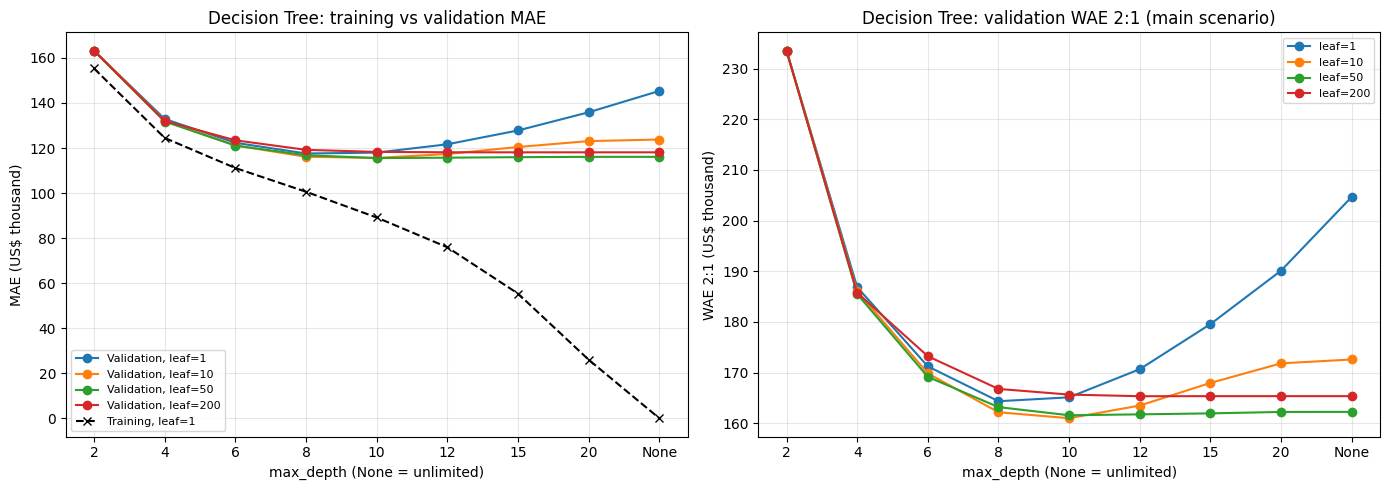

In [6]:
depth_labels = [str(depth) for depth in DT_GRID["max_depth"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for leaf in DT_GRID["min_samples_leaf"]:
    subset = dt_results.loc[dt_results["min_samples_leaf"] == leaf].set_index("max_depth").loc[depth_labels]
    axes[0].plot(depth_labels, subset["MAE"] / 1e3, marker="o", label=f"Validation, leaf={leaf}")
    axes[1].plot(depth_labels, subset["WAE_2_1"] / 1e3, marker="o", label=f"leaf={leaf}")
leaf1 = dt_results.loc[dt_results["min_samples_leaf"] == 1].set_index("max_depth").loc[depth_labels]
axes[0].plot(depth_labels, leaf1["train_MAE"] / 1e3, color="black", linestyle="--", marker="x", label="Training, leaf=1")
axes[0].set_title("Decision Tree: training vs validation MAE")
axes[0].set_ylabel("MAE (US$ thousand)")
axes[1].set_title("Decision Tree: validation WAE 2:1 (main scenario)")
axes[1].set_ylabel("WAE 2:1 (US$ thousand)")
for axis in axes:
    axis.set_xlabel("max_depth (None = unlimited)")
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "T1_decision_tree_complexity.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Random Forest

### 5a. Number of trees

The number of trees is not a complexity parameter in the usual sense: more trees reduce variance without increasing overfitting, but cost time. The forest is grown with `warm_start` and the smallest size whose validation MAE is within 0.5% of the best value on the path is used for the grid. Out-of-bag (OOB) error is shown alongside validation error; OOB error is a within-period estimate, so the gap between them indicates how much accuracy is lost when predicting a later period.

 n_estimators  validation_MAE  validation_WAE_2_1  OOB_MAE  incremental_fit_seconds
           25       102,873.9           142,286.6 99,346.3                      1.8
           50       101,750.3           140,708.8 96,406.6                      2.3
          100       101,374.9           140,037.3 95,148.2                      3.9
          200       101,033.0           139,497.4 94,456.4                      7.9
          300       100,971.6           139,412.4 94,257.0                      9.0

Selected n_estimators for the grid: 100


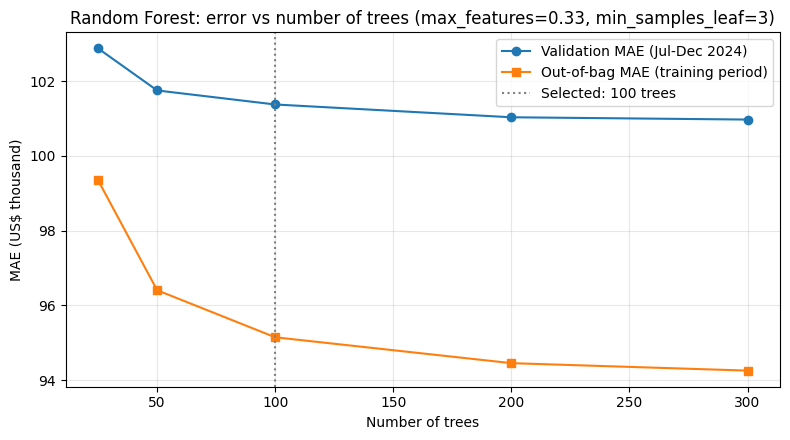

In [7]:
import warnings

path_rows = []
forest_path = RandomForestRegressor(
    n_estimators=RF_N_ESTIMATORS_PATH[0],
    warm_start=True,
    oob_score=True,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
    **RF_PATH_CONFIG,
)
for n_trees in RF_N_ESTIMATORS_PATH:
    forest_path.set_params(n_estimators=n_trees)
    start = time.perf_counter()
    with warnings.catch_warnings():
        # With 25 trees a handful of rows are never out of bag; they are excluded below.
        warnings.filterwarnings("ignore", message="Some inputs do not have OOB scores")
        forest_path.fit(X_train, y_train_fit)
    elapsed = time.perf_counter() - start
    oob_pred = to_dollars(forest_path.oob_prediction_)
    has_oob = forest_path.oob_prediction_ != 0          # rows never left out of bag are returned as 0
    val_pred = to_dollars(forest_path.predict(X_val))
    path_rows.append({
        "n_estimators": n_trees,
        "validation_MAE": mean_absolute_error(y_val, val_pred),
        "validation_WAE_2_1": weighted_absolute_error(y_val, val_pred, 2, 1),
        "OOB_MAE": mean_absolute_error(y_train[has_oob], oob_pred[has_oob]),
        "incremental_fit_seconds": elapsed,
    })
del forest_path
gc.collect()

rf_path = pd.DataFrame(path_rows)
best_path_mae = rf_path["validation_MAE"].min()
RF_N_ESTIMATORS = int(rf_path.loc[rf_path["validation_MAE"] <= 1.005 * best_path_mae, "n_estimators"].min())
rf_path.to_csv(OUT_DIR / "rf_n_estimators_path.csv", index=False)
print(rf_path.to_string(index=False, float_format=lambda v: f"{v:,.1f}"))
print(f"\nSelected n_estimators for the grid: {RF_N_ESTIMATORS}")

fig, axis = plt.subplots(figsize=(8, 4.5))
axis.plot(rf_path["n_estimators"], rf_path["validation_MAE"] / 1e3, marker="o", label="Validation MAE (Jul-Dec 2024)")
axis.plot(rf_path["n_estimators"], rf_path["OOB_MAE"] / 1e3, marker="s", label="Out-of-bag MAE (training period)")
axis.axvline(RF_N_ESTIMATORS, color="grey", linestyle=":", label=f"Selected: {RF_N_ESTIMATORS} trees")
axis.set_xlabel("Number of trees")
axis.set_ylabel("MAE (US$ thousand)")
axis.set_title(f"Random Forest: error vs number of trees ({configuration_text(RF_PATH_CONFIG)})")
axis.grid(alpha=0.3)
axis.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "T2_rf_n_estimators.png", dpi=150, bbox_inches="tight")
plt.show()

### 5b. Complexity grid

`min_samples_leaf` limits how finely each tree fits the training data (larger = simpler trees). `max_features` sets the share of predictors considered at each split; smaller values decorrelate the trees and add randomness. Each configuration is fitted once and scored under all three WAE scenarios with fixed predictions.

In [8]:
grid_start = time.perf_counter()
run_number = 0
for max_features in RF_GRID["max_features"]:
    for leaf in RF_GRID["min_samples_leaf"]:
        run_number += 1
        params = {"n_estimators": RF_N_ESTIMATORS, "max_features": max_features, "min_samples_leaf": leaf}
        start = time.perf_counter()
        forest = RandomForestRegressor(oob_score=True, random_state=RANDOM_STATE, n_jobs=N_JOBS, **params)
        forest.fit(X_train, y_train_fit)
        fit_seconds = time.perf_counter() - start
        has_oob = forest.oob_prediction_ != 0
        oob_mae = mean_absolute_error(y_train[has_oob], to_dollars(forest.oob_prediction_)[has_oob])
        row = record_run(f"R{run_number:03d}", "Random Forest", params, forest, fit_seconds, oob_mae)
        print(f"{row['run_id']} {row['configuration']}: val MAE {row['MAE']:,.0f}, "
              f"WAE 2:1 {row['WAE_2_1']:,.0f}, OOB MAE {oob_mae:,.0f} ({fit_seconds:.0f}s)")
        del forest
        gc.collect()

rf_results = pd.DataFrame([row for row in run_rows if row["model_family"] == "Random Forest"])
print(f"\nRandom Forest grid finished in {(time.perf_counter() - grid_start) / 60:.1f} minutes.")

R001 n_estimators=100, max_features=0.2, min_samples_leaf=1: val MAE 102,524, WAE 2:1 142,358, OOB MAE 96,130 (6s)
R002 n_estimators=100, max_features=0.2, min_samples_leaf=3: val MAE 101,091, WAE 2:1 139,391, OOB MAE 95,049 (5s)
R003 n_estimators=100, max_features=0.2, min_samples_leaf=10: val MAE 101,231, WAE 2:1 139,890, OOB MAE 94,789 (4s)
R004 n_estimators=100, max_features=0.2, min_samples_leaf=30: val MAE 103,695, WAE 2:1 143,375, OOB MAE 97,011 (3s)
R005 n_estimators=100, max_features=0.33, min_samples_leaf=1: val MAE 102,546, WAE 2:1 142,600, OOB MAE 96,367 (8s)
R006 n_estimators=100, max_features=0.33, min_samples_leaf=3: val MAE 101,375, WAE 2:1 140,037, OOB MAE 95,148 (6s)
R007 n_estimators=100, max_features=0.33, min_samples_leaf=10: val MAE 101,173, WAE 2:1 139,638, OOB MAE 94,441 (5s)
R008 n_estimators=100, max_features=0.33, min_samples_leaf=30: val MAE 103,209, WAE 2:1 142,698, OOB MAE 96,506 (4s)
R009 n_estimators=100, max_features=0.5, min_samples_leaf=1: val MAE 102

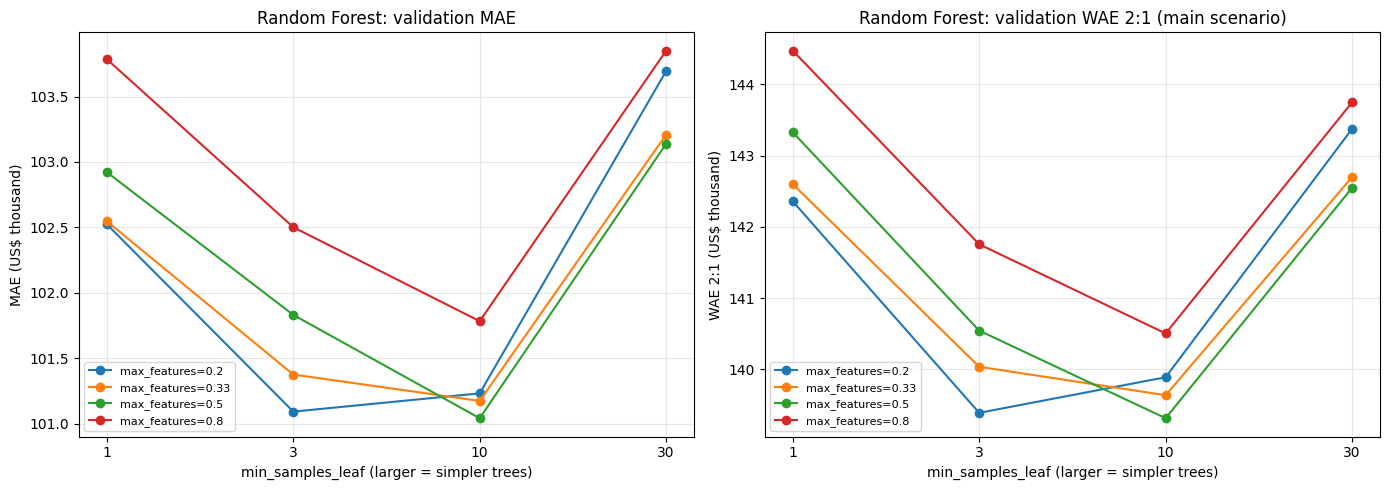

Training, out-of-bag and validation MAE (US$):
run_id                                            configuration  train_MAE  OOB_MAE  validation_MAE  validation_minus_OOB
  R001   n_estimators=100, max_features=0.2, min_samples_leaf=1     35,421   96,130         102,524                 6,393
  R002   n_estimators=100, max_features=0.2, min_samples_leaf=3     51,647   95,049         101,091                 6,042
  R003  n_estimators=100, max_features=0.2, min_samples_leaf=10     75,235   94,789         101,231                 6,441
  R004  n_estimators=100, max_features=0.2, min_samples_leaf=30     88,948   97,011         103,695                 6,684
  R005  n_estimators=100, max_features=0.33, min_samples_leaf=1     35,504   96,367         102,546                 6,180
  R006  n_estimators=100, max_features=0.33, min_samples_leaf=3     49,507   95,148         101,375                 6,227
  R007 n_estimators=100, max_features=0.33, min_samples_leaf=10     73,297   94,441         101,173

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for max_features in RF_GRID["max_features"]:
    subset = rf_results.loc[rf_results["max_features"] == max_features].sort_values("min_samples_leaf")
    leaf_labels = subset["min_samples_leaf"].astype(int).astype(str)
    axes[0].plot(leaf_labels, subset["MAE"] / 1e3, marker="o", label=f"max_features={max_features}")
    axes[1].plot(leaf_labels, subset["WAE_2_1"] / 1e3, marker="o", label=f"max_features={max_features}")
axes[0].set_title("Random Forest: validation MAE")
axes[0].set_ylabel("MAE (US$ thousand)")
axes[1].set_title("Random Forest: validation WAE 2:1 (main scenario)")
axes[1].set_ylabel("WAE 2:1 (US$ thousand)")
for axis in axes:
    axis.set_xlabel("min_samples_leaf (larger = simpler trees)")
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "T3_rf_complexity_grid.png", dpi=150, bbox_inches="tight")
plt.show()

gap_table = rf_results[["run_id", "configuration", "train_MAE", "OOB_MAE", "MAE"]].rename(
    columns={"MAE": "validation_MAE"}
)
gap_table["validation_minus_OOB"] = gap_table["validation_MAE"] - gap_table["OOB_MAE"]
print("Training, out-of-bag and validation MAE (US$):")
print(gap_table.to_string(index=False, float_format=lambda v: f"{v:,.0f}"))

## 6. Scenario-specific selection and the unified results table

Following the group convention, each model family is selected separately under each WAE scenario. The winner table uses the same columns and scenario labels as `data/result/linear_models/scenario_validation_winners.csv`. The pre-specified main scenario is WAE 2:1; the other two are sensitivity results. A supplementary table also lists each family's lowest-MSE configuration (the within-family rule used in the Boosting notebook), so the tree results can be merged under either selection rule.

In [10]:
all_runs = pd.DataFrame(run_rows)
all_runs.to_csv(OUT_DIR / "tree_validation_results_all_runs.csv", index=False)

winner_rows = []
for family in ["Decision Tree", "Random Forest"]:
    family_runs = all_runs.loc[all_runs["model_family"] == family]
    for metric, (scenario_name, _, _) in SCENARIOS.items():
        best = family_runs.loc[family_runs[metric].idxmin()]
        winner_rows.append({
            "model_family": family,
            "scenario": scenario_name,
            "winning_configuration": best["configuration"],
            "feature_set": best["feature_set"],
            "selected_WAE": best[metric],
            "MSE": best["MSE"],
            "R2": best["R2"],
            "MAE": best["MAE"],
            "run_id": best["run_id"],
        })
scenario_winners = pd.DataFrame(winner_rows)
scenario_winners.drop(columns="run_id").to_csv(OUT_DIR / "tree_scenario_validation_winners.csv", index=False)
print(scenario_winners.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))

# Supplementary: lowest validation MSE per family, scored under all three WAE scenarios with fixed predictions.
mse_champions = (
    all_runs.sort_values(["MSE", "run_id"])
    .drop_duplicates("model_family")
    [["model_family", "run_id", "configuration", "feature_set", "MSE", "R2", "MAE", "WAE_2_1", "WAE_1_1", "WAE_1_2"]]
    .reset_index(drop=True)
)
mse_champions.to_csv(OUT_DIR / "tree_mse_champions.csv", index=False)
print("\nSupplementary: lowest-MSE configuration per family")
print(mse_champions.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))

 model_family                                    scenario                                   winning_configuration                         feature_set  selected_WAE                 MSE     R2          MAE run_id
Decision Tree         Main - Overvaluation Priority (2:1)                       max_depth=10, min_samples_leaf=10 Official split CSV (209 predictors)  160,998.1234 59,195,005,840.2818 0.6896 115,601.4060   T018
Decision Tree          Alternative - Equal Priority (1:1)                       max_depth=10, min_samples_leaf=50 Official split CSV (209 predictors)  115,538.3875 61,896,057,811.3162 0.6755 115,538.3875   T019
Decision Tree Alternative - Undervaluation Priority (1:2)                       max_depth=10, min_samples_leaf=50 Official split CSV (209 predictors)  185,036.4453 61,896,057,811.3162 0.6755 115,538.3875   T019
Random Forest         Main - Overvaluation Priority (2:1) n_estimators=100, max_features=0.5, min_samples_leaf=10 Official split CSV (209 predictors)  139,3

### 6a. Fixed-prediction comparison under all three scenarios

For the configuration selected under the main 2:1 scenario, predictions are held fixed and scored under all three weightings against the Global Mean baseline (the format required for 4c).

In [11]:
main_winners = scenario_winners.loc[scenario_winners["scenario"] == SCENARIOS[MAIN_METRIC][0]]
fixed_rows = []
for _, winner in main_winners.iterrows():
    model_pred = validation_predictions[winner["run_id"]]
    for metric, (scenario_name, over_w, under_w) in SCENARIOS.items():
        model_wae = weighted_absolute_error(y_val, model_pred, over_w, under_w)
        baseline_wae = weighted_absolute_error(y_val, baseline_prediction, over_w, under_w)
        fixed_rows.append({
            "scenario": scenario_name,
            "model_family": winner["model_family"],
            "feature_set": winner["feature_set"],
            "configuration": winner["winning_configuration"],
            "model_WAE": model_wae,
            "baseline_WAE": baseline_wae,
            "reduction_percent": 100 * (1 - model_wae / baseline_wae),
        })
fixed_comparison = pd.DataFrame(fixed_rows)
fixed_comparison.to_csv(OUT_DIR / "tree_selected_model_fixed_scenario_comparison.csv", index=False)
print(fixed_comparison.to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

# Validation predictions of every scenario winner, keyed by transaction for later merging.
prediction_export = val_ids[["transaction_id", "property_id", "sale_date"]].copy()
prediction_export["actual_sale_price"] = y_val
for run_id in pd.unique(pd.concat([scenario_winners["run_id"], mse_champions["run_id"]])):
    prediction_export[f"pred_{run_id}"] = validation_predictions[run_id]
prediction_export.to_csv(OUT_DIR / "tree_validation_predictions.csv", index=False)
print("\nSaved scenario winners, fixed-scenario comparison and validation predictions to", OUT_DIR)

                                   scenario  model_family                         feature_set                                           configuration  model_WAE  baseline_WAE  reduction_percent
        Main - Overvaluation Priority (2:1) Decision Tree Official split CSV (209 predictors)                       max_depth=10, min_samples_leaf=10 160,998.12    342,381.82              52.98
         Alternative - Equal Priority (1:1) Decision Tree Official split CSV (209 predictors)                       max_depth=10, min_samples_leaf=10 115,601.41    238,599.62              51.55
Alternative - Undervaluation Priority (1:2) Decision Tree Official split CSV (209 predictors)                       max_depth=10, min_samples_leaf=10 185,806.09    373,417.03              50.24
        Main - Overvaluation Priority (2:1) Random Forest Official split CSV (209 predictors) n_estimators=100, max_features=0.5, min_samples_leaf=10 139,315.50    342,381.82              59.31
         Alternative - Equal P

### 6b. Prediction bias of every configuration

For every tree configuration, the systematic direction of the validation errors is summarised: mean signed error (predicted − actual), median estimate/price ratio and the share of sales overvalued, alongside RMSE, overall and by month. These columns are also used by the time-variable comparison in 6c.

In [12]:
VARIANT_LABEL = "B_month_index" if ADD_TIME_TREND else "A_no_time"
N_PREDICTORS = X_train.shape[1]
validation_month = val_ids["sale_date"].dt.strftime("%Y-%m").to_numpy()

bias_rows = []
monthly_bias_rows = []
for run_id, prediction in validation_predictions.items():
    error = prediction - y_val
    bias_rows.append({
        "run_id": run_id,
        "variant": VARIANT_LABEL,
        "n_predictors": N_PREDICTORS,
        "RMSE": float(np.sqrt(np.mean(error ** 2))),
        "mean_signed_error": float(error.mean()),
        "median_ratio": float(np.median(prediction / y_val)),
        "share_overvalued": float((error > 0).mean()),
    })
    for month in np.unique(validation_month):
        in_month = validation_month == month
        monthly_bias_rows.append({
            "run_id": run_id,
            "variant": VARIANT_LABEL,
            "sale_month": month,
            "sales": int(in_month.sum()),
            "mean_signed_error": float(error[in_month].mean()),
            "median_ratio": float(np.median(prediction[in_month] / y_val[in_month])),
            "MAE": float(np.abs(error[in_month]).mean()),
        })
bias_table = all_runs[["run_id", "model_family", "configuration", "MSE", "R2", "MAE", "WAE_2_1", "WAE_1_1", "WAE_1_2"]].merge(
    pd.DataFrame(bias_rows), on="run_id", how="left", validate="one_to_one"
)
bias_table.to_csv(OUT_DIR / "tree_validation_bias_all_runs.csv", index=False)
monthly_bias = pd.DataFrame(monthly_bias_rows)
monthly_bias.to_csv(OUT_DIR / "tree_validation_bias_by_month_all_runs.csv", index=False)
print(f"Variant: {VARIANT_LABEL} ({N_PREDICTORS} predictors)")
print("Bias summary of the scenario winners:")
print(bias_table.loc[bias_table["run_id"].isin(scenario_winners["run_id"])]
      .to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

Variant: A_no_time (209 predictors)
Bias summary of the scenario winners:
run_id  model_family                                           configuration                MSE    R2         MAE     WAE_2_1     WAE_1_1     WAE_1_2   variant  n_predictors        RMSE  mean_signed_error  median_ratio  share_overvalued
  T018 Decision Tree                       max_depth=10, min_samples_leaf=10 59,195,005,840.282 0.690 115,601.406 160,998.123 115,601.406 185,806.095 A_no_time           209 243,300.238        -24,807.971         0.946             0.422
  T019 Decision Tree                       max_depth=10, min_samples_leaf=50 61,896,057,811.316 0.675 115,538.388 161,578.717 115,538.388 185,036.445 A_no_time           209 248,789.183        -23,457.728         0.948             0.426
  R003 Random Forest n_estimators=100, max_features=0.2, min_samples_leaf=10 49,191,916,835.870 0.742 101,230.951 139,890.420 101,230.951 163,802.432 A_no_time           209 221,792.509        -23,912.012         0.

### 6c. Time-variable comparison for the tree models (Model A vs Model B)

Group plan: does adding one time variable, `months_since_2023_01` = (year − 2023) × 12 + (month − 1) taken from the membership sale dates, reduce the systematic underestimation, and does it change the selection under WAE 2:1?

- **Model A**: the 209 shared predictors (the results above).
- **Model B**: Model A plus `months_since_2023_01` (210 predictors). Everything else is identical: dollar target, seed, the same Decision Tree and Random Forest grids with the same `run_id`s, and the forest size selected in 5a.
- **Fixed hyperparameters**: Model A's selected configuration refitted with the time variable (the same `run_id` in Model B).
- **Retuned**: the configuration Model B selects from the same grid under the same rule.

Selection uses the main rule (lowest WAE 2:1) and, as a supplement, the lowest MSE. The pre-specified decision rule is applied to the change in WAE 2:1: a reduction of more than 1% adopts the time variable; MAE better but WAE 2:1 worse keeps A and the trade-off is reported; a change within 1% keeps A. Training months run from 0 to 17 and validation months from 18 to 23, so trees cannot extrapolate the trend: they can only treat the validation period like the latest training months.

Model B grid (52 configurations) finished in 3.1 minutes.
Time-variable comparison (validation, Jul-Dec 2024):
 model_family                    selected_by            comparison       variant                                           configuration         MAE     WAE_2_1  mean_signed_error  median_ratio  share_overvalued  WAE_2_1_change_pct_vs_A                                                    rule_outcome
Decision Tree      main rule: lowest WAE 2:1 fixed_hyperparameters     A_no_time                       max_depth=10, min_samples_leaf=10 115,601.406 160,998.123        -24,807.971         0.946             0.422                      NaN                                                                
Decision Tree      main rule: lowest WAE 2:1 fixed_hyperparameters B_month_index                       max_depth=10, min_samples_leaf=10 116,182.170 164,623.295        -19,299.920         0.961             0.444                    2.252                         Keep A: WAE 2:1 worsens by

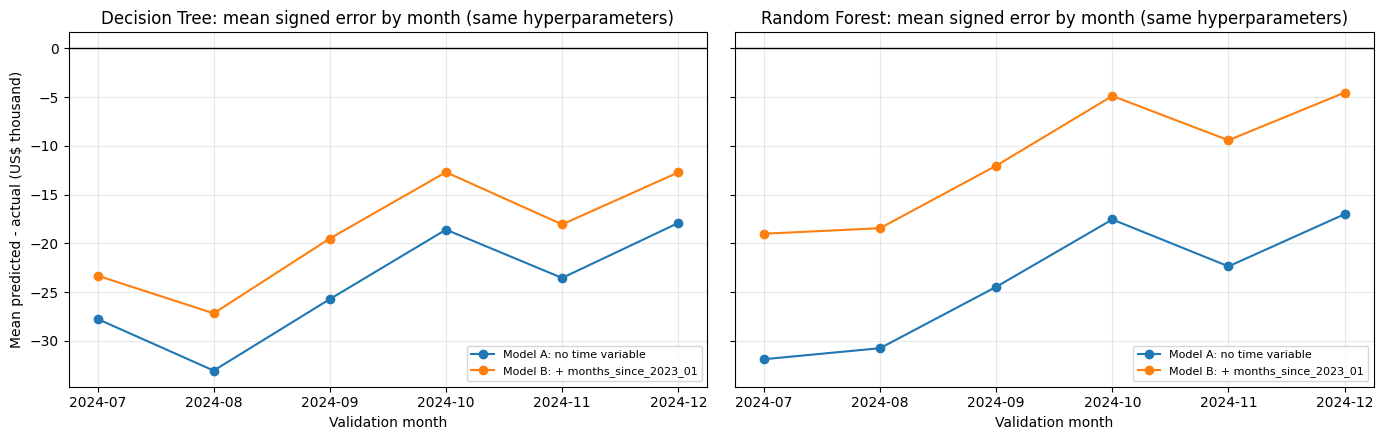

In [13]:
TIME_TREND_DIR = OUT_DIR / "time_trend"
TIME_TREND_DIR.mkdir(parents=True, exist_ok=True)
REQUIRED_COLUMNS = [
    "model_family", "variant", "comparison", "configuration", "n_predictors",
    "MSE", "RMSE", "R2", "MAE", "WAE_2_1", "WAE_1_1", "WAE_1_2",
    "mean_signed_error", "median_ratio", "share_overvalued",
]
SELECTION_RULES = {"WAE_2_1": "main rule: lowest WAE 2:1", "MSE": "supplementary rule: lowest MSE"}
assert not ADD_TIME_TREND, "Section 6c treats the main analysis as Model A, so ADD_TIME_TREND must stay False."


def months_since_2023_01(members):
    dates = members["sale_date"]
    return ((dates.dt.year - 2023) * 12 + dates.dt.month - 1).to_numpy()


X_train_B = X_train.assign(months_since_2023_01=months_since_2023_01(train_ids))
X_val_B = X_val.assign(months_since_2023_01=months_since_2023_01(val_ids))
assert X_train_B.shape[1] == X_train.shape[1] + 1 == N_PREDICTORS + 1
assert X_train_B["months_since_2023_01"].between(0, 17).all() and X_val_B["months_since_2023_01"].between(18, 23).all()


def score_variant(run_id, family, configuration, prediction, variant, n_predictors):
    error = prediction - y_val
    return {
        "run_id": run_id, "model_family": family, "configuration": configuration,
        "variant": variant, "n_predictors": n_predictors,
        **evaluate_regression_predictions(y_val, prediction),
        "RMSE": float(np.sqrt(np.mean(error ** 2))),
        "mean_signed_error": float(error.mean()),
        "median_ratio": float(np.median(prediction / y_val)),
        "share_overvalued": float((error > 0).mean()),
    }


# Model B: the same grids and run_ids as sections 4 and 5b, with the time variable added.
b_rows, b_predictions = [], {}
start = time.perf_counter()
run_number = 0
for depth in DT_GRID["max_depth"]:
    for leaf in DT_GRID["min_samples_leaf"]:
        run_number += 1
        run_id = f"T{run_number:03d}"
        params = {"max_depth": depth, "min_samples_leaf": leaf}
        tree = DecisionTreeRegressor(random_state=RANDOM_STATE, **params).fit(X_train_B, y_train_fit)
        b_predictions[run_id] = to_dollars(tree.predict(X_val_B))
        b_rows.append(score_variant(run_id, "Decision Tree", configuration_text(params), b_predictions[run_id],
                                    "B_month_index", X_train_B.shape[1]))
        del tree
run_number = 0
for max_features in RF_GRID["max_features"]:
    for leaf in RF_GRID["min_samples_leaf"]:
        run_number += 1
        run_id = f"R{run_number:03d}"
        params = {"n_estimators": RF_N_ESTIMATORS, "max_features": max_features, "min_samples_leaf": leaf}
        forest = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS, **params).fit(X_train_B, y_train_fit)
        b_predictions[run_id] = to_dollars(forest.predict(X_val_B))
        b_rows.append(score_variant(run_id, "Random Forest", configuration_text(params), b_predictions[run_id],
                                    "B_month_index", X_train_B.shape[1]))
        del forest
        gc.collect()
b_runs = pd.DataFrame(b_rows)
a_runs = bias_table.copy()
b_runs.to_csv(TIME_TREND_DIR / "model_B_validation_results_all_runs.csv", index=False)
print(f"Model B grid ({len(b_runs)} configurations) finished in {(time.perf_counter() - start) / 60:.1f} minutes.")

# The same run_id must mean the same hyperparameters in A and B.
check = a_runs[["run_id", "configuration"]].merge(b_runs[["run_id", "configuration"]], on="run_id",
                                                  suffixes=("_A", "_B"), validate="one_to_one")
assert len(check) == len(a_runs) == len(b_runs)
assert (check["configuration_A"] == check["configuration_B"]).all()


def rule_outcome(wae_change_pct, mae_change_pct):
    if wae_change_pct < -1:
        return "Adopt time variable: WAE 2:1 falls by more than 1%"
    if wae_change_pct > 0 and mae_change_pct < 0:
        return "Keep A: MAE improves but WAE 2:1 worsens (report the trade-off)"
    if abs(wae_change_pct) <= 1:
        return "Keep A: change within 1%"
    return "Keep A: WAE 2:1 worsens by more than 1%"


def select(runs, family, metric):
    family_runs = runs.loc[runs["model_family"] == family]
    return family_runs.loc[family_runs[metric].idxmin()]


comparison_rows, monthly_rows = [], []
validation_month = val_ids["sale_date"].dt.strftime("%Y-%m").to_numpy()
for family in ["Decision Tree", "Random Forest"]:
    for metric, rule in SELECTION_RULES.items():
        a_choice = select(a_runs, family, metric)
        b_fixed = b_runs.loc[b_runs["run_id"] == a_choice["run_id"]].iloc[0]
        b_retuned = select(b_runs, family, metric)
        for comparison, b_row in [("fixed_hyperparameters", b_fixed), ("retuned", b_retuned)]:
            wae_change = 100 * (b_row["WAE_2_1"] / a_choice["WAE_2_1"] - 1)
            mae_change = 100 * (b_row["MAE"] / a_choice["MAE"] - 1)
            for row, is_b in [(a_choice, False), (b_row, True)]:
                record = {column: row[column] for column in REQUIRED_COLUMNS if column != "comparison"}
                record.update({
                    "comparison": comparison, "run_id": row["run_id"], "selected_by": rule,
                    "WAE_2_1_change_pct_vs_A": wae_change if is_b else np.nan,
                    "MAE_change_pct_vs_A": mae_change if is_b else np.nan,
                    "rule_outcome": rule_outcome(wae_change, mae_change) if is_b else "",
                })
                comparison_rows.append(record)
                prediction = b_predictions[row["run_id"]] if is_b else validation_predictions[row["run_id"]]
                error = prediction - y_val
                for month in np.unique(validation_month):
                    in_month = validation_month == month
                    monthly_rows.append({
                        "model_family": family, "selected_by": rule, "comparison": comparison,
                        "variant": row["variant"], "configuration": row["configuration"], "sale_month": month,
                        "sales": int(in_month.sum()), "mean_signed_error": float(error[in_month].mean()),
                        "median_ratio": float(np.median(prediction[in_month] / y_val[in_month])),
                        "MAE": float(np.abs(error[in_month]).mean()),
                    })

extra_columns = ["run_id", "selected_by", "WAE_2_1_change_pct_vs_A", "MAE_change_pct_vs_A", "rule_outcome"]
time_trend_table = pd.DataFrame(comparison_rows)[REQUIRED_COLUMNS + extra_columns]
time_trend_monthly = pd.DataFrame(monthly_rows)
time_trend_table.to_csv(TIME_TREND_DIR / "tree_time_trend_comparison.csv", index=False)
time_trend_monthly.to_csv(TIME_TREND_DIR / "tree_time_trend_monthly_bias.csv", index=False)
shared_inputs = DATA_DIR / "result" / "time_trend_comparison" / "inputs"
shared_inputs.mkdir(parents=True, exist_ok=True)
time_trend_table.to_csv(shared_inputs / "M3_trees_time_trend.csv", index=False)   # copy for the group summary

show = ["model_family", "selected_by", "comparison", "variant", "configuration", "MAE", "WAE_2_1",
        "mean_signed_error", "median_ratio", "share_overvalued", "WAE_2_1_change_pct_vs_A", "rule_outcome"]
print("Time-variable comparison (validation, Jul-Dec 2024):")
print(time_trend_table[show].to_string(index=False, float_format=lambda v: f"{v:,.3f}"))
main_monthly = time_trend_monthly.loc[time_trend_monthly["selected_by"] == SELECTION_RULES["WAE_2_1"]]
print("\nMonthly mean signed error (predicted - actual), main-rule configurations:")
print(main_monthly.drop_duplicates(["model_family", "comparison", "variant", "sale_month"])
      .pivot_table(index=["model_family", "comparison", "variant"], columns="sale_month", values="mean_signed_error")
      .to_string(float_format=lambda v: f"{v:,.0f}"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for axis, family in zip(axes, ["Decision Tree", "Random Forest"]):
    subset = main_monthly.loc[(main_monthly["model_family"] == family)
                              & (main_monthly["comparison"] == "fixed_hyperparameters")]
    for variant, label in [("A_no_time", "Model A: no time variable"), ("B_month_index", "Model B: + months_since_2023_01")]:
        line = subset.loc[subset["variant"] == variant].sort_values("sale_month")
        axis.plot(line["sale_month"], line["mean_signed_error"] / 1e3, marker="o", label=label)
    axis.axhline(0, color="black", linewidth=1)
    axis.set_title(f"{family}: mean signed error by month (same hyperparameters)")
    axis.set_xlabel("Validation month")
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)
axes[0].set_ylabel("Mean predicted - actual (US$ thousand)")
plt.tight_layout()
fig.savefig(FIG_DIR / "T7_time_variable_monthly_bias.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Validation diagnostics for the main-scenario Random Forest

The selected forest is refitted once (same seed, identical predictions) to inspect feature importance and the structure of its errors. These diagnostics use validation data only and prepare the arguments for 4a and 4b; the final numbers in 4a come from the frozen final model on the 2025 test set (section 13).

Selected Random Forest (WAE 2:1): n_estimators=100, max_features=0.5, min_samples_leaf=10
                                            impurity_importance  permutation_MAE_increase  permutation_std
char_bldg_sf                                             0.1496               37,636.7825         574.6364
meta_nbhd_code_te                                        0.0744               15,541.4808         376.9514
loc_school_secondary_district_geoid_te                   0.1664                6,205.9763         221.2095
inter_log1p_land_bldg_product                            0.0280                5,416.0000         166.7294
loc_property_zip_te                                      0.1450                4,531.6151         125.3568
loc_census_tract_geoid_te                                0.0311                2,795.0047         191.1424
char_yrblt                                               0.0125                2,421.2634         124.8282
char_fbath                                            

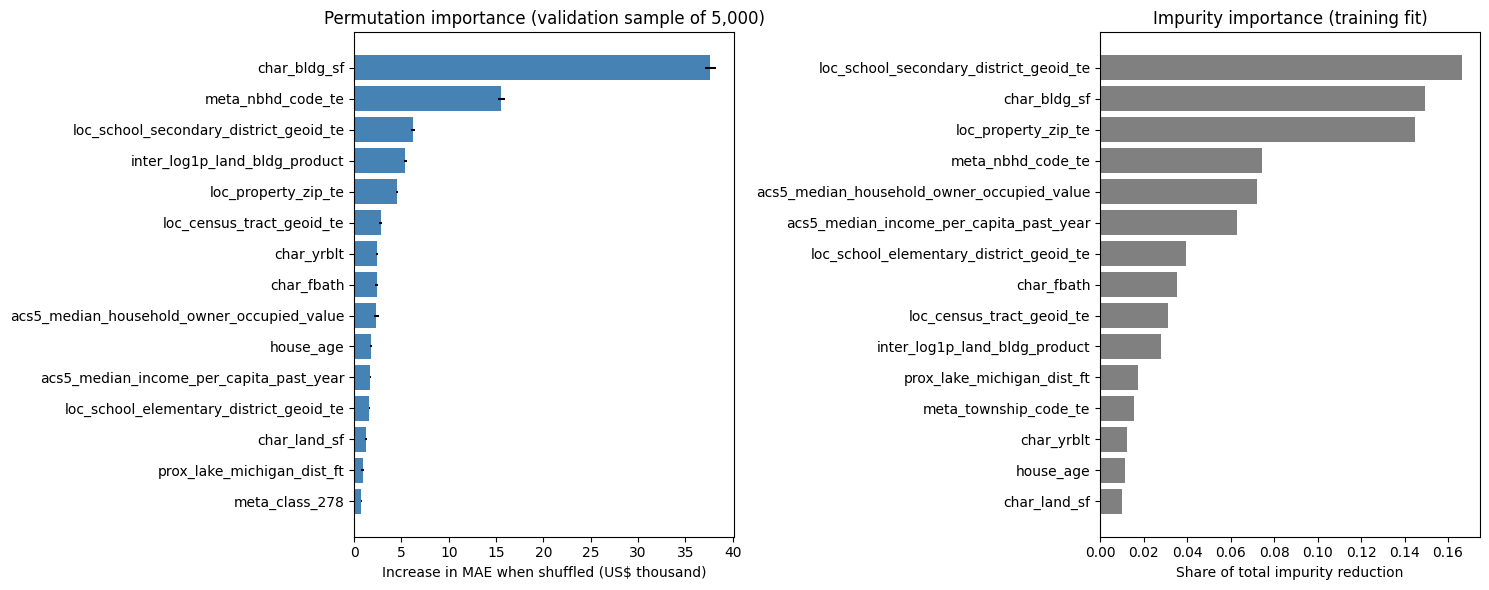

In [14]:
selected_rf = main_winners.loc[main_winners["model_family"] == "Random Forest"].iloc[0]
selected_row = all_runs.loc[all_runs["run_id"] == selected_rf["run_id"]].iloc[0]
SELECTED_RF_PARAMS = {
    "n_estimators": int(selected_row["n_estimators"]),
    "max_features": float(selected_row["max_features"]),
    "min_samples_leaf": int(selected_row["min_samples_leaf"]),
}
print(f"Selected Random Forest (WAE 2:1): {configuration_text(SELECTED_RF_PARAMS)}")

selected_forest = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS, **SELECTED_RF_PARAMS)
selected_forest.fit(X_train, y_train_fit)
rf_val_pred = to_dollars(selected_forest.predict(X_val))
assert np.allclose(rf_val_pred, validation_predictions[selected_rf["run_id"]])

impurity = pd.Series(selected_forest.feature_importances_, index=X_train.columns, name="impurity_importance")


def dollar_mae_scorer(estimator, features, target_fit_scale):
    return -mean_absolute_error(to_dollars(target_fit_scale), to_dollars(estimator.predict(features)))


sample_index = val_raw.sample(n=min(PERMUTATION_SAMPLE, len(val_raw)), random_state=RANDOM_STATE).index
permutation = permutation_importance(
    selected_forest,
    X_val.loc[sample_index],
    to_fit_scale(y_val[sample_index]),
    scoring=dollar_mae_scorer,
    n_repeats=PERMUTATION_REPEATS,
    random_state=RANDOM_STATE,
    n_jobs=1,
)
importance = pd.DataFrame({
    "impurity_importance": impurity,
    "permutation_MAE_increase": permutation.importances_mean,
    "permutation_std": permutation.importances_std,
}).sort_values("permutation_MAE_increase", ascending=False)
importance.to_csv(OUT_DIR / "rf_feature_importance.csv", index_label="feature")
print(importance.head(15).to_string(float_format=lambda v: f"{v:,.4f}"))

top = importance.head(15).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(top.index, top["permutation_MAE_increase"] / 1e3, xerr=top["permutation_std"] / 1e3, color="steelblue")
axes[0].set_title(f"Permutation importance (validation sample of {len(sample_index):,})")
axes[0].set_xlabel("Increase in MAE when shuffled (US$ thousand)")
top_impurity = impurity.sort_values().tail(15)
axes[1].barh(top_impurity.index, top_impurity.values, color="grey")
axes[1].set_title("Impurity importance (training fit)")
axes[1].set_xlabel("Share of total impurity reduction")
plt.tight_layout()
fig.savefig(FIG_DIR / "T4_rf_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
township_lookup = pd.read_csv(
    DATA_DIR / "properties_2022.csv",
    usecols=["property_id", "meta_township_code"],
    dtype={"property_id": str, "meta_township_code": str},
)
diagnostics = val_ids.merge(township_lookup, on="property_id", how="left", validate="many_to_one")
assert len(diagnostics) == len(val_ids) and diagnostics["meta_township_code"].notna().all()
diagnostics["actual"] = y_val
diagnostics["predicted"] = rf_val_pred
diagnostics["error"] = diagnostics["predicted"] - diagnostics["actual"]
diagnostics["ratio"] = diagnostics["predicted"] / diagnostics["actual"]
diagnostics["abs_pct_error"] = diagnostics["error"].abs() / diagnostics["actual"]
diagnostics["seen_in_training"] = diagnostics["property_id"].isin(set(train_ids["property_id"]))
diagnostics["price_decile"] = pd.qcut(diagnostics["actual"], 10, labels=[f"D{i}" for i in range(1, 11)])
diagnostics["sale_month"] = diagnostics["sale_date"].dt.strftime("%Y-%m")


def group_summary(frame, by):
    grouped = frame.groupby(by, observed=True)
    return pd.DataFrame({
        "sales": grouped.size(),
        "median_price": grouped["actual"].median(),
        "MAE": grouped["error"].apply(lambda e: e.abs().mean()),
        "median_APE": grouped["abs_pct_error"].median(),
        "mean_signed_error": grouped["error"].mean(),
        "median_ratio": grouped["ratio"].median(),
        "share_overvalued": grouped["error"].apply(lambda e: (e > 0).mean()),
    })


overall_ratio = pd.DataFrame({
    "Random Forest": assessment_ratio_statistics(y_val, rf_val_pred),
    "Global Mean": assessment_ratio_statistics(y_val, baseline_prediction),
}).T
print("Assessment-ratio statistics (ratio = estimate / sale price; IAAO guide for single-family: COD 5-15, PRD 0.98-1.03):")
print(overall_ratio.to_string(float_format=lambda v: f"{v:,.3f}"))

by_decile = group_summary(diagnostics, "price_decile")
by_month = group_summary(diagnostics, "sale_month")
by_seen = group_summary(diagnostics, "seen_in_training")
by_township = group_summary(diagnostics, "meta_township_code").sort_values("sales", ascending=False)
for name, table in [("price decile", by_decile), ("sale month", by_month),
                    ("property seen in training", by_seen), ("township (10 largest)", by_township.head(10))]:
    print(f"\nErrors by {name}:")
    print(table.to_string(float_format=lambda v: f"{v:,.3f}"))

by_decile.to_csv(OUT_DIR / "rf_validation_errors_by_price_decile.csv")
by_month.to_csv(OUT_DIR / "rf_validation_errors_by_month.csv")
by_seen.to_csv(OUT_DIR / "rf_validation_errors_by_seen_status.csv")
by_township.to_csv(OUT_DIR / "rf_validation_errors_by_township.csv")
overall_ratio.to_csv(OUT_DIR / "rf_validation_ratio_statistics.csv")

Assessment-ratio statistics (ratio = estimate / sale price; IAAO guide for single-family: COD 5-15, PRD 0.98-1.03):
               median_ratio    COD   PRD
Random Forest         0.950 33.056 1.162
Global Mean           1.199 73.971 1.793

Errors by price decile:
              sales  median_price         MAE  median_APE  mean_signed_error  median_ratio  share_overvalued
price_decile                                                                                                
D1             1822    94,440.000  77,476.947       0.765         75,294.197         1.765             0.935
D2             1807   175,000.000  58,260.353       0.251         28,815.160         1.088             0.583
D3             1824   240,000.000  59,298.780       0.199            527.678         0.961             0.446
D4             1888   285,000.000  59,802.870       0.154         -9,567.402         0.934             0.363
D5             1743   325,000.000  61,610.583       0.143        -19,142.475      

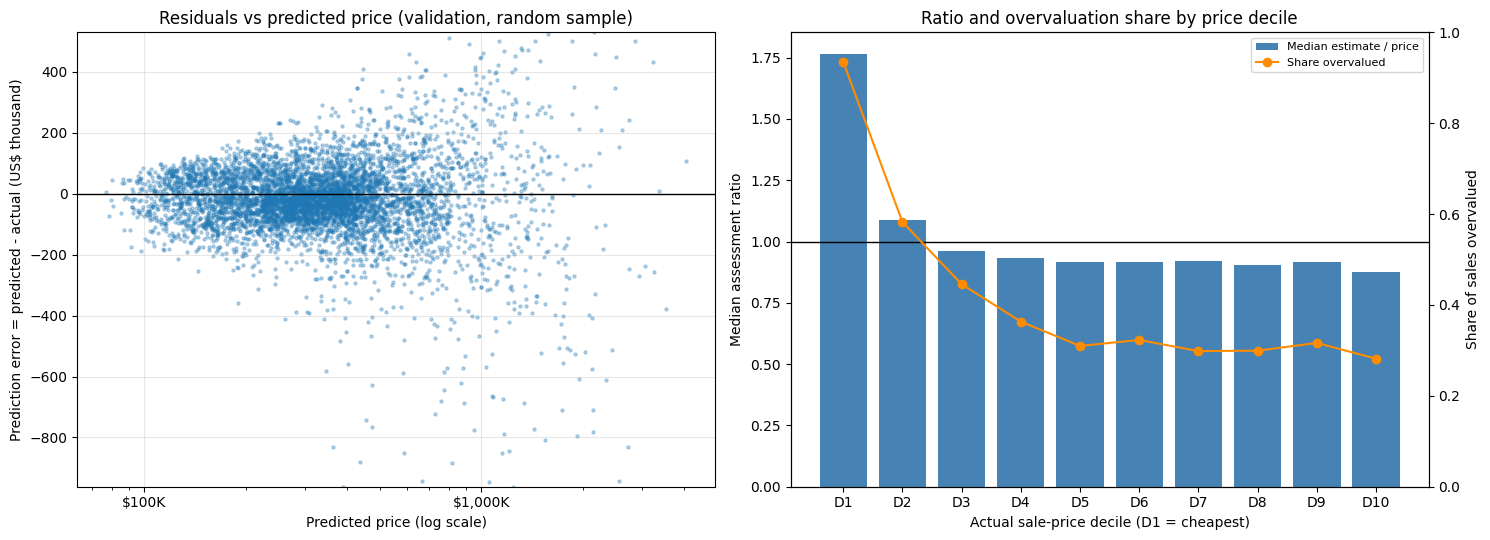

In [16]:
plot_sample = diagnostics.sample(n=min(6000, len(diagnostics)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].scatter(plot_sample["predicted"], plot_sample["error"] / 1e3, s=5, alpha=0.3)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_xscale("log")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v / 1e3:,.0f}K"))
axes[0].set_xlabel("Predicted price (log scale)")
axes[0].set_ylabel("Prediction error = predicted - actual (US$ thousand)")
axes[0].set_title("Residuals vs predicted price (validation, random sample)")
axes[0].set_ylim(np.percentile(plot_sample["error"] / 1e3, [0.5, 99.5]))
axes[0].grid(alpha=0.3)

decile_positions = np.arange(len(by_decile))
axes[1].bar(decile_positions, by_decile["median_ratio"], color="steelblue", label="Median estimate / price")
axes[1].axhline(1, color="black", linewidth=1)
axes[1].set_xticks(decile_positions)
axes[1].set_xticklabels(by_decile.index)
axes[1].set_xlabel("Actual sale-price decile (D1 = cheapest)")
axes[1].set_ylabel("Median assessment ratio")
twin = axes[1].twinx()
twin.plot(decile_positions, by_decile["share_overvalued"], color="darkorange", marker="o", label="Share overvalued")
twin.set_ylabel("Share of sales overvalued")
twin.set_ylim(0, 1)
axes[1].set_title("Ratio and overvaluation share by price decile")
lines = axes[1].get_legend_handles_labels()[0] + twin.get_legend_handles_labels()[0]
labels = axes[1].get_legend_handles_labels()[1] + twin.get_legend_handles_labels()[1]
axes[1].legend(lines, labels, loc="upper right", fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "T5_rf_validation_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

# Part B — Boosting (M4)

## 8. Boosting family comparison

All Boosting candidates use the same 209 shared predictors (Model A) and the same training and validation rows as Part A. The training-validation split, metric definitions and selection rules are those of the M4 notebook: positive prediction minus actual price is overvaluation, all three WAE values divide by the number of transactions, and predictions are evaluated in dollars after the inverse transformation for log1p targets. The test set is not read in this part.

In [17]:
# Boosting uses exactly the same predictors and rows as the tree models (Model A).
assert not ADD_TIME_TREND and not DROP_COLS, "Part B uses the 209 shared predictors without a time variable."
X_train_A, X_valid_A = X_train, X_val
y_valid = y_val
FEATURES = X_train.columns.tolist()
assert len(FEATURES) == 209 and not {"transaction_id", "property_id"} & set(FEATURES)
validation_ids = val_ids["transaction_id"].astype(str).to_numpy()
validation_dates = val_ids["sale_date"]
PRIMARY_METRIC = MAIN_METRIC
print("Train", X_train_A.shape, "Validation", X_valid_A.shape)

Train (54853, 209) Validation (18132, 209)


### 8a. LightGBM: WAE-driven Optuna search

The search uses 24 trials (TPE sampler, seed 6810; the first two trials are a fixed raw-target and a fixed log1p-target baseline). The target scale is part of the search. Each trial uses early stopping on validation dollar WAE 2:1 (100 rounds, at most 1,400 trees), and the stopping round becomes the frozen tree count of that candidate.

In [18]:
def lgb_model(params, rounds=MAX_BOOST_ROUNDS):
    return lgb.LGBMRegressor(objective='regression', metric='None', n_estimators=rounds,
        random_state=SEED, n_jobs=N_THREADS, verbosity=-1, deterministic=True,
        force_col_wise=True, **params)

def search_lightgbm(X_train, X_valid, variant):
    records, predictions, histories = [], {}, {}
    def objective(trial):
        target = trial.suggest_categorical('target', ['raw', 'log1p'])
        depth = trial.suggest_categorical('max_depth', [4, 6, 8, -1])
        leaves = trial.suggest_int('num_leaves', 8, 48)
        if depth > 0:
            leaves = min(leaves, 2 ** depth)
        params = dict(max_depth=depth, num_leaves=leaves,
            learning_rate=trial.suggest_float('learning_rate', .025, .15, log=True),
            min_child_samples=trial.suggest_int('min_child_samples', 30, 180),
            subsample=trial.suggest_float('subsample', .7, 1.), subsample_freq=1,
            colsample_bytree=trial.suggest_float('colsample_bytree', .65, 1.),
            reg_alpha=trial.suggest_float('reg_alpha', 1e-5, 10., log=True),
            reg_lambda=trial.suggest_float('reg_lambda', .01, 100., log=True))
        train_target = np.log1p(y_train) if target == 'log1p' else y_train
        valid_target = np.log1p(y_valid) if target == 'log1p' else y_valid
        model = lgb_model(params)
        history = {}
        def dollar_wae_2_1(eval_target, eval_prediction):
            actual = np.expm1(eval_target) if target == 'log1p' else eval_target
            prediction = dollars(eval_prediction, target)
            error = prediction - actual
            return 'dollar_WAE_2_1', float(np.mean(np.abs(error) * np.where(error > 0, 2., 1.))), False
        start = time.time()
        model.fit(X_train, train_target,
            eval_set=[(X_valid, valid_target)], eval_names=['validation'],
            eval_metric=dollar_wae_2_1,
            callbacks=[lgb.early_stopping(EARLY_STOPPING_ROUNDS, first_metric_only=True, verbose=False),
                       lgb.record_evaluation(history)])
        rounds = int(model.best_iteration_ or MAX_BOOST_ROUNDS)
        prediction = dollars(model.predict(X_valid, num_iteration=rounds), target)
        candidate_id = ('C' if variant == 'A_no_time' else 'T') + f'{trial.number + 1:03d}'
        row = dict(candidate_id=candidate_id, model_family='LightGBM', variant=variant,
            feature_set=variant, target=target, configuration=f'{candidate_id} ({target}, {rounds} trees)',
            params=json.dumps(params, sort_keys=True), n_estimators=rounds,
            n_predictors=X_train.shape[1], elapsed_seconds=time.time() - start,
            **boosting_metrics(y_valid, prediction))
        records.append(row)
        predictions[candidate_id] = prediction
        histories[candidate_id] = history
        trial.set_user_attr('candidate_id', candidate_id)
        trial.set_user_attr('best_iteration', rounds)
        print(variant, candidate_id, 'WAE 2:1', f'{row[PRIMARY_METRIC]:,.2f}', 'trees', rounds, flush=True)
        return row[PRIMARY_METRIC]
    study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=8))
    base = dict(max_depth=6, num_leaves=31, learning_rate=.05, min_child_samples=60,
                subsample=.9, colsample_bytree=.9, reg_alpha=.01, reg_lambda=1.)
    study.enqueue_trial(dict(target='raw', **base))
    study.enqueue_trial(dict(target='log1p', **base))
    study.optimize(objective, n_trials=N_LGB_TRIALS, n_jobs=1, show_progress_bar=False)
    return pd.DataFrame(records), predictions, histories, study

optuna.logging.set_verbosity(optuna.logging.WARNING)
A_trials, A_predictions, A_histories, A_study = search_lightgbm(X_train_A, X_valid_A, 'A_no_time')
A_trials.to_csv(BOOST_OUT / 'lightgbm_A_validation_trials.csv', index=False)
A_study.trials_dataframe().to_csv(BOOST_OUT / 'lightgbm_A_optuna_trials.csv', index=False)
A_winner = A_trials.sort_values([PRIMARY_METRIC, 'candidate_id']).iloc[0]
print('A LightGBM WAE 2:1 winner:', A_winner['configuration'])

C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


A_no_time C001 WAE 2:1 132,800.10 trees 852


C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


A_no_time C002 WAE 2:1 127,653.43 trees 742


C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


A_no_time C003 WAE 2:1 134,577.36 trees 1383


... (38 outputs left out)

C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


A_no_time C023 WAE 2:1 127,139.44 trees 851


C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


A_no_time C024 WAE 2:1 127,226.38 trees 1091
A LightGBM WAE 2:1 winner: C020 (log1p, 912 trees)


### 8b. Histogram Gradient Boosting

Histogram Boosting keeps its six pre-specified configurations (three settings × raw and log1p targets).

In [19]:
hist_records, hist_predictions = [], {}
hist_grid = [(200,.05,15), (400,.05,31), (400,.1,15)]
for target in ['raw', 'log1p']:
    for rounds, rate, leaves in hist_grid:
        params = dict(max_iter=rounds, learning_rate=rate, max_leaf_nodes=leaves,
                      min_samples_leaf=50, l2_regularization=10.)
        model = HistGradientBoostingRegressor(random_state=SEED, early_stopping=False, **params)
        train_target = np.log1p(y_train) if target == 'log1p' else y_train
        start = time.time()
        model.fit(X_train_A, train_target)
        prediction = dollars(model.predict(X_valid_A), target)
        candidate_id = f'H{len(hist_records) + 1:03d}'
        row = dict(candidate_id=candidate_id, model_family='HistGradientBoosting', variant='A_no_time',
            feature_set='A_no_time', target=target,
            configuration=f'{candidate_id} ({target}, {rounds} trees)',
            params=json.dumps(params, sort_keys=True), n_estimators=rounds,
            n_predictors=len(FEATURES), elapsed_seconds=time.time() - start,
            **boosting_metrics(y_valid, prediction))
        hist_records.append(row)
        hist_predictions[candidate_id] = prediction
        print('HistBoost', candidate_id, 'WAE 2:1', f'{row[PRIMARY_METRIC]:,.2f}', flush=True)
Hist_trials = pd.DataFrame(hist_records)
Hist_trials.to_csv(BOOST_OUT / 'histboost_validation_candidates.csv', index=False)
all_candidates = pd.concat([A_trials, Hist_trials], ignore_index=True)
all_candidates.to_csv(BOOST_OUT / 'M4_boosting_candidates.csv', index=False)

HistBoost H001 WAE 2:1 141,114.94
HistBoost H002 WAE 2:1 135,248.25
HistBoost H003 WAE 2:1 136,164.60
HistBoost H004 WAE 2:1 131,733.01
HistBoost H005 WAE 2:1 129,256.11
HistBoost H006 WAE 2:1 129,551.53


### 8c. XGBoost and CatBoost

Following the course examples, use `XGBRegressor` and `CatBoostRegressor` on the shared Train and Validation splits. For each family, fit three fixed settings with raw and log1p targets (six candidates). Models train on Train only. We evaluate predictions in dollars and select directly by validation WAE 2:1, 1:1, or 1:2; fixed tree counts and no early stopping keep the candidate search rule independent of the libraries' default RMSE evaluation. This is a six-candidate comparison per added family, not a 24-trial Optuna search. Test is not read.

In [20]:
# Course-inspired XGBRegressor and CatBoostRegressor; all candidates use the shared A features.
# Keep candidate grids small and explicit, matching HistBoost's six-candidate budget.
xgb_grid = [(400, .05, 4), (600, .05, 6), (800, .03, 6)]
cat_grid = [(400, .05, 6), (600, .05, 6), (800, .03, 8)]
xgb_records, cat_records = [], []
xgb_predictions, cat_predictions = {}, {}
for family, grid, records, predictions, prefix in [
    ('XGBoost', xgb_grid, xgb_records, xgb_predictions, 'X'),
    ('CatBoost', cat_grid, cat_records, cat_predictions, 'K'),
]:
    for target in ['raw', 'log1p']:
        train_target = np.log1p(y_train) if target == 'log1p' else y_train
        for rounds, rate, depth in grid:
            if family == 'XGBoost':
                params = dict(n_estimators=rounds, learning_rate=rate, max_depth=depth,
                              subsample=.9, colsample_bytree=.9, reg_alpha=.01,
                              reg_lambda=1., min_child_weight=5, tree_method='hist')
                model = xgb.XGBRegressor(objective='reg:squarederror', random_state=SEED,
                                         n_jobs=N_THREADS, verbosity=0, **params)
            else:
                params = dict(iterations=rounds, learning_rate=rate, depth=depth,
                              l2_leaf_reg=3., bootstrap_type='Bernoulli', subsample=.9,
                              rsm=.9)
                model = CatBoostRegressor(loss_function='RMSE', random_seed=SEED,
                                          thread_count=N_THREADS, verbose=False,
                                          allow_writing_files=False, **params)
            start = time.time()
            model.fit(X_train_A, train_target)
            prediction = dollars(model.predict(X_valid_A), target)
            candidate_id = f'{prefix}{len(records) + 1:03d}'
            row = dict(candidate_id=candidate_id, model_family=family, variant='A_no_time',
                       feature_set='A_no_time', target=target,
                       configuration=f'{candidate_id} ({target}, {rounds} trees)',
                       params=json.dumps(params, sort_keys=True), n_estimators=rounds,
                       n_predictors=len(FEATURES), elapsed_seconds=time.time() - start,
                       **boosting_metrics(y_valid, prediction))
            records.append(row)
            predictions[candidate_id] = prediction
            print(family, candidate_id, 'WAE 2:1', f"{row[PRIMARY_METRIC]:,.2f}", flush=True)
XGB_trials = pd.DataFrame(xgb_records)
Cat_trials = pd.DataFrame(cat_records)
XGB_trials.to_csv(BOOST_OUT / 'xgboost_validation_candidates.csv', index=False)
Cat_trials.to_csv(BOOST_OUT / 'catboost_validation_candidates.csv', index=False)
all_candidates = pd.concat([A_trials, Hist_trials, XGB_trials, Cat_trials], ignore_index=True)
assert all_candidates['candidate_id'].is_unique
all_candidates.to_csv(BOOST_OUT / 'M4_boosting_candidates.csv', index=False)
all_predictions = {**A_predictions, **hist_predictions, **xgb_predictions, **cat_predictions}

XGBoost X001 WAE 2:1 137,743.04
XGBoost X002 WAE 2:1 134,049.54
XGBoost X003 WAE 2:1 133,627.69
XGBoost X004 WAE 2:1 129,069.95
XGBoost X005 WAE 2:1 127,334.69
XGBoost X006 WAE 2:1 127,037.32
CatBoost K001 WAE 2:1 137,804.15
CatBoost K002 WAE 2:1 135,909.62
CatBoost K003 WAE 2:1 134,673.86
CatBoost K004 WAE 2:1 128,851.57
CatBoost K005 WAE 2:1 127,513.39
CatBoost K006 WAE 2:1 127,094.44


## 9. Boosting: scenario-specific selection and fixed prediction comparison

All four families select their own best configuration separately for the three validation WAE scenarios. The main scenario then selects one Boosting model for the fixed prediction comparison with the training mean baseline. The MSE champion table is supplementary.

In [21]:
scenario_rows = []
for family, group in all_candidates.groupby('model_family', sort=True):
    for metric, (scenario, _, _) in SCENARIOS.items():
        winner = group.sort_values([metric, 'candidate_id']).iloc[0]
        scenario_rows.append(dict(model_family=family, scenario=scenario,
            winning_configuration=winner['configuration'], feature_set='A_no_time',
            selected_WAE=winner[metric], MSE=winner['MSE'], R2=winner['R2'], MAE=winner['MAE']))
scenario_columns = ['model_family','scenario','winning_configuration','feature_set','selected_WAE','MSE','R2','MAE']
boost_scenario_winners = pd.DataFrame(scenario_rows)[scenario_columns]
boost_scenario_winners.to_csv(BOOST_OUT / 'scenario_validation_winners.csv', index=False)
boost_mse_champions = all_candidates.sort_values(['MSE','candidate_id']).drop_duplicates('model_family')
boost_mse_champions.to_csv(BOOST_OUT / 'MSE_champions_supplement.csv', index=False)
primary_winner = all_candidates.sort_values([PRIMARY_METRIC,'candidate_id']).iloc[0]
primary_id = primary_winner['candidate_id']
primary_prediction = all_predictions[primary_id]
mean_prediction = np.full(len(y_valid), y_train.mean())
fixed_4c = []
for metric, (scenario, _, _) in SCENARIOS.items():
    model_score = boosting_metrics(y_valid, primary_prediction)[metric]
    baseline_score = boosting_metrics(y_valid, mean_prediction)[metric]
    fixed_4c.append(dict(scenario=scenario, model_family=primary_winner['model_family'],
        winning_configuration=primary_winner['configuration'], selected_WAE=model_score,
        baseline_WAE=baseline_score, reduction_pct=100 * (1 - model_score / baseline_score)))
pd.DataFrame(fixed_4c).to_csv(BOOST_OUT / '4c_fixed_prediction_comparison.csv', index=False)
selected_ids = set()
for _, family_candidates in all_candidates.groupby('model_family'):
    for metric in SCENARIOS:
        selected_ids.add(family_candidates.sort_values([metric, 'candidate_id']).iloc[0]['candidate_id'])
selected_ids = sorted(selected_ids)
boost_prediction_export = pd.DataFrame({'transaction_id':validation_ids, 'actual_sale_price':y_valid})
for candidate_id in selected_ids:
    boost_prediction_export[candidate_id] = all_predictions[candidate_id]
boost_prediction_export.to_csv(BOOST_OUT / 'M4_selected_validation_predictions.csv', index=False)
print(boost_scenario_winners.to_string(index=False))
print('4c primary model:', primary_winner['model_family'], primary_winner['configuration'])

        model_family                                    scenario   winning_configuration feature_set  selected_WAE          MSE       R2           MAE
            CatBoost         Main - Overvaluation Priority (2:1) K006 (log1p, 800 trees)   A_no_time 127094.436526 4.757209e+10 0.750579 101783.642581
            CatBoost          Alternative - Equal Priority (1:1)   K003 (raw, 800 trees)   A_no_time  99239.360198 4.313658e+10 0.773834  99239.360198
            CatBoost Alternative - Undervaluation Priority (1:2)   K003 (raw, 800 trees)   A_no_time 163044.224879 4.313658e+10 0.773834  99239.360198
HistGradientBoosting         Main - Overvaluation Priority (2:1) H005 (log1p, 400 trees)   A_no_time 129256.113801 4.788039e+10 0.748962 102471.843693
HistGradientBoosting          Alternative - Equal Priority (1:1)   H002 (raw, 400 trees)   A_no_time  99840.004135 4.494416e+10 0.764357  99840.004135
HistGradientBoosting Alternative - Undervaluation Priority (1:2)   H002 (raw, 400 trees)   A_n

## 10. Boosting: visualising the learning process

Following the course notebook's training-versus-validation curve, refit each family's already selected main-scenario candidate and track dollar-scale WAE 2:1 as trees are added. These diagnostic refits use fixed selected hyperparameters and tree counts; they do not update the candidate table or select a new model. The XGBoost and LightGBM evaluation callbacks collect every round. CatBoost and HistGradientBoosting use staged predictions at ten-tree intervals. The separate gain plot describes the selected LightGBM A model used in the time-variable comparison. Feature importance is descriptive, not causal.

Learning curve CatBoost K006 last validation WAE 2:1 127,094.44
Learning curve HistGradientBoosting H005 last validation WAE 2:1 129,256.11


C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Learning curve LightGBM C020 last validation WAE 2:1 127,137.84
Learning curve XGBoost X006 last validation WAE 2:1 127,037.32


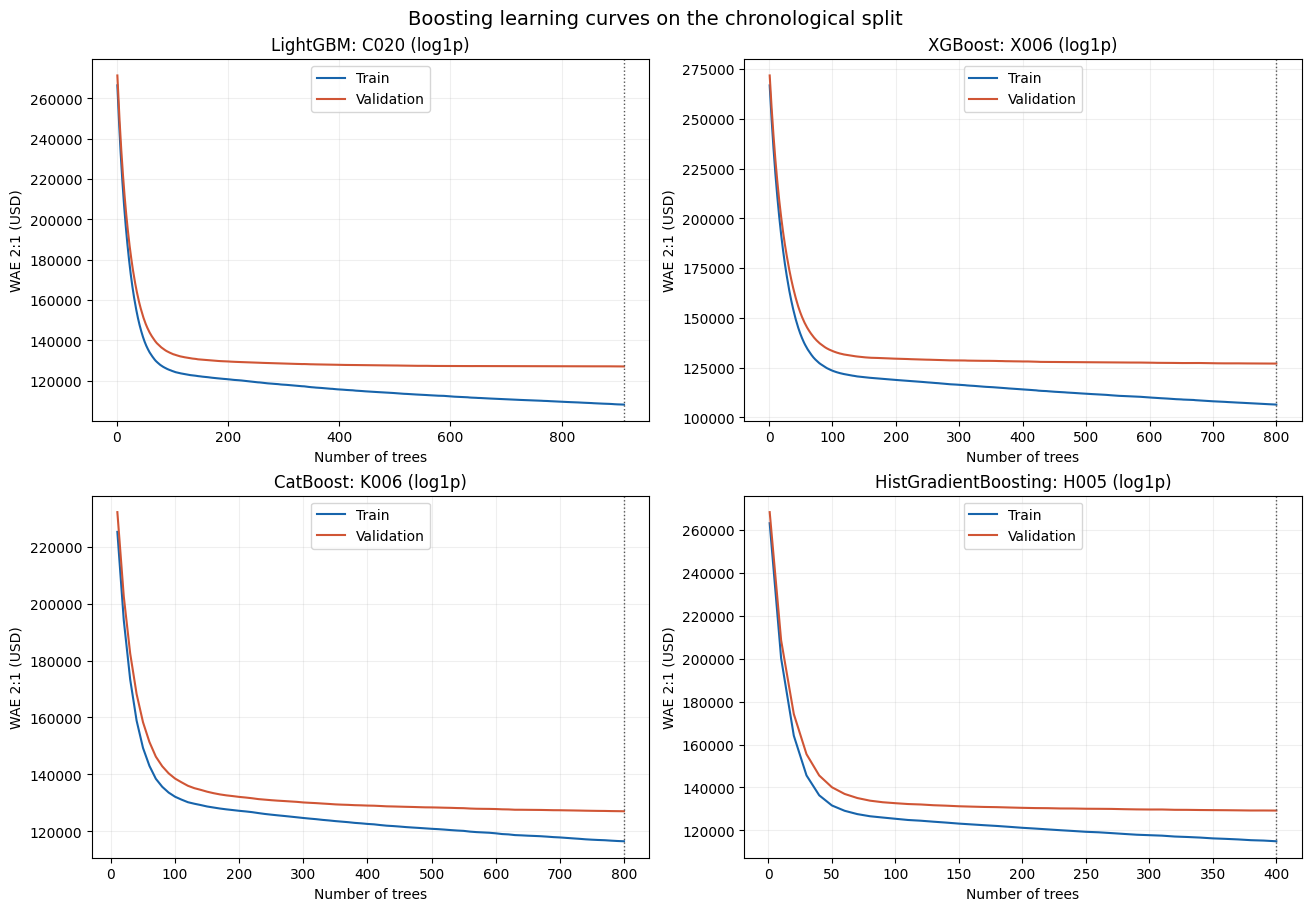

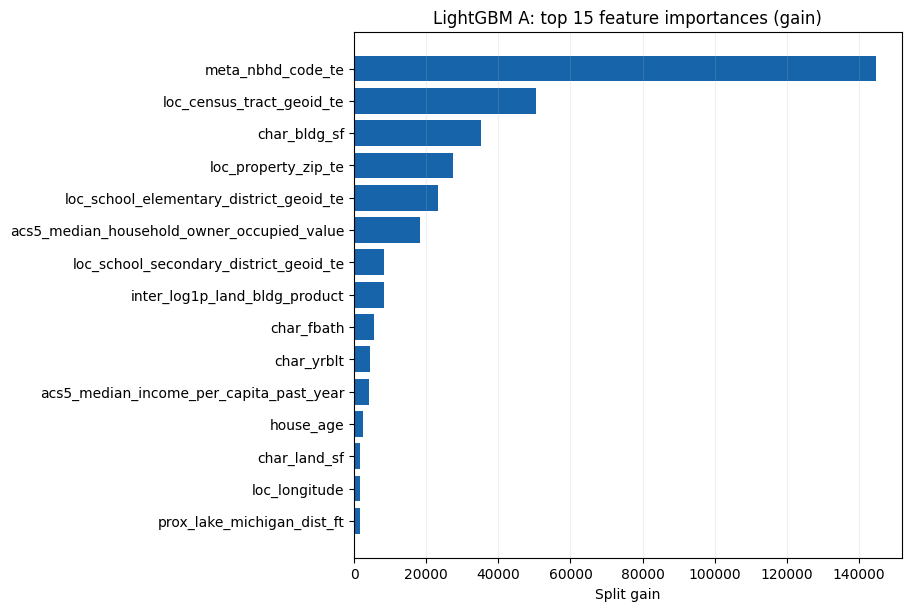

In [22]:
# Diagnostics only: refit selected candidates to collect comparable dollar-WAE learning curves.
def dollar_wae_2_1(actual, prediction):
    error = np.asarray(prediction, dtype=float) - np.asarray(actual, dtype=float)
    return float(np.mean(np.abs(error) * np.where(error > 0, 2., 1.)))

main_scenario = SCENARIOS[MAIN_METRIC][0]
boost_main_winners = boost_scenario_winners.loc[boost_scenario_winners['scenario'].eq(main_scenario)]
curve_rows, visual_models = [], {}
for _, selected in boost_main_winners.iterrows():
    family = selected['model_family']
    candidate_id = selected['winning_configuration'].split(' ', 1)[0]
    candidate = all_candidates.loc[all_candidates['candidate_id'].eq(candidate_id)].iloc[0]
    target = candidate['target']
    rounds = int(candidate['n_estimators'])
    params = json.loads(candidate['params'])
    train_target = np.log1p(y_train) if target == 'log1p' else y_train
    valid_target = np.log1p(y_valid) if target == 'log1p' else y_valid
    if family == 'LightGBM':
        model = lgb_model(params, rounds=rounds)
        history = {}
        def lgb_dollar_wae(eval_target, eval_prediction):
            actual = np.expm1(eval_target) if target == 'log1p' else eval_target
            prediction = dollars(eval_prediction, target)
            return 'dollar_WAE_2_1', dollar_wae_2_1(actual, prediction), False
        model.fit(X_train_A, train_target,
                  eval_set=[(X_train_A, train_target), (X_valid_A, valid_target)],
                  eval_names=['training', 'validation'], eval_metric=lgb_dollar_wae,
                  callbacks=[lgb.record_evaluation(history)])
        training_curve = history['training']['dollar_WAE_2_1']
        validation_curve = history['validation']['dollar_WAE_2_1']
        steps = list(range(1, len(validation_curve) + 1))
    elif family == 'XGBoost':
        def xgb_dollar_wae(eval_target, eval_prediction):
            actual = np.expm1(eval_target) if target == 'log1p' else eval_target
            prediction = dollars(eval_prediction, target)
            return dollar_wae_2_1(actual, prediction)
        xgb_dollar_wae.__name__ = 'dollar_WAE_2_1'
        model = xgb.XGBRegressor(objective='reg:squarederror', random_state=SEED,
                                 n_jobs=N_THREADS, verbosity=0,
                                 eval_metric=xgb_dollar_wae, **params)
        model.fit(X_train_A, train_target,
                  eval_set=[(X_train_A, train_target), (X_valid_A, valid_target)],
                  verbose=False)
        history = model.evals_result()
        training_curve = history['validation_0']['dollar_WAE_2_1']
        validation_curve = history['validation_1']['dollar_WAE_2_1']
        steps = list(range(1, len(validation_curve) + 1))
    elif family == 'CatBoost':
        model = CatBoostRegressor(loss_function='RMSE', random_seed=SEED,
                                  thread_count=N_THREADS, verbose=False,
                                  allow_writing_files=False, **params)
        model.fit(X_train_A, train_target)
        steps, training_curve, validation_curve = [], [], []
        train_stages = model.staged_predict(X_train_A, ntree_end=rounds, eval_period=10)
        valid_stages = model.staged_predict(X_valid_A, ntree_end=rounds, eval_period=10)
        for step, (train_pred, valid_pred) in enumerate(zip(train_stages, valid_stages), start=1):
            steps.append(min(step * 10, rounds))
            training_curve.append(dollar_wae_2_1(y_train, dollars(train_pred, target)))
            validation_curve.append(dollar_wae_2_1(y_valid, dollars(valid_pred, target)))
    elif family == 'HistGradientBoosting':
        model = HistGradientBoostingRegressor(random_state=SEED, early_stopping=False, **params)
        model.fit(X_train_A, train_target)
        steps, training_curve, validation_curve = [], [], []
        train_stages = model.staged_predict(X_train_A)
        valid_stages = model.staged_predict(X_valid_A)
        for step, (train_pred, valid_pred) in enumerate(zip(train_stages, valid_stages), start=1):
            if step == 1 or step % 10 == 0 or step == rounds:
                steps.append(step)
                training_curve.append(dollar_wae_2_1(y_train, dollars(train_pred, target)))
                validation_curve.append(dollar_wae_2_1(y_valid, dollars(valid_pred, target)))
    else:
        raise ValueError(f'Unexpected boosting family: {family}')
    assert steps[-1] == rounds and len(steps) == len(training_curve) == len(validation_curve)
    for step, train_score, valid_score in zip(steps, training_curve, validation_curve):
        curve_rows.append(dict(model_family=family, candidate_id=candidate_id,
                               target=target, n_trees=step,
                               train_WAE_2_1=train_score, validation_WAE_2_1=valid_score))
    visual_models[family] = model
    print('Learning curve', family, candidate_id, 'last validation WAE 2:1',
          f'{validation_curve[-1]:,.2f}', flush=True)
learning_curves = pd.DataFrame(curve_rows)
learning_curves.to_csv(BOOST_OUT / 'learning_curves_WAE_2_1.csv', index=False)
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
for ax, family in zip(axes.flat, ['LightGBM','XGBoost','CatBoost','HistGradientBoosting']):
    group = learning_curves.loc[learning_curves['model_family'].eq(family)]
    ax.plot(group['n_trees'], group['train_WAE_2_1'], label='Train', color='#1764ab')
    ax.plot(group['n_trees'], group['validation_WAE_2_1'], label='Validation', color='#d05535')
    ax.axvline(int(group['n_trees'].iloc[-1]), color='#555555', linestyle=':', linewidth=1)
    ax.set_title(f"{family}: {group['candidate_id'].iloc[0]} ({group['target'].iloc[0]})")
    ax.set_xlabel('Number of trees')
    ax.set_ylabel('WAE 2:1 (USD)')
    ax.grid(alpha=.2)
    ax.legend()
fig.suptitle('Boosting learning curves on the chronological split', fontsize=14)
fig.savefig(BOOST_OUT / 'learning_curves_WAE_2_1.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

# Course-style feature importance for the selected LightGBM A model.
lgb_gain = visual_models['LightGBM'].booster_.feature_importance(importance_type='gain')
importance = pd.DataFrame({'feature': FEATURES, 'gain': lgb_gain}).sort_values('gain', ascending=False)
importance.to_csv(BOOST_OUT / 'lightgbm_feature_importance_gain.csv', index=False)
top = importance.head(15).sort_values('gain')
fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
ax.barh(top['feature'], top['gain'], color='#1764ab')
ax.set_xlabel('Split gain')
ax.set_title('LightGBM A: top 15 feature importances (gain)')
ax.grid(axis='x', alpha=.2)
fig.savefig(BOOST_OUT / 'lightgbm_feature_importance_gain.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

## 11. Boosting: time-variable comparison (Model A vs Model B)

### 11a. Fixed hyperparameters

A uses the 209 shared predictors. B appends months_since_2023_01 from membership sale_date. B uses the A LightGBM WAE 2:1 winner's exact parameters and number of trees. Both fixed fits disable early stopping; this isolates the month variable.

In [23]:
def month_index(dates):
    return ((dates.dt.year - 2023) * 12 + dates.dt.month - 1).astype(int).to_numpy()
train_month_index = month_index(train_ids['sale_date'])
valid_month_index = month_index(validation_dates)
assert train_month_index.min() == 0 and train_month_index.max() == 17
assert valid_month_index.min() == 18 and valid_month_index.max() == 23
X_train_B = X_train_A.assign(months_since_2023_01=train_month_index)
X_valid_B = X_valid_A.assign(months_since_2023_01=valid_month_index)
assert X_train_A.shape[1] == 209 and X_train_B.shape[1] == 210
fixed_params = json.loads(A_winner['params'])
fixed_target = A_winner['target']
fixed_rounds = int(A_winner['n_estimators'])
fixed_predictions = {}
for variant, train_features, valid_features in [
    ('A_no_time', X_train_A, X_valid_A), ('B_month_index', X_train_B, X_valid_B)]:
    model = lgb_model(fixed_params, rounds=fixed_rounds)
    model.fit(train_features, np.log1p(y_train) if fixed_target == 'log1p' else y_train)
    fixed_predictions[variant] = dollars(model.predict(valid_features, num_iteration=fixed_rounds), fixed_target)
    print('Fixed', variant, 'WAE 2:1', f'{boosting_metrics(y_valid, fixed_predictions[variant])[PRIMARY_METRIC]:,.2f}')

Fixed A_no_time WAE 2:1 127,137.84
Fixed B_month_index WAE 2:1 135,841.84


### 11b. Equal budget retuning

B receives the same 24 Optuna trials, seed, WAE 2:1 objective and early stopping rule as A. A's already completed WAE search supplies its retuned row; no second A search is needed.

In [24]:
B_trials, B_predictions, B_histories, B_study = search_lightgbm(X_train_B, X_valid_B, 'B_month_index')
B_trials.to_csv(BOOST_OUT / 'lightgbm_B_validation_trials.csv', index=False)
B_study.trials_dataframe().to_csv(BOOST_OUT / 'lightgbm_B_optuna_trials.csv', index=False)
B_winner = B_trials.sort_values([PRIMARY_METRIC,'candidate_id']).iloc[0]
print('B LightGBM WAE 2:1 winner:', B_winner['configuration'])

C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


B_month_index T001 WAE 2:1 149,792.93 trees 57


C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


B_month_index T002 WAE 2:1 136,788.81 trees 79


C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


B_month_index T003 WAE 2:1 153,804.69 trees 103


... (38 outputs left out)

C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


B_month_index T023 WAE 2:1 135,539.93 trees 62


C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


B_month_index T024 WAE 2:1 135,716.37 trees 71
B LightGBM WAE 2:1 winner: T009 (log1p, 90 trees)


### 11c. Group comparison export and predeclared decision

The fixed comparison is the primary isolation check. Adopt B only if its validation WAE 2:1 improves by more than 1%; otherwise retain A. If MAE improves while WAE worsens, retain A and report that tradeoff. Trees cannot extrapolate beyond the observed training month indices; B can at most distinguish the validation period from earlier training months. A already contains year information through house_age and char_yrblt.

The table is also copied to `data/result/time_trend_comparison/inputs/` for the group summary in 3d.

In [25]:
comparison_rows = []
comparison_predictions = {}
for comparison, variant, prediction, configuration, count in [
    ('fixed_hyperparameters','A_no_time',fixed_predictions['A_no_time'], A_winner['configuration'], 209),
    ('fixed_hyperparameters','B_month_index',fixed_predictions['B_month_index'], A_winner['configuration'], 210),
    ('retuned','A_no_time',A_predictions[A_winner['candidate_id']], A_winner['configuration'], 209),
    ('retuned','B_month_index',B_predictions[B_winner['candidate_id']], B_winner['configuration'], 210),
]:
    comparison_predictions[(comparison, variant)] = prediction
    comparison_rows.append(dict(model_family='LightGBM', variant=variant, comparison=comparison,
        configuration=configuration, n_predictors=count, **boosting_metrics(y_valid, prediction)))
comparison_columns = ['model_family','variant','comparison','configuration','n_predictors',
    'MSE','RMSE','R2','MAE','WAE_2_1','WAE_1_1','WAE_1_2',
    'mean_signed_error','median_ratio','share_overvalued']
time_comparison = pd.DataFrame(comparison_rows)[comparison_columns]
time_comparison.to_csv(TIME_OUT / 'M4_boosting_time_trend.csv', index=False)
time_comparison.to_csv(SHARED_TIME_INPUTS / 'M4_boosting_time_trend.csv', index=False)   # copy for the group summary
fixed_A = time_comparison.query("comparison == 'fixed_hyperparameters' and variant == 'A_no_time'").iloc[0]
fixed_B = time_comparison.query("comparison == 'fixed_hyperparameters' and variant == 'B_month_index'").iloc[0]
improvement_pct = 100 * (fixed_A['WAE_2_1'] - fixed_B['WAE_2_1']) / fixed_A['WAE_2_1']
decision = 'adopt_B' if improvement_pct > 1 else 'retain_A'
tradeoff = bool(fixed_B['MAE'] < fixed_A['MAE'] and fixed_B['WAE_2_1'] > fixed_A['WAE_2_1'])
monthly_rows = []
for (comparison, variant), prediction in comparison_predictions.items():
    for month in range(7, 13):
        mask = validation_dates.dt.month.to_numpy() == month
        monthly_rows.append(dict(model_family='LightGBM', variant=variant, comparison=comparison,
            validation_month=f'2024-{month:02d}', n=int(mask.sum()),
            mean_signed_error=float(np.mean(prediction[mask] - y_valid[mask]))))
pd.DataFrame(monthly_rows).to_csv(BOOST_OUT / 'M4_monthly_signed_error.csv', index=False)
time_predictions = pd.DataFrame({'transaction_id':validation_ids,'actual_sale_price':y_valid})
for (comparison, variant), prediction in comparison_predictions.items():
    time_predictions[f'{comparison}_{variant}'] = prediction
time_predictions.to_csv(BOOST_OUT / 'M4_time_validation_predictions.csv', index=False)
boost_time_decision = dict(selection_metric='2024H2 validation WAE_2_1', A_winner=A_winner['configuration'],
    B_winner=B_winner['configuration'], fixed_improvement_pct=improvement_pct,
    decision=decision, MAE_improves_while_WAE_worsens=tradeoff,
    train_month_range=[0,17], validation_month_range=[18,23], test_read=False)
(BOOST_OUT / 'M4_decision.json').write_text(json.dumps(boost_time_decision,indent=2,ensure_ascii=False),encoding='utf-8')
print(time_comparison.to_string(index=False))
print('Fixed comparison WAE improvement:',f'{improvement_pct:.3f}%','decision:',decision,'MAE/WAE tradeoff:',tradeoff)

model_family       variant            comparison           configuration  n_predictors          MSE          RMSE       R2           MAE       WAE_2_1       WAE_1_1       WAE_1_2  mean_signed_error  median_ratio  share_overvalued
    LightGBM     A_no_time fixed_hyperparameters C020 (log1p, 912 trees)           209 4.719801e+10 217251.026721 0.752540 101201.802073 127137.842014 101201.802073 176467.564203      -49329.722189      0.903462          0.337856
    LightGBM B_month_index fixed_hyperparameters C020 (log1p, 912 trees)           210 4.415106e+10 210121.524929 0.768515  96014.066596 135841.844787  96014.066596 152200.354999      -16358.510212      0.979676          0.462001
    LightGBM     A_no_time               retuned C020 (log1p, 912 trees)           209 4.719801e+10 217251.026721 0.752540 101201.802073 127137.842014 101201.802073 176467.564203      -49329.722189      0.903462          0.337856
    LightGBM B_month_index               retuned  T009 (log1p, 90 trees)        

# Part C — Final model and 2025 test

## 12. Final model selection across families (3f)

**Rule (pre-specified).** The final model is the configuration with the lowest 2024 H2 validation WAE 2:1 among all configurations evaluated in Parts A and B. Ties are broken by candidate ID. The final selection pool contains the 209-predictor Model A configurations. Sections 6c and 11 provide family-specific month-index sensitivity analyses. They do not test a month-index variant of XGBoost or CatBoost, so a final choice from either family cannot claim that its own time-index variant was inferior.

The comparison table lists each family's main-scenario winner on the same 18,132 validation sales, plus the Global Mean baseline and the required linear-model winner from `the linear-model section above`. The notebook stops if that result is missing or if the linear winner beats the chosen non-linear candidate. The frozen choice is written to `final_model_selection.json` before the test set is opened.

In [ ]:
METRIC_COLUMNS = ["WAE_2_1", "WAE_1_1", "WAE_1_2", "MSE", "R2", "MAE"]
TREE_TARGET = "log1p" if TARGET == "log" else "raw"

linear_path = DATA_DIR / "result" / "linear_models" / "overall_model_selection_winners.csv"
if not linear_path.is_file():
    raise FileNotFoundError(
        f"Required linear-family selection result is missing: {linear_path}. "
        "Run the preceding linear-model section of this notebook first."
    )

# Candidate pool: every configuration scored on validation in Parts A and B (Model A features).
tree_pool = pd.DataFrame({
    "model_family": all_runs["model_family"],
    "candidate_id": all_runs["run_id"],
    "configuration": all_runs["run_id"] + " (" + all_runs["configuration"] + ")",
    "target": TREE_TARGET,
    "params": all_runs["params"],
    "n_estimators": all_runs["n_estimators"],
    "source": "Part A (trees)",
})
tree_pool = pd.concat([tree_pool, all_runs[METRIC_COLUMNS]], axis=1)
boost_pool = all_candidates[["model_family", "candidate_id", "configuration", "target", "params", "n_estimators"]
                            + METRIC_COLUMNS].assign(source="Part B (Boosting)")
candidate_pool = pd.concat([tree_pool, boost_pool], ignore_index=True)
assert candidate_pool["candidate_id"].is_unique
candidate_pool.to_csv(FINAL_DIR / "validation_candidate_pool.csv", index=False)

family_winners = (candidate_pool.sort_values([MAIN_METRIC, "candidate_id"])
                  .drop_duplicates("model_family").reset_index(drop=True))

# The family winners must agree with the scenario-winner tables of Parts A and B.
main_name = SCENARIOS[MAIN_METRIC][0]
recorded_main = pd.concat([
    scenario_winners.loc[scenario_winners["scenario"] == main_name, ["model_family", "selected_WAE"]],
    boost_scenario_winners.loc[boost_scenario_winners["scenario"] == main_name, ["model_family", "selected_WAE"]],
])
check = family_winners.merge(recorded_main, on="model_family", how="left", validate="one_to_one")
assert check["selected_WAE"].notna().all() and np.allclose(check[MAIN_METRIC], check["selected_WAE"])

final_candidate = family_winners.iloc[0]
FINAL_FAMILY = final_candidate["model_family"]
print(f"Final model: {FINAL_FAMILY} {final_candidate['configuration']}, "
      f"validation WAE 2:1 = {final_candidate[MAIN_METRIC]:,.2f}")

# Do not transfer a time-index decision from one algorithm to another.
if FINAL_FAMILY in ("Decision Tree", "Random Forest"):
    time_row = time_trend_table.loc[
        (time_trend_table["model_family"] == FINAL_FAMILY)
        & (time_trend_table["selected_by"] == SELECTION_RULES["WAE_2_1"])
        & (time_trend_table["comparison"] == "fixed_hyperparameters")
        & (time_trend_table["variant"] == "B_month_index")
    ].iloc[0]
    time_evidence = f"{FINAL_FAMILY} fixed-hyperparameter comparison: {time_row['rule_outcome']}"
    adopt_time = time_row["rule_outcome"].startswith("Adopt")
elif FINAL_FAMILY == "LightGBM":
    time_evidence = (
        f"LightGBM fixed-hyperparameter comparison (section 11): {decision}, "
        f"WAE 2:1 change {-improvement_pct:+.2f}%"
    )
    adopt_time = decision == "adopt_B"
else:
    time_evidence = (
        f"No month-index Model B was fitted for {FINAL_FAMILY}. The final choice "
        "is the lowest-WAE candidate in the predeclared 209-predictor Model A pool; "
        "its own month-index sensitivity remains untested."
    )
    adopt_time = None
if adopt_time is True:
    raise RuntimeError(
        "The selected family's validation time-index comparison adopts Model B; "
        "resolve the feature-set choice before opening the 2025 test."
    )
print("Time-variable evidence:", time_evidence)

# Cross-family comparison table for 3f (validation, main scenario).
comparison = family_winners[["model_family", "configuration"] + METRIC_COLUMNS].assign(
    role=["selected final model"] + ["family winner"] * (len(family_winners) - 1))
reference_rows = [{"model_family": "Global Mean", "configuration": "training-period mean price",
                   **{column: baseline_metrics[column] for column in METRIC_COLUMNS}, "role": "baseline"}]
linear = pd.read_csv(linear_path)
required_linear_columns = {
    "selection_metric", "selected_model_family", "selected_feature_set", "selected_alpha",
    *METRIC_COLUMNS,
}
missing_linear_columns = required_linear_columns - set(linear.columns)
if missing_linear_columns:
    raise ValueError(f"Incomplete linear winner file {linear_path}: {sorted(missing_linear_columns)}")
linear_main_rows = linear.loc[linear["selection_metric"] == MAIN_METRIC]
if len(linear_main_rows) != 1:
    raise ValueError(f"Expected exactly one main-scenario linear winner in {linear_path}")
linear_main = linear_main_rows.iloc[0]
reference_rows.append({
    "model_family": f"{linear_main['selected_model_family']} (linear)",
    "configuration": f"Feature Set {linear_main['selected_feature_set']}, alpha={linear_main['selected_alpha']}",
    **{column: float(linear_main[column]) for column in METRIC_COLUMNS},
    "role": "reference: fitted in the linear-model section above",
})
if not np.isfinite(float(linear_main[MAIN_METRIC])):
    raise ValueError(f"Non-finite linear winner WAE in {linear_path}")
if float(linear_main[MAIN_METRIC]) < final_candidate[MAIN_METRIC]:
    raise RuntimeError(
        "A linear model has the lowest validation WAE 2:1. The final test must "
        "be run with that model, not with the non-linear candidate selected here."
    )
family_comparison = (pd.concat([comparison, pd.DataFrame(reference_rows)], ignore_index=True)
                     .sort_values(MAIN_METRIC).reset_index(drop=True))
family_comparison.to_csv(FINAL_DIR / "validation_family_comparison_main_scenario.csv", index=False)
print(f"\nMain-scenario winner of each family (2024 H2 validation, {len(y_val):,} sales):")
print(family_comparison.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))

# Freeze the choice before the test set is opened.
final_selection = {
    "selection_rule": "lowest 2024 H2 validation WAE 2:1 across compared 209-predictor Model A candidates, after checking the linear-family winner",
    "model_family": FINAL_FAMILY,
    "candidate_id": final_candidate["candidate_id"],
    "configuration": final_candidate["configuration"],
    "target": final_candidate["target"],
    "params": json.loads(final_candidate["params"]),
    "n_estimators": None if pd.isna(final_candidate["n_estimators"]) else int(final_candidate["n_estimators"]),
    "predictors": len(FEATURES),
    "time_variable": time_evidence,
    "fit_window_for_test": FINAL_FIT_WINDOW,
    "validation_metrics": {column: float(final_candidate[column]) for column in METRIC_COLUMNS},
    "runner_up": {"model_family": family_winners.iloc[1]["model_family"],
                  "configuration": family_winners.iloc[1]["configuration"],
                  "WAE_2_1": float(family_winners.iloc[1][MAIN_METRIC])},
    "split_sha256": {name: manifest["splits"][name]["sha256"] for name in ["train", "validation", "test"]},
    "frozen_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "test_read": False,
}
(FINAL_DIR / "final_model_selection.json").write_text(json.dumps(final_selection, indent=2), encoding="utf-8")
print("\nFrozen final model written to", (FINAL_DIR / "final_model_selection.json").as_posix())

## 13. Final 2025 test (4a, 4b, 4c, 4d)

### 13a. Refit the frozen model and predict 2025

The frozen hyperparameters, target scale and tree count are used without change; there is no early stopping and no further tuning. First, the model is refitted on the training sales alone and must reproduce its recorded validation WAE 2:1, which confirms that the refit code builds the same model that was selected. It is then refitted on `FINAL_FIT_WINDOW` (training plus validation sales, 72,985 sales) and predicts the 36,322 sales of 2025 once. The Global Mean baseline is the mean sale price of the same window.

Prediction file schema: `transaction_id, property_id, sale_date, meta_township_code, actual_sale_price, predicted_sale_price, baseline_prediction, model_family, configuration`.

In [27]:
def make_estimator(candidate):
    family = candidate["model_family"]
    params = json.loads(candidate["params"])
    if family == "Decision Tree":
        return DecisionTreeRegressor(random_state=RANDOM_STATE, **params)
    if family == "Random Forest":
        return RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS, **params)
    if family == "LightGBM":
        return lgb_model(params, rounds=int(candidate["n_estimators"]))
    if family == "HistGradientBoosting":
        return HistGradientBoostingRegressor(random_state=SEED, early_stopping=False, **params)
    if family == "XGBoost":
        return xgb.XGBRegressor(objective="reg:squarederror", random_state=SEED,
                                n_jobs=N_THREADS, verbosity=0, **params)
    if family == "CatBoost":
        return CatBoostRegressor(loss_function="RMSE", random_seed=SEED, thread_count=N_THREADS,
                                 verbose=False, allow_writing_files=False, **params)
    raise ValueError(f"Unknown model family: {family}")


def fit_and_predict(candidate, X_fit, y_fit_dollars, X_new):
    target = candidate["target"]
    model = make_estimator(candidate)
    model.fit(X_fit, np.log1p(y_fit_dollars) if target == "log1p" else y_fit_dollars)
    if candidate["model_family"] == "LightGBM":
        raw_prediction = model.predict(X_new, num_iteration=int(candidate["n_estimators"]))
    else:
        raw_prediction = model.predict(X_new)
    return model, dollars(raw_prediction, target)


# Reproduction check on validation: the refit code must rebuild the selected model.
_, reproduced_validation = fit_and_predict(final_candidate, X_train, y_train, X_val)
reproduced_wae = weighted_absolute_error(y_val, reproduced_validation, 2, 1)
relative_gap = abs(reproduced_wae / final_candidate[MAIN_METRIC] - 1)
print(f"Validation WAE 2:1 recorded {final_candidate[MAIN_METRIC]:,.2f}, refit {reproduced_wae:,.2f} "
      f"(relative difference {relative_gap:.2e})")
assert relative_gap < 1e-3, "The refit does not reproduce the selected model's validation result."

if RUN_FINAL_TEST:
    test_raw, test_ids = load_split("test")
    X_test = build_features(test_raw, test_ids)
    assert X_test.columns.tolist() == X_train.columns.tolist() and not X_test.isna().any().any()
    y_test = test_raw["sale_price"].to_numpy(dtype=float)
    assert test_ids["sale_date"].dt.year.eq(2025).all()
    if FINAL_FIT_WINDOW == "train+validation":
        X_fit = pd.concat([X_train, X_val], ignore_index=True)
        y_fit = np.concatenate([y_train, y_val])
        fit_ids = pd.concat([train_ids, val_ids], ignore_index=True)
    else:
        X_fit, y_fit, fit_ids = X_train, y_train, train_ids
    assert fit_ids["transaction_id"].is_unique and not set(fit_ids["transaction_id"]) & set(test_ids["transaction_id"])

    start = time.perf_counter()
    final_model, test_pred = fit_and_predict(final_candidate, X_fit, y_fit, X_test)
    baseline_test = np.full(len(y_test), y_fit.mean())
    print(f"Refit window: {FINAL_FIT_WINDOW} ({len(y_fit):,} sales, {time.perf_counter() - start:.0f}s); "
          f"2025 test sales: {len(y_test):,}")

    township_codes = pd.read_csv(DATA_DIR / "properties_2022.csv", usecols=["property_id", "meta_township_code"],
                                 dtype={"property_id": str, "meta_township_code": str})
    test_output = test_ids[["transaction_id", "property_id", "sale_date"]].merge(
        township_codes, on="property_id", how="left", validate="many_to_one")
    assert len(test_output) == len(test_ids) and test_output["meta_township_code"].notna().all()
    test_output["actual_sale_price"] = y_test
    test_output["predicted_sale_price"] = test_pred
    test_output["baseline_prediction"] = baseline_test
    test_output["model_family"] = FINAL_FAMILY
    test_output["configuration"] = final_candidate["configuration"]
    test_output.to_csv(FINAL_DIR / "final_model_test_predictions.csv", index=False)
    print("Saved", (FINAL_DIR / "final_model_test_predictions.csv").as_posix())
else:
    print("RUN_FINAL_TEST is False: the 2025 test set was not loaded or scored.")

Validation WAE 2:1 recorded 127,037.32, refit 127,037.32 (relative difference 0.00e+00)
Refit window: train+validation (72,985 sales, 14s); 2025 test sales: 36,322
Saved data/result/final_test/final_model_test_predictions.csv


### 13b. Test-set evaluation against the baseline (4a, 4c)

Overall metrics for the final model and the Global Mean baseline: MSE, RMSE, R², MAE, WAE under all three scenarios, median absolute percentage error, mean signed error (prediction − actual), share overvalued, and the IAAO ratio statistics (median ratio, COD, PRD; ratio = estimate / sale price). The 4c table keeps both sets of predictions fixed and changes only the error weights. The residual figure plots prediction errors against predicted price and shows the median ratio and overvaluation share by price decile.

2025 test sales: 36,322; baseline = mean price of the train+validation window ($426,200.21)
                                    WAE_2_1      WAE_1_1      WAE_1_2                  MSE      R2          MAE         RMSE  median_APE  mean_signed_error  share_overvalued  median_ratio     COD    PRD
XGBoost X006                   134,003.2473 105,304.3302 181,909.7431  63,250,763,560.2397  0.7394 105,304.3302 251,497.0448      0.1796       -47,906.4958            0.3693        0.9247 30.8739 1.1554
Global Mean (train+validation) 360,698.9989 256,774.3484 409,624.0464 245,128,678,073.3223 -0.0099 256,774.3484 495,104.7143      0.4279       -48,925.0475            0.6231        1.1839 76.1704 1.8461

4c: WAE with fixed 2025 predictions
                                   scenario        model  model_WAE  baseline_WAE  reduction_percent
        Main - Overvaluation Priority (2:1) XGBoost X006 134,003.25    360,699.00              62.85
         Alternative - Equal Priority (1:1) XGBoost X006 105

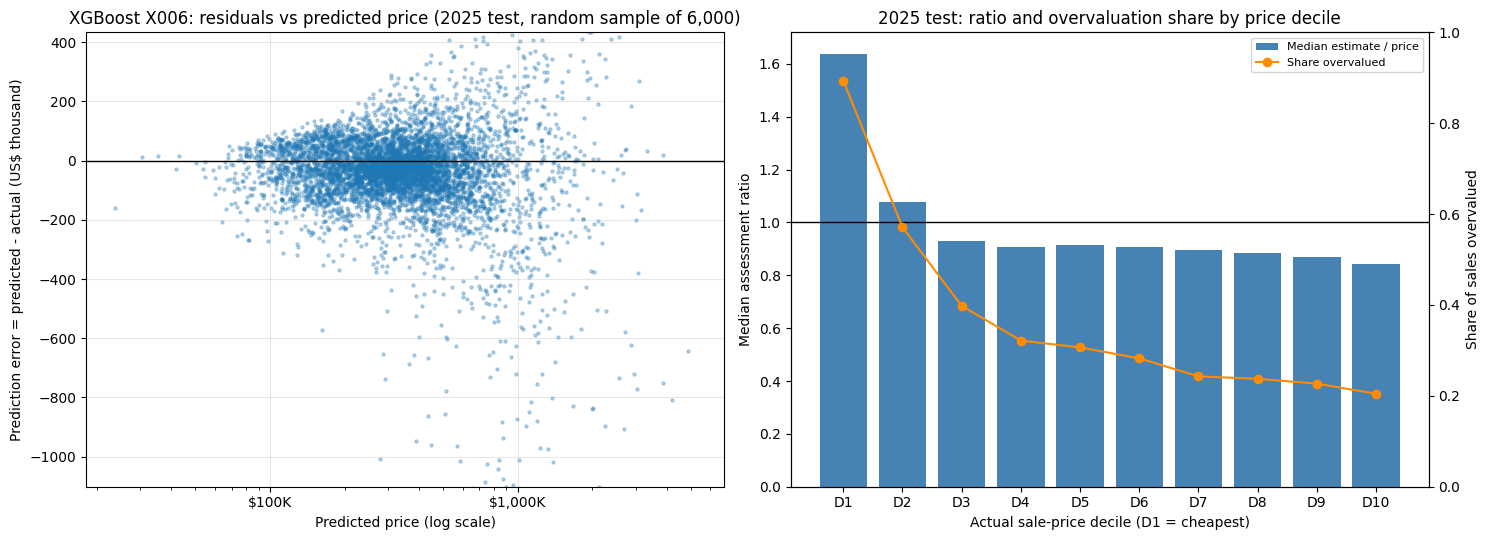

In [28]:
def overall_test_row(actual, prediction):
    error = prediction - actual
    return {
        **evaluate_regression_predictions(actual, prediction),
        "RMSE": float(np.sqrt(mean_squared_error(actual, prediction))),
        "median_APE": float(np.median(np.abs(error) / actual)),
        "mean_signed_error": float(error.mean()),
        "share_overvalued": float((error > 0).mean()),
        **assessment_ratio_statistics(actual, prediction),
    }


if RUN_FINAL_TEST:
    model_label = f"{FINAL_FAMILY} {final_candidate['candidate_id']}"
    baseline_label = f"Global Mean ({FINAL_FIT_WINDOW})"
    test_overall = pd.DataFrame({model_label: overall_test_row(y_test, test_pred),
                                 baseline_label: overall_test_row(y_test, baseline_test)}).T
    test_overall.to_csv(FINAL_DIR / "final_test_overall_metrics.csv", index_label="model")
    print(f"2025 test sales: {len(y_test):,}; baseline = mean price of the {FINAL_FIT_WINDOW} window "
          f"(${y_fit.mean():,.2f})")
    print(test_overall.to_string(float_format=lambda v: f"{v:,.4f}"))

    fixed_rows = []
    for metric, (scenario_name, over_w, under_w) in SCENARIOS.items():
        model_wae = weighted_absolute_error(y_test, test_pred, over_w, under_w)
        baseline_wae = weighted_absolute_error(y_test, baseline_test, over_w, under_w)
        fixed_rows.append({"scenario": scenario_name, "model": model_label, "model_WAE": model_wae,
                           "baseline_WAE": baseline_wae, "reduction_percent": 100 * (1 - model_wae / baseline_wae)})
    test_fixed = pd.DataFrame(fixed_rows)
    test_fixed.to_csv(FINAL_DIR / "final_test_fixed_scenario_comparison.csv", index=False)
    print("\n4c: WAE with fixed 2025 predictions")
    print(test_fixed.to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

    # Summary of the frozen model and its single test evaluation.
    final_metrics = {
        **{key: final_selection[key] for key in ["model_family", "candidate_id", "configuration", "target",
                                                  "params", "n_estimators", "selection_rule", "predictors"]},
        "fit_window": FINAL_FIT_WINDOW, "fit_rows": int(len(y_fit)), "test_rows": int(len(y_test)),
        "test_evaluated_once": True,
        "validation_WAE_2_1": float(final_candidate[MAIN_METRIC]),
        "baseline_fit_mean": float(y_fit.mean()),
        "model": {key: float(value) for key, value in test_overall.loc[model_label].items()},
        "baseline": {key: float(value) for key, value in test_overall.loc[baseline_label].items()},
        "reduction_percent": dict(zip(SCENARIOS, test_fixed["reduction_percent"].astype(float))),
        "split_sha256": final_selection["split_sha256"],
    }
    (FINAL_DIR / "final_model_test_metrics.json").write_text(json.dumps(final_metrics, indent=2), encoding="utf-8")

    # Residual figure (4a).
    test_frame = test_output.rename(columns={"actual_sale_price": "actual", "predicted_sale_price": "predicted"})
    test_frame["error"] = test_frame["predicted"] - test_frame["actual"]
    test_frame["ratio"] = test_frame["predicted"] / test_frame["actual"]
    test_frame["price_decile"] = pd.qcut(test_frame["actual"], 10, labels=[f"D{i}" for i in range(1, 11)])
    decile_view = test_frame.groupby("price_decile", observed=True).agg(
        median_ratio=("ratio", "median"), share_overvalued=("error", lambda e: (e > 0).mean()))
    plot_sample = test_frame.sample(n=min(6000, len(test_frame)), random_state=RANDOM_STATE)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    axes[0].scatter(plot_sample["predicted"], plot_sample["error"] / 1e3, s=5, alpha=0.3)
    axes[0].axhline(0, color="black", linewidth=1)
    axes[0].set_xscale("log")
    axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v / 1e3:,.0f}K"))
    axes[0].set_xlabel("Predicted price (log scale)")
    axes[0].set_ylabel("Prediction error = predicted - actual (US$ thousand)")
    axes[0].set_title(f"{model_label}: residuals vs predicted price (2025 test, random sample of {len(plot_sample):,})")
    axes[0].set_ylim(np.percentile(plot_sample["error"] / 1e3, [0.5, 99.5]))
    axes[0].grid(alpha=0.3)
    positions = np.arange(len(decile_view))
    axes[1].bar(positions, decile_view["median_ratio"], color="steelblue", label="Median estimate / price")
    axes[1].axhline(1, color="black", linewidth=1)
    axes[1].set_xticks(positions)
    axes[1].set_xticklabels(decile_view.index)
    axes[1].set_xlabel("Actual sale-price decile (D1 = cheapest)")
    axes[1].set_ylabel("Median assessment ratio")
    twin = axes[1].twinx()
    twin.plot(positions, decile_view["share_overvalued"], color="darkorange", marker="o", label="Share overvalued")
    twin.set_ylabel("Share of sales overvalued")
    twin.set_ylim(0, 1)
    axes[1].set_title("2025 test: ratio and overvaluation share by price decile")
    handles = axes[1].get_legend_handles_labels()[0] + twin.get_legend_handles_labels()[0]
    labels = axes[1].get_legend_handles_labels()[1] + twin.get_legend_handles_labels()[1]
    axes[1].legend(handles, labels, loc="upper right", fontsize=8)
    plt.tight_layout()
    fig.savefig(FINAL_FIG_DIR / "F1_final_test_residuals.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("RUN_FINAL_TEST is False: section 13b skipped.")

### 13c. Errors by time period, township and price level (4b)

Every table reports the number of sales, the median sale price, error measures (MAE, WAE 2:1, median APE, mean signed error, share overvalued) and the ratio statistics (median ratio, COD, PRD) for the final model's 2025 predictions. Two characteristics from `properties_2022.csv`, median building area and median year built, describe the mix of homes sold in each group. Township names follow the Cook County Assessor's township codes; the seven City of Chicago townships have codes 70–77. "Seen in fit window" marks 2025 sales of properties that also sold in the refit window.


Errors by quarter:
              sales  median_price         MAE     WAE_2_1  median_APE  mean_signed_error  share_overvalued  median_ratio    COD   PRD  median_bldg_sf  median_year_built
sale_quarter                                                                                                                                                            
2025-Q1        7074   340,000.000  99,987.546 130,472.395       0.184        -39,017.850             0.403         0.943 31.013 1.155       1,450.000          1,954.000
2025-Q2       10563   375,000.000 103,875.773 133,229.474       0.171        -45,168.371             0.366         0.928 30.282 1.147       1,464.000          1,954.000
2025-Q3       10094   365,000.000 106,064.844 133,167.042       0.178        -51,860.448             0.351         0.914 30.526 1.151       1,455.500          1,954.000
2025-Q4        8591   357,000.000 110,545.182 138,844.509       0.189        -53,946.527             0.367         0.920 31.750 1.172  

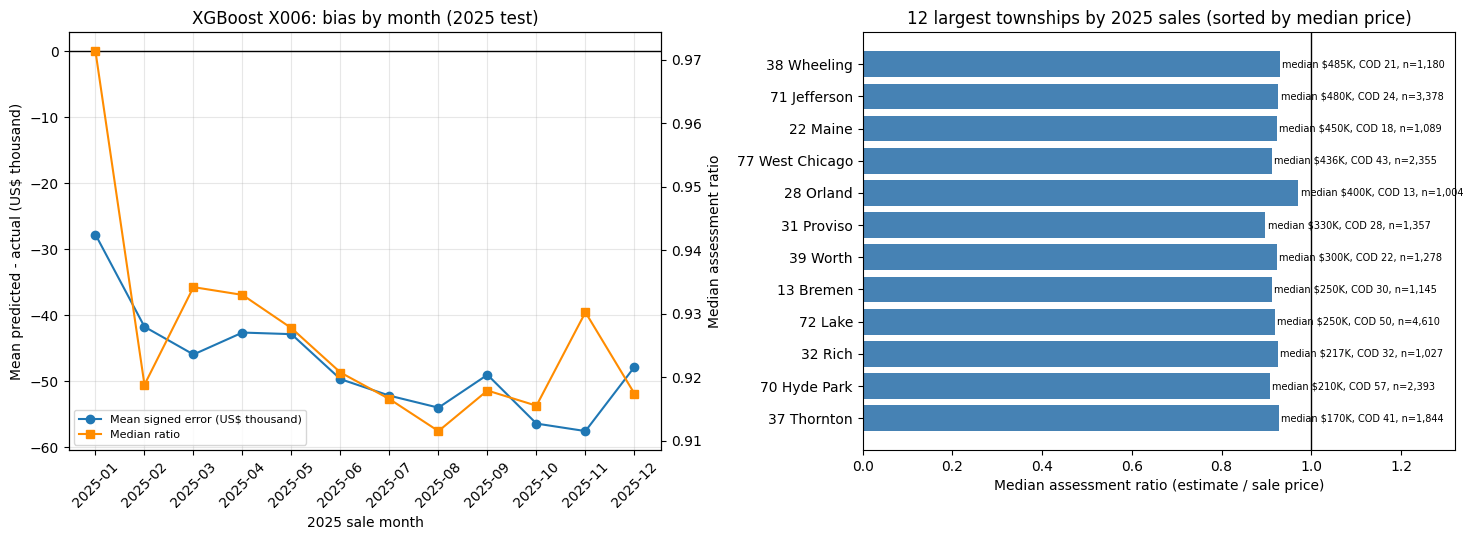

In [29]:
TOWNSHIP_NAMES = {
    "10": "Barrington", "11": "Berwyn", "12": "Bloom", "13": "Bremen", "14": "Calumet", "15": "Cicero",
    "16": "Elk Grove", "17": "Evanston", "18": "Hanover", "19": "Lemont", "20": "Leyden", "21": "Lyons",
    "22": "Maine", "23": "New Trier", "24": "Niles", "25": "Northfield", "26": "Norwood Park", "27": "Oak Park",
    "28": "Orland", "29": "Palatine", "30": "Palos", "31": "Proviso", "32": "Rich", "33": "River Forest",
    "34": "Riverside", "35": "Schaumburg", "36": "Stickney", "37": "Thornton", "38": "Wheeling", "39": "Worth",
    "70": "Hyde Park", "71": "Jefferson", "72": "Lake", "73": "Lake View", "74": "North Chicago",
    "75": "Rogers Park", "76": "South Chicago", "77": "West Chicago",
}


def test_group_summary(frame, by):
    grouped = frame.groupby(by, observed=True)

    def cod(group):
        median = group["ratio"].median()
        return 100 * (group["ratio"] - median).abs().mean() / median

    def prd(group):
        return group["ratio"].mean() / (group["predicted"].sum() / group["actual"].sum())

    ratio_columns = grouped[["ratio", "predicted", "actual"]]
    return pd.DataFrame({
        "sales": grouped.size(),
        "median_price": grouped["actual"].median(),
        "MAE": grouped["abs_error"].mean(),
        "WAE_2_1": grouped["weighted_error_2_1"].mean(),
        "median_APE": grouped["abs_pct_error"].median(),
        "mean_signed_error": grouped["error"].mean(),
        "share_overvalued": grouped["overvalued"].mean(),
        "median_ratio": grouped["ratio"].median(),
        "COD": ratio_columns.apply(cod),
        "PRD": ratio_columns.apply(prd),
        "median_bldg_sf": grouped["bldg_sf"].median(),
        "median_year_built": grouped["year_built"].median(),
    })


if RUN_FINAL_TEST:
    characteristics = pd.read_csv(DATA_DIR / "properties_2022.csv", usecols=["property_id", "char_bldg_sf", "char_yrblt"],
                                  dtype={"property_id": str})
    test_frame = test_frame.merge(characteristics, on="property_id", how="left", validate="many_to_one")
    assert len(test_frame) == len(y_test)
    test_frame = test_frame.rename(columns={"char_bldg_sf": "bldg_sf", "char_yrblt": "year_built"})
    test_frame["abs_error"] = test_frame["error"].abs()
    test_frame["weighted_error_2_1"] = test_frame["abs_error"] * np.where(test_frame["error"] > 0, 2.0, 1.0)
    test_frame["abs_pct_error"] = test_frame["abs_error"] / test_frame["actual"]
    test_frame["overvalued"] = test_frame["error"] > 0
    test_frame["sale_month"] = test_frame["sale_date"].dt.strftime("%Y-%m")
    test_frame["sale_quarter"] = "2025-Q" + test_frame["sale_date"].dt.quarter.astype(str)
    test_frame["township"] = (test_frame["meta_township_code"] + " " +
                              test_frame["meta_township_code"].map(TOWNSHIP_NAMES).fillna("(unnamed)"))
    test_frame["area"] = np.where(test_frame["meta_township_code"].astype(int) >= 70, "City of Chicago", "Suburban Cook")
    test_frame["seen_in_fit_window"] = test_frame["property_id"].isin(set(fit_ids["property_id"]))

    subgroup_tables = {
        "quarter": test_group_summary(test_frame, "sale_quarter"),
        "month": test_group_summary(test_frame, "sale_month"),
        "area": test_group_summary(test_frame, "area"),
        "township": test_group_summary(test_frame, "township").sort_values("sales", ascending=False),
        "price_decile": test_group_summary(test_frame, "price_decile"),
        "seen_status": test_group_summary(test_frame, "seen_in_fit_window"),
    }
    for name, table in subgroup_tables.items():
        table.to_csv(FINAL_DIR / f"final_test_errors_by_{name}.csv")
        shown = table.head(12) if name == "township" else table
        print(f"\nErrors by {name.replace('_', ' ')}{' (12 largest by sales; full table in the CSV)' if name == 'township' else ''}:")
        print(shown.to_string(float_format=lambda v: f"{v:,.3f}"))

    # Figure for 4b: monthly bias and the ratio level of the largest townships.
    by_month = subgroup_tables["month"]
    largest = subgroup_tables["township"].head(12).sort_values("median_price")
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    axes[0].plot(by_month.index, by_month["mean_signed_error"] / 1e3, marker="o", label="Mean signed error (US$ thousand)")
    axes[0].axhline(0, color="black", linewidth=1)
    axes[0].set_xlabel("2025 sale month")
    axes[0].set_ylabel("Mean predicted - actual (US$ thousand)")
    axes[0].tick_params(axis="x", rotation=45)
    month_twin = axes[0].twinx()
    month_twin.plot(by_month.index, by_month["median_ratio"], color="darkorange", marker="s", label="Median ratio")
    month_twin.set_ylabel("Median assessment ratio")
    axes[0].set_title(f"{model_label}: bias by month (2025 test)")
    handles = axes[0].get_legend_handles_labels()[0] + month_twin.get_legend_handles_labels()[0]
    labels = axes[0].get_legend_handles_labels()[1] + month_twin.get_legend_handles_labels()[1]
    axes[0].legend(handles, labels, loc="lower left", fontsize=8)
    axes[0].grid(alpha=0.3)
    axes[1].barh(largest.index, largest["median_ratio"], color="steelblue")
    axes[1].axvline(1, color="black", linewidth=1)
    for position, (label, row) in enumerate(largest.iterrows()):
        axes[1].text(row["median_ratio"] + 0.005, position,
                     f"median ${row['median_price'] / 1e3:,.0f}K, COD {row['COD']:.0f}, n={int(row['sales']):,}",
                     va="center", fontsize=7)
    axes[1].set_xlim(0, max(1.2, largest["median_ratio"].max() + 0.35))
    axes[1].set_xlabel("Median assessment ratio (estimate / sale price)")
    axes[1].set_title("12 largest townships by 2025 sales (sorted by median price)")
    plt.tight_layout()
    fig.savefig(FINAL_FIG_DIR / "F2_final_test_month_township.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("RUN_FINAL_TEST is False: section 13c skipped.")

## 14. Output files

Lists every file written by this notebook. Files from earlier versions of the M3 and M4 notebooks that this notebook no longer writes are flagged, so outdated numbers are not cited in the report by mistake.

In [30]:
for folder in [OUT_DIR, BOOST_OUT, FINAL_DIR]:
    print(f"\n{folder.as_posix()}/")
    for path in sorted(folder.rglob("*")):
        if path.is_file():
            print("   ", path.relative_to(folder).as_posix())
print("\nShared time-variable inputs:", sorted(path.name for path in SHARED_TIME_INPUTS.glob("*.csv")))

outdated = [
    DATA_DIR / "result" / "boosting",                                   # old M4 output folder
    FINAL_DIR / "selected_lightgbm_test_metrics.json",                  # old final test (earlier CSVs)
    FINAL_DIR / "selected_lightgbm_test_predictions.csv",
    *sorted(OUT_DIR.glob("final_test_*.csv")),                          # old M3 section 8b outputs
    OUT_DIR / "rf_test_metrics.csv", OUT_DIR / "rf_test_predictions.csv",
    FIG_DIR / "T6_final_test_residuals.png",
]
outdated = [path for path in outdated if path.exists()]
if outdated:
    print("\nOutdated files from earlier notebook versions (not written by this notebook; delete them):")
    for path in outdated:
        print("   ", path.as_posix())


data/result/trees/
    figures/T1_decision_tree_complexity.png
    figures/T2_rf_n_estimators.png
    figures/T3_rf_complexity_grid.png
    figures/T4_rf_feature_importance.png
    figures/T5_rf_validation_residuals.png
    figures/T6_final_test_residuals.png
    figures/T7_time_variable_monthly_bias.png
    final_test_errors_by_month.csv
    final_test_errors_by_price_decile.csv
    final_test_errors_by_quarter.csv
    final_test_errors_by_seen_status.csv
    final_test_errors_by_township.csv
    final_test_fixed_scenario_comparison.csv
    final_test_overall_metrics.csv
    rf_feature_importance.csv
    rf_n_estimators_path.csv
    rf_validation_errors_by_month.csv
    rf_validation_errors_by_price_decile.csv
    rf_validation_errors_by_seen_status.csv
    rf_validation_errors_by_township.csv
    rf_validation_ratio_statistics.csv
    time_trend/model_B_validation_results_all_runs.csv
    time_trend/tree_time_trend_comparison.csv
    time_trend/tree_time_trend_monthly_bias.csv
    t